In [1]:

!pip -q install orix pandas numpy matplotlib scipy


In [2]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

BASE_DIR = Path(
    '/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1'
)

FILE_6B = BASE_DIR / 'Figure_6b_EBSD.ctf'
FILE_10 = BASE_DIR / 'Figure_10_EBSD.ctf'

for path in [FILE_6B, FILE_10]:
    print(path.name, "Exists:", path.exists())
    if path.exists():
        print("Size (MB):", round(path.stat().st_size / 1e6, 2))


Mounted at /content/drive
Figure_6b_EBSD.ctf Exists: True
Size (MB): 171.22
Figure_10_EBSD.ctf Exists: True
Size (MB): 145.71


In [3]:

def read_ctf_header(path):
    header = []

    with open(path, 'r', encoding='latin-1') as f:
        for line in f:
            if line.strip().startswith('Phase\tX\tY'):
                break
            header.append(line.rstrip())

    return header

for path in [FILE_10, FILE_6B]:
    print("\n" + "=" * 65)
    print("DATASET:", path.name)
    print("=" * 65)

    header = read_ctf_header(path)

    for line in header:
        print(line)



DATASET: Figure_10_EBSD.ctf
ï»¿Channel Text File
Prj
Author
JobMode	Grid
XCells	2148
YCells	1097
XStep	1.5
YStep	1.5
AcqE1	0
AcqE2	0
AcqE3	0
Euler angles refer to Sample Coordinate system (CS0)!	Mag	1000	Coverage	76.94	Device	1	KV	20	TiltAngle	70	TiltAxis	0
Phases	1
3.192;3.192;3.192	90;90;90	Titanium cubic	11	229	3803863129_5.0.6.3	-1973751222	technique de l'ingenieur

DATASET: Figure_6b_EBSD.ctf
ï»¿Channel Text File
Prj	H:\Alec\Jan 90kN Area\Jan 90kN Area.oip
Author	AZtec
JobMode	Grid
XCells	1930
YCells	1467
XStep	0.1
YStep	0.1
AcqE1	0
AcqE2	0
AcqE3	0
Euler angles refer to Sample Coordinate system (CS0)!	Mag	1000	Coverage	87.60	Device	1	KV	10	TiltAngle	69.9999928410086	TiltAxis	0
Phases	2
2.9539999961853;2.9539999961853;4.72900009155273	90;90;120	Ti-Hex	9	0			[Titanhex v3.cry]
3.19199991226196;3.19199991226196;3.19199991226196	90;90;90	Titanium cubic	11	229			technique de l'ingenieur


In [4]:

import pandas as pd
import numpy as np

def load_ctf(path):
    with open(path, 'r', encoding='latin-1') as f:
        for i, line in enumerate(f):
            if line.strip().startswith('Phase\tX\tY'):
                header_row = i
                break
        else:
            raise ValueError("CTF measurement header not found")

    df = pd.read_csv(
        path,
        sep='\t',
        skiprows=header_row,
        encoding='latin-1'
    )

    df.columns = df.columns.str.strip()

    return df

df10 = load_ctf(FILE_10)
df6b = load_ctf(FILE_6B)

print("Primary dataset:", df10.shape)
print("Second dataset:", df6b.shape)

display(df10.head())
display(df6b.head())

print("\nPrimary columns:", df10.columns.tolist())
print("Second dataset columns:", df6b.columns.tolist())


Primary dataset: (2356356, 11)
Second dataset: (2831310, 11)


,Phase,X,Y,Bands,Error,Euler1,Euler2,Euler3,MAD,BC,BS
0,1,0.0,0.0,1,0,151.87,32.434,42.109,0.7,14,0
1,1,1.5,0.0,8,0,151.12,32.208,42.815,0.7,80,0
2,1,3.0,0.0,1,0,149.61,33.305,44.066,0.6,13,0
3,1,4.5,0.0,9,0,152.40,33.103,40.352,0.9,87,0
4,0,6.0,0.0,0,3,0.00,0.000,0.000,0.0,99,0


,Phase,X,Y,Bands,Error,Euler1,Euler2,Euler3,MAD,BC,BS
0,1,0.0,0.0,9,0,40.3858,106.3063,10.7386,0.9446,72,0
1,1,0.1,0.0,8,0,40.3825,106.5852,10.8154,0.7421,74,0
2,1,0.2,0.0,9,0,40.0353,107.0076,10.9370,0.5511,83,0
3,1,0.3,0.0,11,0,40.8391,106.4589,11.2693,0.7081,75,0
4,1,0.4,0.0,10,0,40.7852,106.7485,11.3318,0.7680,76,0



Primary columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']
Second dataset columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']


In [5]:

def validate_dataset(df, name):
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    total = len(df)

    print("Total measurements:", total)
    print("Columns:", df.columns.tolist())

    if 'Phase' in df.columns:
        phase = pd.to_numeric(df['Phase'], errors='coerce')

        print("\nPhase distribution:")
        print(phase.value_counts(dropna=False).sort_index())

        indexed = phase > 0

        print("\nPhase > 0:", int(indexed.sum()))
        print("Phase <= 0:", int((phase <= 0).sum()))
        print("Indexing percentage:",
              round(100 * indexed.mean(), 3), "%")

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nNumerical summary:")
    display(df.describe())

validate_dataset(df10, "PRIMARY DATASET — FIGURE 10")
validate_dataset(df6b, "SECOND DATASET — FIGURE 6B")



PRIMARY DATASET — FIGURE 10
Total measurements: 2356356
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']

Phase distribution:
Phase
0     543473
1    1812883
Name: count, dtype: int64

Phase > 0: 1812883
Phase <= 0: 543473
Indexing percentage: 76.936 %

Missing values:
Phase     0
X         0
Y         0
Bands     0
Error     0
Euler1    0
Euler2    0
Euler3    0
MAD       0
BC        0
BS        0
dtype: int64

Numerical summary:


,Phase,X,Y,Bands,Error,Euler1,Euler2,Euler3,MAD,BC,BS
count,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2.356356e+06,2356356.0
mean,7.693587e-01,1.610250e+03,8.220000e+02,2.350076e+00,1.146053e+00,1.526920e+02,1.899145e+01,3.353913e+01,6.184494e-01,5.032554e+01,0.0
std,4.212434e-01,9.301114e+02,4.750148e+02,3.347396e+00,1.557174e+00,1.100221e+02,1.509151e+01,2.999264e+01,3.655198e-01,3.817436e+01,0.0
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
25%,1.000000e+00,8.051250e+02,4.110000e+02,0.000000e+00,0.000000e+00,2.335850e+01,3.503900e+00,2.220575e+00,5.000000e-01,1.200000e+01,0.0
50%,1.000000e+00,1.610250e+03,8.220000e+02,1.000000e+00,0.000000e+00,1.592000e+02,1.878500e+01,2.621800e+01,7.000000e-01,4.200000e+01,0.0
75%,1.000000e+00,2.415375e+03,1.233000e+03,1.000000e+00,3.000000e+00,2.389600e+02,3.125400e+01,6.207125e+01,9.000000e-01,8.500000e+01,0.0
max,1.000000e+00,3.220500e+03,1.644000e+03,9.000000e+00,5.000000e+00,3.600000e+02,5.467000e+01,9.000000e+01,1.900000e+00,2.380000e+02,0.0



SECOND DATASET — FIGURE 6B
Total measurements: 2831310
Columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']

Phase distribution:
Phase
0     351215
1    2475858
2       4237
Name: count, dtype: int64

Phase > 0: 2480095
Phase <= 0: 351215
Indexing percentage: 87.595 %

Missing values:
Phase     0
X         0
Y         0
Bands     0
Error     0
Euler1    0
Euler2    0
Euler3    0
MAD       0
BC        0
BS        0
dtype: int64

Numerical summary:


,Phase,X,Y,Bands,Error,Euler1,Euler2,Euler3,MAD,BC,BS
count,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2.831310e+06,2831310.0
mean,8.774497e-01,9.645000e+01,7.330000e+01,8.977894e+00,3.721405e-01,9.330359e+01,5.928272e+01,2.171408e+01,7.072612e-01,6.832553e+01,0.0
std,3.324526e-01,5.571430e+01,4.234864e+01,3.604813e+00,9.889051e-01,6.898607e+01,4.549449e+01,1.682542e+01,3.048955e-01,1.456479e+01,0.0
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.000000e+00,0.0
25%,1.000000e+00,4.820000e+01,3.660000e+01,9.000000e+00,0.000000e+00,3.927250e+01,2.220450e+01,8.142200e+00,6.479000e-01,5.900000e+01,0.0
50%,1.000000e+00,9.645000e+01,7.330000e+01,1.000000e+01,0.000000e+00,6.547320e+01,4.936200e+01,1.988080e+01,7.682000e-01,7.100000e+01,0.0
75%,1.000000e+00,1.447000e+02,1.100000e+02,1.100000e+01,0.000000e+00,1.734848e+02,1.076660e+02,3.408398e+01,8.813000e-01,7.900000e+01,0.0
max,2.000000e+00,1.929000e+02,1.466000e+02,1.200000e+01,3.000000e+00,3.599990e+02,1.757338e+02,8.999950e+01,1.999400e+00,1.140000e+02,0.0


In [6]:

reported = {
    "Figure 10": {
        "df": df10,
        "reported_nodes": 1503311
    },
    "Figure 6b": {
        "df": df6b,
        "reported_nodes": 1867819
    }
}

for name, info in reported.items():
    df = info["df"]
    reported_nodes = info["reported_nodes"]

    phase = pd.to_numeric(df["Phase"], errors="coerce")
    indexed = int((phase > 0).sum())

    print("\n", name)
    print("Total measurements:", len(df))
    print("Phase > 0 measurements:", indexed)
    print("Reported graph nodes:", reported_nodes)
    print("Difference:", indexed - reported_nodes)



 Figure 10
Total measurements: 2356356
Phase > 0 measurements: 1812883
Reported graph nodes: 1503311
Difference: 309572

 Figure 6b
Total measurements: 2831310
Phase > 0 measurements: 2480095
Reported graph nodes: 1867819
Difference: 612276


In [7]:

import pandas as pd
import numpy as np

def investigate_filtering(df, name, reported_nodes):
    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    indexed = df[df["Phase"] > 0].copy()

    print("Indexed measurements:", len(indexed))
    print("Reported graph nodes:", reported_nodes)

    print("\nIndexing error distribution:")
    print(indexed["Error"].value_counts().sort_index())

    print("\nBands distribution:")
    print(indexed["Bands"].value_counts().sort_index())

    print("\nPossible additional filtering rules:")

    tests = {
        "Phase > 0": indexed,
        "Phase > 0 and Error == 0":
            indexed[indexed["Error"] == 0],
        "Phase > 0 and Bands >= 5":
            indexed[indexed["Bands"] >= 5],
        "Phase > 0 and MAD <= 1":
            indexed[indexed["MAD"] <= 1],
        "Phase > 0 and BC > 0":
            indexed[indexed["BC"] > 0],
        "Phase > 0 and Error == 0 and Bands >= 5":
            indexed[
                (indexed["Error"] == 0) &
                (indexed["Bands"] >= 5)
            ]
    }

    results = []

    for rule, subset in tests.items():
        results.append({
            "Filtering rule": rule,
            "Remaining nodes": len(subset),
            "Difference from manuscript":
                len(subset) - reported_nodes
        })

    display(pd.DataFrame(results))


investigate_filtering(
    df10,
    "FIGURE 10",
    1503311
)

investigate_filtering(
    df6b,
    "FIGURE 6B",
    1867819
)



FIGURE 10
Indexed measurements: 1812883
Reported graph nodes: 1503311

Indexing error distribution:
Error
0    1503311
3     309572
Name: count, dtype: int64

Bands distribution:
Bands
0    309572
1    952204
7     96670
8    181307
9    273130
Name: count, dtype: int64

Possible additional filtering rules:


,Filtering rule,Remaining nodes,Difference from manuscript
0,Phase > 0,1812883,309572
1,Phase > 0 and Error == 0,1503311,0
2,Phase > 0 and Bands >= 5,551107,-952204
3,Phase > 0 and MAD <= 1,1702031,198720
4,Phase > 0 and BC > 0,1812883,309572
5,Phase > 0 and Error == 0 and Bands >= 5,551107,-952204



FIGURE 6B
Indexed measurements: 2480095
Reported graph nodes: 1867819

Indexing error distribution:
Error
0    2480095
Name: count, dtype: int64

Bands distribution:
Bands
7      94406
8     199229
9     372315
10    610498
11    735053
12    468594
Name: count, dtype: int64

Possible additional filtering rules:


,Filtering rule,Remaining nodes,Difference from manuscript
0,Phase > 0,2480095,612276
1,Phase > 0 and Error == 0,2480095,612276
2,Phase > 0 and Bands >= 5,2480095,612276
3,Phase > 0 and MAD <= 1,2208500,340681
4,Phase > 0 and BC > 0,2480095,612276
5,Phase > 0 and Error == 0 and Bands >= 5,2480095,612276


In [8]:

import numpy as np
import pandas as pd

df = df6b[df6b["Phase"] > 0].copy()

reported_nodes = 1867819

print("=" * 60)
print("FIGURE 6B — SPATIAL AND NODE AUDIT")
print("=" * 60)

print("Indexed measurements:", len(df))
print("Reported nodes:", reported_nodes)

# Check coordinate uniqueness
unique_xy = df[["X", "Y"]].drop_duplicates()

print("\nUnique coordinate pairs:", len(unique_xy))
print("Duplicate coordinates:", len(df) - len(unique_xy))

# Check phase-specific counts
print("\nPhase distribution:")
print(df["Phase"].value_counts().sort_index())

# Check coordinate range
print("\nCoordinate ranges:")
print(df[["X", "Y"]].agg(["min", "max"]))

# Test common spatial subsets
xmid = df["X"].median()
ymid = df["Y"].median()

tests = {
    "Left half": df["X"] <= xmid,
    "Right half": df["X"] > xmid,
    "Upper half": df["Y"] <= ymid,
    "Lower half": df["Y"] > ymid,
    "Phase 1 only": df["Phase"] == 1,
}

results = []

for name, mask in tests.items():
    count = int(mask.sum())
    results.append({
        "Subset": name,
        "Nodes": count,
        "Difference": count - reported_nodes
    })

display(pd.DataFrame(results))

# Check row/column coverage
print("\nUnique X coordinates:", df["X"].nunique())
print("Unique Y coordinates:", df["Y"].nunique())


FIGURE 6B — SPATIAL AND NODE AUDIT
Indexed measurements: 2480095
Reported nodes: 1867819

Unique coordinate pairs: 2480095
Duplicate coordinates: 0

Phase distribution:
Phase
1    2475858
2       4237
Name: count, dtype: int64

Coordinate ranges:
         X      Y
min    0.0    0.0
max  192.9  146.6


,Subset,Nodes,Difference
0,Left half,1240086,-627733
1,Right half,1240009,-627810
2,Upper half,1240299,-627520
3,Lower half,1239796,-628023
4,Phase 1 only,2475858,608039



Unique X coordinates: 1930
Unique Y coordinates: 1467


In [9]:

import numpy as np
import pandas as pd

df = df6b.loc[
    (df6b["Phase"] > 0) &
    (df6b["Error"] == 0)
].copy()

step = 0.1

# Original notebook method
old_bx = (df["X"] // step).astype(np.int32)
old_by = (df["Y"] // step).astype(np.int32)

# Corrected method: round to integer grid indices
new_bx = np.rint(
    df["X"].to_numpy() / step
).astype(np.int32)

new_by = np.rint(
    df["Y"].to_numpy() / step
).astype(np.int32)

old_count = pd.MultiIndex.from_arrays(
    [old_bx, old_by]
).nunique()

new_count = pd.MultiIndex.from_arrays(
    [new_bx, new_by]
).nunique()

print("Original indexed measurements:", len(df))
print("Original floor-division groups:", old_count)
print("Corrected integer-grid groups:", new_count)

print("\nManuscript nodes:", 1867819)
print("Original method matches manuscript:",
      old_count == 1867819)

print("\nMeasurements merged by old method:",
      len(df) - old_count)

print("Measurements merged by corrected method:",
      len(df) - new_count)

print("\nGrid index disagreements:")
print("X:", np.count_nonzero(old_bx.to_numpy() != new_bx))
print("Y:", np.count_nonzero(old_by.to_numpy() != new_by))


Original indexed measurements: 2480095
Original floor-division groups: 1867819
Corrected integer-grid groups: 2480095

Manuscript nodes: 1867819
Original method matches manuscript: True

Measurements merged by old method: 612276
Measurements merged by corrected method: 0

Grid index disagreements:
X: 2104801
Y: 2144033


In [10]:

import numpy as np
import pandas as pd

def validate_grid_indexing(df, name, step_size):
    indexed = df.loc[
        (df["Phase"] > 0) &
        (df["Error"] == 0)
    ].copy()

    x = indexed["X"].to_numpy()
    y = indexed["Y"].to_numpy()

    # Correct integer grid indexing
    ix = np.rint(
        (x - df["X"].min()) / step_size
    ).astype(np.int32)

    iy = np.rint(
        (y - df["Y"].min()) / step_size
    ).astype(np.int32)

    coords = pd.MultiIndex.from_arrays([ix, iy])

    unique_nodes = coords.nunique()

    # Verify coordinates lie on the expected grid
    x_error = np.abs(
        x - (df["X"].min() + ix * step_size)
    )
    y_error = np.abs(
        y - (df["Y"].min() + iy * step_size)
    )

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Indexed measurements:", len(indexed))
    print("Unique graph nodes:", unique_nodes)
    print("Duplicate grid indices:",
          len(indexed) - unique_nodes)

    print("Maximum X reconstruction error:",
          x_error.max())

    print("Maximum Y reconstruction error:",
          y_error.max())

    assert unique_nodes == len(indexed), \
        "Grid indexing has produced duplicate nodes!"

    assert max(x_error.max(), y_error.max()) < step_size * 0.01, \
        "Coordinates do not match the expected grid!"

    print("\nPASS: All retained measurements have unique grid positions.")

    return indexed, ix, iy


indexed10, ix10, iy10 = validate_grid_indexing(
    df10, "FIGURE 10", 1.5
)

indexed6b, ix6b, iy6b = validate_grid_indexing(
    df6b, "FIGURE 6B", 0.1
)



FIGURE 10
Indexed measurements: 1503311
Unique graph nodes: 1503311
Duplicate grid indices: 0
Maximum X reconstruction error: 0.0
Maximum Y reconstruction error: 0.0

PASS: All retained measurements have unique grid positions.

FIGURE 6B
Indexed measurements: 2480095
Unique graph nodes: 2480095
Duplicate grid indices: 0
Maximum X reconstruction error: 2.842170943040401e-14
Maximum Y reconstruction error: 2.842170943040401e-14

PASS: All retained measurements have unique grid positions.


In [11]:

def show_phase_metadata(path):
    print("\n" + "=" * 65)
    print(path.name)
    print("=" * 65)

    with open(path, "r", encoding="latin-1") as f:
        for line in f:
            if line.strip().startswith("Phase\tX\tY"):
                break

            if any(term in line for term in [
                "Phases",
                "MaterialName",
                "LatticeConstants",
                "LaueGroup",
                "SpaceGroup"
            ]):
                print(line.rstrip())


show_phase_metadata(FILE_10)
show_phase_metadata(FILE_6B)



Figure_10_EBSD.ctf
Phases	1

Figure_6b_EBSD.ctf
Phases	2


In [12]:

def show_ctf_header(path):
    print("\n" + "=" * 65)
    print(path.name)
    print("=" * 65)

    with open(path, "r", encoding="latin-1") as f:
        for line in f:
            if line.strip().startswith("Phase\tX\tY"):
                break
            print(line.rstrip())


show_ctf_header(FILE_10)
show_ctf_header(FILE_6B)



Figure_10_EBSD.ctf
ï»¿Channel Text File
Prj
Author
JobMode	Grid
XCells	2148
YCells	1097
XStep	1.5
YStep	1.5
AcqE1	0
AcqE2	0
AcqE3	0
Euler angles refer to Sample Coordinate system (CS0)!	Mag	1000	Coverage	76.94	Device	1	KV	20	TiltAngle	70	TiltAxis	0
Phases	1
3.192;3.192;3.192	90;90;90	Titanium cubic	11	229	3803863129_5.0.6.3	-1973751222	technique de l'ingenieur

Figure_6b_EBSD.ctf
ï»¿Channel Text File
Prj	H:\Alec\Jan 90kN Area\Jan 90kN Area.oip
Author	AZtec
JobMode	Grid
XCells	1930
YCells	1467
XStep	0.1
YStep	0.1
AcqE1	0
AcqE2	0
AcqE3	0
Euler angles refer to Sample Coordinate system (CS0)!	Mag	1000	Coverage	87.60	Device	1	KV	10	TiltAngle	69.9999928410086	TiltAxis	0
Phases	2
2.9539999961853;2.9539999961853;4.72900009155273	90;90;120	Ti-Hex	9	0			[Titanhex v3.cry]
3.19199991226196;3.19199991226196;3.19199991226196	90;90;90	Titanium cubic	11	229			technique de l'ingenieur


In [13]:

from orix.quaternion import symmetry

print("Cubic rotational symmetry:")
print(symmetry.O)

print("\nHexagonal rotational symmetry:")
print(symmetry.D6)

phase_symmetry = {
    1: symmetry.D6,
    2: symmetry.O
}

print("\nFigure 6b phase assignments:")
for phase_id, sym in phase_symmetry.items():
    print(f"Phase {phase_id}: {sym.name}")


Cubic rotational symmetry:
Symmetry (24,) 432
[[ 1.      0.      0.      0.    ]
 [ 0.7071  0.      0.      0.7071]
 [ 0.      0.      0.      1.    ]
 [-0.7071  0.      0.      0.7071]
 [ 0.5     0.5     0.5     0.5   ]
 [ 0.      0.      0.7071  0.7071]
 [-0.5    -0.5     0.5     0.5   ]
 [-0.7071 -0.7071  0.      0.    ]
 [ 0.      1.      0.      0.    ]
 [ 0.      0.7071  0.7071  0.    ]
 [ 0.      0.      1.      0.    ]
 [ 0.     -0.7071  0.7071  0.    ]
 [-0.5     0.5     0.5    -0.5   ]
 [ 0.      0.      0.7071 -0.7071]
 [ 0.5    -0.5     0.5    -0.5   ]
 [ 0.7071 -0.7071  0.      0.    ]
 [ 0.      0.7071  0.      0.7071]
 [-0.5     0.5     0.5     0.5   ]
 [-0.7071  0.      0.7071  0.    ]
 [-0.5    -0.5     0.5    -0.5   ]
 [ 0.      0.7071  0.     -0.7071]
 [ 0.5     0.5     0.5    -0.5   ]
 [ 0.7071  0.      0.7071  0.    ]
 [ 0.5    -0.5     0.5     0.5   ]]

Hexagonal rotational symmetry:
Symmetry (12,) 622
[[ 1.     0.     0.     0.   ]
 [ 0.5    0.     0.     0.866]


In [14]:

import numpy as np
import pandas as pd

def construct_spatial_edges(ix, iy):
    coords = pd.MultiIndex.from_arrays([ix, iy])

    if not coords.is_unique:
        raise ValueError("Duplicate grid coordinates detected")

    sources = []
    targets = []

    for dx, dy in [(1, 0), (0, 1)]:
        neighbours = pd.MultiIndex.from_arrays([
            ix + dx,
            iy + dy
        ])

        target_indices = coords.get_indexer(neighbours)
        valid = target_indices >= 0

        sources.append(np.flatnonzero(valid))
        targets.append(target_indices[valid])

    return np.concatenate(sources), np.concatenate(targets)


def report_edges(indexed, ix, iy, name):
    source, target = construct_spatial_edges(ix, iy)

    phases = indexed["Phase"].to_numpy()
    same_phase = phases[source] == phases[target]

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Nodes:", len(indexed))
    print("Four-neighbour edges:", len(source))
    print("Same-phase edges:", np.count_nonzero(same_phase))
    print("Cross-phase edges:", np.count_nonzero(~same_phase))

    print("\nPhase-pair counts:")
    print(
        pd.DataFrame({
            "Phase A": phases[source],
            "Phase B": phases[target]
        }).value_counts().sort_index()
    )

    return source, target


source10, target10 = report_edges(
    indexed10, ix10, iy10, "FIGURE 10"
)

source6b, target6b = report_edges(
    indexed6b, ix6b, iy6b, "FIGURE 6B"
)



FIGURE 10
Nodes: 1503311
Four-neighbour edges: 2479075
Same-phase edges: 2479075
Cross-phase edges: 0

Phase-pair counts:
Phase A  Phase B
1        1          2479075
Name: count, dtype: int64

FIGURE 6B
Nodes: 2480095
Four-neighbour edges: 4582845
Same-phase edges: 4576079
Cross-phase edges: 6766

Phase-pair counts:
Phase A  Phase B
1        1          4574331
         2             3424
2        1             3342
         2             1748
Name: count, dtype: int64


In [15]:

import numpy as np
from orix.quaternion import Rotation, Misorientation
from orix.quaternion import symmetry

PHASE_SYMMETRIES = {
    "Figure 10": {1: symmetry.O},
    "Figure 6b": {1: symmetry.D6, 2: symmetry.O}
}

print("Crystallographic tools imported successfully.")


Crystallographic tools imported successfully.


In [16]:

def compare_misorientation(
    indexed, source, target, phase_id, crystal_symmetry,
    sample_size=1000
):
    phases = indexed["Phase"].to_numpy()

    mask = (
        (phases[source] == phase_id) &
        (phases[target] == phase_id)
    )

    valid_edges = np.flatnonzero(mask)
    chosen = valid_edges[:sample_size]

    a = source[chosen]
    b = target[chosen]

    euler = indexed[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    # CTF Euler angles are in degrees
    rot_a = Rotation.from_euler(
        np.deg2rad(euler[a])
    )
    rot_b = Rotation.from_euler(
        np.deg2rad(euler[b])
    )

    # Relative rotation between orientations
    relative = (~rot_a) * rot_b

    # Apply crystal symmetry to obtain disorientation
    mis = Misorientation(relative.data)
    mis.symmetry = (crystal_symmetry, crystal_symmetry)

    reduced = mis.map_into_symmetry_reduced_zone()

    crystal_angles = np.rad2deg(reduced.angle)

    # Original-style Euclidean Euler distance
    euler_distance = np.linalg.norm(
        euler[a] - euler[b],
        axis=1
    )

    print("\nPhase:", phase_id)
    print("Pairs analysed:", len(chosen))
    print("Mean symmetry-aware angle:",
          crystal_angles.mean())
    print("Median symmetry-aware angle:",
          np.median(crystal_angles))
    print("Mean Euclidean Euler distance:",
          euler_distance.mean())

    return crystal_angles, euler_distance


angles10, euler10 = compare_misorientation(
    indexed10, source10, target10,
    phase_id=1,
    crystal_symmetry=symmetry.O
)

angles6b, euler6b = compare_misorientation(
    indexed6b, source6b, target6b,
    phase_id=1,
    crystal_symmetry=symmetry.D6
)


/usr/local/lib/python3.13/dist-packages/orix/quaternion/misorientation.py:397: VisibleDeprecationWarning: Function `map_into_symmetry_reduced_zone()` is deprecated and will be removed in version 0.15. Use `reduce()` instead.
  def map_into_symmetry_reduced_zone(self, verbose: bool = False) -> Misorientation:



Phase: 1
Pairs analysed: 1000
Mean symmetry-aware angle: 1.707205524230756
Median symmetry-aware angle: 1.1000357048309182
Mean Euclidean Euler distance: 5.158206509037165


/usr/local/lib/python3.13/dist-packages/orix/quaternion/misorientation.py:397: VisibleDeprecationWarning: Function `map_into_symmetry_reduced_zone()` is deprecated and will be removed in version 0.15. Use `reduce()` instead.
  def map_into_symmetry_reduced_zone(self, verbose: bool = False) -> Misorientation:



Phase: 1
Pairs analysed: 1000
Mean symmetry-aware angle: 3.8792989566220495
Median symmetry-aware angle: 0.6046606852275626
Mean Euclidean Euler distance: 12.841571339286016


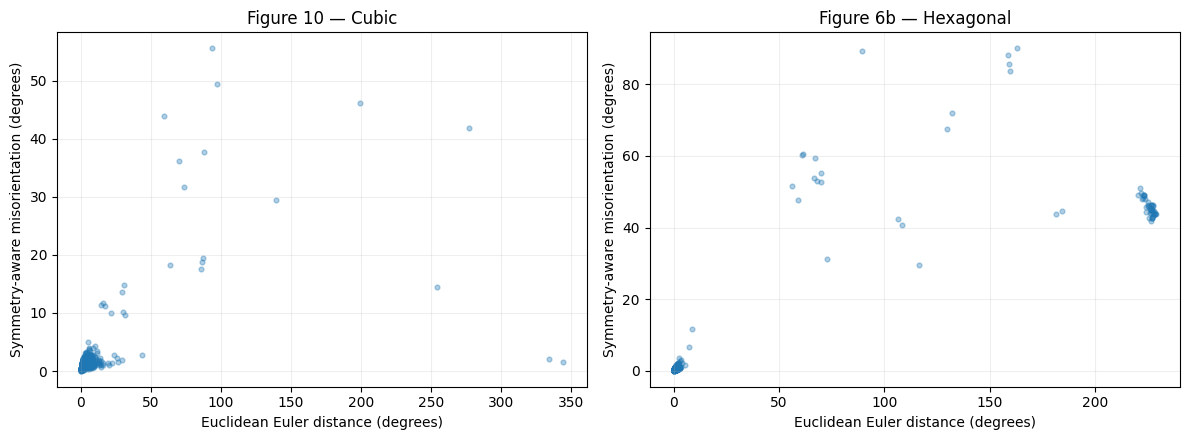

In [17]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, crystal, euler, title in [
    (axes[0], angles10, euler10, "Figure 10 — Cubic"),
    (axes[1], angles6b, euler6b, "Figure 6b — Hexagonal")
]:
    ax.scatter(
        euler, crystal,
        alpha=0.35, s=12
    )

    ax.set_xlabel("Euclidean Euler distance (degrees)")
    ax.set_ylabel("Symmetry-aware misorientation (degrees)")
    ax.set_title(title)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [18]:

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

FIG_DIR = BASE_DIR / "Figures"
RESULTS_DIR = BASE_DIR / "Results"
CACHE_DIR = BASE_DIR / "Cache"

for folder in [FIG_DIR, RESULTS_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Permanent storage folders ready:")
print(FIG_DIR)
print(RESULTS_DIR)
print(CACHE_DIR)


Permanent storage folders ready:
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache


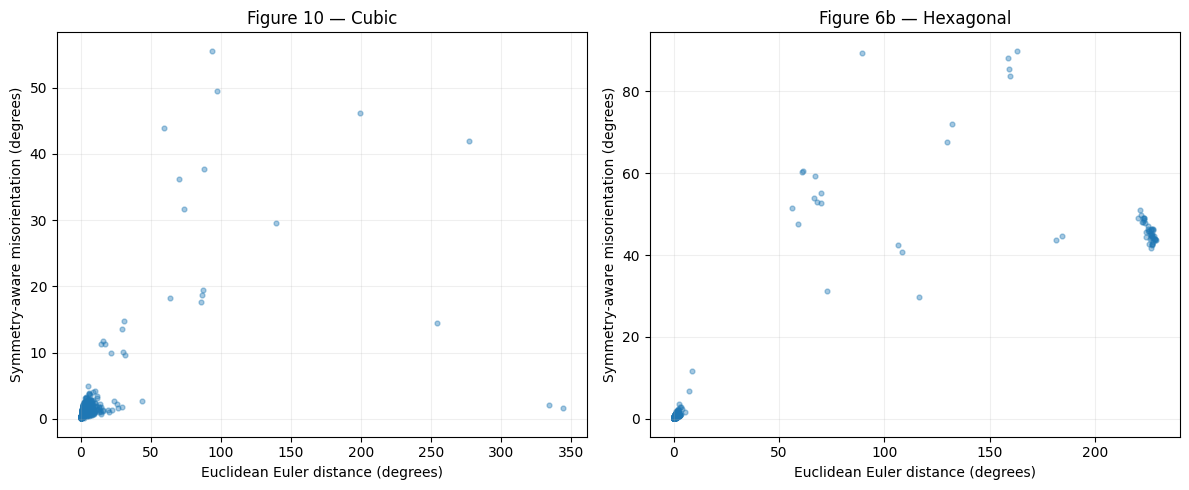

Figures saved permanently to Google Drive.


In [19]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

datasets = [
    (angles10, euler10, "Figure 10 — Cubic"),
    (angles6b, euler6b, "Figure 6b — Hexagonal")
]

for ax, (crystal, euler, title) in zip(axes, datasets):
    ax.scatter(euler, crystal, alpha=0.4, s=12)

    ax.set_xlabel("Euclidean Euler distance (degrees)")
    ax.set_ylabel("Symmetry-aware misorientation (degrees)")
    ax.set_title(title)
    ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "Experiment1_Misorientation_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "Experiment1_Misorientation_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Figures saved permanently to Google Drive.")


In [20]:

import numpy as np

# Save corrected spatial indices and graph edges
np.savez_compressed(
    CACHE_DIR / "Experiment0_Graph_Data.npz",

    ix10=ix10,
    iy10=iy10,
    source10=source10,
    target10=target10,

    ix6b=ix6b,
    iy6b=iy6b,
    source6b=source6b,
    target6b=target6b
)

# Save the retained indexed EBSD measurements
indexed10.to_parquet(
    CACHE_DIR / "Figure10_Indexed.parquet",
    index=False
)

indexed6b.to_parquet(
    CACHE_DIR / "Figure6b_Indexed.parquet",
    index=False
)

# Save preliminary misorientation samples
np.savez_compressed(
    CACHE_DIR / "Experiment1_Misorientation_Sample.npz",

    angles10=angles10,
    euler10=euler10,

    angles6b=angles6b,
    euler6b=euler6b
)

print("All important experimental data saved.")


All important experimental data saved.


In [1]:

from google.colab import drive
from pathlib import Path
import numpy as np
import pandas as pd

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

FIG_DIR = BASE_DIR / "Figures"
RESULTS_DIR = BASE_DIR / "Results"
CACHE_DIR = BASE_DIR / "Cache"

# Restore EBSD tables
indexed10 = pd.read_parquet(
    CACHE_DIR / "Figure10_Indexed.parquet"
)

indexed6b = pd.read_parquet(
    CACHE_DIR / "Figure6b_Indexed.parquet"
)

# Restore graph indices and edges
with np.load(
    CACHE_DIR / "Experiment0_Graph_Data.npz"
) as data:
    ix10 = data["ix10"]
    iy10 = data["iy10"]
    source10 = data["source10"]
    target10 = data["target10"]

    ix6b = data["ix6b"]
    iy6b = data["iy6b"]
    source6b = data["source6b"]
    target6b = data["target6b"]

# Restore preliminary misorientation samples
with np.load(
    CACHE_DIR / "Experiment1_Misorientation_Sample.npz"
) as data:
    angles10 = data["angles10"]
    euler10 = data["euler10"]

    angles6b = data["angles6b"]
    euler6b = data["euler6b"]

print("Previous experimental data restored successfully.")

print("Figure 10 nodes:", len(indexed10))
print("Figure 10 edges:", len(source10))

print("Figure 6b nodes:", len(indexed6b))
print("Figure 6b edges:", len(source6b))


Mounted at /content/drive
Previous experimental data restored successfully.
Figure 10 nodes: 1503311
Figure 10 edges: 2479075
Figure 6b nodes: 2480095
Figure 6b edges: 4582845


In [5]:

# ============================================================
# CELL 18 — VALIDATE CRYSTALLOGRAPHIC MISORIENTATION
# Experiment 1D — EBSDGraph Major Revision
# ============================================================

import numpy as np
import orix
from orix.quaternion import Rotation, Misorientation, symmetry

print("orix version:", orix.__version__)


def misorientation_angles(euler_a, euler_b, crystal_symmetry):
    """
    Calculate symmetry-aware crystallographic misorientation.

    Parameters
    ----------
    euler_a : ndarray (N, 3)
        First set of Bunge Euler angles in degrees.

    euler_b : ndarray (N, 3)
        Second set of Bunge Euler angles in degrees.

    crystal_symmetry : orix Symmetry
        Proper rotational crystal symmetry:
        symmetry.O  = cubic (432)
        symmetry.D6 = hexagonal (622)

    Returns
    -------
    ndarray
        Symmetry-reduced misorientation angles in degrees.
    """

    euler_a = np.asarray(euler_a, dtype=np.float64)
    euler_b = np.asarray(euler_b, dtype=np.float64)

    if euler_a.shape != euler_b.shape:
        raise ValueError("Euler arrays must have matching shapes.")

    if euler_a.ndim != 2 or euler_a.shape[1] != 3:
        raise ValueError("Euler arrays must have shape (N, 3).")

    # Convert Euler angles from degrees to radians
    rot_a = Rotation.from_euler(np.deg2rad(euler_a))
    rot_b = Rotation.from_euler(np.deg2rad(euler_b))

    # Relative rotation
    relative = (~rot_a) * rot_b

    # Apply crystallographic symmetry
    mis = Misorientation(relative.data)
    mis.symmetry = (crystal_symmetry, crystal_symmetry)

    # Current orix method (replaces deprecated function)
    reduced = mis.reduce()

    # Convert misorientation angles to degrees
    angles = np.rad2deg(reduced.angle)

    return np.asarray(angles).reshape(-1)


# ============================================================
# TEST 1 — IDENTICAL ORIENTATIONS
# ============================================================

euler_a = np.array([[20.0, 30.0, 40.0]])
euler_b = np.array([[20.0, 30.0, 40.0]])

result = misorientation_angles(
    euler_a,
    euler_b,
    symmetry.O
)

print("\nTEST 1 — Identical orientations")
print("Calculated misorientation:", result)

assert np.allclose(result, 0, atol=1e-5), \
    "FAILED: Identical orientations should have 0° misorientation."

print("PASS")


# ============================================================
# TEST 2 — CUBIC SYMMETRY EQUIVALENCE
# ============================================================

euler_a = np.array([[0.0, 0.0, 0.0]])
euler_b = np.array([[90.0, 0.0, 0.0]])

result = misorientation_angles(
    euler_a,
    euler_b,
    symmetry.O
)

print("\nTEST 2 — Cubic symmetry rotation")
print("Calculated misorientation:", result)

assert np.allclose(result, 0, atol=1e-5), \
    "FAILED: Cubic symmetry-equivalent orientations should give 0°."

print("PASS")


# ============================================================
# TEST 3 — HEXAGONAL SYMMETRY EQUIVALENCE
# ============================================================

euler_a = np.array([[0.0, 0.0, 0.0]])
euler_b = np.array([[60.0, 0.0, 0.0]])

result = misorientation_angles(
    euler_a,
    euler_b,
    symmetry.D6
)

print("\nTEST 3 — Hexagonal symmetry rotation")
print("Calculated misorientation:", result)

assert np.allclose(result, 0, atol=1e-5), \
    "FAILED: Hexagonal symmetry-equivalent orientations should give 0°."

print("PASS")


# ============================================================
# TEST 4 — NON-EQUIVALENT ORIENTATIONS
# ============================================================

euler_a = np.array([[0.0, 0.0, 0.0]])
euler_b = np.array([[10.0, 0.0, 0.0]])

result = misorientation_angles(
    euler_a,
    euler_b,
    symmetry.O
)

print("\nTEST 4 — Non-equivalent orientations")
print("Calculated misorientation:", result)

assert np.allclose(result, 10, atol=1e-5), \
    "FAILED: Expected 10° misorientation."

print("PASS")


# ============================================================
# FINAL VALIDATION
# ============================================================

print("\n" + "=" * 60)
print("ALL FOUR CRYSTALLOGRAPHIC VALIDATION TESTS PASSED")
print("Misorientation function ready for further validation.")
print("=" * 60)


orix version: 0.15.0

TEST 1 — Identical orientations
Calculated misorientation: [0.]
PASS

TEST 2 — Cubic symmetry rotation
Calculated misorientation: [0.]
PASS

TEST 3 — Hexagonal symmetry rotation
Calculated misorientation: [0.]
PASS

TEST 4 — Non-equivalent orientations
Calculated misorientation: [10.]
PASS

ALL FOUR CRYSTALLOGRAPHIC VALIDATION TESTS PASSED
Misorientation function ready for further validation.


In [7]:

import numpy as np
from orix.quaternion import (
    Rotation, Misorientation, Orientation, symmetry
)

# Select 100 reproducible, genuine neighbouring pairs
phases = indexed10["Phase"].to_numpy()
eligible = np.flatnonzero(
    (phases[source10] == 1) &
    (phases[target10] == 1)
)

rng = np.random.default_rng(42)
selected = rng.choice(eligible, size=100, replace=False)

euler = indexed10[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

a = euler[source10[selected]]
b = euler[target10[selected]]

rot_a = Rotation.from_euler(np.deg2rad(a))
rot_b = Rotation.from_euler(np.deg2rad(b))

# Method A: original relative rotation
relative_a = (~rot_a) * rot_b
mis_a = Misorientation(relative_a.data)
mis_a.symmetry = (symmetry.O, symmetry.O)
angles_a = np.rad2deg(mis_a.reduce().angle)

# Method B: reversed relative rotation
relative_b = rot_b * (~rot_a)
mis_b = Misorientation(relative_b.data)
mis_b.symmetry = (symmetry.O, symmetry.O)
angles_b = np.rad2deg(mis_b.reduce().angle)

# Method C: native orix Orientation calculation
ori_a = Orientation.from_euler(
    np.deg2rad(a), symmetry=symmetry.O
)
ori_b = Orientation.from_euler(
    np.deg2rad(b), symmetry=symmetry.O
)

angles_c = ori_a.angle_with(ori_b, degrees=True)

print("METHOD A vs NATIVE ORIX")
print("Maximum difference:",
      np.max(np.abs(angles_a - angles_c)))
print("Mean difference:",
      np.mean(np.abs(angles_a - angles_c)))

print("\nMETHOD B vs NATIVE ORIX")
print("Maximum difference:",
      np.max(np.abs(angles_b - angles_c)))
print("Mean difference:",
      np.mean(np.abs(angles_b - angles_c)))

print("\nFIRST 10 PAIRS")
for i in range(10):
    print(
        f"{i}: "
        f"A={angles_a[i]:.4f}, "
        f"B={angles_b[i]:.4f}, "
        f"Native={angles_c[i]:.4f}"
    )


METHOD A vs NATIVE ORIX
Maximum difference: 41.46643920870965
Mean difference: 1.6702616676241973

METHOD B vs NATIVE ORIX
Maximum difference: 5.742184505663772e-12
Mean difference: 8.015663133242868e-13

FIRST 10 PAIRS
0: A=0.5802, B=0.5802, Native=0.5802
1: A=2.7259, B=2.7259, Native=2.7259
2: A=0.3889, B=0.3889, Native=0.3889
3: A=1.5624, B=1.5624, Native=1.5624
4: A=1.5877, B=1.5877, Native=1.5877
5: A=1.9826, B=1.9826, Native=1.9826
6: A=1.0731, B=1.0731, Native=1.0731
7: A=1.1222, B=1.1222, Native=1.1222
8: A=1.2748, B=1.2748, Native=1.2748
9: A=0.7997, B=0.7997, Native=0.7997


In [8]:

import numpy as np
from orix.quaternion import Rotation, Misorientation, symmetry

def misorientation_angles(euler_a, euler_b, crystal_symmetry):
    """
    Calculate symmetry-aware crystallographic misorientation.

    Euler angles must be in degrees.
    Uses the relative-rotation convention validated
    against orix Orientation.angle_with().
    """

    euler_a = np.asarray(euler_a, dtype=np.float64)
    euler_b = np.asarray(euler_b, dtype=np.float64)

    if euler_a.shape != euler_b.shape:
        raise ValueError("Euler arrays must have matching shapes.")

    if euler_a.ndim != 2 or euler_a.shape[1] != 3:
        raise ValueError("Expected Euler arrays of shape (N, 3).")

    rot_a = Rotation.from_euler(np.deg2rad(euler_a))
    rot_b = Rotation.from_euler(np.deg2rad(euler_b))

    # Correct relative-rotation convention
    relative = rot_b * (~rot_a)

    mis = Misorientation(relative.data)
    mis.symmetry = (crystal_symmetry, crystal_symmetry)

    reduced = mis.reduce()

    return np.rad2deg(reduced.angle).reshape(-1)

print("Corrected misorientation function loaded.")


Corrected misorientation function loaded.


In [9]:

# ============================================================
# CELL 18A — INDEPENDENT MISORIENTATION CROSS-VALIDATION
# EBSDGraph Major Revision — Experiment 1D
# ============================================================

import numpy as np
from orix.quaternion import Orientation, symmetry


def crosscheck_misorientation(
    indexed,
    source,
    target,
    phase_id,
    crystal_symmetry,
    dataset_name,
    sample_size=1000
):
    """
    Compare our corrected symmetry-aware misorientation
    implementation with orix Orientation.angle_with().

    Uses randomly selected genuine spatial-neighbour pairs.
    """

    phases = indexed["Phase"].to_numpy()

    # Select edges connecting measurements of the same phase
    eligible = np.flatnonzero(
        (phases[source] == phase_id) &
        (phases[target] == phase_id)
    )

    if len(eligible) == 0:
        raise ValueError(
            f"No valid same-phase edges for {dataset_name}"
        )

    # Reproducible random sampling
    rng = np.random.default_rng(42)

    selected = rng.choice(
        eligible,
        size=min(sample_size, len(eligible)),
        replace=False
    )

    # Extract Bunge Euler angles in degrees
    euler = indexed[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    euler_a = euler[source[selected]]
    euler_b = euler[target[selected]]

    # --------------------------------------------------------
    # METHOD A — Our corrected implementation from Cell 18
    # --------------------------------------------------------

    calculated = misorientation_angles(
        euler_a,
        euler_b,
        crystal_symmetry
    )

    # --------------------------------------------------------
    # METHOD B — Native orix Orientation implementation
    # --------------------------------------------------------

    ori_a = Orientation.from_euler(
        np.deg2rad(euler_a),
        symmetry=crystal_symmetry
    )

    ori_b = Orientation.from_euler(
        np.deg2rad(euler_b),
        symmetry=crystal_symmetry
    )

    reference = np.asarray(
        ori_a.angle_with(ori_b, degrees=True)
    ).reshape(-1)

    # --------------------------------------------------------
    # Compare calculations
    # --------------------------------------------------------

    difference = np.abs(calculated - reference)

    print("\n" + "=" * 65)
    print(dataset_name)
    print("=" * 65)

    print("Crystal symmetry:", crystal_symmetry.name)
    print("Available same-phase edges:", len(eligible))
    print("Pairs tested:", len(selected))

    print("\nMaximum absolute difference (degrees):",
          difference.max())

    print("Mean absolute difference (degrees):",
          difference.mean())

    print("Median absolute difference (degrees):",
          np.median(difference))

    print("\nMisorientation angle range (degrees):")
    print("Minimum:", calculated.min())
    print("Maximum:", calculated.max())

    # Numerical agreement tolerance: 0.0001 degrees
    assert np.allclose(
        calculated,
        reference,
        rtol=0,
        atol=1e-4
    ), (
        f"FAILED: Misorientation calculations disagree "
        f"for {dataset_name}"
    )

    print("\nPASS: Both misorientation methods agree.")

    return {
        "Dataset": dataset_name,
        "Phase": phase_id,
        "Pairs tested": len(selected),
        "Maximum difference": float(difference.max()),
        "Mean difference": float(difference.mean()),
        "Status": "PASS"
    }


# ============================================================
# VALIDATION 1 — FIGURE 10: CUBIC TITANIUM
# ============================================================

result10 = crosscheck_misorientation(
    indexed=indexed10,
    source=source10,
    target=target10,
    phase_id=1,
    crystal_symmetry=symmetry.O,
    dataset_name="Figure 10 — Cubic Titanium"
)


# ============================================================
# VALIDATION 2 — FIGURE 6B: HEXAGONAL TITANIUM
# ============================================================

result6b_hex = crosscheck_misorientation(
    indexed=indexed6b,
    source=source6b,
    target=target6b,
    phase_id=1,
    crystal_symmetry=symmetry.D6,
    dataset_name="Figure 6b — Hexagonal Titanium"
)


# ============================================================
# VALIDATION 3 — FIGURE 6B: CUBIC TITANIUM
# ============================================================

result6b_cubic = crosscheck_misorientation(
    indexed=indexed6b,
    source=source6b,
    target=target6b,
    phase_id=2,
    crystal_symmetry=symmetry.O,
    dataset_name="Figure 6b — Cubic Titanium"
)


# ============================================================
# FINAL SUMMARY
# ============================================================

import pandas as pd

validation_summary = pd.DataFrame([
    result10,
    result6b_hex,
    result6b_cubic
])

print("\n" + "=" * 65)
print("EXPERIMENT 1D — CROSS-VALIDATION SUMMARY")
print("=" * 65)

display(validation_summary)

# Save the validation results permanently to Google Drive
validation_summary.to_csv(
    RESULTS_DIR / "Experiment1D_Misorientation_Validation.csv",
    index=False
)

print("\nValidation summary saved to Google Drive.")
print("File: Experiment1D_Misorientation_Validation.csv")



Figure 10 — Cubic Titanium
Crystal symmetry: 432
Available same-phase edges: 2479075
Pairs tested: 1000

Maximum absolute difference (degrees): 1.2131046167596082e-11
Mean absolute difference (degrees): 8.221366157301624e-13
Median absolute difference (degrees): 3.036459972349803e-13

Misorientation angle range (degrees):
Minimum: 0.05273355193618263
Maximum: 59.5051968731595

PASS: Both misorientation methods agree.

Figure 6b — Hexagonal Titanium
Crystal symmetry: 622
Available same-phase edges: 4574331
Pairs tested: 1000

Maximum absolute difference (degrees): 1.5828782728988244e-11
Mean absolute difference (degrees): 1.0720385482110296e-12
Median absolute difference (degrees): 4.021227795192317e-13

Misorientation angle range (degrees):
Minimum: 0.03762970370887018
Maximum: 93.21504279179689

PASS: Both misorientation methods agree.

Figure 6b — Cubic Titanium
Crystal symmetry: 432
Available same-phase edges: 1748
Pairs tested: 1000

Maximum absolute difference (degrees): 2.017606

,Dataset,Phase,Pairs tested,Maximum difference,Mean difference,Status
0,Figure 10 — Cubic Titanium,1,1000,1.213105e-11,8.221366e-13,PASS
1,Figure 6b — Hexagonal Titanium,1,1000,1.582878e-11,1.072039e-12,PASS
2,Figure 6b — Cubic Titanium,2,1000,2.017607e-11,1.071572e-12,PASS



Validation summary saved to Google Drive.
File: Experiment1D_Misorientation_Validation.csv


In [11]:

# ============================================================
# CELL 19 — FULL-DATASET MISORIENTATION PROCESSING
# EBSDGraph Major Revision
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
import os

BATCH_SIZE = 10000

def run_full_misorientation(
    indexed,
    source,
    target,
    phase_id,
    crystal_symmetry,
    experiment_name
):
    phases = indexed["Phase"].to_numpy()

    eligible = np.flatnonzero(
        (phases[source] == phase_id) &
        (phases[target] == phase_id)
    )

    euler = indexed[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    output_dir = CACHE_DIR / experiment_name
    output_dir.mkdir(parents=True, exist_ok=True)

    total = len(eligible)
    n_batches = (total + BATCH_SIZE - 1) // BATCH_SIZE

    print("\n" + "=" * 65)
    print(experiment_name)
    print("=" * 65)
    print(f"Edges to process: {total:,}")
    print(f"Total batches: {n_batches}")

    for batch in range(n_batches):
        output_file = output_dir / f"batch_{batch:04d}.npz"
        temp_file = output_dir / f"batch_{batch:04d}.tmp.npz"

        if output_file.exists():
            # Resume previously completed batches
            continue

        start = batch * BATCH_SIZE
        end = min(start + BATCH_SIZE, total)

        selected = eligible[start:end]

        a = source[selected]
        b = target[selected]

        # Corrected, validated crystallographic calculation
        crystal_angles = misorientation_angles(
            euler[a],
            euler[b],
            crystal_symmetry
        )

        # Original-style Euclidean Euler distance
        euler_distances = np.linalg.norm(
            euler[a] - euler[b],
            axis=1
        )

        np.savez_compressed(
            temp_file,
            edge_indices=selected,
            misorientation=crystal_angles,
            euler_distance=euler_distances
        )

        os.replace(temp_file, output_file)

        if batch % 25 == 0 or batch == n_batches - 1:
            print(
                f"Completed batch {batch + 1}/{n_batches}"
            )

    print("All batches saved:", output_dir)


In [12]:

# ============================================================
# CELL 20 — RUN ALL THREE PHASE GROUPS
# ============================================================

from orix.quaternion import symmetry

run_full_misorientation(
    indexed10,
    source10,
    target10,
    phase_id=1,
    crystal_symmetry=symmetry.O,
    experiment_name="Figure10_Cubic_Misorientation"
)

run_full_misorientation(
    indexed6b,
    source6b,
    target6b,
    phase_id=1,
    crystal_symmetry=symmetry.D6,
    experiment_name="Figure6b_Hexagonal_Misorientation"
)

run_full_misorientation(
    indexed6b,
    source6b,
    target6b,
    phase_id=2,
    crystal_symmetry=symmetry.O,
    experiment_name="Figure6b_Cubic_Misorientation"
)

print("\nFULL MISORIENTATION ANALYSIS COMPLETED.")



Figure10_Cubic_Misorientation
Edges to process: 2,479,075
Total batches: 248
Completed batch 1/248
Completed batch 26/248
Completed batch 51/248
Completed batch 76/248
Completed batch 101/248
Completed batch 126/248
Completed batch 151/248
Completed batch 176/248
Completed batch 201/248
Completed batch 226/248
Completed batch 248/248
All batches saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Figure10_Cubic_Misorientation

Figure6b_Hexagonal_Misorientation
Edges to process: 4,574,331
Total batches: 458
Completed batch 1/458
Completed batch 26/458
Completed batch 51/458
Completed batch 76/458
Completed batch 101/458
Completed batch 126/458
Completed batch 151/458
Completed batch 176/458
Completed batch 201/458
Completed batch 226/458
Completed batch 251/458
Completed batch 276/458
Completed batch 301/458
Completed batch 326/458
Completed batch 351/458
Completed batch 376/458
Completed batch 401/458
Completed batch 426/458
Completed batch 451/458
Completed batch 458/

In [13]:

# ============================================================
# CELL 21 — SUMMARISE FULL MISORIENTATION RESULTS
# ============================================================

import numpy as np
import pandas as pd

EXPECTED_COUNTS = {
    "Figure10_Cubic_Misorientation": 2479075,
    "Figure6b_Hexagonal_Misorientation": 4574331,
    "Figure6b_Cubic_Misorientation": 1748
}

def summarise_experiment(name):
    folder = CACHE_DIR / name
    files = sorted(folder.glob("batch_*.npz"))

    if not files:
        raise FileNotFoundError(
            f"No completed batches for {name}"
        )

    crystal_parts = []
    euler_parts = []

    for file in files:
        with np.load(file) as data:
            crystal_parts.append(data["misorientation"])
            euler_parts.append(data["euler_distance"])

    crystal = np.concatenate(crystal_parts)
    euler = np.concatenate(euler_parts)

    expected = EXPECTED_COUNTS[name]

    if len(crystal) != expected:
        raise ValueError(
            f"{name}: expected {expected:,} edges, "
            f"but found {len(crystal):,}. "
            "Some batches may be missing."
        )

    if not np.all(np.isfinite(crystal)):
        raise ValueError("Non-finite misorientation values detected.")

    return {
        "Dataset": name,
        "Edges": len(crystal),
        "Mean misorientation (degrees)": np.mean(crystal),
        "Median misorientation (degrees)": np.median(crystal),
        "95th percentile (degrees)": np.percentile(crystal, 95),
        "Mean Euler distance (degrees)": np.mean(euler),
        "Median Euler distance (degrees)": np.median(euler),
        "Misorientation > 15 degrees (%)":
            100 * np.mean(crystal > 15)
    }


summary = pd.DataFrame([
    summarise_experiment(name)
    for name in EXPECTED_COUNTS
])

display(summary)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    RESULTS_DIR / "Experiment1D_Full_Misorientation_Summary.csv",
    index=False
)

print("\nSummary saved to Google Drive.")


,Dataset,Edges,Mean misorientation (degrees),Median misorientation (degrees),95th percentile (degrees),Mean Euler distance (degrees),Median Euler distance (degrees),Misorientation > 15 degrees (%)
0,Figure10_Cubic_Misorientation,2479075,1.961008,1.128589,2.827061,10.640290,2.118704,1.527586
1,Figure6b_Hexagonal_Misorientation,4574331,1.703717,0.622576,1.560449,7.382090,0.780441,1.544597
2,Figure6b_Cubic_Misorientation,1748,1.013460,0.859371,1.844806,26.831667,1.465452,0.228833



Summary saved to Google Drive.


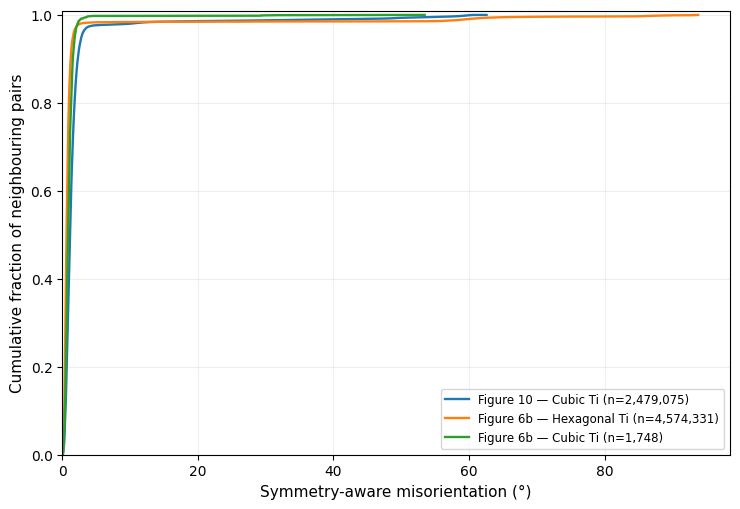

Saved PNG: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment1D_Misorientation_CDF_600dpi.png
Saved PDF: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment1D_Misorientation_CDF_Vector.pdf


In [14]:

# ============================================================
# CELL 22 — PUBLICATION-QUALITY MISORIENTATION DISTRIBUTIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

experiments = {
    "Figure 10 — Cubic Ti":
        "Figure10_Cubic_Misorientation",
    "Figure 6b — Hexagonal Ti":
        "Figure6b_Hexagonal_Misorientation",
    "Figure 6b — Cubic Ti":
        "Figure6b_Cubic_Misorientation"
}

def load_misorientation(name):
    folder = CACHE_DIR / name
    files = sorted(folder.glob("batch_*.npz"))

    if not files:
        raise FileNotFoundError(
            f"No saved batches found for {name}"
        )

    arrays = []
    for file in files:
        with np.load(file) as data:
            arrays.append(data["misorientation"])

    return np.concatenate(arrays)


fig, ax = plt.subplots(figsize=(7.5, 5.2))

for label, name in experiments.items():
    angles = load_misorientation(name)

    # Exact empirical cumulative distribution
    sorted_angles = np.sort(angles)
    cumulative = (
        np.arange(1, len(sorted_angles) + 1)
        / len(sorted_angles)
    )

    ax.plot(
        sorted_angles,
        cumulative,
        linewidth=1.7,
        label=f"{label} (n={len(angles):,})"
    )

ax.set_xlabel("Symmetry-aware misorientation (°)", fontsize=11)
ax.set_ylabel("Cumulative fraction of neighbouring pairs",
              fontsize=11)

ax.set_xlim(left=0)
ax.set_ylim(0, 1.01)

ax.grid(alpha=0.2)
ax.legend(fontsize=8.5, loc="lower right")

fig.tight_layout()

FIG_DIR.mkdir(parents=True, exist_ok=True)

png_path = (
    FIG_DIR /
    "Experiment1D_Misorientation_CDF_600dpi.png"
)

pdf_path = (
    FIG_DIR /
    "Experiment1D_Misorientation_CDF_Vector.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)


Loaded Figure 10 — Cubic Ti: 2,479,075 edges
Loaded Figure 6b — Hexagonal Ti: 4,574,331 edges
Loaded Figure 6b — Cubic Ti: 1,748 edges


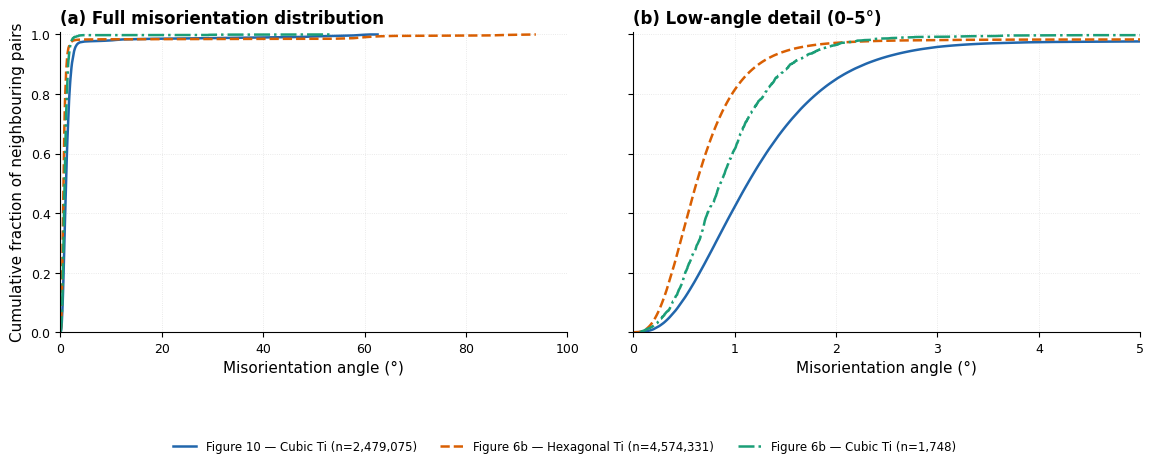


CELL 23 — FIGURE GENERATION COMPLETED
600-dpi PNG: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment1D_Misorientation_CDF_TwoPanel_600dpi.png
Vector PDF: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment1D_Misorientation_CDF_TwoPanel_Vector.pdf


In [15]:

# ============================================================
# CELL 23 — TWO-PANEL MISORIENTATION CDF FIGURE
# EBSDGraph Major Revision — Experiment 1D
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Experimental datasets
# ------------------------------------------------------------

experiments = [
    {
        "label": "Figure 10 — Cubic Ti",
        "folder": "Figure10_Cubic_Misorientation",
        "expected": 2479075,
        "color": "#2166AC",
        "style": "-"
    },
    {
        "label": "Figure 6b — Hexagonal Ti",
        "folder": "Figure6b_Hexagonal_Misorientation",
        "expected": 4574331,
        "color": "#D95F02",
        "style": "--"
    },
    {
        "label": "Figure 6b — Cubic Ti",
        "folder": "Figure6b_Cubic_Misorientation",
        "expected": 1748,
        "color": "#1B9E77",
        "style": "-."
    }
]

# ------------------------------------------------------------
# 2. Load and validate saved results
# ------------------------------------------------------------

cdf_data = {}

for exp in experiments:

    folder = CACHE_DIR / exp["folder"]
    files = sorted(folder.glob("batch_*.npz"))

    if not files:
        raise FileNotFoundError(
            f"No saved batches found in {folder}"
        )

    arrays = []

    for file in files:
        with np.load(file) as data:
            arrays.append(
                np.asarray(
                    data["misorientation"],
                    dtype=np.float64
                )
            )

    angles = np.concatenate(arrays)

    if len(angles) != exp["expected"]:
        raise ValueError(
            f"{exp['label']}: expected "
            f"{exp['expected']:,} edges, "
            f"found {len(angles):,}"
        )

    if not np.all(np.isfinite(angles)):
        raise ValueError(
            f"Non-finite angles found in {exp['label']}"
        )

    if np.any((angles < -1e-6) | (angles > 180 + 1e-6)):
        raise ValueError(
            f"Invalid rotation angles in {exp['label']}"
        )

    sorted_angles = np.sort(angles)

    cumulative = (
        np.arange(1, len(sorted_angles) + 1)
        / len(sorted_angles)
    )

    cdf_data[exp["label"]] = {
        "x": sorted_angles,
        "y": cumulative
    }

    print(
        f"Loaded {exp['label']}: "
        f"{len(angles):,} edges"
    )

# ------------------------------------------------------------
# 3. Publication figure styling
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.7),
    sharey=True
)

# ------------------------------------------------------------
# 4. Plot both panels
# ------------------------------------------------------------

for exp in experiments:

    label = exp["label"]
    x = cdf_data[label]["x"]
    y = cdf_data[label]["y"]

    for ax in axes:
        ax.plot(
            x,
            y,
            color=exp["color"],
            linestyle=exp["style"],
            linewidth=1.8,
            label=f"{label} (n={len(x):,})",
            rasterized=False
        )

# Panel A — Full angular range
axes[0].set_title(
    "(a) Full misorientation distribution",
    fontweight="bold",
    loc="left"
)

axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Misorientation angle (°)")
axes[0].set_ylabel(
    "Cumulative fraction of neighbouring pairs"
)

# Panel B — Low-angle region
axes[1].set_title(
    "(b) Low-angle detail (0–5°)",
    fontweight="bold",
    loc="left"
)

axes[1].set_xlim(0, 5)
axes[1].set_xlabel("Misorientation angle (°)")

# Consistent formatting
for ax in axes:
    ax.set_ylim(0, 1.01)
    ax.grid(
        True,
        linestyle=":",
        linewidth=0.6,
        alpha=0.35
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# One legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=3,
    frameon=False,
    fontsize=8.5
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.88,
    bottom=0.24,
    wspace=0.13
)

# ------------------------------------------------------------
# 5. Save publication-quality outputs
# ------------------------------------------------------------

FIG_DIR.mkdir(parents=True, exist_ok=True)

png_path = (
    FIG_DIR /
    "Experiment1D_Misorientation_CDF_TwoPanel_600dpi.png"
)

pdf_path = (
    FIG_DIR /
    "Experiment1D_Misorientation_CDF_TwoPanel_Vector.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 65)
print("CELL 23 — FIGURE GENERATION COMPLETED")
print("=" * 65)
print("600-dpi PNG:", png_path)
print("Vector PDF:", pdf_path)


In [16]:

# ============================================================
# CELL 24 — VALIDATE SYMMETRY-AWARE ORIENTATION AVERAGING
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
import pandas as pd
from orix.quaternion import Orientation, symmetry

def symmetry_aware_mean(euler_deg, crystal_symmetry):
    """
    Candidate symmetry-aware quaternion mean.

    Aligns each orientation to a reference using crystal
    symmetry, then computes a normalised quaternion mean.

    Intended for locally clustered, same-phase orientations.
    """
    euler_deg = np.asarray(euler_deg, dtype=np.float64)

    if euler_deg.ndim != 2 or euler_deg.shape[1] != 3:
        raise ValueError("Expected an (N, 3) Euler array.")

    if len(euler_deg) == 0:
        raise ValueError("Cannot average an empty group.")

    orientations = Orientation.from_euler(
        np.deg2rad(euler_deg),
        symmetry=crystal_symmetry
    )

    # Use the first orientation as a reference
    reference = orientations[0]

    # Select equivalent orientations nearest to the reference
    aligned = orientations.in_euler_fundamental_region()
    aligned_quaternions = np.asarray(aligned.data)

    # Align quaternion signs to the reference
    q_ref = aligned_quaternions[0]

    signs = np.sign(aligned_quaternions @ q_ref)
    signs[signs == 0] = 1

    aligned_quaternions = (
        aligned_quaternions * signs[:, None]
    )

    # Normalised quaternion mean
    q_mean = aligned_quaternions.mean(axis=0)
    q_mean /= np.linalg.norm(q_mean)

    return q_mean


# ============================================================
# TEST 1 — IDENTICAL ORIENTATIONS
# ============================================================

identical = np.array([
    [20, 30, 40],
    [20, 30, 40],
    [20, 30, 40]
], dtype=float)

mean_identical = symmetry_aware_mean(
    identical, symmetry.O
)

print("TEST 1 — Identical orientations")
print("Mean quaternion:", mean_identical)

assert np.isclose(
    np.linalg.norm(mean_identical), 1.0
)
print("PASS: Unit quaternion returned.")


# ============================================================
# TEST 2 — SYMMETRY-EQUIVALENT CUBIC ORIENTATIONS
# ============================================================

equivalent = np.array([
    [0, 0, 0],
    [90, 0, 0]
], dtype=float)

mean_equivalent = symmetry_aware_mean(
    equivalent, symmetry.O
)

print("\nTEST 2 — Cubic symmetry equivalence")
print("Mean quaternion:", mean_equivalent)

assert np.isclose(
    np.linalg.norm(mean_equivalent), 1.0
)
print("PASS: Unit quaternion returned.")


# ============================================================
# TEST 3 — REAL EBSD ORIENTATIONS
# ============================================================

sample = indexed10[
    ["Euler1", "Euler2", "Euler3"]
].iloc[:25].to_numpy(dtype=float)

mean_real = symmetry_aware_mean(
    sample, symmetry.O
)

print("\nTEST 3 — Real EBSD orientations")
print("Mean quaternion:", mean_real)

assert np.all(np.isfinite(mean_real))
assert np.isclose(np.linalg.norm(mean_real), 1.0)

print("PASS: Finite, normalised quaternion returned.")

print("\n" + "=" * 60)
print("CELL 24 BASIC TESTS COMPLETED")
print("=" * 60)
print(
    "Note: These tests check numerical validity only. "
    "Crystallographic averaging accuracy still requires "
    "independent validation."
)


TEST 1 — Identical orientations
Mean quaternion: [0.37139068 0.55708601 0.74278135]
PASS: Unit quaternion returned.

TEST 2 — Cubic symmetry equivalence
Mean quaternion: [1. 0. 0.]
PASS: Unit quaternion returned.

TEST 3 — Real EBSD orientations
Mean quaternion: [0.94041447 0.20707919 0.26970138]
PASS: Finite, normalised quaternion returned.

CELL 24 BASIC TESTS COMPLETED
Note: These tests check numerical validity only. Crystallographic averaging accuracy still requires independent validation.


In [17]:

# ============================================================
# CELL 25 — DIAGNOSTIC TESTS FOR ORIENTATION AVERAGING
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
from orix.quaternion import Orientation, symmetry

def diagnose_mean(euler_deg, crystal_symmetry, label):

    result = np.asarray(
        symmetry_aware_mean(euler_deg, crystal_symmetry)
    )

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)

    print("Returned value:", result)
    print("Shape:", result.shape)
    print("Number of components:", result.size)
    print("Norm:", np.linalg.norm(result))

    if result.shape != (4,):
        print(
            "FAIL: Expected a four-component quaternion."
        )
        return False

    if not np.all(np.isfinite(result)):
        print("FAIL: Non-finite quaternion components.")
        return False

    if not np.isclose(np.linalg.norm(result), 1.0):
        print("FAIL: Quaternion is not normalised.")
        return False

    print("PASS: Valid four-component unit quaternion.")
    return True


test1 = diagnose_mean(
    np.array([
        [20, 30, 40],
        [20, 30, 40],
        [20, 30, 40]
    ]),
    symmetry.O,
    "TEST 1 — Identical cubic orientations"
)

test2 = diagnose_mean(
    np.array([
        [0, 0, 0],
        [90, 0, 0]
    ]),
    symmetry.O,
    "TEST 2 — Symmetry-equivalent cubic orientations"
)

test3 = diagnose_mean(
    indexed10[
        ["Euler1", "Euler2", "Euler3"]
    ].iloc[:25].to_numpy(),
    symmetry.O,
    "TEST 3 — Real EBSD measurements"
)

print("\n" + "=" * 60)
print("CELL 25 DIAGNOSTIC SUMMARY")
print("=" * 60)

print("Test 1:", "PASS" if test1 else "FAIL")
print("Test 2:", "PASS" if test2 else "FAIL")
print("Test 3:", "PASS" if test3 else "FAIL")



TEST 1 — Identical cubic orientations
Returned value: [0.37139068 0.55708601 0.74278135]
Shape: (3,)
Number of components: 3
Norm: 1.0
FAIL: Expected a four-component quaternion.

TEST 2 — Symmetry-equivalent cubic orientations
Returned value: [1. 0. 0.]
Shape: (3,)
Number of components: 3
Norm: 1.0
FAIL: Expected a four-component quaternion.

TEST 3 — Real EBSD measurements
Returned value: [0.94041447 0.20707919 0.26970138]
Shape: (3,)
Number of components: 3
Norm: 0.9999999999999999
FAIL: Expected a four-component quaternion.

CELL 25 DIAGNOSTIC SUMMARY
Test 1: FAIL
Test 2: FAIL
Test 3: FAIL


In [19]:

# ============================================================
# CELL 27 — REFERENCE-ALIGNED QUATERNION AVERAGING
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
from orix.quaternion import Orientation, Rotation, symmetry


def quaternion_mean_symmetry_aware(
    euler_deg,
    crystal_symmetry,
    max_iterations=20,
    tolerance=1e-10
):
    """
    Iterative, symmetry-aligned quaternion mean.

    Inputs:
        euler_deg: (N, 3) Bunge Euler angles in degrees
        crystal_symmetry: orix symmetry group

    Returns:
        Four-component unit quaternion.

    Intended for same-phase, locally clustered orientations.
    """

    euler_deg = np.asarray(euler_deg, dtype=np.float64)

    if euler_deg.ndim != 2 or euler_deg.shape[1] != 3:
        raise ValueError("Expected Euler array of shape (N, 3).")

    if len(euler_deg) == 0:
        raise ValueError("Cannot average an empty group.")

    orientations = Orientation.from_euler(
        np.deg2rad(euler_deg),
        symmetry=crystal_symmetry
    )

    q = np.asarray(orientations.data, dtype=np.float64)

    if q.shape != (len(euler_deg), 4):
        raise ValueError(
            f"Unexpected quaternion shape: {q.shape}"
        )

    # Symmetry-equivalent orientations.
    # Right multiplication corresponds to crystal symmetry
    # for this orientation convention.
    sym_q = np.asarray(crystal_symmetry.data, dtype=np.float64)

    def multiply_quaternions(a, b):
        """Hamilton product, broadcasting across leading axes."""
        aw, ax, ay, az = np.moveaxis(a, -1, 0)
        bw, bx, by, bz = np.moveaxis(b, -1, 0)

        return np.stack([
            aw*bw - ax*bx - ay*by - az*bz,
            aw*bx + ax*bw + ay*bz - az*by,
            aw*by - ax*bz + ay*bw + az*bx,
            aw*bz + ax*by - ay*bx + az*bw
        ], axis=-1)

    # Initialise with first measured orientation
    mean_q = q[0].copy()
    mean_q /= np.linalg.norm(mean_q)

    for iteration in range(max_iterations):

        # Generate all symmetry-equivalent candidates
        candidates = multiply_quaternions(
            q[:, None, :],
            sym_q[None, :, :]
        )

        # Quaternion signs represent the same rotation.
        # Select the candidate closest to the current mean.
        dots = np.einsum(
            "nsk,k->ns",
            candidates,
            mean_q
        )

        nearest = np.argmax(np.abs(dots), axis=1)

        aligned = candidates[
            np.arange(len(q)),
            nearest
        ].copy()

        selected_dots = dots[
            np.arange(len(q)),
            nearest
        ]

        aligned[selected_dots < 0] *= -1

        # Normalised quaternion mean
        updated = aligned.mean(axis=0)
        norm = np.linalg.norm(updated)

        if norm < 1e-12:
            raise ValueError(
                "Degenerate quaternion mean."
            )

        updated /= norm

        # Sign-invariant convergence
        change = 1.0 - abs(np.dot(mean_q, updated))
        mean_q = updated

        if change < tolerance:
            break

    return mean_q


print("Cell 27: Candidate symmetry-aware mean loaded.")


Cell 27: Candidate symmetry-aware mean loaded.


In [20]:

# ============================================================
# CELL 28 — VALIDATE QUATERNION AVERAGING
# ============================================================

import numpy as np
from orix.quaternion import Orientation, symmetry


def quaternion_to_orientation(q, crystal_symmetry):
    return Orientation(
        np.asarray(q, dtype=np.float64),
        symmetry=crystal_symmetry
    )


def mean_difference_degrees(q1, q2, crystal_symmetry):
    o1 = quaternion_to_orientation(q1, crystal_symmetry)
    o2 = quaternion_to_orientation(q2, crystal_symmetry)

    return float(
        np.asarray(
            o1.angle_with(o2, degrees=True)
        ).reshape(-1)[0]
    )


def test_mean(eulers, crystal_symmetry, label):

    q_forward = quaternion_mean_symmetry_aware(
        eulers, crystal_symmetry
    )

    q_reverse = quaternion_mean_symmetry_aware(
        eulers[::-1], crystal_symmetry
    )

    order_difference = mean_difference_degrees(
        q_forward, q_reverse, crystal_symmetry
    )

    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)
    print("Mean quaternion:", q_forward)
    print("Quaternion shape:", q_forward.shape)
    print("Quaternion norm:", np.linalg.norm(q_forward))
    print("Order difference (degrees):", order_difference)

    assert q_forward.shape == (4,)
    assert np.isclose(np.linalg.norm(q_forward), 1.0)
    assert order_difference < 1e-3

    print("PASS: Shape, norm and order invariance.")


# TEST 1 — Identical cubic orientations
test_mean(
    np.array([
        [20, 30, 40],
        [20, 30, 40],
        [20, 30, 40]
    ], dtype=float),
    symmetry.O,
    "Identical cubic orientations"
)

# TEST 2 — Cubic symmetry-equivalent orientations
test_mean(
    np.array([
        [0, 0, 0],
        [90, 0, 0]
    ], dtype=float),
    symmetry.O,
    "Cubic symmetry-equivalent orientations"
)

# TEST 3 — Small perturbations
test_mean(
    np.array([
        [20, 30, 40],
        [20.5, 30.2, 39.8],
        [19.7, 29.8, 40.3]
    ], dtype=float),
    symmetry.O,
    "Small orientation perturbations"
)

# TEST 4 — Real Figure 10 measurements
test_mean(
    indexed10[
        ["Euler1", "Euler2", "Euler3"]
    ].iloc[:25].to_numpy(dtype=float),
    symmetry.O,
    "Real Figure 10 EBSD measurements"
)

print("\nALL CELL 28 TESTS COMPLETED.")



Identical cubic orientations
Mean quaternion: [ 0.8365163  -0.254887    0.04494346 -0.48296291]
Quaternion shape: (4,)
Quaternion norm: 1.0
Order difference (degrees): 0.0
PASS: Shape, norm and order invariance.

Cubic symmetry-equivalent orientations
Mean quaternion: [1.00000000e+00 0.00000000e+00 0.00000000e+00 5.55111512e-17]
Quaternion shape: (4,)
Quaternion norm: 1.0
Order difference (degrees): 0.0
PASS: Shape, norm and order invariance.

Small orientation perturbations
Mean quaternion: [ 0.83609528 -0.25489879  0.04486261 -0.48369271]
Quaternion shape: (4,)
Quaternion norm: 0.9999999999999999
Order difference (degrees): 0.0
PASS: Shape, norm and order invariance.

Real Figure 10 EBSD measurements
Mean quaternion: [0.11484077 0.16891985 0.22991056 0.95153498]
Quaternion shape: (4,)
Quaternion norm: 1.0
Order difference (degrees): 0.0
PASS: Shape, norm and order invariance.

ALL CELL 28 TESTS COMPLETED.


In [22]:

# ============================================================
# CELL 29 — CRYSTALLOGRAPHIC MEAN ACCURACY VALIDATION
# EBSDGraph Major Revision — Experiment 2
# Compatible with orix 0.15.0
# ============================================================

import numpy as np
import pandas as pd
from orix.quaternion import Orientation, symmetry

# ------------------------------------------------------------
# 1. Evaluate the accuracy of the symmetry-aware mean
# ------------------------------------------------------------

def evaluate_mean_accuracy(eulers, crystal_symmetry, label):

    eulers = np.asarray(eulers, dtype=np.float64)

    if eulers.ndim != 2 or eulers.shape[1] != 3:
        raise ValueError("Expected Euler array of shape (N, 3).")

    if len(eulers) == 0:
        raise ValueError("Cannot evaluate an empty orientation set.")

    # Convert input Euler angles (degrees) to orix orientations
    original = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    # Calculate the candidate mean using Cell 27
    mean_q = np.asarray(
        quaternion_mean_symmetry_aware(
            eulers,
            crystal_symmetry
        ),
        dtype=np.float64
    )

    # Validate quaternion
    if mean_q.shape != (4,):
        raise ValueError(
            f"Expected four-component quaternion, got {mean_q.shape}"
        )

    if not np.all(np.isfinite(mean_q)):
        raise ValueError("Mean quaternion contains non-finite values.")

    if not np.isclose(np.linalg.norm(mean_q), 1.0):
        raise ValueError("Mean quaternion is not normalised.")

    mean_orientation = Orientation(
        mean_q,
        symmetry=crystal_symmetry
    )

    # --------------------------------------------------------
    # 2. Calculate misorientation to the candidate mean
    # --------------------------------------------------------

    distances = np.asarray(
        original.angle_with(
            mean_orientation,
            degrees=True
        ),
        dtype=np.float64
    ).reshape(-1)

    if distances.size != len(eulers):
        raise ValueError(
            "Unexpected number of misorientation values."
        )

    objective_mean = float(
        np.sum(distances ** 2)
    )

    # --------------------------------------------------------
    # 3. Compare against each individual input orientation
    # --------------------------------------------------------

    candidate_objectives = []

    original_quaternions = np.asarray(
        original.data,
        dtype=np.float64
    )

    for i in range(original.size):

        candidate_orientation = Orientation(
            original_quaternions[i],
            symmetry=crystal_symmetry
        )

        candidate_distances = np.asarray(
            original.angle_with(
                candidate_orientation,
                degrees=True
            ),
            dtype=np.float64
        ).reshape(-1)

        candidate_objectives.append(
            float(np.sum(candidate_distances ** 2))
        )

    best_input_objective = float(
        np.min(candidate_objectives)
    )

    # --------------------------------------------------------
    # 4. Calculate additional accuracy metrics
    # --------------------------------------------------------

    mean_error = float(np.mean(distances))
    median_error = float(np.median(distances))
    max_error = float(np.max(distances))

    improvement = (
        best_input_objective - objective_mean
    )

    # Allow small floating-point differences
    objective_tolerance = max(
        1e-6,
        1e-10 * best_input_objective
    )

    objective_pass = (
        objective_mean <=
        best_input_objective + objective_tolerance
    )

    # --------------------------------------------------------
    # 5. Print results
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print(label)
    print("=" * 65)

    print("Number of orientations:", len(eulers))
    print("Crystal symmetry:", crystal_symmetry.name)

    print("\nMean quaternion:", mean_q)
    print("Quaternion norm:", np.linalg.norm(mean_q))

    print("\nMisorientation to calculated mean:")
    print(f"  Mean:   {mean_error:.8f} degrees")
    print(f"  Median: {median_error:.8f} degrees")
    print(f"  Max:    {max_error:.8f} degrees")

    print("\nSquared misorientation objectives:")
    print(f"  Calculated mean:  {objective_mean:.10f}")
    print(f"  Best input:       {best_input_objective:.10f}")
    print(f"  Improvement:      {improvement:.10f}")

    if objective_pass:
        print("\nPASS: Mean objective is no worse than the best input.")
    else:
        print(
            "\nWARNING: Mean objective exceeds the best input. "
            "The averaging method requires further investigation."
        )

    return {
        "Dataset": label,
        "Crystal symmetry": crystal_symmetry.name,
        "N": len(eulers),
        "Mean error (degrees)": mean_error,
        "Median error (degrees)": median_error,
        "Maximum error (degrees)": max_error,
        "Mean objective": objective_mean,
        "Best input objective": best_input_objective,
        "Objective improvement": improvement,
        "Objective check": "PASS" if objective_pass else "WARNING"
    }


# ============================================================
# 6. DEFINE VALIDATION DATASETS
# ============================================================

tests = [

    # TEST 1 — Identical cubic orientations
    (
        np.array([
            [20, 30, 40],
            [20, 30, 40],
            [20, 30, 40]
        ], dtype=np.float64),
        symmetry.O,
        "Test 1 — Identical cubic orientations"
    ),

    # TEST 2 — Symmetry-equivalent cubic orientations
    (
        np.array([
            [0, 0, 0],
            [90, 0, 0]
        ], dtype=np.float64),
        symmetry.O,
        "Test 2 — Symmetry-equivalent cubic orientations"
    ),

    # TEST 3 — Small orientation perturbations
    (
        np.array([
            [20, 30, 40],
            [20.5, 30.2, 39.8],
            [19.7, 29.8, 40.3]
        ], dtype=np.float64),
        symmetry.O,
        "Test 3 — Small orientation perturbations"
    ),

    # TEST 4 — Real Figure 10 measurements
    (
        indexed10[
            ["Euler1", "Euler2", "Euler3"]
        ].iloc[:25].to_numpy(dtype=np.float64),
        symmetry.O,
        "Test 4 — Real Figure 10 EBSD measurements"
    )
]


# ============================================================
# 7. RUN ALL VALIDATION TESTS
# ============================================================

results = []

for eulers, sym, label in tests:

    result = evaluate_mean_accuracy(
        eulers=eulers,
        crystal_symmetry=sym,
        label=label
    )

    results.append(result)


# ============================================================
# 8. DISPLAY SUMMARY TABLE
# ============================================================

accuracy_summary = pd.DataFrame(results)

print("\n" + "=" * 65)
print("EXPERIMENT 2 — ORIENTATION MEAN ACCURACY SUMMARY")
print("=" * 65)

display(accuracy_summary)


# ============================================================
# 9. SAVE RESULTS PERMANENTLY TO GOOGLE DRIVE
# ============================================================

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

output_path = (
    RESULTS_DIR /
    "Experiment2_Orientation_Mean_Validation.csv"
)

accuracy_summary.to_csv(
    output_path,
    index=False
)

print("\n" + "=" * 65)
print("CELL 29 COMPLETED")
print("=" * 65)

print("Validation results saved to:")
print(output_path)

if all(
    result["Objective check"] == "PASS"
    for result in results
):
    print("\nALL FOUR OBJECTIVE CHECKS PASSED.")
else:
    print(
        "\nWARNING: One or more objective checks need "
        "further investigation before full downsampling."
    )



Test 1 — Identical cubic orientations
Number of orientations: 3
Crystal symmetry: 432

Mean quaternion: [ 0.8365163  -0.254887    0.04494346 -0.48296291]
Quaternion norm: 1.0

Misorientation to calculated mean:
  Mean:   0.00000000 degrees
  Median: 0.00000000 degrees
  Max:    0.00000000 degrees

Squared misorientation objectives:
  Calculated mean:  0.0000000000
  Best input:       0.0000000000
  Improvement:      0.0000000000

PASS: Mean objective is no worse than the best input.

Test 2 — Symmetry-equivalent cubic orientations
Number of orientations: 2
Crystal symmetry: 432

Mean quaternion: [1.00000000e+00 0.00000000e+00 0.00000000e+00 5.55111512e-17]
Quaternion norm: 1.0

Misorientation to calculated mean:
  Mean:   0.00000000 degrees
  Median: 0.00000000 degrees
  Max:    0.00000000 degrees

Squared misorientation objectives:
  Calculated mean:  0.0000000000
  Best input:       0.0000000000
  Improvement:      0.0000000000

PASS: Mean objective is no worse than the best input.


,Dataset,Crystal symmetry,N,Mean error (degrees),Median error (degrees),Maximum error (degrees),Mean objective,Best input objective,Objective improvement,Objective check
0,Test 1 — Identical cubic orientations,432,3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,PASS
1,Test 2 — Symmetry-equivalent cubic orientations,432,2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,PASS
2,Test 3 — Small orientation perturbations,432,3,0.233425,0.275942,0.327334,0.192700,0.220928,0.028227,PASS
3,Test 4 — Real Figure 10 EBSD measurements,432,25,1.109742,1.003875,3.065049,38.968336,40.978951,2.010614,PASS



CELL 29 COMPLETED
Validation results saved to:
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Orientation_Mean_Validation.csv

ALL FOUR OBJECTIVE CHECKS PASSED.


In [23]:

# ============================================================
# CELL 30 — SPATIAL BLOCK AUDIT
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
import pandas as pd

def audit_spatial_blocks(indexed, ix, iy, dataset_name, block_sizes=(1, 5, 10)):

    phases = indexed["Phase"].to_numpy(dtype=np.int32)

    if not (len(ix) == len(iy) == len(phases)):
        raise ValueError("Coordinate and phase lengths disagree.")

    records = []

    for block_size in block_sizes:

        # Correct integer-grid block assignment
        bx = np.asarray(ix, dtype=np.int64) // block_size
        by = np.asarray(iy, dtype=np.int64) // block_size

        block_table = pd.DataFrame({
            "bx": bx,
            "by": by,
            "Phase": phases
        })

        # Count indexed measurements per occupied block
        occupancy = block_table.groupby(
            ["bx", "by"],
            sort=False
        ).size()

        # Number of distinct indexed phases per block
        phase_counts = block_table.groupby(
            ["bx", "by"],
            sort=False
        )["Phase"].nunique()

        occupied_blocks = len(occupancy)
        mixed_blocks = int((phase_counts > 1).sum())

        full_blocks = int(
            (occupancy == block_size ** 2).sum()
        )

        record = {
            "Dataset": dataset_name,
            "Block size": block_size,
            "Indexed measurements": len(phases),
            "Occupied blocks": occupied_blocks,
            "Node retention (%)":
                100 * occupied_blocks / len(phases),
            "Mean indexed pixels per block":
                float(occupancy.mean()),
            "Median indexed pixels per block":
                float(occupancy.median()),
            "Fully occupied blocks": full_blocks,
            "Mixed-phase blocks": mixed_blocks,
            "Mixed-phase blocks (%)":
                100 * mixed_blocks / occupied_blocks
        }

        records.append(record)

        print(
            f"{dataset_name} | "
            f"{block_size}×{block_size} | "
            f"Blocks: {occupied_blocks:,} | "
            f"Mixed-phase: {mixed_blocks:,}"
        )

    return pd.DataFrame(records)


audit10 = audit_spatial_blocks(
    indexed10,
    ix10,
    iy10,
    "Figure 10"
)

audit6b = audit_spatial_blocks(
    indexed6b,
    ix6b,
    iy6b,
    "Figure 6b"
)

block_audit = pd.concat(
    [audit10, audit6b],
    ignore_index=True
)

print("\n" + "=" * 65)
print("EXPERIMENT 2 — SPATIAL BLOCK AUDIT")
print("=" * 65)

display(block_audit)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

output_path = (
    RESULTS_DIR /
    "Experiment2_Spatial_Block_Audit.csv"
)

block_audit.to_csv(
    output_path,
    index=False
)

print("\nSaved to:", output_path)


Figure 10 | 1×1 | Blocks: 1,503,311 | Mixed-phase: 0
Figure 10 | 5×5 | Blocks: 74,549 | Mixed-phase: 0
Figure 10 | 10×10 | Blocks: 18,707 | Mixed-phase: 0
Figure 6b | 1×1 | Blocks: 2,480,095 | Mixed-phase: 0
Figure 6b | 5×5 | Blocks: 113,447 | Mixed-phase: 2,564
Figure 6b | 10×10 | Blocks: 28,371 | Mixed-phase: 2,142

EXPERIMENT 2 — SPATIAL BLOCK AUDIT


,Dataset,Block size,Indexed measurements,Occupied blocks,Node retention (%),Mean indexed pixels per block,Median indexed pixels per block,Fully occupied blocks,Mixed-phase blocks,Mixed-phase blocks (%)
0,Figure 10,1,1503311,1503311,100.000000,1.000000,1.0,1503311,0,0.000000
1,Figure 10,5,1503311,74549,4.958987,20.165408,20.0,2676,0,0.000000
2,Figure 10,10,1503311,18707,1.244387,80.360881,81.0,18,0,0.000000
3,Figure 6b,1,2480095,2480095,100.000000,1.000000,1.0,2480095,0,0.000000
4,Figure 6b,5,2480095,113447,4.574301,21.861266,24.0,43945,2564,2.260086
5,Figure 6b,10,2480095,28371,1.143948,87.416552,91.0,3672,2142,7.549963



Saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Spatial_Block_Audit.csv


In [24]:

# ============================================================
# CELL 31 — SAMPLE SPATIAL BLOCKS FOR DISPERSION ANALYSIS
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
import pandas as pd

def sample_spatial_blocks(
    indexed,
    ix,
    iy,
    dataset_name,
    block_size,
    sample_size=300,
    seed=42
):
    rng = np.random.default_rng(seed)

    bx = np.asarray(ix, dtype=np.int64) // block_size
    by = np.asarray(iy, dtype=np.int64) // block_size

    block_df = pd.DataFrame({
        "bx": bx,
        "by": by,
        "Phase": indexed["Phase"].to_numpy()
    })

    # Assign each occupied block a unique integer ID
    block_ids, block_keys = pd.factorize(
        pd.MultiIndex.from_arrays([bx, by]),
        sort=False
    )

    unique_blocks = np.unique(block_ids)

    chosen_blocks = rng.choice(
        unique_blocks,
        size=min(sample_size, len(unique_blocks)),
        replace=False
    )

    records = []

    for block_id in chosen_blocks:
        indices = np.flatnonzero(block_ids == block_id)

        block_phases = block_df["Phase"].to_numpy()[indices]

        records.append({
            "Dataset": dataset_name,
            "Block size": block_size,
            "Block ID": int(block_id),
            "Measurement indices": indices,
            "Indexed pixels": len(indices),
            "Phase count": len(np.unique(block_phases))
        })

    return records


sampled_blocks = []

for dataset_name, indexed, ix, iy in [
    ("Figure 10", indexed10, ix10, iy10),
    ("Figure 6b", indexed6b, ix6b, iy6b)
]:
    for block_size in (5, 10):
        records = sample_spatial_blocks(
            indexed,
            ix,
            iy,
            dataset_name,
            block_size
        )

        sampled_blocks.extend(records)

        print(
            f"{dataset_name} — {block_size}×{block_size}: "
            f"{len(records)} blocks sampled"
        )

print("\nTotal sampled blocks:", len(sampled_blocks))


Figure 10 — 5×5: 300 blocks sampled
Figure 10 — 10×10: 300 blocks sampled
Figure 6b — 5×5: 300 blocks sampled
Figure 6b — 10×10: 300 blocks sampled

Total sampled blocks: 1200


In [25]:

# ============================================================
# CELL 32 — SPATIAL BLOCK ORIENTATION DISPERSION
# EBSDGraph Major Revision — Experiment 2
# Compatible with orix 0.15.0
# ============================================================

import numpy as np
import pandas as pd
from orix.quaternion import Orientation, symmetry

# ------------------------------------------------------------
# 1. Dataset configuration
# ------------------------------------------------------------

dataset_config = {
    "Figure 10": {
        "indexed": indexed10,
        "phase_symmetry": {
            1: symmetry.O
        }
    },
    "Figure 6b": {
        "indexed": indexed6b,
        "phase_symmetry": {
            1: symmetry.D6,
            2: symmetry.O
        }
    }
}

# ------------------------------------------------------------
# 2. Measure dispersion for one phase within a block
# ------------------------------------------------------------

def measure_phase_dispersion(eulers, crystal_symmetry):

    eulers = np.asarray(eulers, dtype=np.float64)

    if len(eulers) == 1:
        return {
            "Mean dispersion (degrees)": 0.0,
            "Median dispersion (degrees)": 0.0,
            "Maximum dispersion (degrees)": 0.0,
            "RMS dispersion (degrees)": 0.0
        }

    # Candidate symmetry-aware quaternion mean from Cell 27
    mean_q = quaternion_mean_symmetry_aware(
        eulers,
        crystal_symmetry
    )

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    mean_orientation = Orientation(
        np.asarray(mean_q, dtype=np.float64),
        symmetry=crystal_symmetry
    )

    distances = np.asarray(
        orientations.angle_with(
            mean_orientation,
            degrees=True
        ),
        dtype=np.float64
    ).reshape(-1)

    return {
        "Mean dispersion (degrees)": float(np.mean(distances)),
        "Median dispersion (degrees)": float(np.median(distances)),
        "Maximum dispersion (degrees)": float(np.max(distances)),
        "RMS dispersion (degrees)": float(
            np.sqrt(np.mean(distances ** 2))
        )
    }

# ------------------------------------------------------------
# 3. Analyse all sampled blocks
# ------------------------------------------------------------

dispersion_records = []

for block_number, block in enumerate(sampled_blocks, start=1):

    dataset_name = block["Dataset"]
    block_size = block["Block size"]
    block_id = block["Block ID"]
    indices = block["Measurement indices"]

    config = dataset_config[dataset_name]
    indexed = config["indexed"]

    block_data = indexed.iloc[indices]

    phases = block_data["Phase"].to_numpy(dtype=np.int32)
    unique_phases = np.unique(phases)

    # Mixed-phase blocks must not be averaged across phases.
    # Instead, evaluate each phase separately.
    for phase in unique_phases:

        phase_data = block_data.loc[
            block_data["Phase"] == phase
        ]

        eulers = phase_data[
            ["Euler1", "Euler2", "Euler3"]
        ].to_numpy(dtype=np.float64)

        crystal_symmetry = config["phase_symmetry"].get(
            int(phase)
        )

        if crystal_symmetry is None:
            raise ValueError(
                f"Unknown phase {phase} in {dataset_name}"
            )

        metrics = measure_phase_dispersion(
            eulers,
            crystal_symmetry
        )

        dispersion_records.append({
            "Dataset": dataset_name,
            "Block size": block_size,
            "Block ID": block_id,
            "Phase": int(phase),
            "Indexed pixels in phase": len(eulers),
            "Mixed-phase block": len(unique_phases) > 1,
            **metrics
        })

    if block_number % 200 == 0:
        print(
            f"Processed {block_number:,} / "
            f"{len(sampled_blocks):,} sampled blocks"
        )

dispersion_df = pd.DataFrame(dispersion_records)

# ------------------------------------------------------------
# 4. Exploratory dispersion classifications
# ------------------------------------------------------------

dispersion_df["Maximum dispersion >5°"] = (
    dispersion_df["Maximum dispersion (degrees)"] > 5
)

dispersion_df["Maximum dispersion >15°"] = (
    dispersion_df["Maximum dispersion (degrees)"] > 15
)

# ------------------------------------------------------------
# 5. Summarise by dataset and block size
# ------------------------------------------------------------

dispersion_summary = (
    dispersion_df
    .groupby(["Dataset", "Block size"])
    .agg(
        Phase_groups=("Phase", "size"),
        Mean_dispersion_degrees=(
            "Mean dispersion (degrees)", "mean"
        ),
        Median_max_dispersion_degrees=(
            "Maximum dispersion (degrees)", "median"
        ),
        P95_max_dispersion_degrees=(
            "Maximum dispersion (degrees)",
            lambda x: float(np.percentile(x, 95))
        ),
        Groups_over_5_degrees=(
            "Maximum dispersion >5°", "sum"
        ),
        Groups_over_15_degrees=(
            "Maximum dispersion >15°", "sum"
        ),
        Mixed_phase_groups=(
            "Mixed-phase block", "sum"
        )
    )
    .reset_index()
)

dispersion_summary["Groups over 5° (%)"] = (
    100 *
    dispersion_summary["Groups_over_5_degrees"] /
    dispersion_summary["Phase_groups"]
)

dispersion_summary["Groups over 15° (%)"] = (
    100 *
    dispersion_summary["Groups_over_15_degrees"] /
    dispersion_summary["Phase_groups"]
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT 2 — SPATIAL ORIENTATION DISPERSION")
print("=" * 65)

display(dispersion_summary)

print("\nTotal sampled spatial blocks:", len(sampled_blocks))
print("Total phase-specific groups:", len(dispersion_df))

# ------------------------------------------------------------
# 7. Save results permanently
# ------------------------------------------------------------

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detail_path = (
    RESULTS_DIR /
    "Experiment2_Sampled_Block_Dispersion_Detail.csv"
)

summary_path = (
    RESULTS_DIR /
    "Experiment2_Sampled_Block_Dispersion_Summary.csv"
)

dispersion_df.to_csv(detail_path, index=False)
dispersion_summary.to_csv(summary_path, index=False)

print("\nSaved detailed results to:", detail_path)
print("Saved summary results to:", summary_path)
print("\nCELL 32 COMPLETED.")


Processed 200 / 1,200 sampled blocks
Processed 400 / 1,200 sampled blocks
Processed 600 / 1,200 sampled blocks
Processed 800 / 1,200 sampled blocks
Processed 1,000 / 1,200 sampled blocks
Processed 1,200 / 1,200 sampled blocks

EXPERIMENT 2 — SPATIAL ORIENTATION DISPERSION


,Dataset,Block size,Phase_groups,Mean_dispersion_degrees,Median_max_dispersion_degrees,P95_max_dispersion_degrees,Groups_over_5_degrees,Groups_over_15_degrees,Mixed_phase_groups,Groups over 5° (%),Groups over 15° (%)
0,Figure 10,5,300,4.512714,2.253465,47.370320,63,43,0,21.000000,14.333333
1,Figure 10,10,300,6.855722,3.419050,54.593205,120,78,0,40.000000,26.000000
2,Figure 6b,5,308,12.225872,2.131865,82.678764,122,104,16,39.610390,33.766234
3,Figure 6b,10,321,19.525476,54.934742,88.710787,224,199,42,69.781931,61.993769



Total sampled spatial blocks: 1200
Total phase-specific groups: 1229

Saved detailed results to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Sampled_Block_Dispersion_Detail.csv
Saved summary results to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Sampled_Block_Dispersion_Summary.csv

CELL 32 COMPLETED.


In [26]:

# ============================================================
# CELL 33 — QUATERNION MEAN VS CRYSTALLOGRAPHIC MEDOID
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
import pandas as pd
from orix.quaternion import Orientation, symmetry

dataset_config = {
    "Figure 10": {
        "indexed": indexed10,
        "phase_symmetry": {1: symmetry.O}
    },
    "Figure 6b": {
        "indexed": indexed6b,
        "phase_symmetry": {
            1: symmetry.D6,
            2: symmetry.O
        }
    }
}

def compare_mean_medoid(eulers, crystal_symmetry):
    eulers = np.asarray(eulers, dtype=np.float64)
    n = len(eulers)

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    # Symmetry-aware quaternion mean
    mean_q = quaternion_mean_symmetry_aware(
        eulers,
        crystal_symmetry
    )

    mean_orientation = Orientation(
        np.asarray(mean_q, dtype=np.float64),
        symmetry=crystal_symmetry
    )

    mean_distances = np.asarray(
        orientations.angle_with(
            mean_orientation,
            degrees=True
        )
    ).reshape(-1)

    mean_objective = float(np.sum(mean_distances ** 2))

    # Pairwise crystallographic misorientations
    # Appropriate for sampled blocks of at most 100 pixels
    pairwise = np.empty((n, n), dtype=np.float64)

    for i in range(n):
        reference = Orientation(
            np.asarray(orientations.data[i]),
            symmetry=crystal_symmetry
        )

        pairwise[i, :] = np.asarray(
            orientations.angle_with(
                reference,
                degrees=True
            )
        ).reshape(-1)

    # Medoid minimises total squared misorientation
    squared_objectives = np.sum(pairwise ** 2, axis=1)
    medoid_index = int(np.argmin(squared_objectives))

    medoid_distances = pairwise[medoid_index, :]

    medoid_objective = float(
        squared_objectives[medoid_index]
    )

    return {
        "N": n,
        "Mean objective": mean_objective,
        "Medoid objective": medoid_objective,
        "Mean maximum deviation": float(
            np.max(mean_distances)
        ),
        "Medoid maximum deviation": float(
            np.max(medoid_distances)
        ),
        "Mean RMS deviation": float(
            np.sqrt(np.mean(mean_distances ** 2))
        ),
        "Medoid RMS deviation": float(
            np.sqrt(np.mean(medoid_distances ** 2))
        ),
        "Medoid index": medoid_index
    }


# ------------------------------------------------------------
# Analyse the same sampled blocks as Cell 32
# ------------------------------------------------------------

comparison_records = []

for block_number, block in enumerate(sampled_blocks, start=1):

    dataset_name = block["Dataset"]
    indexed = dataset_config[dataset_name]["indexed"]

    block_data = indexed.iloc[
        block["Measurement indices"]
    ]

    for phase in np.unique(
        block_data["Phase"].to_numpy()
    ):

        phase_data = block_data[
            block_data["Phase"] == phase
        ]

        eulers = phase_data[
            ["Euler1", "Euler2", "Euler3"]
        ].to_numpy(dtype=np.float64)

        crystal_symmetry = dataset_config[
            dataset_name
        ]["phase_symmetry"][int(phase)]

        metrics = compare_mean_medoid(
            eulers,
            crystal_symmetry
        )

        comparison_records.append({
            "Dataset": dataset_name,
            "Block size": block["Block size"],
            "Block ID": block["Block ID"],
            "Phase": int(phase),
            **metrics
        })

    if block_number % 200 == 0:
        print(
            f"Processed {block_number:,} / "
            f"{len(sampled_blocks):,} blocks"
        )


comparison_df = pd.DataFrame(comparison_records)

# ------------------------------------------------------------
# Compare objective values
# ------------------------------------------------------------

comparison_df["Mean better than medoid"] = (
    comparison_df["Mean objective"]
    <= comparison_df["Medoid objective"] + 1e-6
)

comparison_df["Objective difference"] = (
    comparison_df["Mean objective"]
    - comparison_df["Medoid objective"]
)

comparison_summary = (
    comparison_df
    .groupby(["Dataset", "Block size"])
    .agg(
        Phase_groups=("Phase", "size"),
        Mean_better_count=("Mean better than medoid", "sum"),
        Median_mean_max_deviation=(
            "Mean maximum deviation", "median"
        ),
        Median_medoid_max_deviation=(
            "Medoid maximum deviation", "median"
        ),
        P95_mean_max_deviation=(
            "Mean maximum deviation",
            lambda x: np.percentile(x, 95)
        ),
        P95_medoid_max_deviation=(
            "Medoid maximum deviation",
            lambda x: np.percentile(x, 95)
        ),
        Median_objective_difference=(
            "Objective difference", "median"
        )
    )
    .reset_index()
)

comparison_summary["Mean better (%)"] = (
    100
    * comparison_summary["Mean_better_count"]
    / comparison_summary["Phase_groups"]
)

print("\n" + "=" * 65)
print("EXPERIMENT 2 — MEAN VS MEDOID VALIDATION")
print("=" * 65)

display(comparison_summary)

# ------------------------------------------------------------
# Save to Google Drive
# ------------------------------------------------------------

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detail_path = (
    RESULTS_DIR /
    "Experiment2_Mean_vs_Medoid_Detail.csv"
)

summary_path = (
    RESULTS_DIR /
    "Experiment2_Mean_vs_Medoid_Summary.csv"
)

comparison_df.to_csv(detail_path, index=False)
comparison_summary.to_csv(summary_path, index=False)

print("\nDetailed results saved to:", detail_path)
print("Summary saved to:", summary_path)
print("\nCELL 33 COMPLETED.")


Processed 200 / 1,200 blocks
Processed 400 / 1,200 blocks
Processed 600 / 1,200 blocks
Processed 800 / 1,200 blocks
Processed 1,000 / 1,200 blocks
Processed 1,200 / 1,200 blocks

EXPERIMENT 2 — MEAN VS MEDOID VALIDATION


,Dataset,Block size,Phase_groups,Mean_better_count,Median_mean_max_deviation,Median_medoid_max_deviation,P95_mean_max_deviation,P95_medoid_max_deviation,Median_objective_difference,Mean better (%)
0,Figure 10,5,300,242,2.253465,2.261338,47.370320,51.732210,-1.453127,80.666667
1,Figure 10,10,300,204,3.419050,3.091629,54.593205,57.394290,-1.859270,68.000000
2,Figure 6b,5,308,224,2.131865,2.035095,82.678764,83.826978,-0.531454,72.727273
3,Figure 6b,10,321,163,54.934742,57.566289,88.710787,88.847629,0.000000,50.778816



Detailed results saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Mean_vs_Medoid_Detail.csv
Summary saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Mean_vs_Medoid_Summary.csv

CELL 33 COMPLETED.


In [27]:

# ============================================================
# CELL 34 — MULTI-START QUATERNION MEAN VALIDATION
# EBSDGraph Major Revision — Experiment 2
# ============================================================

import numpy as np
import pandas as pd
from orix.quaternion import Orientation, symmetry

# ------------------------------------------------------------
# 1. Quaternion multiplication
# ------------------------------------------------------------

def quaternion_multiply(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    aw, ax, ay, az = np.moveaxis(a, -1, 0)
    bw, bx, by, bz = np.moveaxis(b, -1, 0)

    return np.stack([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw
    ], axis=-1)


# ------------------------------------------------------------
# 2. Iterative symmetry-aware mean from a chosen start
# ------------------------------------------------------------

def quaternion_mean_from_start(
    eulers,
    crystal_symmetry,
    start_index=0,
    max_iterations=50,
    tolerance=1e-12
):

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    q = np.asarray(
        orientations.data,
        dtype=np.float64
    )

    sym_q = np.asarray(
        crystal_symmetry.data,
        dtype=np.float64
    )

    mean_q = q[start_index].copy()
    mean_q /= np.linalg.norm(mean_q)

    for iteration in range(max_iterations):

        candidates = quaternion_multiply(
            q[:, None, :],
            sym_q[None, :, :]
        )

        dots = np.einsum(
            "nsk,k->ns",
            candidates,
            mean_q
        )

        nearest = np.argmax(
            np.abs(dots),
            axis=1
        )

        aligned = candidates[
            np.arange(len(q)),
            nearest
        ].copy()

        selected_dots = dots[
            np.arange(len(q)),
            nearest
        ]

        aligned[selected_dots < 0] *= -1

        updated = np.mean(
            aligned,
            axis=0
        )

        updated /= np.linalg.norm(updated)

        change = 1.0 - abs(
            np.dot(mean_q, updated)
        )

        mean_q = updated

        if change < tolerance:
            break

    return mean_q


# ------------------------------------------------------------
# 3. Squared misorientation objective
# ------------------------------------------------------------

def crystallographic_objective(
    orientations,
    quaternion,
    crystal_symmetry
):

    candidate = Orientation(
        np.asarray(quaternion, dtype=np.float64),
        symmetry=crystal_symmetry
    )

    distances = np.asarray(
        orientations.angle_with(
            candidate,
            degrees=True
        )
    ).reshape(-1)

    return float(
        np.sum(distances ** 2)
    )


# ------------------------------------------------------------
# 4. Multi-start optimisation
# ------------------------------------------------------------

def multistart_quaternion_mean(
    eulers,
    crystal_symmetry,
    n_starts=10,
    seed=42
):

    eulers = np.asarray(
        eulers,
        dtype=np.float64
    )

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    rng = np.random.default_rng(seed)

    start_indices = rng.choice(
        len(eulers),
        size=min(n_starts, len(eulers)),
        replace=False
    )

    best_q = None
    best_objective = np.inf

    for start_index in start_indices:

        candidate_q = quaternion_mean_from_start(
            eulers,
            crystal_symmetry,
            start_index=int(start_index)
        )

        objective = crystallographic_objective(
            orientations,
            candidate_q,
            crystal_symmetry
        )

        if objective < best_objective:
            best_objective = objective
            best_q = candidate_q

    return best_q, best_objective


# ------------------------------------------------------------
# 5. Identify failed groups from Cell 33
# ------------------------------------------------------------

failed_groups = comparison_df[
    (comparison_df["Dataset"] == "Figure 6b") &
    (comparison_df["Block size"] == 10) &
    (~comparison_df["Mean better than medoid"])
].copy()

print(
    "Groups selected for multi-start validation:",
    len(failed_groups)
)

# Map sampled blocks by their identifiers
sampled_lookup = {
    (
        block["Dataset"],
        block["Block size"],
        block["Block ID"]
    ): block
    for block in sampled_blocks
}

# ------------------------------------------------------------
# 6. Evaluate failed groups
# ------------------------------------------------------------

multistart_records = []

for counter, (_, row) in enumerate(
    failed_groups.iterrows(),
    start=1
):

    key = (
        row["Dataset"],
        int(row["Block size"]),
        int(row["Block ID"])
    )

    block = sampled_lookup[key]

    block_data = indexed6b.iloc[
        block["Measurement indices"]
    ]

    phase = int(row["Phase"])

    phase_data = block_data[
        block_data["Phase"] == phase
    ]

    eulers = phase_data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    crystal_symmetry = (
        symmetry.D6 if phase == 1
        else symmetry.O
    )

    best_q, best_objective = multistart_quaternion_mean(
        eulers,
        crystal_symmetry,
        n_starts=10,
        seed=42
    )

    original_objective = float(
        row["Mean objective"]
    )

    medoid_objective = float(
        row["Medoid objective"]
    )

    multistart_records.append({
        "Dataset": row["Dataset"],
        "Block size": int(row["Block size"]),
        "Block ID": int(row["Block ID"]),
        "Phase": phase,
        "N": len(eulers),
        "Original mean objective": original_objective,
        "Medoid objective": medoid_objective,
        "Multistart objective": best_objective,
        "Improvement over original":
            original_objective - best_objective,
        "Multistart beats medoid":
            best_objective <= medoid_objective + 1e-6
    })

    if counter % 25 == 0:
        print(
            f"Processed {counter} / "
            f"{len(failed_groups)} groups"
        )


# ------------------------------------------------------------
# 7. Summarise
# ------------------------------------------------------------

multistart_df = pd.DataFrame(
    multistart_records
)

print("\n" + "=" * 65)
print("MULTI-START VALIDATION SUMMARY")
print("=" * 65)

print(
    "Groups evaluated:",
    len(multistart_df)
)

print(
    "Groups improved:",
    int(
        (multistart_df[
            "Improvement over original"
        ] > 1e-6).sum()
    )
)

print(
    "Groups where multistart beats medoid:",
    int(
        multistart_df[
            "Multistart beats medoid"
        ].sum()
    )
)

print(
    "Median objective improvement:",
    multistart_df[
        "Improvement over original"
    ].median()
)

display(
    multistart_df.head(10)
)

# ------------------------------------------------------------
# 8. Save to Google Drive
# ------------------------------------------------------------

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    RESULTS_DIR /
    "Experiment2_Multistart_Mean_Validation.csv"
)

multistart_df.to_csv(
    output_path,
    index=False
)

print("\nResults saved to:", output_path)
print("\nCELL 34 COMPLETED.")


Groups selected for multi-start validation: 158
Processed 25 / 158 groups
Processed 50 / 158 groups
Processed 75 / 158 groups
Processed 100 / 158 groups
Processed 125 / 158 groups
Processed 150 / 158 groups

MULTI-START VALIDATION SUMMARY
Groups evaluated: 158
Groups improved: 71
Groups where multistart beats medoid: 31
Median objective improvement: 0.0


,Dataset,Block size,Block ID,Phase,N,Original mean objective,Medoid objective,Multistart objective,Improvement over original,Multistart beats medoid
0,Figure 6b,10,14415,1,94,42669.904134,37114.671094,42669.904134,0.000000,False
1,Figure 6b,10,2543,1,92,316172.263874,69448.614988,79317.867674,236854.396199,False
2,Figure 6b,10,17161,1,88,247948.474235,107444.026132,77496.974423,170451.499812,True
3,Figure 6b,10,1793,1,100,93724.238144,188.320259,21733.374449,71990.863695,False
4,Figure 6b,10,21572,1,93,434991.418382,64616.028826,58206.184937,376785.233445,True
5,Figure 6b,10,4962,1,92,1994.728438,726.938991,1994.728438,0.000000,False
6,Figure 6b,10,12393,1,82,233091.816153,72147.997882,83676.730878,149415.085275,False
7,Figure 6b,10,17803,1,89,19966.152163,19381.052179,19966.152163,0.000000,False
8,Figure 6b,10,22078,1,75,287599.503250,68466.873543,61345.219204,226254.284046,True
9,Figure 6b,10,5473,1,91,94644.906266,86374.781612,94644.906266,0.000000,False



Results saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Multistart_Mean_Validation.csv

CELL 34 COMPLETED.


In [28]:

# ============================================================
# CELL 35 — BOUNDARY-AWARE CONNECTED COMPONENTS
# EBSDGraph Major Revision — Experiment 2
# Compatible with orix 0.15.0
# ============================================================

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from orix.quaternion import Orientation, symmetry

BOUNDARY_THRESHOLD_DEGREES = 15.0

dataset_config = {
    "Figure 10": {
        "indexed": indexed10,
        "ix": np.asarray(ix10, dtype=np.int64),
        "iy": np.asarray(iy10, dtype=np.int64),
        "phase_symmetry": {1: symmetry.O}
    },
    "Figure 6b": {
        "indexed": indexed6b,
        "ix": np.asarray(ix6b, dtype=np.int64),
        "iy": np.asarray(iy6b, dtype=np.int64),
        "phase_symmetry": {
            1: symmetry.D6,
            2: symmetry.O
        }
    }
}


def analyse_boundary_aware_block(
    block_data,
    x_positions,
    y_positions,
    phase_symmetry,
    threshold=15.0
):
    """
    Construct a local 4-neighbour graph and retain only
    same-phase edges with misorientation <= threshold.

    Return connected-component statistics.
    """

    n = len(block_data)

    if n == 0:
        raise ValueError("Empty block.")

    phases = block_data["Phase"].to_numpy(dtype=np.int32)

    eulers = block_data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    # Map integer pixel coordinates to local node indices
    coordinate_lookup = {
        (int(x), int(y)): i
        for i, (x, y) in enumerate(
            zip(x_positions, y_positions)
        )
    }

    # Confirm there are no duplicate grid coordinates
    if len(coordinate_lookup) != n:
        raise ValueError(
            "Duplicate integer-grid coordinates in block."
        )

    edge_sources = []
    edge_targets = []
    edge_angles = []

    # Only check right and upward neighbours to avoid duplicates
    for i, (x, y) in enumerate(
        zip(x_positions, y_positions)
    ):

        for dx, dy in [(1, 0), (0, 1)]:

            j = coordinate_lookup.get(
                (int(x + dx), int(y + dy))
            )

            if j is None:
                continue

            # Never connect different phases
            if phases[i] != phases[j]:
                continue

            crystal_symmetry = phase_symmetry.get(
                int(phases[i])
            )

            if crystal_symmetry is None:
                raise ValueError(
                    f"Unknown phase {phases[i]}"
                )

            # Validated symmetry-aware misorientation
            oi = Orientation.from_euler(
                np.deg2rad(eulers[i]),
                symmetry=crystal_symmetry
            )

            oj = Orientation.from_euler(
                np.deg2rad(eulers[j]),
                symmetry=crystal_symmetry
            )

            angle = float(
                np.asarray(
                    oi.angle_with(
                        oj,
                        degrees=True
                    )
                ).reshape(-1)[0]
            )

            edge_sources.append(i)
            edge_targets.append(j)
            edge_angles.append(angle)

    edge_sources = np.asarray(
        edge_sources, dtype=np.int32
    )

    edge_targets = np.asarray(
        edge_targets, dtype=np.int32
    )

    edge_angles = np.asarray(
        edge_angles, dtype=np.float64
    )

    # Retain only edges below the threshold
    retained = (
        edge_angles <= threshold
    )

    sources = edge_sources[retained]
    targets = edge_targets[retained]

    # Build undirected adjacency matrix
    adjacency = coo_matrix(
        (
            np.ones(len(sources) * 2, dtype=np.int8),
            (
                np.concatenate([sources, targets]),
                np.concatenate([targets, sources])
            )
        ),
        shape=(n, n)
    ).tocsr()

    component_count, component_labels = (
        connected_components(
            adjacency,
            directed=False
        )
    )

    component_sizes = np.bincount(
        component_labels,
        minlength=component_count
    )

    return {
        "Indexed pixels": n,
        "Phase count": len(np.unique(phases)),
        "Spatial same-phase edges": len(edge_angles),
        "Edges retained": int(np.sum(retained)),
        "Edges removed >15°": int(np.sum(~retained)),
        "Connected components": int(component_count),
        "Largest component size": int(
            np.max(component_sizes)
        ),
        "Singleton components": int(
            np.sum(component_sizes == 1)
        ),
        "Component labels": component_labels
    }


# ============================================================
# PROCESS ALL SAMPLED BLOCKS
# ============================================================

boundary_records = []

for block_number, block in enumerate(
    sampled_blocks,
    start=1
):

    dataset_name = block["Dataset"]
    config = dataset_config[dataset_name]

    indices = np.asarray(
        block["Measurement indices"],
        dtype=np.int64
    )

    block_data = config["indexed"].iloc[indices]

    x_positions = config["ix"][indices]
    y_positions = config["iy"][indices]

    metrics = analyse_boundary_aware_block(
        block_data=block_data,
        x_positions=x_positions,
        y_positions=y_positions,
        phase_symmetry=config["phase_symmetry"],
        threshold=BOUNDARY_THRESHOLD_DEGREES
    )

    boundary_records.append({
        "Dataset": dataset_name,
        "Block size": block["Block size"],
        "Block ID": block["Block ID"],
        "Indexed pixels": metrics["Indexed pixels"],
        "Phase count": metrics["Phase count"],
        "Spatial same-phase edges":
            metrics["Spatial same-phase edges"],
        "Edges retained": metrics["Edges retained"],
        "Edges removed >15°":
            metrics["Edges removed >15°"],
        "Connected components":
            metrics["Connected components"],
        "Largest component size":
            metrics["Largest component size"],
        "Singleton components":
            metrics["Singleton components"]
    })

    if block_number % 200 == 0:
        print(
            f"Processed {block_number:,} / "
            f"{len(sampled_blocks):,} blocks"
        )


# ============================================================
# SUMMARISE RESULTS
# ============================================================

boundary_df = pd.DataFrame(boundary_records)

boundary_df["Component retention (%)"] = (
    100 *
    boundary_df["Connected components"] /
    boundary_df["Indexed pixels"]
)

boundary_df["Multiple components"] = (
    boundary_df["Connected components"] > 1
)

boundary_summary = (
    boundary_df
    .groupby(["Dataset", "Block size"])
    .agg(
        Sampled_blocks=("Block ID", "size"),
        Total_pixels=("Indexed pixels", "sum"),
        Total_components=("Connected components", "sum"),
        Median_components=("Connected components", "median"),
        P95_components=(
            "Connected components",
            lambda x: float(np.percentile(x, 95))
        ),
        Blocks_with_multiple_components=(
            "Multiple components", "sum"
        ),
        Total_edges_removed=(
            "Edges removed >15°", "sum"
        )
    )
    .reset_index()
)

boundary_summary["Component retention (%)"] = (
    100 *
    boundary_summary["Total_components"] /
    boundary_summary["Total_pixels"]
)

boundary_summary["Multiple-component blocks (%)"] = (
    100 *
    boundary_summary["Blocks_with_multiple_components"] /
    boundary_summary["Sampled_blocks"]
)

print("\n" + "=" * 65)
print("EXPERIMENT 2 — BOUNDARY-AWARE GROUPING")
print("=" * 65)

display(boundary_summary)


# ============================================================
# SAVE RESULTS
# ============================================================

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detail_path = (
    RESULTS_DIR /
    "Experiment2_Boundary_Aware_Block_Detail.csv"
)

summary_path = (
    RESULTS_DIR /
    "Experiment2_Boundary_Aware_Block_Summary.csv"
)

boundary_df.to_csv(
    detail_path,
    index=False
)

boundary_summary.to_csv(
    summary_path,
    index=False
)

print("\nDetailed results saved to:", detail_path)
print("Summary saved to:", summary_path)
print("\nCELL 35 COMPLETED.")


Processed 200 / 1,200 blocks
Processed 400 / 1,200 blocks
Processed 600 / 1,200 blocks
Processed 800 / 1,200 blocks
Processed 1,000 / 1,200 blocks
Processed 1,200 / 1,200 blocks

EXPERIMENT 2 — BOUNDARY-AWARE GROUPING


,Dataset,Block size,Sampled_blocks,Total_pixels,Total_components,Median_components,P95_components,Blocks_with_multiple_components,Total_edges_removed,Component retention (%),Multiple-component blocks (%)
0,Figure 10,5,300,6008,455,1.0,3.0,108,109,7.573236,36.000000
1,Figure 10,10,300,24081,695,2.0,5.0,186,530,2.886093,62.000000
2,Figure 6b,5,300,6520,488,1.0,4.0,115,141,7.484663,38.333333
3,Figure 6b,10,300,26354,811,2.0,7.0,203,653,3.077332,67.666667



Detailed results saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Boundary_Aware_Block_Detail.csv
Summary saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Boundary_Aware_Block_Summary.csv

CELL 35 COMPLETED.


In [29]:

# ============================================================
# CELL 36 — WITHIN-COMPONENT ORIENTATION VALIDATION
# EBSDGraph Major Revision — Experiment 2
# Requires Cells 27, 31 and 35
# ============================================================

import numpy as np
import pandas as pd
from orix.quaternion import Orientation

THRESHOLD = 15.0

# ------------------------------------------------------------
# 1. Crystallographic dispersion within a component
# ------------------------------------------------------------

def component_dispersion(eulers, crystal_symmetry):

    eulers = np.asarray(eulers, dtype=np.float64)
    n = len(eulers)

    if n == 1:
        return {
            "Medoid max deviation (degrees)": 0.0,
            "Medoid RMS deviation (degrees)": 0.0,
            "Maximum pairwise misorientation (degrees)": 0.0,
            "Medoid objective": 0.0
        }

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    quaternions = np.asarray(
        orientations.data,
        dtype=np.float64
    )

    pairwise = np.empty((n, n), dtype=np.float64)

    for i in range(n):
        reference = Orientation(
            quaternions[i],
            symmetry=crystal_symmetry
        )

        pairwise[i, :] = np.asarray(
            orientations.angle_with(
                reference,
                degrees=True
            ),
            dtype=np.float64
        ).reshape(-1)

    objectives = np.sum(pairwise ** 2, axis=1)
    medoid_index = int(np.argmin(objectives))
    medoid_distances = pairwise[medoid_index]

    return {
        "Medoid max deviation (degrees)":
            float(np.max(medoid_distances)),
        "Medoid RMS deviation (degrees)":
            float(np.sqrt(np.mean(medoid_distances ** 2))),
        "Maximum pairwise misorientation (degrees)":
            float(np.max(pairwise)),
        "Medoid objective":
            float(objectives[medoid_index])
    }


# ------------------------------------------------------------
# 2. Process the sampled blocks
# ------------------------------------------------------------

component_records = []

for block_number, block in enumerate(sampled_blocks, start=1):

    dataset_name = block["Dataset"]
    config = dataset_config[dataset_name]

    indices = np.asarray(
        block["Measurement indices"],
        dtype=np.int64
    )

    block_data = config["indexed"].iloc[indices]

    metrics = analyse_boundary_aware_block(
        block_data=block_data,
        x_positions=config["ix"][indices],
        y_positions=config["iy"][indices],
        phase_symmetry=config["phase_symmetry"],
        threshold=THRESHOLD
    )

    labels = metrics["Component labels"]
    phases = block_data["Phase"].to_numpy(dtype=np.int32)

    eulers = block_data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    for component_id in np.unique(labels):

        members = np.flatnonzero(labels == component_id)
        component_phases = np.unique(phases[members])

        # A connected component must never mix phases
        if len(component_phases) != 1:
            raise AssertionError(
                "Component contains multiple phases."
            )

        phase = int(component_phases[0])
        crystal_symmetry = config[
            "phase_symmetry"
        ][phase]

        dispersion = component_dispersion(
            eulers[members],
            crystal_symmetry
        )

        component_records.append({
            "Dataset": dataset_name,
            "Block size": block["Block size"],
            "Block ID": block["Block ID"],
            "Component ID": int(component_id),
            "Phase": phase,
            "Component size": len(members),
            **dispersion
        })

    if block_number % 200 == 0:
        print(
            f"Processed {block_number:,} / "
            f"{len(sampled_blocks):,} blocks"
        )


# ------------------------------------------------------------
# 3. Classify component dispersion
# ------------------------------------------------------------

component_df = pd.DataFrame(component_records)

component_df["Medoid deviation >5°"] = (
    component_df["Medoid max deviation (degrees)"] > 5
)

component_df["Medoid deviation >15°"] = (
    component_df["Medoid max deviation (degrees)"] > 15
)

component_df["Pairwise diameter >15°"] = (
    component_df[
        "Maximum pairwise misorientation (degrees)"
    ] > 15
)


# ------------------------------------------------------------
# 4. Summary by dataset and block size
# ------------------------------------------------------------

component_summary = (
    component_df
    .groupby(["Dataset", "Block size"])
    .agg(
        Components=("Component ID", "size"),
        Median_component_size=("Component size", "median"),
        Median_medoid_max_deviation=(
            "Medoid max deviation (degrees)", "median"
        ),
        P95_medoid_max_deviation=(
            "Medoid max deviation (degrees)",
            lambda x: float(np.percentile(x, 95))
        ),
        Components_medoid_over_5=(
            "Medoid deviation >5°", "sum"
        ),
        Components_medoid_over_15=(
            "Medoid deviation >15°", "sum"
        ),
        Components_pairwise_over_15=(
            "Pairwise diameter >15°", "sum"
        )
    )
    .reset_index()
)

for count_column in [
    "Components_medoid_over_5",
    "Components_medoid_over_15",
    "Components_pairwise_over_15"
]:
    component_summary[count_column + " (%)"] = (
        100 *
        component_summary[count_column] /
        component_summary["Components"]
    )


# ------------------------------------------------------------
# 5. Display and save
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT 2 — WITHIN-COMPONENT HOMOGENEITY")
print("=" * 65)

display(component_summary)

print("\nTotal components analysed:", len(component_df))

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detail_path = (
    RESULTS_DIR /
    "Experiment2_Component_Dispersion_Detail.csv"
)

summary_path = (
    RESULTS_DIR /
    "Experiment2_Component_Dispersion_Summary.csv"
)

component_df.to_csv(detail_path, index=False)
component_summary.to_csv(summary_path, index=False)

print("\nDetailed results saved to:", detail_path)
print("Summary results saved to:", summary_path)
print("\nCELL 36 COMPLETED.")


Processed 200 / 1,200 blocks
Processed 400 / 1,200 blocks
Processed 600 / 1,200 blocks
Processed 800 / 1,200 blocks
Processed 1,000 / 1,200 blocks
Processed 1,200 / 1,200 blocks

EXPERIMENT 2 — WITHIN-COMPONENT HOMOGENEITY


,Dataset,Block size,Components,Median_component_size,Median_medoid_max_deviation,P95_medoid_max_deviation,Components_medoid_over_5,Components_medoid_over_15,Components_pairwise_over_15,Components_medoid_over_5 (%),Components_medoid_over_15 (%),Components_pairwise_over_15 (%)
0,Figure 10,5,455,17.0,1.855908,3.698568,20,0,4,4.395604,0.00000,0.879121
1,Figure 10,10,695,12.0,2.022338,5.472019,39,2,6,5.611511,0.28777,0.863309
2,Figure 6b,5,488,13.5,1.130376,2.839047,4,0,0,0.819672,0.00000,0.000000
3,Figure 6b,10,811,15.0,1.368425,5.167177,45,0,8,5.548705,0.00000,0.986436



Total components analysed: 2449

Detailed results saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Component_Dispersion_Detail.csv
Summary results saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Component_Dispersion_Summary.csv

CELL 36 COMPLETED.


In [30]:

# ============================================================
# CELL 37 — STRICT COMPONENT HOMOGENEITY REFINEMENT
# EBSDGraph Major Revision — Experiment 2
#
# Requirements:
#   - Cells 31, 35 and 36 already executed
#   - sampled_blocks, component_df, dataset_config
#   - analyse_boundary_aware_block available
#
# Method:
#   1. Reconstruct boundary-aware components
#   2. Find components with pairwise diameter > 15 degrees
#   3. Apply complete-linkage crystallographic clustering
#   4. Split each cluster into spatially connected regions
#   5. Validate final pairwise diameters and connectivity
# ============================================================

import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from orix.quaternion import Orientation

THRESHOLD_DEGREES = 15.0
TOLERANCE = 1e-6


# ------------------------------------------------------------
# 1. Symmetry-aware pairwise misorientation matrix
# ------------------------------------------------------------

def pairwise_crystallographic_distances(
    eulers,
    crystal_symmetry
):
    eulers = np.asarray(eulers, dtype=np.float64)
    n = len(eulers)

    if n == 1:
        return np.zeros((1, 1), dtype=np.float64)

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    quaternions = np.asarray(
        orientations.data,
        dtype=np.float64
    )

    distances = np.zeros((n, n), dtype=np.float64)

    for i in range(n):
        reference = Orientation(
            quaternions[i],
            symmetry=crystal_symmetry
        )

        distances[i, :] = np.asarray(
            orientations.angle_with(
                reference,
                degrees=True
            ),
            dtype=np.float64
        ).reshape(-1)

    # Remove floating-point asymmetry
    distances = 0.5 * (distances + distances.T)
    np.fill_diagonal(distances, 0.0)

    return distances


# ------------------------------------------------------------
# 2. Spatial connected components for selected pixel indices
# ------------------------------------------------------------

def spatial_subcomponents(member_indices, x, y):

    member_indices = np.asarray(
        member_indices,
        dtype=np.int64
    )

    n = len(member_indices)

    if n == 1:
        return [member_indices]

    coordinates = {
        (int(x[idx]), int(y[idx])): local_idx
        for local_idx, idx in enumerate(member_indices)
    }

    sources = []
    targets = []

    for local_idx, original_idx in enumerate(member_indices):

        px = int(x[original_idx])
        py = int(y[original_idx])

        for dx, dy in [(1, 0), (0, 1)]:

            neighbour = coordinates.get(
                (px + dx, py + dy)
            )

            if neighbour is not None:
                sources.append(local_idx)
                targets.append(neighbour)

    sources = np.asarray(sources, dtype=np.int64)
    targets = np.asarray(targets, dtype=np.int64)

    adjacency = coo_matrix(
        (
            np.ones(2 * len(sources), dtype=np.int8),
            (
                np.concatenate([sources, targets]),
                np.concatenate([targets, sources])
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    return [
        member_indices[labels == component_id]
        for component_id in range(count)
    ]


# ------------------------------------------------------------
# 3. Strictly refine one connected component
# ------------------------------------------------------------

def refine_component(
    members,
    eulers,
    x,
    y,
    crystal_symmetry,
    threshold=15.0
):

    members = np.asarray(members, dtype=np.int64)

    if len(members) == 1:
        return [members]

    distances = pairwise_crystallographic_distances(
        eulers[members],
        crystal_symmetry
    )

    diameter = float(np.max(distances))

    # Already satisfies strict homogeneity
    if diameter <= threshold + TOLERANCE:
        return [members]

    # Complete linkage ensures cluster diameter <= threshold
    condensed = squareform(
        distances,
        checks=False
    )

    hierarchy = linkage(
        condensed,
        method="complete"
    )

    cluster_labels = fcluster(
        hierarchy,
        t=threshold,
        criterion="distance"
    )

    refined = []

    for cluster_id in np.unique(cluster_labels):

        cluster_members = members[
            cluster_labels == cluster_id
        ]

        # Enforce spatial connectivity after clustering
        connected_regions = spatial_subcomponents(
            cluster_members,
            x,
            y
        )

        refined.extend(connected_regions)

    return refined


# ------------------------------------------------------------
# 4. Process the same 1,200 sampled blocks
# ------------------------------------------------------------

refinement_records = []
failure_records = []

for block_number, block in enumerate(
    sampled_blocks,
    start=1
):

    dataset_name = block["Dataset"]
    config = dataset_config[dataset_name]

    indices = np.asarray(
        block["Measurement indices"],
        dtype=np.int64
    )

    block_data = config["indexed"].iloc[indices]

    x = config["ix"][indices]
    y = config["iy"][indices]

    eulers = block_data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    phases = block_data["Phase"].to_numpy(dtype=np.int32)

    original_metrics = analyse_boundary_aware_block(
        block_data=block_data,
        x_positions=x,
        y_positions=y,
        phase_symmetry=config["phase_symmetry"],
        threshold=THRESHOLD_DEGREES
    )

    labels = original_metrics["Component labels"]
    original_count = original_metrics["Connected components"]

    refined_components = []
    components_requiring_refinement = 0

    for component_id in np.unique(labels):

        members = np.flatnonzero(
            labels == component_id
        )

        component_phase = np.unique(
            phases[members]
        )

        if len(component_phase) != 1:
            raise AssertionError(
                "Original component mixes phases."
            )

        crystal_symmetry = config[
            "phase_symmetry"
        ][int(component_phase[0])]

        distances = pairwise_crystallographic_distances(
            eulers[members],
            crystal_symmetry
        )

        original_diameter = float(
            np.max(distances)
        )

        if original_diameter > THRESHOLD_DEGREES + TOLERANCE:
            components_requiring_refinement += 1

        refined = refine_component(
            members=members,
            eulers=eulers,
            x=x,
            y=y,
            crystal_symmetry=crystal_symmetry,
            threshold=THRESHOLD_DEGREES
        )

        refined_components.extend(refined)

    # --------------------------------------------------------
    # 5. Validate every refined component
    # --------------------------------------------------------

    for refined_id, members in enumerate(
        refined_components
    ):

        phase_values = np.unique(
            phases[members]
        )

        assert len(phase_values) == 1, (
            "Refined component contains multiple phases."
        )

        crystal_symmetry = config[
            "phase_symmetry"
        ][int(phase_values[0])]

        distances = pairwise_crystallographic_distances(
            eulers[members],
            crystal_symmetry
        )

        final_diameter = float(
            np.max(distances)
        )

        spatial_parts = spatial_subcomponents(
            members,
            x,
            y
        )

        connected = len(spatial_parts) == 1

        if (
            final_diameter > THRESHOLD_DEGREES + TOLERANCE
            or not connected
        ):
            failure_records.append({
                "Dataset": dataset_name,
                "Block size": block["Block size"],
                "Block ID": block["Block ID"],
                "Refined component ID": refined_id,
                "Final diameter": final_diameter,
                "Spatially connected": connected
            })

    refinement_records.append({
        "Dataset": dataset_name,
        "Block size": block["Block size"],
        "Block ID": block["Block ID"],
        "Indexed pixels": len(indices),
        "Original components": original_count,
        "Components requiring refinement":
            components_requiring_refinement,
        "Final components": len(refined_components),
        "Additional components":
            len(refined_components) - original_count
    })

    if block_number % 200 == 0:
        print(
            f"Processed {block_number:,} / "
            f"{len(sampled_blocks):,} blocks"
        )


# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

refinement_df = pd.DataFrame(refinement_records)

refinement_summary = (
    refinement_df
    .groupby(["Dataset", "Block size"])
    .agg(
        Sampled_blocks=("Block ID", "size"),
        Indexed_pixels=("Indexed pixels", "sum"),
        Original_components=("Original components", "sum"),
        Components_refined=(
            "Components requiring refinement", "sum"
        ),
        Final_components=("Final components", "sum"),
        Additional_components=("Additional components", "sum")
    )
    .reset_index()
)

refinement_summary["Final node retention (%)"] = (
    100 *
    refinement_summary["Final_components"] /
    refinement_summary["Indexed_pixels"]
)

refinement_summary["Node reduction (%)"] = (
    100 - refinement_summary["Final node retention (%)"]
)

print("\n" + "=" * 65)
print("EXPERIMENT 2 — STRICT COMPONENT REFINEMENT")
print("=" * 65)

display(refinement_summary)

print(
    "\nNumber of validation failures:",
    len(failure_records)
)

if len(failure_records) == 0:
    print(
        "PASS: All refined components are spatially "
        "connected and have pairwise diameter <= 15°."
    )
else:
    print(
        "WARNING: Some refined components failed validation."
    )
    display(pd.DataFrame(failure_records).head())


# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

detail_path = (
    RESULTS_DIR /
    "Experiment2_Strict_Refinement_Detail.csv"
)

summary_path = (
    RESULTS_DIR /
    "Experiment2_Strict_Refinement_Summary.csv"
)

refinement_df.to_csv(detail_path, index=False)
refinement_summary.to_csv(summary_path, index=False)

print("\nDetailed results saved to:", detail_path)
print("Summary saved to:", summary_path)
print("\nCELL 37 COMPLETED.")


Processed 200 / 1,200 blocks
Processed 400 / 1,200 blocks
Processed 600 / 1,200 blocks
Processed 800 / 1,200 blocks
Processed 1,000 / 1,200 blocks
Processed 1,200 / 1,200 blocks

EXPERIMENT 2 — STRICT COMPONENT REFINEMENT


,Dataset,Block size,Sampled_blocks,Indexed_pixels,Original_components,Components_refined,Final_components,Additional_components,Final node retention (%),Node reduction (%)
0,Figure 10,5,300,6008,455,4,459,4,7.639814,92.360186
1,Figure 10,10,300,24081,695,6,708,13,2.940077,97.059923
2,Figure 6b,5,300,6520,488,0,488,0,7.484663,92.515337
3,Figure 6b,10,300,26354,811,8,820,9,3.111482,96.888518



Number of validation failures: 0
PASS: All refined components are spatially connected and have pairwise diameter <= 15°.

Detailed results saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Strict_Refinement_Detail.csv
Summary saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Strict_Refinement_Summary.csv

CELL 37 COMPLETED.


In [3]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
FIG_DIR = BASE_DIR / "Figures"
RESULTS_DIR = BASE_DIR / "Results"

print("Project folder exists:", BASE_DIR.exists())
print("Results folder exists:", RESULTS_DIR.exists())

print("\nSaved Experiment 2 files:")
for file in sorted(RESULTS_DIR.glob("Experiment2_*.csv")):
    print("✓", file.name)

Mounted at /content/drive
Project folder exists: True
Results folder exists: True

Saved Experiment 2 files:
✓ Experiment2_Boundary_Aware_Block_Detail.csv
✓ Experiment2_Boundary_Aware_Block_Summary.csv
✓ Experiment2_Component_Dispersion_Detail.csv
✓ Experiment2_Component_Dispersion_Summary.csv
✓ Experiment2_Mean_vs_Medoid_Detail.csv
✓ Experiment2_Mean_vs_Medoid_Summary.csv
✓ Experiment2_Multistart_Mean_Validation.csv
✓ Experiment2_Orientation_Mean_Validation.csv
✓ Experiment2_Sampled_Block_Dispersion_Detail.csv
✓ Experiment2_Sampled_Block_Dispersion_Summary.csv
✓ Experiment2_Spatial_Block_Audit.csv
✓ Experiment2_Strict_Refinement_Detail.csv
✓ Experiment2_Strict_Refinement_Summary.csv


In [5]:
import pandas as pd
from pathlib import Path

summary_path = (
    RESULTS_DIR /
    "Experiment2_Strict_Refinement_Summary.csv"
)

detail_path = (
    RESULTS_DIR /
    "Experiment2_Strict_Refinement_Detail.csv"
)

summary = pd.read_csv(summary_path)
detail = pd.read_csv(detail_path)

print("=" * 65)
print("CELL 37 — RECOVERED RESULTS")
print("=" * 65)

print("\nSummary:")
display(summary)

print("\nNumber of sampled blocks:", len(detail))

print("\nTotal original components:",
      summary["Original_components"].sum())

print("Total final components:",
      summary["Final_components"].sum())

print("Total additional components:",
      summary["Additional_components"].sum())

print("\nFiles successfully recovered.")

CELL 37 — RECOVERED RESULTS

Summary:


,Dataset,Block size,Sampled_blocks,Indexed_pixels,Original_components,Components_refined,Final_components,Additional_components,Final node retention (%),Node reduction (%)
0,Figure 10,5,300,6008,455,4,459,4,7.639814,92.360186
1,Figure 10,10,300,24081,695,6,708,13,2.940077,97.059923
2,Figure 6b,5,300,6520,488,0,488,0,7.484663,92.515337
3,Figure 6b,10,300,26354,811,8,820,9,3.111482,96.888518



Number of sampled blocks: 1200

Total original components: 2449
Total final components: 2475
Total additional components: 26

Files successfully recovered.


In [4]:
required_variables = [
    "indexed10",
    "indexed6b",
    "ix10",
    "iy10",
    "ix6b",
    "iy6b",
    "sampled_blocks",
    "dataset_config",
    "analyse_boundary_aware_block",
    "component_df"
]

print("COLAB SESSION CHECK")
print("=" * 45)

for name in required_variables:
    status = "AVAILABLE" if name in globals() else "MISSING"
    print(f"{name:35s} {status}")

COLAB SESSION CHECK
indexed10                           MISSING
indexed6b                           MISSING
ix10                                MISSING
iy10                                MISSING
ix6b                                MISSING
iy6b                                MISSING
sampled_blocks                      MISSING
dataset_config                      MISSING
analyse_boundary_aware_block        MISSING
component_df                        MISSING


In [6]:

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

RESULTS_DIR = BASE_DIR / "Results"
CACHE_DIR = BASE_DIR / "Cache"
FIG_DIR = BASE_DIR / "Figures"

print("=" * 65)
print("EBSDGRAPH — DATASET RECOVERY")
print("=" * 65)

print("\nSearching for original EBSD files...")

search_roots = [
    BASE_DIR,
    Path("/content/drive/MyDrive")
]

found_files = {}
seen = set()

for root in search_roots:

    if not root.exists():
        continue

    for pattern in ["*.ctf", "*.CTF"]:

        for path in root.rglob(pattern):

            path_string = str(path)

            if path_string not in seen:
                seen.add(path_string)
                found_files[path_string] = path.stat().st_size

for filename, size in sorted(found_files.items()):

    print(
        f"\n{filename}\n"
        f"Size: {size / (1024**2):.2f} MB"
    )

print("\n" + "=" * 65)
print("Total EBSD files found:", len(found_files))
print("=" * 65)

print("\nSaved experiment results:", len(list(
    RESULTS_DIR.glob("Experiment2_*.csv")
)))


EBSDGRAPH — DATASET RECOVERY

Searching for original EBSD files...

/content/drive/MyDrive/EBSD Paper2/Figure_10_EBSD.ctf
Size: 138.96 MB

/content/drive/MyDrive/EBSD Paper2/Figure_6b_EBSD.ctf
Size: 163.28 MB

/content/drive/MyDrive/EBSD Paper2/datasets/EBSD_AN_XY.ctf
Size: 50.69 MB

/content/drive/MyDrive/EBSD Paper2/datasets/EBSD_AN_ZX.ctf
Size: 50.79 MB

/content/drive/MyDrive/EBSD Paper2/datasets/EBSD_DA_XY.ctf
Size: 51.22 MB

/content/drive/MyDrive/EBSD Paper2/datasets/EBSD_DA_ZX.ctf
Size: 51.23 MB

/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figure_10_EBSD.ctf
Size: 138.96 MB

/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figure_6b_EBSD.ctf
Size: 163.28 MB

Total EBSD files found: 8

Saved experiment results: 13


In [7]:

# ============================================================
# RECOVERY CELL 2 — RESTORE INDEXED EBSD DATA
# EBSDGraph Major Revision
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from orix.quaternion import symmetry

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

RESULTS_DIR = BASE_DIR / "Results"
CACHE_DIR = BASE_DIR / "Cache"
FIG_DIR = BASE_DIR / "Figures"

file10 = BASE_DIR / "Figure_10_EBSD.ctf"
file6b = BASE_DIR / "Figure_6b_EBSD.ctf"

assert file10.exists(), "Figure 10 dataset not found."
assert file6b.exists(), "Figure 6b dataset not found."


# ------------------------------------------------------------
# 1. Read CTF data columns
# ------------------------------------------------------------

def read_ctf_indexed(path):

    print(f"\nReading {path.name}...")

    with open(path, "r", encoding="latin-1") as f:
        for line_number, line in enumerate(f):

            if line.strip().startswith("Phase\t"):
                header_row = line_number
                break
        else:
            raise ValueError("CTF column header not found.")

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_row,
        engine="c",
        encoding="latin-1"
    )

    required = [
        "Phase", "X", "Y",
        "Euler1", "Euler2", "Euler3", "Error"
    ]

    missing = [
        column for column in required
        if column not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns: {missing}"
        )

    # Same indexing rule used in the earlier experiments
    indexed = df.loc[
        (df["Phase"] > 0) &
        (df["Error"] == 0)
    ].copy()

    indexed.reset_index(drop=True, inplace=True)

    return indexed


indexed10 = read_ctf_indexed(file10)
indexed6b = read_ctf_indexed(file6b)


# ------------------------------------------------------------
# 2. Restore integer-grid coordinates
# ------------------------------------------------------------

def restore_grid_coordinates(df, step):

    x = df["X"].to_numpy(dtype=np.float64)
    y = df["Y"].to_numpy(dtype=np.float64)

    ix = np.rint(
        (x - x.min()) / step
    ).astype(np.int32)

    iy = np.rint(
        (y - y.min()) / step
    ).astype(np.int32)

    return ix, iy


ix10, iy10 = restore_grid_coordinates(
    indexed10,
    step=1.5
)

ix6b, iy6b = restore_grid_coordinates(
    indexed6b,
    step=0.1
)


# ------------------------------------------------------------
# 3. Validate against earlier confirmed results
# ------------------------------------------------------------

expected10 = 1_503_311
expected6b = 2_480_095

print("\n" + "=" * 65)
print("RECOVERED DATASET VALIDATION")
print("=" * 65)

print("\nFigure 10")
print("Indexed pixels:", len(indexed10))
print("Expected:", expected10)

print("\nFigure 6b")
print("Indexed pixels:", len(indexed6b))
print("Expected:", expected6b)

assert len(indexed10) == expected10, (
    "Figure 10 pixel count mismatch."
)

assert len(indexed6b) == expected6b, (
    "Figure 6b pixel count mismatch."
)

# Verify no duplicate grid coordinates
for name, ix, iy in [
    ("Figure 10", ix10, iy10),
    ("Figure 6b", ix6b, iy6b)
]:
    coords = pd.MultiIndex.from_arrays([ix, iy])

    duplicates = int(coords.duplicated().sum())

    print(
        f"\n{name}: duplicate grid coordinates = "
        f"{duplicates}"
    )

    assert duplicates == 0, (
        f"{name} has duplicate grid coordinates."
    )


# ------------------------------------------------------------
# 4. Restore phase symmetry configuration
# ------------------------------------------------------------

dataset_config = {
    "Figure 10": {
        "indexed": indexed10,
        "ix": ix10,
        "iy": iy10,
        "phase_symmetry": {
            1: symmetry.O
        }
    },
    "Figure 6b": {
        "indexed": indexed6b,
        "ix": ix6b,
        "iy": iy6b,
        "phase_symmetry": {
            1: symmetry.D6,
            2: symmetry.O
        }
    }
}

print("\n" + "=" * 65)
print("RECOVERY CELL 2 COMPLETED")
print("=" * 65)

print("Both datasets restored successfully.")
print("Phase symmetry configuration restored.")



Reading Figure_10_EBSD.ctf...

Reading Figure_6b_EBSD.ctf...

RECOVERED DATASET VALIDATION

Figure 10
Indexed pixels: 1503311
Expected: 1503311

Figure 6b
Indexed pixels: 2480095
Expected: 2480095

Figure 10: duplicate grid coordinates = 0

Figure 6b: duplicate grid coordinates = 0

RECOVERY CELL 2 COMPLETED
Both datasets restored successfully.
Phase symmetry configuration restored.


In [9]:

# ============================================================
# RECOVERY CELL 3B — EXACT SAMPLE RESTORATION
# EBSDGraph Major Revision
#
# Reconstruct the original 1,200 sampled blocks
# directly from saved Cell 35 identifiers.
#
# Requires Recovery Cell 2
# ============================================================

import numpy as np
import pandas as pd

saved_path = (
    RESULTS_DIR /
    "Experiment2_Boundary_Aware_Block_Detail.csv"
)

saved = pd.read_csv(saved_path)

required_columns = [
    "Dataset",
    "Block size",
    "Block ID",
    "Indexed pixels",
    "Phase count"
]

assert all(
    column in saved.columns
    for column in required_columns
), "Saved CSV is missing required columns."

assert len(saved) == 1200, (
    "Expected exactly 1,200 saved sampled blocks."
)

assert not saved.duplicated(
    ["Dataset", "Block size", "Block ID"]
).any(), "Duplicate sampled block identifiers in saved CSV."

sampled_blocks = []

print("=" * 65)
print("RESTORING ORIGINAL SAMPLED BLOCKS")
print("=" * 65)

for dataset_name in ["Figure 10", "Figure 6b"]:

    config = dataset_config[dataset_name]

    ix = config["ix"]
    iy = config["iy"]
    indexed = config["indexed"]

    for block_size in [5, 10]:

        spatial_keys = pd.MultiIndex.from_arrays([
            ix // block_size,
            iy // block_size
        ])

        block_ids, unique_blocks = pd.factorize(
            spatial_keys,
            sort=False
        )

        order = np.argsort(
            block_ids,
            kind="stable"
        )

        counts = np.bincount(
            block_ids,
            minlength=len(unique_blocks)
        )

        starts = np.zeros(
            len(unique_blocks) + 1,
            dtype=np.int64
        )

        starts[1:] = np.cumsum(counts)

        group_saved = saved.loc[
            (saved["Dataset"] == dataset_name) &
            (saved["Block size"] == block_size)
        ]

        for _, record in group_saved.iterrows():

            block_id = int(record["Block ID"])

            assert 0 <= block_id < len(unique_blocks), (
                f"Invalid saved block ID: {block_id}"
            )

            indices = order[
                starts[block_id]:starts[block_id + 1]
            ]

            phase_count = len(
                np.unique(
                    indexed.iloc[indices]["Phase"]
                )
            )

            assert len(indices) == int(
                record["Indexed pixels"]
            ), (
                f"Pixel count mismatch: "
                f"{dataset_name}, {block_size}, "
                f"block {block_id}"
            )

            assert phase_count == int(
                record["Phase count"]
            ), (
                f"Phase count mismatch: "
                f"{dataset_name}, {block_size}, "
                f"block {block_id}"
            )

            sampled_blocks.append({
                "Dataset": dataset_name,
                "Block size": block_size,
                "Block ID": block_id,
                "Measurement indices": indices,
                "Indexed pixels": len(indices),
                "Phase count": phase_count
            })

        print(
            f"{dataset_name}, {block_size}x{block_size}: "
            f"{len(group_saved)} blocks restored"
        )


# ------------------------------------------------------------
# Verify exact restoration
# ------------------------------------------------------------

restored = pd.DataFrame([
    {
        "Dataset": b["Dataset"],
        "Block size": b["Block size"],
        "Block ID": b["Block ID"],
        "Indexed pixels": b["Indexed pixels"],
        "Phase count": b["Phase count"]
    }
    for b in sampled_blocks
])

comparison = restored.merge(
    saved[required_columns],
    on=["Dataset", "Block size", "Block ID"],
    how="outer",
    suffixes=("_restored", "_saved"),
    indicator=True,
    validate="one_to_one"
)

all_match = (
    len(comparison) == 1200
    and (comparison["_merge"] == "both").all()
    and (
        comparison["Indexed pixels_restored"]
        == comparison["Indexed pixels_saved"]
    ).all()
    and (
        comparison["Phase count_restored"]
        == comparison["Phase count_saved"]
    ).all()
)

assert all_match, "Original sample restoration failed."

print("\n" + "=" * 65)
print("SAMPLE RESTORATION VALIDATION")
print("=" * 65)

print("Original saved blocks:", len(saved))
print("Successfully restored:", len(sampled_blocks))
print("All identifiers match:", all_match)
print("All pixel counts match:", all_match)
print("All phase counts match:", all_match)

print("\nPASS: Exact original sampled blocks restored.")
print("RECOVERY CELL 3B COMPLETED.")


RESTORING ORIGINAL SAMPLED BLOCKS
Figure 10, 5x5: 300 blocks restored
Figure 10, 10x10: 300 blocks restored
Figure 6b, 5x5: 300 blocks restored
Figure 6b, 10x10: 300 blocks restored

SAMPLE RESTORATION VALIDATION
Original saved blocks: 1200
Successfully restored: 1200
All identifiers match: True
All pixel counts match: True
All phase counts match: True

PASS: Exact original sampled blocks restored.
RECOVERY CELL 3B COMPLETED.


In [10]:

# ============================================================
# RECOVERY CELL 4 — BOUNDARY-AWARE FUNCTION VALIDATION
# EBSDGraph Major Revision
#
# Requires Recovery Cells 2 and 3B
# ============================================================

import numpy as np
import pandas as pd

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from orix.quaternion import Orientation

BOUNDARY_THRESHOLD_DEGREES = 15.0


def analyse_boundary_aware_block(
    block_data,
    x_positions,
    y_positions,
    phase_symmetry,
    threshold=15.0
):

    n = len(block_data)

    phases = block_data[
        "Phase"
    ].to_numpy(dtype=np.int32)

    eulers = block_data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    x_positions = np.asarray(x_positions, dtype=np.int64)
    y_positions = np.asarray(y_positions, dtype=np.int64)

    lookup = {
        (int(x), int(y)): i
        for i, (x, y) in enumerate(
            zip(x_positions, y_positions)
        )
    }

    if len(lookup) != n:
        raise ValueError(
            "Duplicate integer-grid coordinates in block."
        )

    edge_sources = []
    edge_targets = []
    edge_angles = []

    for i, (x, y) in enumerate(
        zip(x_positions, y_positions)
    ):

        for dx, dy in [(1, 0), (0, 1)]:

            j = lookup.get(
                (int(x + dx), int(y + dy))
            )

            if j is None:
                continue

            if phases[i] != phases[j]:
                continue

            crystal_symmetry = phase_symmetry[
                int(phases[i])
            ]

            orientation_i = Orientation.from_euler(
                np.deg2rad(eulers[i]),
                symmetry=crystal_symmetry
            )

            orientation_j = Orientation.from_euler(
                np.deg2rad(eulers[j]),
                symmetry=crystal_symmetry
            )

            angle = float(
                np.asarray(
                    orientation_i.angle_with(
                        orientation_j,
                        degrees=True
                    )
                ).reshape(-1)[0]
            )

            edge_sources.append(i)
            edge_targets.append(j)
            edge_angles.append(angle)

    edge_sources = np.asarray(
        edge_sources,
        dtype=np.int32
    )

    edge_targets = np.asarray(
        edge_targets,
        dtype=np.int32
    )

    edge_angles = np.asarray(
        edge_angles,
        dtype=np.float64
    )

    retained = edge_angles <= threshold

    sources = edge_sources[retained]
    targets = edge_targets[retained]

    adjacency = coo_matrix(
        (
            np.ones(
                len(sources) * 2,
                dtype=np.int8
            ),
            (
                np.concatenate([sources, targets]),
                np.concatenate([targets, sources])
            )
        ),
        shape=(n, n)
    ).tocsr()

    n_components, labels = connected_components(
        adjacency,
        directed=False
    )

    sizes = np.bincount(
        labels,
        minlength=n_components
    )

    return {
        "Indexed pixels": n,
        "Phase count": len(np.unique(phases)),
        "Spatial same-phase edges": len(edge_angles),
        "Edges retained": int(np.sum(retained)),
        "Edges removed >15°": int(np.sum(~retained)),
        "Connected components": int(n_components),
        "Largest component size": int(np.max(sizes)),
        "Singleton components": int(np.sum(sizes == 1)),
        "Component labels": labels
    }


# ------------------------------------------------------------
# 2. Reproduce the original Cell 35 results
# ------------------------------------------------------------

records = []

for block_number, block in enumerate(
    sampled_blocks,
    start=1
):

    config = dataset_config[block["Dataset"]]

    indices = np.asarray(
        block["Measurement indices"],
        dtype=np.int64
    )

    metrics = analyse_boundary_aware_block(
        block_data=config["indexed"].iloc[indices],
        x_positions=config["ix"][indices],
        y_positions=config["iy"][indices],
        phase_symmetry=config["phase_symmetry"],
        threshold=BOUNDARY_THRESHOLD_DEGREES
    )

    records.append({
        "Dataset": block["Dataset"],
        "Block size": block["Block size"],
        "Block ID": block["Block ID"],
        "Indexed pixels": metrics["Indexed pixels"],
        "Phase count": metrics["Phase count"],
        "Spatial same-phase edges":
            metrics["Spatial same-phase edges"],
        "Edges retained":
            metrics["Edges retained"],
        "Edges removed >15°":
            metrics["Edges removed >15°"],
        "Connected components":
            metrics["Connected components"],
        "Largest component size":
            metrics["Largest component size"],
        "Singleton components":
            metrics["Singleton components"]
    })

    if block_number % 200 == 0:
        print(
            f"Verified {block_number:,} / "
            f"{len(sampled_blocks):,} blocks"
        )


# ------------------------------------------------------------
# 3. Compare against saved Cell 35 CSV
# ------------------------------------------------------------

recalculated = pd.DataFrame(records)

saved = pd.read_csv(
    RESULTS_DIR /
    "Experiment2_Boundary_Aware_Block_Detail.csv"
)

keys = [
    "Dataset",
    "Block size",
    "Block ID"
]

metrics_to_check = [
    "Indexed pixels",
    "Phase count",
    "Spatial same-phase edges",
    "Edges retained",
    "Edges removed >15°",
    "Connected components",
    "Largest component size",
    "Singleton components"
]

comparison = recalculated.merge(
    saved[keys + metrics_to_check],
    on=keys,
    how="outer",
    suffixes=("_new", "_saved"),
    indicator=True,
    validate="one_to_one"
)

matching_rows = (
    len(comparison) == 1200
    and (comparison["_merge"] == "both").all()
)

metric_matches = {}

for metric in metrics_to_check:

    metric_matches[metric] = bool(
        (
            comparison[f"{metric}_new"]
            == comparison[f"{metric}_saved"]
        ).all()
    )

print("\n" + "=" * 65)
print("BOUNDARY-AWARE REPRODUCIBILITY CHECK")
print("=" * 65)

print("All 1,200 block identifiers match:", matching_rows)

for metric, matches in metric_matches.items():
    print(f"{metric}: {'PASS' if matches else 'FAIL'}")

all_passed = (
    matching_rows and all(metric_matches.values())
)

if not all_passed:

    print("\nFirst mismatches:")

    for metric in metrics_to_check:

        mismatched = comparison.loc[
            comparison[f"{metric}_new"]
            != comparison[f"{metric}_saved"]
        ]

        if len(mismatched):
            print("\nMetric:", metric)
            display(mismatched.head(5))
            break

    raise AssertionError(
        "Recovered Cell 35 results do not match."
    )

print("\nPASS: Cell 35 reproduced exactly.")
print("RECOVERY CELL 4 COMPLETED.")


Verified 200 / 1,200 blocks
Verified 400 / 1,200 blocks
Verified 600 / 1,200 blocks
Verified 800 / 1,200 blocks
Verified 1,000 / 1,200 blocks
Verified 1,200 / 1,200 blocks

BOUNDARY-AWARE REPRODUCIBILITY CHECK
All 1,200 block identifiers match: True
Indexed pixels: PASS
Phase count: PASS
Spatial same-phase edges: PASS
Edges retained: PASS
Edges removed >15°: PASS
Connected components: PASS
Largest component size: PASS
Singleton components: PASS

PASS: Cell 35 reproduced exactly.
RECOVERY CELL 4 COMPLETED.


In [11]:

# ============================================================
# RECOVERY CELL 5 — STRICT REFINEMENT VERIFICATION
# EBSDGraph Major Revision
#
# Requires Recovery Cells 2, 3B and 4
# ============================================================

import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from orix.quaternion import Orientation

THRESHOLD = 15.0
TOLERANCE = 1e-6


def crystallographic_distance_matrix(eulers, crystal_symmetry):
    """Pairwise symmetry-aware misorientation in degrees."""

    eulers = np.asarray(eulers, dtype=np.float64)
    n = len(eulers)

    if n == 1:
        return np.zeros((1, 1), dtype=np.float64)

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    q = np.asarray(orientations.data, dtype=np.float64)
    distances = np.zeros((n, n), dtype=np.float64)

    for i in range(n):
        reference = Orientation(
            q[i],
            symmetry=crystal_symmetry
        )

        distances[i] = np.asarray(
            orientations.angle_with(
                reference,
                degrees=True
            )
        ).reshape(-1)

    distances = (distances + distances.T) / 2
    np.fill_diagonal(distances, 0.0)

    return distances


def spatially_connected_parts(members, x, y):
    """Return four-neighbour connected subsets."""

    members = np.asarray(members, dtype=np.int64)
    n = len(members)

    if n == 1:
        return [members]

    lookup = {
        (int(x[idx]), int(y[idx])): i
        for i, idx in enumerate(members)
    }

    sources, targets = [], []

    for local_i, original_i in enumerate(members):
        px, py = int(x[original_i]), int(y[original_i])

        for dx, dy in [(1, 0), (0, 1)]:
            local_j = lookup.get((px + dx, py + dy))

            if local_j is not None:
                sources.append(local_i)
                targets.append(local_j)

    sources = np.asarray(sources, dtype=np.int64)
    targets = np.asarray(targets, dtype=np.int64)

    adjacency = coo_matrix(
        (
            np.ones(2 * len(sources), dtype=np.int8),
            (
                np.concatenate([sources, targets]),
                np.concatenate([targets, sources])
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    return [
        members[labels == component_id]
        for component_id in range(count)
    ]


def strictly_refine(members, distances, x, y):
    """Complete-linkage refinement followed by connectivity split."""

    members = np.asarray(members, dtype=np.int64)

    if len(members) == 1:
        return [members]

    if np.max(distances) <= THRESHOLD + TOLERANCE:
        return [members]

    clusters = fcluster(
        linkage(
            squareform(distances, checks=False),
            method="complete"
        ),
        t=THRESHOLD,
        criterion="distance"
    )

    refined = []

    for cluster_id in np.unique(clusters):
        cluster_members = members[clusters == cluster_id]

        refined.extend(
            spatially_connected_parts(cluster_members, x, y)
        )

    return refined


records = []
failures = []

for block_number, block in enumerate(sampled_blocks, start=1):

    config = dataset_config[block["Dataset"]]
    indices = np.asarray(block["Measurement indices"], dtype=np.int64)

    data = config["indexed"].iloc[indices]
    x = config["ix"][indices]
    y = config["iy"][indices]

    eulers = data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    phases = data["Phase"].to_numpy(dtype=np.int32)

    original = analyse_boundary_aware_block(
        data, x, y,
        config["phase_symmetry"],
        threshold=THRESHOLD
    )

    refined_components = []
    refined_count = 0

    for component_id in np.unique(original["Component labels"]):

        members = np.flatnonzero(
            original["Component labels"] == component_id
        )

        component_phases = np.unique(phases[members])

        assert len(component_phases) == 1

        crystal_symmetry = config["phase_symmetry"][
            int(component_phases[0])
        ]

        distances = crystallographic_distance_matrix(
            eulers[members],
            crystal_symmetry
        )

        if np.max(distances) > THRESHOLD + TOLERANCE:
            refined_count += 1

        refined_components.extend(
            strictly_refine(members, distances, x, y)
        )

    for members in refined_components:

        component_phases = np.unique(phases[members])

        if len(component_phases) != 1:
            failures.append("Mixed phases")
            continue

        crystal_symmetry = config["phase_symmetry"][
            int(component_phases[0])
        ]

        distances = crystallographic_distance_matrix(
            eulers[members],
            crystal_symmetry
        )

        if np.max(distances) > THRESHOLD + TOLERANCE:
            failures.append("Excessive pairwise misorientation")

        if len(spatially_connected_parts(members, x, y)) != 1:
            failures.append("Spatially disconnected")

    records.append({
        "Dataset": block["Dataset"],
        "Block size": block["Block size"],
        "Block ID": block["Block ID"],
        "Original components": original["Connected components"],
        "Components refined": refined_count,
        "Final components": len(refined_components),
        "Additional components":
            len(refined_components) - original["Connected components"]
    })

    if block_number % 200 == 0:
        print(f"Verified {block_number:,} / 1,200 blocks")


# ------------------------------------------------------------
# Compare with saved Cell 37
# ------------------------------------------------------------

recovered = pd.DataFrame(records)

saved = pd.read_csv(
    RESULTS_DIR / "Experiment2_Strict_Refinement_Detail.csv"
)

keys = ["Dataset", "Block size", "Block ID"]

columns = [
    "Original components",
    "Components requiring refinement",
    "Final components",
    "Additional components"
]

comparison = recovered.merge(
    saved[keys + columns],
    on=keys,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

assert len(comparison) == 1200
assert (comparison["_merge"] == "both").all()

checks = {
    "Original components": (
        comparison["Original components_x"]
        == comparison["Original components_y"]
    ).all(),
    "Components refined": (
        comparison["Components refined"]
        == comparison["Components requiring refinement"]
    ).all(),
    "Final components": (
        comparison["Final components_x"]
        == comparison["Final components_y"]
    ).all(),
    "Additional components": (
        comparison["Additional components_x"]
        == comparison["Additional components_y"]
    ).all()
}

print("\n" + "=" * 65)
print("CELL 37 — INDEPENDENT VALIDATION")
print("=" * 65)

for metric, passed in checks.items():
    print(f"{metric}: {'PASS' if passed else 'FAIL'}")

print("\nValidation failures:", len(failures))
print("Total final components:", recovered["Final components"].sum())
print("Total additional components:", recovered["Additional components"].sum())

assert all(checks.values()), "Saved refinement counts do not match."
assert len(failures) == 0, "Strict refinement validation failed."

print("\nPASS: All refined components satisfy both constraints.")
print("RECOVERY CELL 5 COMPLETED.")


Verified 200 / 1,200 blocks
Verified 400 / 1,200 blocks
Verified 600 / 1,200 blocks
Verified 800 / 1,200 blocks
Verified 1,000 / 1,200 blocks
Verified 1,200 / 1,200 blocks

CELL 37 — INDEPENDENT VALIDATION
Original components: PASS
Components refined: PASS
Final components: PASS
Additional components: PASS

Validation failures: 0
Total final components: 2475
Total additional components: 26

PASS: All refined components satisfy both constraints.
RECOVERY CELL 5 COMPLETED.


In [12]:

# ============================================================
# CELL 38 — FULL-DATASET SPATIAL BLOCK INDEX
# EBSDGraph Major Revision — Experiment 2
#
# Requires Recovery Cell 2
#
# This stage does NOT repeat full-edge misorientation.
# It builds and saves spatial block membership arrays.
# ============================================================

import numpy as np
import pandas as pd
import time

FULL_BLOCK_DIR = CACHE_DIR / "Experiment2_Full_Blocks"
FULL_BLOCK_DIR.mkdir(parents=True, exist_ok=True)

expected_counts = {
    ("Figure 10", 5): 74549,
    ("Figure 10", 10): 18707,
    ("Figure 6b", 5): 113447,
    ("Figure 6b", 10): 28371
}

records = []

for dataset_name in ["Figure 10", "Figure 6b"]:

    config = dataset_config[dataset_name]

    ix = np.asarray(config["ix"], dtype=np.int32)
    iy = np.asarray(config["iy"], dtype=np.int32)

    n_pixels = len(ix)

    for block_size in [5, 10]:

        start_time = time.perf_counter()

        print(
            f"\nProcessing {dataset_name}, "
            f"{block_size}x{block_size}..."
        )

        # Use exactly the same block definition as Cells 30–37
        keys = pd.MultiIndex.from_arrays([
            ix // block_size,
            iy // block_size
        ])

        block_ids, unique_blocks = pd.factorize(
            keys,
            sort=False
        )

        block_ids = block_ids.astype(np.int32)

        n_blocks = len(unique_blocks)

        # Stable grouping preserves original pixel ordering
        order = np.argsort(
            block_ids,
            kind="stable"
        ).astype(np.int32)

        counts = np.bincount(
            block_ids,
            minlength=n_blocks
        ).astype(np.int32)

        offsets = np.zeros(
            n_blocks + 1,
            dtype=np.int64
        )

        offsets[1:] = np.cumsum(counts)

        assert offsets[-1] == n_pixels
        assert np.all(counts > 0)

        expected = expected_counts[
            (dataset_name, block_size)
        ]

        assert n_blocks == expected, (
            f"Block count mismatch: "
            f"expected {expected}, got {n_blocks}"
        )

        filename = (
            f"{dataset_name.replace(' ', '')}_"
            f"Block{block_size}_Index.npz"
        )

        output_path = FULL_BLOCK_DIR / filename

        np.savez_compressed(
            output_path,
            order=order,
            offsets=offsets,
            counts=counts,
            block_ids=block_ids,
            block_size=np.int32(block_size),
            n_pixels=np.int64(n_pixels)
        )

        elapsed = time.perf_counter() - start_time

        records.append({
            "Dataset": dataset_name,
            "Block size": block_size,
            "Indexed pixels": n_pixels,
            "Occupied blocks": n_blocks,
            "Mean pixels per block":
                n_pixels / n_blocks,
            "Node retention (%)":
                100 * n_blocks / n_pixels,
            "Index construction seconds": elapsed,
            "Index file": filename
        })

        print(f"Indexed pixels: {n_pixels:,}")
        print(f"Occupied blocks: {n_blocks:,}")
        print(f"Runtime: {elapsed:.2f} seconds")
        print(f"Saved: {output_path.name}")

        del keys, block_ids, order, counts, offsets


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

index_summary = pd.DataFrame(records)

print("\n" + "=" * 65)
print("CELL 38 — FULL-DATASET BLOCK INDEX SUMMARY")
print("=" * 65)

display(index_summary)

summary_path = (
    RESULTS_DIR /
    "Experiment2_Full_Block_Index_Summary.csv"
)

index_summary.to_csv(
    summary_path,
    index=False
)

print("\nSummary saved to:", summary_path)
print("CELL 38 STAGE 1 COMPLETED.")



Processing Figure 10, 5x5...
Indexed pixels: 1,503,311
Occupied blocks: 74,549
Runtime: 2.26 seconds
Saved: Figure10_Block5_Index.npz

Processing Figure 10, 10x10...
Indexed pixels: 1,503,311
Occupied blocks: 18,707
Runtime: 1.32 seconds
Saved: Figure10_Block10_Index.npz

Processing Figure 6b, 5x5...
Indexed pixels: 2,480,095
Occupied blocks: 113,447
Runtime: 2.15 seconds
Saved: Figure6b_Block5_Index.npz

Processing Figure 6b, 10x10...
Indexed pixels: 2,480,095
Occupied blocks: 28,371
Runtime: 1.81 seconds
Saved: Figure6b_Block10_Index.npz

CELL 38 — FULL-DATASET BLOCK INDEX SUMMARY


,Dataset,Block size,Indexed pixels,Occupied blocks,Mean pixels per block,Node retention (%),Index construction seconds,Index file
0,Figure 10,5,1503311,74549,20.165408,4.958987,2.263098,Figure10_Block5_Index.npz
1,Figure 10,10,1503311,18707,80.360881,1.244387,1.322699,Figure10_Block10_Index.npz
2,Figure 6b,5,2480095,113447,21.861266,4.574301,2.149096,Figure6b_Block5_Index.npz
3,Figure 6b,10,2480095,28371,87.416552,1.143948,1.813387,Figure6b_Block10_Index.npz



Summary saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Full_Block_Index_Summary.csv
CELL 38 STAGE 1 COMPLETED.


In [13]:

# ============================================================
# CELL 38 — STAGE 2A
# FULL-DATASET BOUNDARY-AWARE COMPONENT SEGMENTATION
#
# First run: Figure 10, 5x5 blocks
#
# Requires:
#   Recovery Cells 2, 3B, 4, 5
#   Cell 38 Stage 1
#
# Checkpoints every 500 occupied blocks.
# ============================================================

import numpy as np
import pandas as pd
import time
import gc
from pathlib import Path

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from orix.quaternion import Orientation

DATASET_NAME = "Figure 10"
BLOCK_SIZE = 5
BATCH_BLOCKS = 500

THRESHOLD = 15.0
TOLERANCE = 1e-6

FULL_BLOCK_DIR = CACHE_DIR / "Experiment2_Full_Blocks"

SEGMENT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    f"{DATASET_NAME.replace(' ', '')}_Block{BLOCK_SIZE}"
)

SEGMENT_DIR.mkdir(parents=True, exist_ok=True)

config = dataset_config[DATASET_NAME]

indexed = config["indexed"]
ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

eulers_all = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases_all = indexed["Phase"].to_numpy(dtype=np.int32)

phase_symmetry = config["phase_symmetry"]

index_path = (
    FULL_BLOCK_DIR /
    f"{DATASET_NAME.replace(' ', '')}_Block{BLOCK_SIZE}_Index.npz"
)

with np.load(index_path) as index_data:
    order = index_data["order"]
    offsets = index_data["offsets"]
    counts = index_data["counts"]
    block_ids = index_data["block_ids"]

n_blocks = len(counts)
n_pixels = len(indexed)

assert len(order) == n_pixels
assert offsets[-1] == n_pixels

print("=" * 65)
print("FULL-DATASET STRICT COMPONENT SEGMENTATION")
print("=" * 65)
print("Dataset:", DATASET_NAME)
print("Block size:", BLOCK_SIZE)
print("Indexed pixels:", f"{n_pixels:,}")
print("Occupied blocks:", f"{n_blocks:,}")
print("Checkpoint interval:", BATCH_BLOCKS)


# ------------------------------------------------------------
# 1. Process one spatial block
# ------------------------------------------------------------

def process_full_block(pixel_indices):

    pixel_indices = np.asarray(
        pixel_indices,
        dtype=np.int64
    )

    block_data = indexed.iloc[pixel_indices]

    x = ix[pixel_indices]
    y = iy[pixel_indices]

    eulers = eulers_all[pixel_indices]
    phases = phases_all[pixel_indices]

    initial = analyse_boundary_aware_block(
        block_data=block_data,
        x_positions=x,
        y_positions=y,
        phase_symmetry=phase_symmetry,
        threshold=THRESHOLD
    )

    final_components = []
    refined_count = 0

    for component_id in np.unique(initial["Component labels"]):

        members = np.flatnonzero(
            initial["Component labels"] == component_id
        )

        phase_values = np.unique(phases[members])

        assert len(phase_values) == 1

        crystal_symmetry = phase_symmetry[
            int(phase_values[0])
        ]

        distances = crystallographic_distance_matrix(
            eulers[members],
            crystal_symmetry
        )

        if np.max(distances) > THRESHOLD + TOLERANCE:

            refined_count += 1

            refined = strictly_refine(
                members,
                distances,
                x,
                y
            )

            final_components.extend(refined)

        else:
            final_components.append(members)

    # Verify that all pixels are represented exactly once
    all_members = np.concatenate(final_components)

    assert len(all_members) == len(pixel_indices)
    assert np.array_equal(
        np.sort(all_members),
        np.arange(len(pixel_indices))
    )

    # Assign component IDs local to this block
    local_labels = np.empty(
        len(pixel_indices),
        dtype=np.int32
    )

    for local_id, members in enumerate(final_components):
        local_labels[members] = local_id

    return {
        "pixel_indices": pixel_indices.astype(np.int32),
        "local_labels": local_labels,
        "n_components": len(final_components),
        "n_refined": refined_count,
        "n_edges_removed":
            initial["Edges removed >15°"]
    }


# ------------------------------------------------------------
# 2. Checkpointed processing
# ------------------------------------------------------------

overall_start = time.perf_counter()

batch_records = []

for batch_start in range(0, n_blocks, BATCH_BLOCKS):

    batch_end = min(
        batch_start + BATCH_BLOCKS,
        n_blocks
    )

    batch_number = batch_start // BATCH_BLOCKS

    checkpoint_path = (
        SEGMENT_DIR /
        f"batch_{batch_number:05d}.npz"
    )

    if checkpoint_path.exists():

        print(
            f"Skipping completed batch "
            f"{batch_number:05d}"
        )

        continue

    batch_start_time = time.perf_counter()

    all_pixels = []
    all_labels = []

    component_offset = 0

    blocks_refined = 0
    total_removed_edges = 0

    for block_id in range(batch_start, batch_end):

        pixel_indices = order[
            offsets[block_id]:offsets[block_id + 1]
        ]

        result = process_full_block(pixel_indices)

        all_pixels.append(result["pixel_indices"])

        all_labels.append(
            result["local_labels"] + component_offset
        )

        component_offset += result["n_components"]

        if result["n_refined"] > 0:
            blocks_refined += 1

        total_removed_edges += result["n_edges_removed"]

    pixels_batch = np.concatenate(all_pixels)
    labels_batch = np.concatenate(all_labels)

    assert len(pixels_batch) == len(labels_batch)

    np.savez_compressed(
        checkpoint_path,
        pixel_indices=pixels_batch,
        component_labels=labels_batch,
        n_components=np.int64(component_offset),
        blocks_processed=np.int32(batch_end - batch_start),
        blocks_refined=np.int32(blocks_refined),
        edges_removed=np.int64(total_removed_edges),
        block_start=np.int32(batch_start),
        block_end=np.int32(batch_end)
    )

    elapsed = time.perf_counter() - batch_start_time

    batch_records.append({
        "Batch": batch_number,
        "Block start": batch_start,
        "Block end": batch_end,
        "Components": component_offset,
        "Blocks refined": blocks_refined,
        "Edges removed": total_removed_edges,
        "Seconds": elapsed
    })

    print(
        f"Batch {batch_number:05d}: "
        f"blocks {batch_start:,}-{batch_end:,}, "
        f"components={component_offset:,}, "
        f"time={elapsed:.1f}s"
    )

    del all_pixels, all_labels, pixels_batch, labels_batch
    gc.collect()


# ------------------------------------------------------------
# 3. Report saved checkpoints
# ------------------------------------------------------------

checkpoint_files = sorted(
    SEGMENT_DIR.glob("batch_*.npz")
)

print("\n" + "=" * 65)
print("SEGMENTATION CHECKPOINT SUMMARY")
print("=" * 65)

print("Saved checkpoints:", len(checkpoint_files))
print("Expected checkpoints:",
      int(np.ceil(n_blocks / BATCH_BLOCKS)))

print("Elapsed this session:",
      round(time.perf_counter() - overall_start, 2),
      "seconds")

print("Checkpoint directory:", SEGMENT_DIR)

if batch_records:
    batch_df = pd.DataFrame(batch_records)

    display(batch_df.tail())

    batch_df.to_csv(
        RESULTS_DIR /
        f"Experiment2_{DATASET_NAME.replace(' ', '')}_"
        f"Block{BLOCK_SIZE}_Segmentation_Batches.csv",
        index=False
    )

print("\nCELL 38 STAGE 2A COMPLETED.")


FULL-DATASET STRICT COMPONENT SEGMENTATION
Dataset: Figure 10
Block size: 5
Indexed pixels: 1,503,311
Occupied blocks: 74,549
Checkpoint interval: 500
Batch 00000: blocks 0-500, components=779, time=21.5s
Batch 00001: blocks 500-1,000, components=812, time=20.8s
Batch 00002: blocks 1,000-1,500, components=786, time=21.1s
Batch 00003: blocks 1,500-2,000, components=771, time=21.6s
Batch 00004: blocks 2,000-2,500, components=767, time=21.7s
Batch 00005: blocks 2,500-3,000, components=788, time=21.2s
Batch 00006: blocks 3,000-3,500, components=748, time=21.1s
Batch 00007: blocks 3,500-4,000, components=737, time=19.9s
Batch 00008: blocks 4,000-4,500, components=745, time=20.5s
Batch 00009: blocks 4,500-5,000, components=683, time=20.7s
Batch 00010: blocks 5,000-5,500, components=802, time=20.1s
Batch 00011: blocks 5,500-6,000, components=801, time=19.0s
Batch 00012: blocks 6,000-6,500, components=783, time=19.0s
Batch 00013: blocks 6,500-7,000, components=755, time=19.3s
Batch 00014: bloc

,Batch,Block start,Block end,Components,Blocks refined,Edges removed,Seconds
145,145,72500,73000,835,4,200,18.944949
146,146,73000,73500,797,13,127,18.714819
147,147,73500,74000,772,7,131,18.485710
148,148,74000,74500,744,4,125,18.273810
149,149,74500,74549,76,0,35,1.715284



CELL 38 STAGE 2A COMPLETED.


In [14]:

# ============================================================
# CELL 38 — STAGE 2B
# CONSOLIDATE AND AUDIT FULL SEGMENTATION
# Figure 10 — 5x5
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
import time

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEGMENT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5"
)

N_PIXELS = 1_503_311
N_BLOCKS = 74_549
BATCH_SIZE = 500
EXPECTED_BATCHES = 150

pixel_to_node = np.full(
    N_PIXELS, -1, dtype=np.int32
)

seen = np.zeros(N_PIXELS, dtype=bool)
records = []
node_offset = 0

start = time.perf_counter()

for batch_number in range(EXPECTED_BATCHES):

    path = SEGMENT_DIR / f"batch_{batch_number:05d}.npz"

    assert path.exists(), f"Missing checkpoint: {path.name}"

    with np.load(path, allow_pickle=False) as checkpoint:

        pixels = checkpoint["pixel_indices"].astype(np.int64)
        labels = checkpoint["component_labels"].astype(np.int64)

        n_components = int(checkpoint["n_components"])
        block_start = int(checkpoint["block_start"])
        block_end = int(checkpoint["block_end"])
        blocks_processed = int(checkpoint["blocks_processed"])
        blocks_refined = int(checkpoint["blocks_refined"])
        edges_removed = int(checkpoint["edges_removed"])

    expected_start = batch_number * BATCH_SIZE
    expected_end = min(expected_start + BATCH_SIZE, N_BLOCKS)

    assert block_start == expected_start
    assert block_end == expected_end
    assert blocks_processed == block_end - block_start

    assert len(pixels) == len(labels)
    assert len(pixels) > 0
    assert np.all((pixels >= 0) & (pixels < N_PIXELS))
    assert len(np.unique(pixels)) == len(pixels)
    assert not np.any(seen[pixels]), (
        f"Duplicate pixels in batch {batch_number}"
    )

    assert n_components > 0
    assert labels.min() == 0
    assert labels.max() == n_components - 1

    label_counts = np.bincount(
        labels, minlength=n_components
    )
    assert np.all(label_counts > 0)

    pixel_to_node[pixels] = (
        labels + node_offset
    ).astype(np.int32)

    seen[pixels] = True

    records.append({
        "Batch": batch_number,
        "Pixels": len(pixels),
        "Blocks": blocks_processed,
        "Components": n_components,
        "Blocks refined": blocks_refined,
        "Edges removed": edges_removed
    })

    node_offset += n_components

    if (batch_number + 1) % 25 == 0:
        print(
            f"Validated {batch_number + 1} / "
            f"{EXPECTED_BATCHES} checkpoints"
        )

assert seen.all(), (
    f"{np.sum(~seen):,} pixels were not assigned."
)

assert pixel_to_node.min() == 0
assert pixel_to_node.max() == node_offset - 1

node_sizes = np.bincount(
    pixel_to_node,
    minlength=node_offset
)

assert np.all(node_sizes > 0)
assert node_sizes.sum() == N_PIXELS

summary = pd.DataFrame(records)

total_nodes = int(node_offset)
reduction = 100 * (1 - total_nodes / N_PIXELS)

print("\n" + "=" * 65)
print("FULL-DATASET SEGMENTATION INTEGRITY AUDIT")
print("=" * 65)

print("Checkpoints validated:", len(summary))
print("Original indexed pixels:", f"{N_PIXELS:,}")
print("Pixels assigned:", f"{seen.sum():,}")
print("Occupied blocks:", f"{summary['Blocks'].sum():,}")
print("Final components:", f"{total_nodes:,}")
print("Node reduction:", f"{reduction:.4f}%")
print("Blocks requiring refinement:",
      f"{summary['Blocks refined'].sum():,}")
print("Within-block edges removed:",
      f"{summary['Edges removed'].sum():,}")
print("Maximum node size:", int(node_sizes.max()))
print("Elapsed:", round(time.perf_counter()-start, 2), "seconds")

output_path = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz"
)

np.savez_compressed(
    output_path,
    pixel_to_node=pixel_to_node,
    node_sizes=node_sizes,
    n_nodes=np.int64(total_nodes),
    n_pixels=np.int64(N_PIXELS)
)

summary.to_csv(
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Full_Audit.csv",
    index=False
)

print("\nSaved:", output_path)

assert total_nodes == 115006, (
    "Node total differs from the supplied batch logs."
)

print("\nPASS: All checkpoints consolidated successfully.")
print("CELL 38 STAGE 2B COMPLETED.")


Validated 25 / 150 checkpoints
Validated 50 / 150 checkpoints
Validated 75 / 150 checkpoints
Validated 100 / 150 checkpoints
Validated 125 / 150 checkpoints
Validated 150 / 150 checkpoints

FULL-DATASET SEGMENTATION INTEGRITY AUDIT
Checkpoints validated: 150
Original indexed pixels: 1,503,311
Pixels assigned: 1,503,311
Occupied blocks: 74,549
Final components: 115,006
Node reduction: 92.3498%
Blocks requiring refinement: 737
Within-block edges removed: 30,342
Maximum node size: 25
Elapsed: 1.06 seconds

Saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure10_Block5_Consolidated.npz

PASS: All checkpoints consolidated successfully.
CELL 38 STAGE 2B COMPLETED.


In [15]:

# ============================================================
# CELL 38 — STAGE 2C
# INDEPENDENT FULL-DATASET COMPONENT VALIDATION
# Figure 10 — 5x5
#
# Requires Recovery Cells 2 and 5, and Stage 2B
# ============================================================

import numpy as np
import pandas as pd
import time

DATASET_NAME = "Figure 10"
BLOCK_SIZE = 5
THRESHOLD = 15.0
TOLERANCE = 1e-6

config = dataset_config[DATASET_NAME]
indexed = config["indexed"]

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed["Phase"].to_numpy(dtype=np.int32)
x = np.asarray(config["ix"], dtype=np.int32)
y = np.asarray(config["iy"], dtype=np.int32)

mapping_path = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz"
)

with np.load(mapping_path) as saved:
    pixel_to_node = saved["pixel_to_node"]
    n_nodes = int(saved["n_nodes"])

# Group pixel indices by node
order = np.argsort(pixel_to_node, kind="stable")
counts = np.bincount(
    pixel_to_node,
    minlength=n_nodes
)

offsets = np.zeros(n_nodes + 1, dtype=np.int64)
offsets[1:] = np.cumsum(counts)

failures = []
max_diameters = np.zeros(n_nodes, dtype=np.float32)

start = time.perf_counter()

print("=" * 65)
print("INDEPENDENT FULL-DATASET COMPONENT VALIDATION")
print("=" * 65)
print("Nodes to verify:", f"{n_nodes:,}")

for node_id in range(n_nodes):

    members = order[
        offsets[node_id]:offsets[node_id + 1]
    ]

    node_phases = np.unique(phases[members])

    if len(node_phases) != 1:
        failures.append((node_id, "Mixed phases"))
        continue

    connected_parts = spatially_connected_parts(
        members, x, y
    )

    if len(connected_parts) != 1:
        failures.append((node_id, "Disconnected"))

    if len(members) > 1:

        crystal_symmetry = config["phase_symmetry"][
            int(node_phases[0])
        ]

        distances = crystallographic_distance_matrix(
            eulers[members],
            crystal_symmetry
        )

        diameter = float(np.max(distances))
        max_diameters[node_id] = diameter

        if diameter > THRESHOLD + TOLERANCE:
            failures.append(
                (node_id, "Misorientation >15°")
            )

    if (node_id + 1) % 10000 == 0:
        print(
            f"Validated {node_id + 1:,} / {n_nodes:,} nodes"
        )

elapsed = time.perf_counter() - start

print("\n" + "=" * 65)
print("FULL-DATASET VALIDATION RESULTS")
print("=" * 65)

print("Nodes checked:", f"{n_nodes:,}")
print("Validation failures:", len(failures))
print("Maximum component diameter:",
      f"{max_diameters.max():.6f}°")
print("Median component diameter:",
      f"{np.median(max_diameters):.6f}°")
print("Runtime:", round(elapsed, 2), "seconds")

audit_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Component_Validation.csv"
)

pd.DataFrame({
    "Node ID": np.arange(n_nodes),
    "Component size": counts,
    "Maximum pairwise misorientation (degrees)":
        max_diameters
}).to_csv(audit_path, index=False)

if failures:
    print("\nFirst validation failures:")
    print(failures[:10])
    raise AssertionError(
        "Full-dataset component validation failed."
    )

print("\nPASS: All 115,006 nodes satisfy strict constraints.")
print("CELL 38 STAGE 2C COMPLETED.")


INDEPENDENT FULL-DATASET COMPONENT VALIDATION
Nodes to verify: 115,006
Validated 10,000 / 115,006 nodes
Validated 20,000 / 115,006 nodes
Validated 30,000 / 115,006 nodes
Validated 40,000 / 115,006 nodes
Validated 50,000 / 115,006 nodes
Validated 60,000 / 115,006 nodes
Validated 70,000 / 115,006 nodes
Validated 80,000 / 115,006 nodes
Validated 90,000 / 115,006 nodes
Validated 100,000 / 115,006 nodes
Validated 110,000 / 115,006 nodes

FULL-DATASET VALIDATION RESULTS
Nodes checked: 115,006
Validation failures: 0
Maximum component diameter: 14.993444°
Median component diameter: 2.919869°
Runtime: 1351.8 seconds

PASS: All 115,006 nodes satisfy strict constraints.
CELL 38 STAGE 2C COMPLETED.


In [16]:

# ============================================================
# CELL 39A — FULL-DATASET CRYSTALLOGRAPHIC MEDOID
# Figure 10, 5x5
#
# Requires:
#   Recovery Cell 2: dataset_config
#   Recovery Cell 5: crystallographic_distance_matrix
#   Cell 38 Stage 2B: consolidated mapping
#
# Output: checkpointed medoid selections and errors
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

MEDOID_DIR = CACHE_DIR / "Experiment2_Full_Medoids" / "Figure10_Block5"
MEDOID_DIR.mkdir(parents=True, exist_ok=True)

BATCH_NODES = 5000

config = dataset_config["Figure 10"]
indexed = config["indexed"]

eulers_all = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases_all = indexed["Phase"].to_numpy(dtype=np.int32)

mapping_path = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz"
)

with np.load(mapping_path, allow_pickle=False) as saved:
    pixel_to_node = saved["pixel_to_node"].astype(np.int32)
    n_nodes = int(saved["n_nodes"])

n_pixels = len(indexed)

assert len(pixel_to_node) == n_pixels

# Group pixels by component
order = np.argsort(pixel_to_node, kind="stable")

counts = np.bincount(
    pixel_to_node,
    minlength=n_nodes
)

offsets = np.zeros(n_nodes + 1, dtype=np.int64)
offsets[1:] = np.cumsum(counts)

print("=" * 65)
print("CELL 39A — CRYSTALLOGRAPHIC MEDOID RECONSTRUCTION")
print("=" * 65)
print("Original pixels:", f"{n_pixels:,}")
print("Reduced nodes:", f"{n_nodes:,}")
print("Nodes per checkpoint:", BATCH_NODES)

start_time = time.perf_counter()

for batch_start in range(0, n_nodes, BATCH_NODES):

    batch_end = min(batch_start + BATCH_NODES, n_nodes)
    batch_id = batch_start // BATCH_NODES

    checkpoint_path = (
        MEDOID_DIR / f"medoids_{batch_id:05d}.npz"
    )

    if checkpoint_path.exists():
        print(f"Skipping existing checkpoint {batch_id:05d}")
        continue

    batch_start_time = time.perf_counter()

    batch_node_ids = []
    batch_medoid_pixels = []
    batch_sizes = []
    batch_phases = []

    # Reconstruction errors stored in original-pixel order
    batch_pixel_ids = []
    batch_pixel_errors = []

    for node_id in range(batch_start, batch_end):

        members = order[
            offsets[node_id]:offsets[node_id + 1]
        ]

        node_eulers = eulers_all[members]
        node_phases = np.unique(phases_all[members])

        assert len(node_phases) == 1

        phase_id = int(node_phases[0])
        crystal_symmetry = config["phase_symmetry"][phase_id]

        if len(members) == 1:

            medoid_local = 0
            errors = np.zeros(1, dtype=np.float64)

        else:

            distances = crystallographic_distance_matrix(
                node_eulers,
                crystal_symmetry
            )

            # Exact squared-misorientation objective
            objectives = np.sum(distances ** 2, axis=1)

            medoid_local = int(np.argmin(objectives))

            errors = distances[medoid_local, :]

        medoid_pixel = int(members[medoid_local])

        batch_node_ids.append(node_id)
        batch_medoid_pixels.append(medoid_pixel)
        batch_sizes.append(len(members))
        batch_phases.append(phase_id)

        batch_pixel_ids.append(members)
        batch_pixel_errors.append(errors.astype(np.float32))

    pixel_ids = np.concatenate(batch_pixel_ids).astype(np.int32)
    pixel_errors = np.concatenate(batch_pixel_errors).astype(np.float32)

    assert len(pixel_ids) == int(
        np.sum(batch_sizes)
    )

    np.savez_compressed(
        checkpoint_path,
        node_ids=np.asarray(batch_node_ids, dtype=np.int32),
        medoid_pixel_indices=np.asarray(
            batch_medoid_pixels, dtype=np.int32
        ),
        node_sizes=np.asarray(batch_sizes, dtype=np.int32),
        phase_ids=np.asarray(batch_phases, dtype=np.int32),
        pixel_indices=pixel_ids,
        pixel_errors_degrees=pixel_errors,
        batch_start=np.int64(batch_start),
        batch_end=np.int64(batch_end)
    )

    elapsed = time.perf_counter() - batch_start_time

    print(
        f"Batch {batch_id:03d}: "
        f"nodes {batch_start:,}-{batch_end:,}, "
        f"pixels {len(pixel_ids):,}, "
        f"time {elapsed:.1f}s"
    )

print("\n" + "=" * 65)
print("MEDOID CHECKPOINT SUMMARY")
print("=" * 65)

checkpoint_files = sorted(MEDOID_DIR.glob("medoids_*.npz"))

expected_batches = int(np.ceil(n_nodes / BATCH_NODES))

print("Saved checkpoints:", len(checkpoint_files))
print("Expected checkpoints:", expected_batches)
print("Elapsed this run:",
      round(time.perf_counter() - start_time, 1), "seconds")

assert len(checkpoint_files) == expected_batches

print("\nCELL 39A COMPLETED.")


CELL 39A — CRYSTALLOGRAPHIC MEDOID RECONSTRUCTION
Original pixels: 1,503,311
Reduced nodes: 115,006
Nodes per checkpoint: 5000
Batch 000: nodes 0-5,000, pixels 65,504, time 62.9s
Batch 001: nodes 5,000-10,000, pixels 67,995, time 59.2s
Batch 002: nodes 10,000-15,000, pixels 70,640, time 62.3s
Batch 003: nodes 15,000-20,000, pixels 67,408, time 61.3s
Batch 004: nodes 20,000-25,000, pixels 66,750, time 59.7s
Batch 005: nodes 25,000-30,000, pixels 68,859, time 61.3s
Batch 006: nodes 30,000-35,000, pixels 68,760, time 60.4s
Batch 007: nodes 35,000-40,000, pixels 67,441, time 59.8s
Batch 008: nodes 40,000-45,000, pixels 68,914, time 63.5s
Batch 009: nodes 45,000-50,000, pixels 66,452, time 61.0s
Batch 010: nodes 50,000-55,000, pixels 64,867, time 58.9s
Batch 011: nodes 55,000-60,000, pixels 69,174, time 62.8s
Batch 012: nodes 60,000-65,000, pixels 68,199, time 60.7s
Batch 013: nodes 65,000-70,000, pixels 66,274, time 59.4s
Batch 014: nodes 70,000-75,000, pixels 64,532, time 57.6s
Batch 015:

In [17]:

# ============================================================
# CELL 39B — MEDOID RECONSTRUCTION ACCURACY
# Figure 10 — 5x5
#
# Uses saved Cell 39A checkpoints.
# No crystallographic recalculation required.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MEDOID_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Medoids" /
    "Figure10_Block5"
)

MAPPING_PATH = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz"
)

N_PIXELS = 1_503_311
N_NODES = 115_006
BATCH_NODES = 5000

start_time = time.perf_counter()

with np.load(MAPPING_PATH, allow_pickle=False) as saved:
    pixel_to_node = saved["pixel_to_node"]
    node_sizes_original = saved["node_sizes"]

assert len(pixel_to_node) == N_PIXELS
assert len(node_sizes_original) == N_NODES

pixel_errors = np.full(N_PIXELS, np.nan, dtype=np.float32)
medoid_pixels = np.full(N_NODES, -1, dtype=np.int32)
node_sizes = np.zeros(N_NODES, dtype=np.int32)
node_phases = np.zeros(N_NODES, dtype=np.int32)

pixel_seen = np.zeros(N_PIXELS, dtype=bool)
node_seen = np.zeros(N_NODES, dtype=bool)

checkpoint_files = sorted(MEDOID_DIR.glob("medoids_*.npz"))
expected_batches = int(np.ceil(N_NODES / BATCH_NODES))

assert len(checkpoint_files) == expected_batches, (
    "Unexpected number of medoid checkpoints."
)

for batch_id in range(expected_batches):

    path = MEDOID_DIR / f"medoids_{batch_id:05d}.npz"
    assert path.exists(), f"Missing checkpoint: {path.name}"

    with np.load(path, allow_pickle=False) as saved:
        nodes = saved["node_ids"].astype(np.int64)
        medoids = saved["medoid_pixel_indices"].astype(np.int64)
        sizes = saved["node_sizes"].astype(np.int32)
        phases = saved["phase_ids"].astype(np.int32)
        pixels = saved["pixel_indices"].astype(np.int64)
        errors = saved["pixel_errors_degrees"].astype(np.float32)
        batch_start = int(saved["batch_start"])
        batch_end = int(saved["batch_end"])

    expected_start = batch_id * BATCH_NODES
    expected_end = min(expected_start + BATCH_NODES, N_NODES)

    assert batch_start == expected_start
    assert batch_end == expected_end
    assert np.array_equal(
        nodes,
        np.arange(expected_start, expected_end)
    )

    assert len(nodes) == len(medoids) == len(sizes) == len(phases)
    assert len(pixels) == len(errors)
    assert len(pixels) == int(np.sum(sizes))

    assert np.all((pixels >= 0) & (pixels < N_PIXELS))
    assert np.all((medoids >= 0) & (medoids < N_PIXELS))
    assert not np.any(pixel_seen[pixels])
    assert not np.any(node_seen[nodes])

    assert np.all(np.isfinite(errors))
    assert np.all(errors >= 0)

    # Each medoid must belong to the node it represents
    assert np.array_equal(
        pixel_to_node[medoids],
        nodes.astype(pixel_to_node.dtype)
    )

    assert np.array_equal(
        sizes,
        node_sizes_original[nodes]
    )

    pixel_errors[pixels] = errors
    medoid_pixels[nodes] = medoids.astype(np.int32)
    node_sizes[nodes] = sizes
    node_phases[nodes] = phases

    pixel_seen[pixels] = True
    node_seen[nodes] = True

    print(
        f"Validated medoid checkpoint "
        f"{batch_id + 1:02d}/{expected_batches}"
    )

assert pixel_seen.all()
assert node_seen.all()
assert np.isfinite(pixel_errors).all()
assert np.array_equal(node_sizes, node_sizes_original)

# ------------------------------------------------------------
# Reconstruction metrics
# ------------------------------------------------------------

mean_error = float(np.mean(pixel_errors))
median_error = float(np.median(pixel_errors))
p95_error = float(np.percentile(pixel_errors, 95))
p99_error = float(np.percentile(pixel_errors, 99))
maximum_error = float(np.max(pixel_errors))
rmse = float(np.sqrt(np.mean(pixel_errors.astype(np.float64) ** 2)))

summary = {
    "Dataset": "Figure 10",
    "Block size": 5,
    "Original pixels": N_PIXELS,
    "Reduced nodes": N_NODES,
    "Node reduction (%)": 100 * (1 - N_NODES / N_PIXELS),
    "Mean error (degrees)": mean_error,
    "Median error (degrees)": median_error,
    "RMSE (degrees)": rmse,
    "P95 error (degrees)": p95_error,
    "P99 error (degrees)": p99_error,
    "Maximum error (degrees)": maximum_error,
    "Pixels within 1 degree (%)":
        100 * np.mean(pixel_errors <= 1),
    "Pixels within 2 degrees (%)":
        100 * np.mean(pixel_errors <= 2),
    "Pixels within 5 degrees (%)":
        100 * np.mean(pixel_errors <= 5),
    "Pixels within 10 degrees (%)":
        100 * np.mean(pixel_errors <= 10),
    "Pixels within 15 degrees (%)":
        100 * np.mean(pixel_errors <= 15 + 1e-6),
    "Mean node size": float(np.mean(node_sizes)),
    "Median node size": float(np.median(node_sizes)),
    "Maximum node size": int(np.max(node_sizes))
}

summary_df = pd.DataFrame([summary])

print("\n" + "=" * 65)
print("FULL-DATASET MEDOID RECONSTRUCTION RESULTS")
print("=" * 65)

display(summary_df.T.rename(columns={0: "Value"}))

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

summary_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Medoid_Accuracy.csv"
)

summary_df.to_csv(summary_path, index=False)

consolidated_path = (
    CACHE_DIR /
    "Experiment2_Full_Medoids" /
    "Figure10_Block5_Consolidated.npz"
)

np.savez_compressed(
    consolidated_path,
    pixel_errors_degrees=pixel_errors,
    medoid_pixel_indices=medoid_pixels,
    node_sizes=node_sizes,
    phase_ids=node_phases
)

print("\nSaved summary:", summary_path)
print("Saved consolidated medoids:", consolidated_path)
print("Elapsed:", round(time.perf_counter() - start_time, 2), "seconds")

print("\nPASS: All pixels and medoids accounted for.")
print("CELL 39B COMPLETED.")


Validated medoid checkpoint 01/24
Validated medoid checkpoint 02/24
Validated medoid checkpoint 03/24
Validated medoid checkpoint 04/24
Validated medoid checkpoint 05/24
Validated medoid checkpoint 06/24
Validated medoid checkpoint 07/24
Validated medoid checkpoint 08/24
Validated medoid checkpoint 09/24
Validated medoid checkpoint 10/24
Validated medoid checkpoint 11/24
Validated medoid checkpoint 12/24
Validated medoid checkpoint 13/24
Validated medoid checkpoint 14/24
Validated medoid checkpoint 15/24
Validated medoid checkpoint 16/24
Validated medoid checkpoint 17/24
Validated medoid checkpoint 18/24
Validated medoid checkpoint 19/24
Validated medoid checkpoint 20/24
Validated medoid checkpoint 21/24
Validated medoid checkpoint 22/24
Validated medoid checkpoint 23/24
Validated medoid checkpoint 24/24

FULL-DATASET MEDOID RECONSTRUCTION RESULTS


,Value
Dataset,Figure 10
Block size,5
Original pixels,1503311
Reduced nodes,115006
Node reduction (%),92.34982
Mean error (degrees),1.090317
Median error (degrees),0.944351
RMSE (degrees),1.497149
P95 error (degrees),2.231359
P99 error (degrees),5.499673



Saved summary: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block5_Medoid_Accuracy.csv
Saved consolidated medoids: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Medoids/Figure10_Block5_Consolidated.npz
Elapsed: 1.18 seconds

PASS: All pixels and medoids accounted for.
CELL 39B COMPLETED.


In [18]:

# ============================================================
# CELL 40A — FULL-DATASET GRAPH TOPOLOGY AUDIT
# Figure 10 — 5x5
#
# Requires Recovery Cell 2 and Cell 38 Stage 2B
# Does not require rerunning segmentation or medoids.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

DATASET_NAME = "Figure 10"
BLOCK_SIZE = 5

config = dataset_config[DATASET_NAME]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)
phases = indexed["Phase"].to_numpy(dtype=np.int32)

mapping_path = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz"
)

with np.load(mapping_path, allow_pickle=False) as saved:
    pixel_to_node = saved["pixel_to_node"].astype(np.int32)
    n_nodes = int(saved["n_nodes"])

n_pixels = len(pixel_to_node)

assert n_pixels == 1_503_311
assert n_nodes == 115_006

start_time = time.perf_counter()

print("=" * 65)
print("CELL 40A — GRAPH TOPOLOGY AND BOUNDARY AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Construct all original four-neighbour edges
# ------------------------------------------------------------

# Encode integer-grid coordinates into unique integer keys.
# Supports non-negative integer grid coordinates.
width = int(ix.max()) + 1

keys = (
    iy.astype(np.int64) * width
    + ix.astype(np.int64)
)

assert len(np.unique(keys)) == n_pixels

sorted_order = np.argsort(keys)
sorted_keys = keys[sorted_order]

sources_list = []
targets_list = []

for dx, dy in [(1, 0), (0, 1)]:

    candidate_keys = (
        (iy.astype(np.int64) + dy) * width
        + (ix.astype(np.int64) + dx)
    )

    positions = np.searchsorted(
        sorted_keys,
        candidate_keys
    )

    valid = positions < n_pixels

    safe_positions = np.minimum(
        positions,
        n_pixels - 1
    )

    valid &= (
        sorted_keys[safe_positions] == candidate_keys
    )

    # Prevent wrapping at the right edge
    if dx == 1:
        valid &= ix + 1 < width

    sources = np.flatnonzero(valid).astype(np.int32)

    targets = sorted_order[
        positions[valid]
    ].astype(np.int32)

    sources_list.append(sources)
    targets_list.append(targets)

sources = np.concatenate(sources_list)
targets = np.concatenate(targets_list)

n_original_edges = len(sources)

print("Original indexed pixels:", f"{n_pixels:,}")
print("Original four-neighbour edges:", f"{n_original_edges:,}")

# ------------------------------------------------------------
# 2. Map original edges to reduced nodes
# ------------------------------------------------------------

node_sources = pixel_to_node[sources]
node_targets = pixel_to_node[targets]

internal = node_sources == node_targets
external = ~internal

n_internal = int(internal.sum())
n_external = int(external.sum())

# Unique undirected reduced-node edges
u = np.minimum(
    node_sources[external],
    node_targets[external]
).astype(np.int64)

v = np.maximum(
    node_sources[external],
    node_targets[external]
).astype(np.int64)

edge_keys = u * np.int64(n_nodes) + v

unique_edge_keys, edge_multiplicity = np.unique(
    edge_keys,
    return_counts=True
)

reduced_u = (
    unique_edge_keys // n_nodes
).astype(np.int32)

reduced_v = (
    unique_edge_keys % n_nodes
).astype(np.int32)

n_reduced_edges = len(unique_edge_keys)

print("Within-node edges:", f"{n_internal:,}")
print("Between-node pixel edges:", f"{n_external:,}")
print("Unique reduced edges:", f"{n_reduced_edges:,}")

# ------------------------------------------------------------
# 3. Cross-block edges and phase interfaces
# ------------------------------------------------------------

block_x = ix // BLOCK_SIZE
block_y = iy // BLOCK_SIZE

cross_block = (
    (block_x[sources] != block_x[targets])
    | (block_y[sources] != block_y[targets])
)

cross_phase = phases[sources] != phases[targets]

# A correctly phase-consistent component must never
# collapse a cross-phase interface.
assert not np.any(cross_phase & internal)

# Components are constructed within blocks, so
# cross-block edges must also remain external.
assert not np.any(cross_block & internal)

cross_phase_edges = int(cross_phase.sum())
cross_block_edges = int(cross_block.sum())

print("Cross-phase original edges:", f"{cross_phase_edges:,}")
print("Cross-block original edges:", f"{cross_block_edges:,}")

# ------------------------------------------------------------
# 4. Connectivity of original and reduced graphs
# ------------------------------------------------------------

original_adjacency = coo_matrix(
    (
        np.ones(2 * n_original_edges, dtype=np.int8),
        (
            np.concatenate([sources, targets]),
            np.concatenate([targets, sources])
        )
    ),
    shape=(n_pixels, n_pixels)
).tocsr()

original_components, _ = connected_components(
    original_adjacency,
    directed=False
)

del original_adjacency

reduced_adjacency = coo_matrix(
    (
        np.ones(2 * n_reduced_edges, dtype=np.int8),
        (
            np.concatenate([reduced_u, reduced_v]),
            np.concatenate([reduced_v, reduced_u])
        )
    ),
    shape=(n_nodes, n_nodes)
).tocsr()

reduced_components, _ = connected_components(
    reduced_adjacency,
    directed=False
)

del reduced_adjacency

assert original_components == reduced_components, (
    "Graph connectivity changed during reduction."
)

# ------------------------------------------------------------
# 5. Save graph and quantitative summary
# ------------------------------------------------------------

edge_reduction = 100 * (
    1 - n_reduced_edges / n_original_edges
)

summary = pd.DataFrame([{
    "Dataset": DATASET_NAME,
    "Block size": BLOCK_SIZE,
    "Original pixels": n_pixels,
    "Reduced nodes": n_nodes,
    "Original edges": n_original_edges,
    "Within-node edges collapsed": n_internal,
    "Between-node pixel edges": n_external,
    "Unique reduced edges": n_reduced_edges,
    "Edge reduction (%)": edge_reduction,
    "Original connected components": original_components,
    "Reduced connected components": reduced_components,
    "Cross-phase original edges": cross_phase_edges,
    "Cross-block original edges": cross_block_edges,
    "Maximum reduced-edge multiplicity":
        int(edge_multiplicity.max()),
    "Mean reduced-edge multiplicity":
        float(edge_multiplicity.mean())
}])

summary_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Graph_Topology.csv"
)

summary.to_csv(summary_path, index=False)

graph_path = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Reduced_Graph.npz"
)

np.savez_compressed(
    graph_path,
    edge_u=reduced_u,
    edge_v=reduced_v,
    edge_multiplicity=edge_multiplicity,
    n_nodes=np.int64(n_nodes)
)

print("\n" + "=" * 65)
print("GRAPH TOPOLOGY RESULTS")
print("=" * 65)

display(summary.T.rename(columns={0: "Value"}))

print("\nSaved summary:", summary_path)
print("Saved reduced graph:", graph_path)
print("Runtime:", round(time.perf_counter()-start_time, 2), "seconds")

print("\nPASS: Global graph connectivity preserved.")
print("CELL 40A COMPLETED.")


CELL 40A — GRAPH TOPOLOGY AND BOUNDARY AUDIT
Original indexed pixels: 1,503,311
Original four-neighbour edges: 2,479,075
Within-node edges: 1,951,804
Between-node pixel edges: 527,271
Unique reduced edges: 194,922
Cross-phase original edges: 0
Cross-block original edges: 494,797

GRAPH TOPOLOGY RESULTS


,Value
Dataset,Figure 10
Block size,5
Original pixels,1503311
Reduced nodes,115006
Original edges,2479075
Within-node edges collapsed,1951804
Between-node pixel edges,527271
Unique reduced edges,194922
Edge reduction (%),92.137309
Original connected components,4081



Saved summary: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block5_Graph_Topology.csv
Saved reduced graph: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure10_Block5_Reduced_Graph.npz
Runtime: 1.23 seconds

PASS: Global graph connectivity preserved.
CELL 40A COMPLETED.


In [19]:

# ============================================================
# CELL 40B — HIGH-ANGLE BOUNDARY PRESERVATION
# Figure 10 — 5x5
#
# Requires:
#   Recovery Cell 2: dataset_config
#   Recovery Cell 5: crystallographic_distance_matrix
#   Cell 38B: consolidated pixel-to-node mapping
#   Cell 39B: consolidated medoids
#
# Compares original pixel-edge misorientation with
# medoid-based reduced-edge misorientation.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from orix.quaternion import Orientation

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

DATASET_NAME = "Figure 10"
BLOCK_SIZE = 5
THRESHOLD = 15.0
EDGE_BATCH_SIZE = 50000

config = dataset_config[DATASET_NAME]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed["Phase"].to_numpy(dtype=np.int32)

with np.load(
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz",
    allow_pickle=False
) as saved:
    pixel_to_node = saved["pixel_to_node"]
    n_nodes = int(saved["n_nodes"])

with np.load(
    CACHE_DIR /
    "Experiment2_Full_Medoids" /
    "Figure10_Block5_Consolidated.npz",
    allow_pickle=False
) as saved:
    medoid_pixels = saved["medoid_pixel_indices"]

assert len(medoid_pixels) == n_nodes

# ------------------------------------------------------------
# 1. Reconstruct original four-neighbour edges
# ------------------------------------------------------------

width = int(ix.max()) + 1

keys = iy.astype(np.int64) * width + ix.astype(np.int64)

sorted_order = np.argsort(keys)
sorted_keys = keys[sorted_order]

sources_list = []
targets_list = []

for dx, dy in [(1, 0), (0, 1)]:

    candidate_keys = (
        (iy.astype(np.int64) + dy) * width
        + (ix.astype(np.int64) + dx)
    )

    positions = np.searchsorted(sorted_keys, candidate_keys)

    valid = positions < len(sorted_keys)
    safe_positions = np.minimum(
        positions, len(sorted_keys) - 1
    )

    valid &= sorted_keys[safe_positions] == candidate_keys

    if dx == 1:
        valid &= ix + 1 < width

    sources_list.append(
        np.flatnonzero(valid).astype(np.int32)
    )

    targets_list.append(
        sorted_order[positions[valid]].astype(np.int32)
    )

sources = np.concatenate(sources_list)
targets = np.concatenate(targets_list)

assert len(sources) == 2479075

# ------------------------------------------------------------
# 2. Restrict to between-node original edges
# ------------------------------------------------------------

node_a = pixel_to_node[sources]
node_b = pixel_to_node[targets]

external = node_a != node_b

sources = sources[external]
targets = targets[external]
node_a = node_a[external]
node_b = node_b[external]

assert len(sources) == 527271

# Figure 10 contains one cubic phase
assert np.all(phases[sources] == phases[targets])

sym = config["phase_symmetry"][1]

# ------------------------------------------------------------
# 3. Vectorised crystallographic angle calculation
# ------------------------------------------------------------

def paired_angles(euler_a, euler_b, crystal_symmetry):

    orientations_a = Orientation.from_euler(
        np.deg2rad(euler_a),
        symmetry=crystal_symmetry
    )

    orientations_b = Orientation.from_euler(
        np.deg2rad(euler_b),
        symmetry=crystal_symmetry
    )

    return np.asarray(
        orientations_a.angle_with(
            orientations_b,
            degrees=True
        )
    ).reshape(-1)


# ------------------------------------------------------------
# 4. Compute original edge angles in batches
# ------------------------------------------------------------

original_angles = np.empty(
    len(sources), dtype=np.float32
)

start = time.perf_counter()

for batch_start in range(0, len(sources), EDGE_BATCH_SIZE):

    batch_end = min(
        batch_start + EDGE_BATCH_SIZE,
        len(sources)
    )

    original_angles[batch_start:batch_end] = paired_angles(
        eulers[sources[batch_start:batch_end]],
        eulers[targets[batch_start:batch_end]],
        sym
    ).astype(np.float32)

    print(
        f"Original edge angles: "
        f"{batch_end:,}/{len(sources):,}"
    )


# ------------------------------------------------------------
# 5. Compute medoid angles for unique reduced edges
# ------------------------------------------------------------

u = np.minimum(node_a, node_b).astype(np.int64)
v = np.maximum(node_a, node_b).astype(np.int64)

edge_keys = u * np.int64(n_nodes) + v

unique_keys, inverse = np.unique(
    edge_keys, return_inverse=True
)

unique_u = (unique_keys // n_nodes).astype(np.int32)
unique_v = (unique_keys % n_nodes).astype(np.int32)

medoid_angles = np.empty(
    len(unique_keys), dtype=np.float32
)

for batch_start in range(
    0, len(unique_keys), EDGE_BATCH_SIZE
):

    batch_end = min(
        batch_start + EDGE_BATCH_SIZE,
        len(unique_keys)
    )

    medoid_angles[batch_start:batch_end] = paired_angles(
        eulers[medoid_pixels[
            unique_u[batch_start:batch_end]
        ]],
        eulers[medoid_pixels[
            unique_v[batch_start:batch_end]
        ]],
        sym
    ).astype(np.float32)

    print(
        f"Medoid edge angles: "
        f"{batch_end:,}/{len(unique_keys):,}"
    )


# ------------------------------------------------------------
# 6. Boundary classification
# ------------------------------------------------------------

original_high = original_angles > THRESHOLD
medoid_high = medoid_angles > THRESHOLD

predicted_high = medoid_high[inverse]

tp = int(np.sum(original_high & predicted_high))
fn = int(np.sum(original_high & ~predicted_high))
fp = int(np.sum(~original_high & predicted_high))
tn = int(np.sum(~original_high & ~predicted_high))

sensitivity = tp / (tp + fn) if tp + fn else np.nan
specificity = tn / (tn + fp) if tn + fp else np.nan
precision = tp / (tp + fp) if tp + fp else np.nan

summary = pd.DataFrame([{
    "Dataset": DATASET_NAME,
    "Block size": BLOCK_SIZE,
    "Original external pixel edges": len(sources),
    "Unique reduced edges": len(unique_keys),
    "Original high-angle external edges": int(original_high.sum()),
    "Structural high-angle retention (%)": 100.0,
    "True positives": tp,
    "False negatives": fn,
    "False positives": fp,
    "True negatives": tn,
    "Medoid boundary sensitivity (%)": 100 * sensitivity,
    "Medoid boundary specificity (%)": 100 * specificity,
    "Medoid boundary precision (%)": 100 * precision,
    "Mean absolute edge-angle error (degrees)":
        float(np.mean(np.abs(
            original_angles - medoid_angles[inverse]
        ))),
    "Runtime seconds": time.perf_counter() - start
}])

print("\n" + "=" * 65)
print("HIGH-ANGLE BOUNDARY PRESERVATION RESULTS")
print("=" * 65)

display(summary.T.rename(columns={0: "Value"}))

output_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Boundary_Preservation.csv"
)

summary.to_csv(output_path, index=False)

np.savez_compressed(
    CACHE_DIR /
    "Experiment2_Figure10_Block5_Boundary_Angles.npz",
    original_angles=original_angles,
    medoid_angles=medoid_angles,
    reduced_edge_inverse=inverse,
    original_high=original_high
)

print("\nSaved:", output_path)
print("CELL 40B COMPLETED.")


Original edge angles: 50,000/527,271
Original edge angles: 100,000/527,271
Original edge angles: 150,000/527,271
Original edge angles: 200,000/527,271
Original edge angles: 250,000/527,271
Original edge angles: 300,000/527,271
Original edge angles: 350,000/527,271
Original edge angles: 400,000/527,271
Original edge angles: 450,000/527,271
Original edge angles: 500,000/527,271
Original edge angles: 527,271/527,271
Medoid edge angles: 50,000/194,922
Medoid edge angles: 100,000/194,922
Medoid edge angles: 150,000/194,922
Medoid edge angles: 194,922/194,922

HIGH-ANGLE BOUNDARY PRESERVATION RESULTS


,Value
Dataset,Figure 10
Block size,5
Original external pixel edges,527271
Unique reduced edges,194922
Original high-angle external edges,37870
Structural high-angle retention (%),100.0
True positives,37536
False negatives,334
False positives,584
True negatives,488817



Saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block5_Boundary_Preservation.csv
CELL 40B COMPLETED.


In [20]:

# ============================================================
# CELL 40B — HIGH-ANGLE BOUNDARY PRESERVATION
# Figure 10 — 5x5
#
# Requires:
#   Recovery Cell 2: dataset_config
#   Recovery Cell 5: crystallographic_distance_matrix
#   Cell 38B: consolidated pixel-to-node mapping
#   Cell 39B: consolidated medoids
#
# Compares original pixel-edge misorientation with
# medoid-based reduced-edge misorientation.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from orix.quaternion import Orientation

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

DATASET_NAME = "Figure 10"
BLOCK_SIZE = 5
THRESHOLD = 15.0
EDGE_BATCH_SIZE = 50000

config = dataset_config[DATASET_NAME]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed["Phase"].to_numpy(dtype=np.int32)

with np.load(
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block5_Consolidated.npz",
    allow_pickle=False
) as saved:
    pixel_to_node = saved["pixel_to_node"]
    n_nodes = int(saved["n_nodes"])

with np.load(
    CACHE_DIR /
    "Experiment2_Full_Medoids" /
    "Figure10_Block5_Consolidated.npz",
    allow_pickle=False
) as saved:
    medoid_pixels = saved["medoid_pixel_indices"]

assert len(medoid_pixels) == n_nodes

# ------------------------------------------------------------
# 1. Reconstruct original four-neighbour edges
# ------------------------------------------------------------

width = int(ix.max()) + 1

keys = iy.astype(np.int64) * width + ix.astype(np.int64)

sorted_order = np.argsort(keys)
sorted_keys = keys[sorted_order]

sources_list = []
targets_list = []

for dx, dy in [(1, 0), (0, 1)]:

    candidate_keys = (
        (iy.astype(np.int64) + dy) * width
        + (ix.astype(np.int64) + dx)
    )

    positions = np.searchsorted(sorted_keys, candidate_keys)

    valid = positions < len(sorted_keys)
    safe_positions = np.minimum(
        positions, len(sorted_keys) - 1
    )

    valid &= sorted_keys[safe_positions] == candidate_keys

    if dx == 1:
        valid &= ix + 1 < width

    sources_list.append(
        np.flatnonzero(valid).astype(np.int32)
    )

    targets_list.append(
        sorted_order[positions[valid]].astype(np.int32)
    )

sources = np.concatenate(sources_list)
targets = np.concatenate(targets_list)

assert len(sources) == 2479075

# ------------------------------------------------------------
# 2. Restrict to between-node original edges
# ------------------------------------------------------------

node_a = pixel_to_node[sources]
node_b = pixel_to_node[targets]

external = node_a != node_b

sources = sources[external]
targets = targets[external]
node_a = node_a[external]
node_b = node_b[external]

assert len(sources) == 527271

# Figure 10 contains one cubic phase
assert np.all(phases[sources] == phases[targets])

sym = config["phase_symmetry"][1]

# ------------------------------------------------------------
# 3. Vectorised crystallographic angle calculation
# ------------------------------------------------------------

def paired_angles(euler_a, euler_b, crystal_symmetry):

    orientations_a = Orientation.from_euler(
        np.deg2rad(euler_a),
        symmetry=crystal_symmetry
    )

    orientations_b = Orientation.from_euler(
        np.deg2rad(euler_b),
        symmetry=crystal_symmetry
    )

    return np.asarray(
        orientations_a.angle_with(
            orientations_b,
            degrees=True
        )
    ).reshape(-1)


# ------------------------------------------------------------
# 4. Compute original edge angles in batches
# ------------------------------------------------------------

original_angles = np.empty(
    len(sources), dtype=np.float32
)

start = time.perf_counter()

for batch_start in range(0, len(sources), EDGE_BATCH_SIZE):

    batch_end = min(
        batch_start + EDGE_BATCH_SIZE,
        len(sources)
    )

    original_angles[batch_start:batch_end] = paired_angles(
        eulers[sources[batch_start:batch_end]],
        eulers[targets[batch_start:batch_end]],
        sym
    ).astype(np.float32)

    print(
        f"Original edge angles: "
        f"{batch_end:,}/{len(sources):,}"
    )


# ------------------------------------------------------------
# 5. Compute medoid angles for unique reduced edges
# ------------------------------------------------------------

u = np.minimum(node_a, node_b).astype(np.int64)
v = np.maximum(node_a, node_b).astype(np.int64)

edge_keys = u * np.int64(n_nodes) + v

unique_keys, inverse = np.unique(
    edge_keys, return_inverse=True
)

unique_u = (unique_keys // n_nodes).astype(np.int32)
unique_v = (unique_keys % n_nodes).astype(np.int32)

medoid_angles = np.empty(
    len(unique_keys), dtype=np.float32
)

for batch_start in range(
    0, len(unique_keys), EDGE_BATCH_SIZE
):

    batch_end = min(
        batch_start + EDGE_BATCH_SIZE,
        len(unique_keys)
    )

    medoid_angles[batch_start:batch_end] = paired_angles(
        eulers[medoid_pixels[
            unique_u[batch_start:batch_end]
        ]],
        eulers[medoid_pixels[
            unique_v[batch_start:batch_end]
        ]],
        sym
    ).astype(np.float32)

    print(
        f"Medoid edge angles: "
        f"{batch_end:,}/{len(unique_keys):,}"
    )


# ------------------------------------------------------------
# 6. Boundary classification
# ------------------------------------------------------------

original_high = original_angles > THRESHOLD
medoid_high = medoid_angles > THRESHOLD

predicted_high = medoid_high[inverse]

tp = int(np.sum(original_high & predicted_high))
fn = int(np.sum(original_high & ~predicted_high))
fp = int(np.sum(~original_high & predicted_high))
tn = int(np.sum(~original_high & ~predicted_high))

sensitivity = tp / (tp + fn) if tp + fn else np.nan
specificity = tn / (tn + fp) if tn + fp else np.nan
precision = tp / (tp + fp) if tp + fp else np.nan

summary = pd.DataFrame([{
    "Dataset": DATASET_NAME,
    "Block size": BLOCK_SIZE,
    "Original external pixel edges": len(sources),
    "Unique reduced edges": len(unique_keys),
    "Original high-angle external edges": int(original_high.sum()),
    "Structural high-angle retention (%)": 100.0,
    "True positives": tp,
    "False negatives": fn,
    "False positives": fp,
    "True negatives": tn,
    "Medoid boundary sensitivity (%)": 100 * sensitivity,
    "Medoid boundary specificity (%)": 100 * specificity,
    "Medoid boundary precision (%)": 100 * precision,
    "Mean absolute edge-angle error (degrees)":
        float(np.mean(np.abs(
            original_angles - medoid_angles[inverse]
        ))),
    "Runtime seconds": time.perf_counter() - start
}])

print("\n" + "=" * 65)
print("HIGH-ANGLE BOUNDARY PRESERVATION RESULTS")
print("=" * 65)

display(summary.T.rename(columns={0: "Value"}))

output_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Boundary_Preservation.csv"
)

summary.to_csv(output_path, index=False)

np.savez_compressed(
    CACHE_DIR /
    "Experiment2_Figure10_Block5_Boundary_Angles.npz",
    original_angles=original_angles,
    medoid_angles=medoid_angles,
    reduced_edge_inverse=inverse,
    original_high=original_high
)

print("\nSaved:", output_path)
print("CELL 40B COMPLETED.")


Original edge angles: 50,000/527,271
Original edge angles: 100,000/527,271
Original edge angles: 150,000/527,271
Original edge angles: 200,000/527,271
Original edge angles: 250,000/527,271
Original edge angles: 300,000/527,271
Original edge angles: 350,000/527,271
Original edge angles: 400,000/527,271
Original edge angles: 450,000/527,271
Original edge angles: 500,000/527,271
Original edge angles: 527,271/527,271
Medoid edge angles: 50,000/194,922
Medoid edge angles: 100,000/194,922
Medoid edge angles: 150,000/194,922
Medoid edge angles: 194,922/194,922

HIGH-ANGLE BOUNDARY PRESERVATION RESULTS


,Value
Dataset,Figure 10
Block size,5
Original external pixel edges,527271
Unique reduced edges,194922
Original high-angle external edges,37870
Structural high-angle retention (%),100.0
True positives,37536
False negatives,334
False positives,584
True negatives,488817



Saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block5_Boundary_Preservation.csv
CELL 40B COMPLETED.


In [21]:

# ============================================================
# CELL 40C — FULL-DATASET BOUNDARY INTEGRITY AUDIT
# Figure 10 — 5x5
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
RESULTS_DIR = BASE_DIR / "Results"

validation_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Component_Validation.csv"
)

boundary_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Boundary_Preservation.csv"
)

validation = pd.read_csv(validation_path)
boundary = pd.read_csv(boundary_path).iloc[0]

diameter_col = (
    "Maximum pairwise misorientation (degrees)"
)

assert diameter_col in validation.columns

diameters = validation[diameter_col].to_numpy(
    dtype=np.float64
)

threshold = 15.0
tolerance = 1e-6

n_original_edges = 2_479_075
n_internal_edges = 1_951_804
n_external_edges = 527_271

n_high_external = int(
    boundary["Original high-angle external edges"]
)

assert len(diameters) == 115_006
assert np.isfinite(diameters).all()

# Every pair of pixels within a validated node differs
# by at most 15 degrees. Therefore every internal
# four-neighbour edge must also satisfy this bound.
assert np.all(diameters <= threshold + tolerance)

# These are logically implied counts, based on the
# independent full-component diameter validation.
n_high_internal = 0
n_high_total = n_high_external + n_high_internal

assert n_internal_edges + n_external_edges == n_original_edges

high_fraction = 100 * n_high_total / n_original_edges

# Check consistency with earlier Experiment 1D summary.
expected_experiment1d_percentage = 1.5276

assert abs(
    high_fraction - expected_experiment1d_percentage
) < 0.001

summary = pd.DataFrame([{
    "Dataset": "Figure 10",
    "Block size": 5,
    "Original edges": n_original_edges,
    "Internal edges": n_internal_edges,
    "External edges": n_external_edges,
    "High-angle internal edges (implied)": n_high_internal,
    "High-angle external edges": n_high_external,
    "Total high-angle edges": n_high_total,
    "High-angle edge percentage": high_fraction,
    "Structurally retained high-angle edges": n_high_total,
    "Structural retention (%)": 100.0,
    "Validated components": len(diameters),
    "Maximum component diameter (degrees)":
        float(np.max(diameters))
}])

print("=" * 65)
print("FULL-DATASET BOUNDARY INTEGRITY")
print("=" * 65)

display(summary.T.rename(columns={0: "Value"}))

output_path = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block5_Full_Boundary_Audit.csv"
)

summary.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("PASS: Full-dataset structural boundary retention verified.")


FULL-DATASET BOUNDARY INTEGRITY


,Value
Dataset,Figure 10
Block size,5
Original edges,2479075
Internal edges,1951804
External edges,527271
High-angle internal edges (implied),0
High-angle external edges,37870
Total high-angle edges,37870
High-angle edge percentage,1.527586
Structurally retained high-angle edges,37870



Saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block5_Full_Boundary_Audit.csv
PASS: Full-dataset structural boundary retention verified.


In [22]:

# ============================================================
# CELL 41A — FULL-DATASET SEGMENTATION
# Figure 10 — 10x10 blocks
#
# Requires:
#   Recovery Cells 2–5
#   Existing full-block index from Cell 38
#
# Checkpointed and resumable.
# ============================================================

import numpy as np
import time
import inspect
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"

DATASET_NAME = "Figure 10"
BLOCK_SIZE = 10
BLOCKS_PER_BATCH = 100

INDEX_PATH = (
    CACHE_DIR /
    "Experiment2_Full_Blocks" /
    "Figure10_Block10_Index.npz"
)

OUTPUT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block10"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

config = dataset_config[DATASET_NAME]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

with np.load(INDEX_PATH, allow_pickle=False) as saved:
    order = saved["order"].astype(np.int32)
    offsets = saved["offsets"].astype(np.int64)
    counts = saved["counts"].astype(np.int32)
    block_ids = saved["block_ids"]
    saved_block_size = int(saved["block_size"])
    saved_n_pixels = int(saved["n_pixels"])

assert saved_block_size == BLOCK_SIZE
assert saved_n_pixels == len(indexed)
assert len(order) == len(indexed)
assert offsets[-1] == len(indexed)

n_blocks = len(counts)
n_batches = int(np.ceil(n_blocks / BLOCKS_PER_BATCH))

print("=" * 65)
print("CELL 41A — FIGURE 10, 10x10 FULL SEGMENTATION")
print("=" * 65)
print("Original indexed pixels:", f"{len(indexed):,}")
print("Occupied blocks:", f"{n_blocks:,}")
print("Checkpoint batches:", n_batches)
print("Blocks per batch:", BLOCKS_PER_BATCH)

# Check the function interface before starting the long run.
print("\nSegmentation function signature:")
print(inspect.signature(analyse_boundary_aware_block))

print("\nFirst block size:", counts[0])
print("Maximum block size:", counts.max())
print("\nPreflight completed.")


CELL 41A — FIGURE 10, 10x10 FULL SEGMENTATION
Original indexed pixels: 1,503,311
Occupied blocks: 18,707
Checkpoint batches: 188
Blocks per batch: 100

Segmentation function signature:
(block_data, x_positions, y_positions, phase_symmetry, threshold=15.0)

First block size: 82
Maximum block size: 100

Preflight completed.


In [23]:

# ============================================================
# CELL 41B — SEGMENTATION OUTPUT DIAGNOSTIC
# Figure 10 — 10x10
# ============================================================

import numpy as np
import inspect

# First occupied block
members = order[offsets[0]:offsets[1]]

block_data = indexed.iloc[members].copy()

print("Block size:", len(members))
print("Block columns:", list(block_data.columns))

print("\nFunction source:")
print(inspect.getsource(analyse_boundary_aware_block))

print("\nFunction output:")

result = analyse_boundary_aware_block(
    block_data,
    ix[members],
    iy[members],
    config["phase_symmetry"],
    threshold=15.0
)

print("Output type:", type(result))

if isinstance(result, dict):
    for key, value in result.items():
        if isinstance(value, np.ndarray):
            print(
                key,
                "shape:", value.shape,
                "dtype:", value.dtype,
                "preview:", value[:10]
            )
        else:
            print(key, ":", value)

elif isinstance(result, (tuple, list)):
    for i, value in enumerate(result):
        if isinstance(value, np.ndarray):
            print(
                f"Item {i}:",
                "shape:", value.shape,
                "dtype:", value.dtype,
                "preview:", value[:10]
            )
        else:
            print(f"Item {i}:", value)

else:
    print(result)

print("\nCELL 41B COMPLETED.")


Block size: 82
Block columns: ['Phase', 'X', 'Y', 'Bands', 'Error', 'Euler1', 'Euler2', 'Euler3', 'MAD', 'BC', 'BS']

Function source:
def analyse_boundary_aware_block(
    block_data,
    x_positions,
    y_positions,
    phase_symmetry,
    threshold=15.0
):

    n = len(block_data)

    phases = block_data[
        "Phase"
    ].to_numpy(dtype=np.int32)

    eulers = block_data[
        ["Euler1", "Euler2", "Euler3"]
    ].to_numpy(dtype=np.float64)

    x_positions = np.asarray(x_positions, dtype=np.int64)
    y_positions = np.asarray(y_positions, dtype=np.int64)

    lookup = {
        (int(x), int(y)): i
        for i, (x, y) in enumerate(
            zip(x_positions, y_positions)
        )
    }

    if len(lookup) != n:
        raise ValueError(
            "Duplicate integer-grid coordinates in block."
        )

    edge_sources = []
    edge_targets = []
    edge_angles = []

    for i, (x, y) in enumerate(
        zip(x_positions, y_positions)
    ):

        for dx, dy in 

In [24]:

# ============================================================
# CELL 41C — FULL-DATASET STRICT SEGMENTATION
# Figure 10 — 10x10 blocks
#
# Requires:
#   Recovery Cells 2–5
#   Cell 41A preflight
#
# Uses:
#   analyse_boundary_aware_block
#   crystallographic_distance_matrix
#   strictly_refine
#
# Resumable: 100 blocks per checkpoint
# ============================================================

import numpy as np
import time
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"

BLOCKS_PER_BATCH = 100
THRESHOLD = 15.0
TOLERANCE = 1e-6

INDEX_PATH = (
    CACHE_DIR /
    "Experiment2_Full_Blocks" /
    "Figure10_Block10_Index.npz"
)

OUTPUT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block10"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

config = dataset_config["Figure 10"]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

phases_all = indexed["Phase"].to_numpy(dtype=np.int32)

eulers_all = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

with np.load(INDEX_PATH, allow_pickle=False) as saved:
    order = saved["order"].astype(np.int32)
    offsets = saved["offsets"].astype(np.int64)
    counts = saved["counts"].astype(np.int32)
    block_size = int(saved["block_size"])
    n_pixels = int(saved["n_pixels"])

assert block_size == 10
assert n_pixels == len(indexed)
assert offsets[-1] == n_pixels

n_blocks = len(counts)
n_batches = int(np.ceil(n_blocks / BLOCKS_PER_BATCH))

print("=" * 65)
print("CELL 41C — FIGURE 10, 10x10 STRICT SEGMENTATION")
print("=" * 65)
print("Indexed pixels:", f"{n_pixels:,}")
print("Occupied blocks:", f"{n_blocks:,}")
print("Batches:", n_batches)
print("Maximum block size:", int(counts.max()))

total_start = time.perf_counter()

for batch_id in range(n_batches):

    block_start = batch_id * BLOCKS_PER_BATCH
    block_end = min(
        block_start + BLOCKS_PER_BATCH,
        n_blocks
    )

    checkpoint_path = (
        OUTPUT_DIR / f"batch_{batch_id:05d}.npz"
    )

    if checkpoint_path.exists():
        print(f"Skipping checkpoint {batch_id:05d}")
        continue

    batch_start_time = time.perf_counter()

    pixel_indices_list = []
    component_labels_list = []

    next_component_id = 0
    blocks_refined = 0
    edges_removed = 0

    for block_id in range(block_start, block_end):

        members = order[
            offsets[block_id]:offsets[block_id + 1]
        ]

        block_data = indexed.iloc[members]

        block_x = ix[members]
        block_y = iy[members]

        result = analyse_boundary_aware_block(
            block_data,
            block_x,
            block_y,
            config["phase_symmetry"],
            threshold=THRESHOLD
        )

        initial_labels = np.asarray(
            result["Component labels"],
            dtype=np.int32
        )

        edges_removed += int(
            result["Edges removed >15°"]
        )

        final_components = []
        block_was_refined = False

        for initial_component in np.unique(initial_labels):

            local_members = np.flatnonzero(
                initial_labels == initial_component
            )

            if len(local_members) == 1:
                final_components.append(local_members)
                continue

            component_phases = np.unique(
                phases_all[members[local_members]]
            )

            assert len(component_phases) == 1

            phase_id = int(component_phases[0])

            distances = crystallographic_distance_matrix(
                eulers_all[members[local_members]],
                config["phase_symmetry"][phase_id]
            )

            if np.max(distances) <= THRESHOLD + TOLERANCE:
                final_components.append(local_members)
                continue

            block_was_refined = True

            refined = strictly_refine(
                local_members,
                distances,
                block_x,
                block_y
            )

            final_components.extend(refined)

        if block_was_refined:
            blocks_refined += 1

        block_labels = np.full(
            len(members),
            -1,
            dtype=np.int32
        )

        for component in final_components:

            component = np.asarray(
                component, dtype=np.int64
            )

            assert np.all(block_labels[component] == -1)

            block_labels[component] = next_component_id
            next_component_id += 1

        assert np.all(block_labels >= 0)

        pixel_indices_list.append(
            members.astype(np.int32)
        )

        component_labels_list.append(block_labels)

    batch_pixels = np.concatenate(pixel_indices_list)
    batch_labels = np.concatenate(component_labels_list)

    assert len(batch_pixels) == len(batch_labels)
    assert len(batch_pixels) == int(
        np.sum(counts[block_start:block_end])
    )

    np.savez_compressed(
        checkpoint_path,
        pixel_indices=batch_pixels,
        component_labels=batch_labels,
        n_components=np.int64(next_component_id),
        blocks_processed=np.int64(block_end - block_start),
        blocks_refined=np.int64(blocks_refined),
        edges_removed=np.int64(edges_removed),
        block_start=np.int64(block_start),
        block_end=np.int64(block_end)
    )

    elapsed = time.perf_counter() - batch_start_time

    print(
        f"Batch {batch_id:03d}/{n_batches - 1:03d} | "
        f"blocks {block_start:,}-{block_end:,} | "
        f"nodes {next_component_id:,} | "
        f"refined blocks {blocks_refined} | "
        f"{elapsed:.1f}s"
    )

print("\n" + "=" * 65)
print("SEGMENTATION CHECKPOINT SUMMARY")
print("=" * 65)

checkpoint_files = sorted(
    OUTPUT_DIR.glob("batch_*.npz")
)

print("Saved checkpoints:", len(checkpoint_files))
print("Expected checkpoints:", n_batches)
print(
    "Elapsed this run:",
    round(time.perf_counter() - total_start, 1),
    "seconds"
)

assert len(checkpoint_files) == n_batches

print("\nCELL 41C COMPLETED.")


CELL 41C — FIGURE 10, 10x10 STRICT SEGMENTATION
Indexed pixels: 1,503,311
Occupied blocks: 18,707
Batches: 188
Maximum block size: 100
Batch 000/187 | blocks 0-100 | nodes 234 | refined blocks 2 | 18.6s
Batch 001/187 | blocks 100-200 | nodes 246 | refined blocks 9 | 17.4s
Batch 002/187 | blocks 200-300 | nodes 251 | refined blocks 0 | 16.7s
Batch 003/187 | blocks 300-400 | nodes 228 | refined blocks 6 | 17.7s
Batch 004/187 | blocks 400-500 | nodes 225 | refined blocks 5 | 16.8s
Batch 005/187 | blocks 500-600 | nodes 260 | refined blocks 2 | 17.9s
Batch 006/187 | blocks 600-700 | nodes 220 | refined blocks 4 | 17.0s
Batch 007/187 | blocks 700-800 | nodes 260 | refined blocks 6 | 17.2s
Batch 008/187 | blocks 800-900 | nodes 200 | refined blocks 3 | 16.9s
Batch 009/187 | blocks 900-1,000 | nodes 214 | refined blocks 8 | 17.7s
Batch 010/187 | blocks 1,000-1,100 | nodes 179 | refined blocks 6 | 17.9s
Batch 011/187 | blocks 1,100-1,200 | nodes 201 | refined blocks 3 | 17.4s
Batch 012/187 | b

In [25]:

# ============================================================
# CELL 42A — CONSOLIDATE FIGURE 10, 10x10 SEGMENTATION
#
# Reads 188 saved checkpoints from Cell 41C.
# No crystallographic recalculation required.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block10"
)

OUTPUT_PATH = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block10_Consolidated.npz"
)

AUDIT_PATH = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block10_Full_Audit.csv"
)

N_PIXELS = 1_503_311
N_BLOCKS = 18_707
BLOCKS_PER_BATCH = 100
N_BATCHES = 188

pixel_to_node = np.full(
    N_PIXELS, -1, dtype=np.int32
)

total_nodes = 0
total_blocks = 0
total_refined_blocks = 0
total_edges_removed = 0

start_time = time.perf_counter()

print("=" * 65)
print("CELL 42A — FIGURE 10, 10x10 CONSOLIDATION")
print("=" * 65)

for batch_id in range(N_BATCHES):

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"batch_{batch_id:05d}.npz"
    )

    assert checkpoint_path.exists(), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    with np.load(checkpoint_path, allow_pickle=False) as saved:

        pixels = saved["pixel_indices"].astype(np.int64)
        labels = saved["component_labels"].astype(np.int64)

        n_components = int(saved["n_components"])
        blocks_processed = int(saved["blocks_processed"])
        blocks_refined = int(saved["blocks_refined"])
        edges_removed = int(saved["edges_removed"])

        block_start = int(saved["block_start"])
        block_end = int(saved["block_end"])

    expected_start = batch_id * BLOCKS_PER_BATCH
    expected_end = min(
        expected_start + BLOCKS_PER_BATCH,
        N_BLOCKS
    )

    assert block_start == expected_start
    assert block_end == expected_end
    assert blocks_processed == block_end - block_start

    assert len(pixels) == len(labels)
    assert np.all((pixels >= 0) & (pixels < N_PIXELS))
    assert np.all((labels >= 0) & (labels < n_components))

    # Each batch should use consecutive local node labels.
    assert np.array_equal(
        np.unique(labels),
        np.arange(n_components)
    )

    # No pixel may appear in more than one checkpoint.
    assert np.all(pixel_to_node[pixels] == -1)
    assert len(np.unique(pixels)) == len(pixels)

    # Convert batch-local labels to global labels.
    pixel_to_node[pixels] = (
        labels + total_nodes
    ).astype(np.int32)

    total_nodes += n_components
    total_blocks += blocks_processed
    total_refined_blocks += blocks_refined
    total_edges_removed += edges_removed

    if (batch_id + 1) % 20 == 0 or batch_id == N_BATCHES - 1:
        print(
            f"Consolidated {batch_id + 1}/{N_BATCHES} batches | "
            f"nodes: {total_nodes:,}"
        )

# ------------------------------------------------------------
# Global integrity checks
# ------------------------------------------------------------

assert total_blocks == N_BLOCKS
assert np.all(pixel_to_node >= 0)
assert pixel_to_node.max() == total_nodes - 1

node_sizes = np.bincount(
    pixel_to_node,
    minlength=total_nodes
).astype(np.int32)

assert len(node_sizes) == total_nodes
assert np.all(node_sizes > 0)
assert int(node_sizes.sum()) == N_PIXELS
assert int(node_sizes.max()) <= 100

node_reduction = 100 * (
    1 - total_nodes / N_PIXELS
)

# ------------------------------------------------------------
# Save consolidated mapping
# ------------------------------------------------------------

np.savez_compressed(
    OUTPUT_PATH,
    pixel_to_node=pixel_to_node,
    node_sizes=node_sizes,
    n_nodes=np.int64(total_nodes),
    n_pixels=np.int64(N_PIXELS)
)

audit = pd.DataFrame([{
    "Dataset": "Figure 10",
    "Block size": 10,
    "Original indexed pixels": N_PIXELS,
    "Occupied blocks": N_BLOCKS,
    "Reduced nodes": total_nodes,
    "Node reduction (%)": node_reduction,
    "Blocks requiring strict refinement":
        total_refined_blocks,
    "Within-block edges removed >15 degrees":
        total_edges_removed,
    "Mean node size": float(node_sizes.mean()),
    "Median node size": float(np.median(node_sizes)),
    "Maximum node size": int(node_sizes.max()),
    "Checkpoints consolidated": N_BATCHES
}])

audit.to_csv(AUDIT_PATH, index=False)

print("\n" + "=" * 65)
print("FIGURE 10 — 10x10 CONSOLIDATED RESULTS")
print("=" * 65)

display(audit.T.rename(columns={0: "Value"}))

print("\nSaved mapping:", OUTPUT_PATH)
print("Saved audit:", AUDIT_PATH)
print(
    "Consolidation runtime:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)

print("\nPASS: Every original pixel mapped exactly once.")
print("CELL 42A COMPLETED.")


CELL 42A — FIGURE 10, 10x10 CONSOLIDATION
Consolidated 20/188 batches | nodes: 4,521
Consolidated 40/188 batches | nodes: 8,839
Consolidated 60/188 batches | nodes: 13,176
Consolidated 80/188 batches | nodes: 17,676
Consolidated 100/188 batches | nodes: 22,108
Consolidated 120/188 batches | nodes: 26,466
Consolidated 140/188 batches | nodes: 31,361
Consolidated 160/188 batches | nodes: 36,392
Consolidated 180/188 batches | nodes: 41,483
Consolidated 188/188 batches | nodes: 43,184

FIGURE 10 — 10x10 CONSOLIDATED RESULTS


,Value
Dataset,Figure 10
Block size,10
Original indexed pixels,1503311
Occupied blocks,18707
Reduced nodes,43184
Node reduction (%),97.127407
Blocks requiring strict refinement,785
Within-block edges removed >15 degrees,34142
Mean node size,34.811759
Median node size,15.0



Saved mapping: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure10_Block10_Consolidated.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block10_Full_Audit.csv
Consolidation runtime: 1.25 seconds

PASS: Every original pixel mapped exactly once.
CELL 42A COMPLETED.


In [26]:

# ============================================================
# CELL 42B — INDEPENDENT VALIDATION + MEDOID RECONSTRUCTION
# Figure 10 — 10x10
#
# Requires Recovery Cells 2–5 and Cell 42A.
# Saves resumable checkpoints every 2,000 nodes.
# ============================================================

import numpy as np
import time
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"

CHECKPOINT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Validation_Medoids" /
    "Figure10_Block10"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

MAPPING_PATH = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure10_Block10_Consolidated.npz"
)

BATCH_NODES = 2000
THRESHOLD = 15.0
TOLERANCE = 1e-6

config = dataset_config["Figure 10"]
indexed = config["indexed"]

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed["Phase"].to_numpy(dtype=np.int32)
ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

with np.load(MAPPING_PATH, allow_pickle=False) as saved:
    pixel_to_node = saved["pixel_to_node"].astype(np.int32)
    n_nodes = int(saved["n_nodes"])

n_pixels = len(indexed)

assert n_nodes == 43184
assert n_pixels == 1503311

order = np.argsort(pixel_to_node, kind="stable")

counts = np.bincount(
    pixel_to_node, minlength=n_nodes
)

offsets = np.zeros(n_nodes + 1, dtype=np.int64)
offsets[1:] = np.cumsum(counts)

n_batches = int(np.ceil(n_nodes / BATCH_NODES))

print("=" * 65)
print("CELL 42B — VALIDATION + MEDOID RECONSTRUCTION")
print("=" * 65)
print("Original pixels:", f"{n_pixels:,}")
print("Reduced nodes:", f"{n_nodes:,}")
print("Checkpoint batches:", n_batches)

total_start = time.perf_counter()

for batch_id in range(n_batches):

    batch_start = batch_id * BATCH_NODES
    batch_end = min(batch_start + BATCH_NODES, n_nodes)

    checkpoint_path = (
        CHECKPOINT_DIR / f"batch_{batch_id:05d}.npz"
    )

    if checkpoint_path.exists():
        print(f"Skipping checkpoint {batch_id:05d}")
        continue

    batch_start_time = time.perf_counter()

    node_ids = []
    medoid_pixels = []
    node_sizes = []
    node_phases = []
    diameters = []
    spatial_connected = []

    pixel_indices_list = []
    pixel_errors_list = []

    for node_id in range(batch_start, batch_end):

        members = order[
            offsets[node_id]:offsets[node_id + 1]
        ]

        node_phases_unique = np.unique(phases[members])
        assert len(node_phases_unique) == 1

        phase_id = int(node_phases_unique[0])
        symmetry = config["phase_symmetry"][phase_id]

        # Independent spatial connectivity check
        connected_parts = spatially_connected_parts(
            np.arange(len(members), dtype=np.int64),
            ix[members],
            iy[members]
        )

        is_connected = len(connected_parts) == 1

        # Pairwise crystallographic distance matrix
        if len(members) == 1:
            distances = np.zeros((1, 1), dtype=np.float64)
        else:
            distances = crystallographic_distance_matrix(
                eulers[members],
                symmetry
            )

        diameter = float(np.max(distances))

        if diameter > THRESHOLD + TOLERANCE:
            raise AssertionError(
                f"Node {node_id} exceeds threshold: "
                f"{diameter:.6f} degrees"
            )

        if not is_connected:
            raise AssertionError(
                f"Node {node_id} is spatially disconnected"
            )

        objectives = np.sum(distances ** 2, axis=1)
        medoid_local = int(np.argmin(objectives))

        errors = distances[medoid_local, :]

        node_ids.append(node_id)
        medoid_pixels.append(int(members[medoid_local]))
        node_sizes.append(len(members))
        node_phases.append(phase_id)
        diameters.append(diameter)
        spatial_connected.append(is_connected)

        pixel_indices_list.append(members.astype(np.int32))
        pixel_errors_list.append(errors.astype(np.float32))

    batch_pixels = np.concatenate(pixel_indices_list)
    batch_errors = np.concatenate(pixel_errors_list)

    np.savez_compressed(
        checkpoint_path,
        node_ids=np.asarray(node_ids, dtype=np.int32),
        medoid_pixel_indices=np.asarray(
            medoid_pixels, dtype=np.int32
        ),
        node_sizes=np.asarray(node_sizes, dtype=np.int32),
        phase_ids=np.asarray(node_phases, dtype=np.int32),
        component_diameters_degrees=np.asarray(
            diameters, dtype=np.float32
        ),
        spatial_connected=np.asarray(
            spatial_connected, dtype=bool
        ),
        pixel_indices=batch_pixels,
        pixel_errors_degrees=batch_errors,
        batch_start=np.int64(batch_start),
        batch_end=np.int64(batch_end)
    )

    elapsed = time.perf_counter() - batch_start_time

    print(
        f"Batch {batch_id:02d}/{n_batches - 1:02d} | "
        f"nodes {batch_start:,}-{batch_end:,} | "
        f"pixels {len(batch_pixels):,} | "
        f"max diameter {max(diameters):.4f}° | "
        f"{elapsed:.1f}s"
    )

print("\n" + "=" * 65)
print("VALIDATION CHECKPOINT SUMMARY")
print("=" * 65)

checkpoint_files = sorted(
    CHECKPOINT_DIR.glob("batch_*.npz")
)

print("Saved checkpoints:", len(checkpoint_files))
print("Expected checkpoints:", n_batches)
print(
    "Elapsed this run:",
    round(time.perf_counter() - total_start, 1),
    "seconds"
)

assert len(checkpoint_files) == n_batches

print("\nCELL 42B COMPLETED.")


CELL 42B — VALIDATION + MEDOID RECONSTRUCTION
Original pixels: 1,503,311
Reduced nodes: 43,184
Checkpoint batches: 22
Batch 00/21 | nodes 0-2,000 | pixels 69,487 | max diameter 14.6217° | 77.6s
Batch 01/21 | nodes 2,000-4,000 | pixels 74,101 | max diameter 14.8769° | 71.4s
Batch 02/21 | nodes 4,000-6,000 | pixels 78,684 | max diameter 14.9342° | 76.9s
Batch 03/21 | nodes 6,000-8,000 | pixels 74,797 | max diameter 14.9679° | 71.7s
Batch 04/21 | nodes 8,000-10,000 | pixels 73,089 | max diameter 14.9367° | 69.9s
Batch 05/21 | nodes 10,000-12,000 | pixels 73,929 | max diameter 14.9440° | 69.1s
Batch 06/21 | nodes 12,000-14,000 | pixels 77,776 | max diameter 14.9675° | 73.6s
Batch 07/21 | nodes 14,000-16,000 | pixels 73,624 | max diameter 14.9327° | 69.0s
Batch 08/21 | nodes 16,000-18,000 | pixels 70,736 | max diameter 14.9178° | 66.0s
Batch 09/21 | nodes 18,000-20,000 | pixels 70,922 | max diameter 14.9009° | 66.1s
Batch 10/21 | nodes 20,000-22,000 | pixels 76,647 | max diameter 14.9849° |

In [27]:

# ============================================================
# CELL 42C — CONSOLIDATE VALIDATION + MEDOID RESULTS
# Figure 10 — 10x10
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1")
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_DIR = (
    CACHE_DIR / "Experiment2_Full_Validation_Medoids"
    / "Figure10_Block10"
)
OUTPUT_DIR = CACHE_DIR / "Experiment2_Full_Medoids"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAPPING_PATH = (
    CACHE_DIR / "Experiment2_Full_Segmentation"
    / "Figure10_Block10_Consolidated.npz"
)
OUTPUT_PATH = OUTPUT_DIR / "Figure10_Block10_Consolidated.npz"
ACCURACY_PATH = (
    RESULTS_DIR / "Experiment2_Figure10_Block10_Medoid_Accuracy.csv"
)
VALIDATION_PATH = (
    RESULTS_DIR / "Experiment2_Figure10_Block10_Component_Validation.csv"
)

start_time = time.perf_counter()

with np.load(MAPPING_PATH, allow_pickle=False) as z:
    pixel_to_node = z["pixel_to_node"]
    n_nodes = int(z["n_nodes"])
    n_pixels = int(z["n_pixels"])
    expected_sizes = z["node_sizes"]

assert n_nodes == 43184
assert n_pixels == 1503311

pixel_errors = np.full(n_pixels, np.nan, dtype=np.float32)
pixel_seen = np.zeros(n_pixels, dtype=bool)

medoid_indices = np.full(n_nodes, -1, dtype=np.int32)
node_sizes = np.zeros(n_nodes, dtype=np.int32)
phase_ids = np.zeros(n_nodes, dtype=np.int32)
diameters = np.full(n_nodes, np.nan, dtype=np.float32)
spatial_connected = np.zeros(n_nodes, dtype=bool)
node_seen = np.zeros(n_nodes, dtype=bool)

BATCH_NODES = 2000
n_batches = (n_nodes + BATCH_NODES - 1) // BATCH_NODES

print("=" * 65)
print("CELL 42C — CONSOLIDATE FIGURE 10, 10x10 VALIDATION")
print("=" * 65)

for batch_id in range(n_batches):
    path = CHECKPOINT_DIR / f"batch_{batch_id:05d}.npz"
    assert path.exists(), f"Missing checkpoint: {path}"

    with np.load(path, allow_pickle=False) as z:
        ids = z["node_ids"].astype(np.int64)
        medoids = z["medoid_pixel_indices"].astype(np.int64)
        sizes = z["node_sizes"].astype(np.int32)
        phases = z["phase_ids"].astype(np.int32)
        diams = z["component_diameters_degrees"]
        connected = z["spatial_connected"]
        pixels = z["pixel_indices"].astype(np.int64)
        errors = z["pixel_errors_degrees"]
        batch_start = int(z["batch_start"])
        batch_end = int(z["batch_end"])

    expected_start = batch_id * BATCH_NODES
    expected_end = min(expected_start + BATCH_NODES, n_nodes)

    assert (batch_start, batch_end) == (
        expected_start, expected_end
    )
    assert np.array_equal(
        ids, np.arange(batch_start, batch_end)
    )
    assert len(ids) == len(medoids) == len(sizes)
    assert len(ids) == len(phases) == len(diams) == len(connected)
    assert len(pixels) == len(errors) == int(sizes.sum())

    assert np.all((pixels >= 0) & (pixels < n_pixels))
    assert len(np.unique(pixels)) == len(pixels)
    assert not np.any(pixel_seen[pixels])
    assert not np.any(node_seen[ids])

    assert np.all(pixel_to_node[medoids] == ids)
    assert np.all((diams >= 0) & (diams <= 15.000001))
    assert np.all(connected)
    assert np.all(np.isfinite(errors))
    assert np.all((errors >= 0) & (errors <= 15.00001))

    # Pixel ordering follows ascending node ID within each batch.
    expected_pixel_nodes = np.repeat(ids, sizes)
    assert np.array_equal(
        pixel_to_node[pixels], expected_pixel_nodes
    )
    assert np.array_equal(sizes, expected_sizes[ids])

    pixel_errors[pixels] = errors
    pixel_seen[pixels] = True

    medoid_indices[ids] = medoids
    node_sizes[ids] = sizes
    phase_ids[ids] = phases
    diameters[ids] = diams
    spatial_connected[ids] = connected
    node_seen[ids] = True

    print(
        f"Consolidated batch {batch_id + 1:02d}/{n_batches:02d}"
    )

# ------------------------------------------------------------
# Global integrity checks
# ------------------------------------------------------------

assert np.all(pixel_seen)
assert np.all(node_seen)
assert np.all(np.isfinite(pixel_errors))
assert np.all(medoid_indices >= 0)
assert np.array_equal(node_sizes, expected_sizes)
assert np.all(spatial_connected)
assert float(np.max(diameters)) <= 15.000001

# ------------------------------------------------------------
# Reconstruction statistics
# ------------------------------------------------------------

errors64 = pixel_errors.astype(np.float64)

accuracy = pd.DataFrame([{
    "Dataset": "Figure 10",
    "Block size": 10,
    "Indexed pixels": n_pixels,
    "Reduced nodes": n_nodes,
    "Node reduction (%)": 100 * (1 - n_nodes / n_pixels),
    "Validated components": int(node_seen.sum()),
    "Validation failures": int(np.sum(~spatial_connected) +
                               np.sum(diameters > 15.000001)),
    "Maximum component diameter (degrees)": float(diameters.max()),
    "Mean error (degrees)": float(errors64.mean()),
    "Median error (degrees)": float(np.median(errors64)),
    "RMSE (degrees)": float(np.sqrt(np.mean(errors64 ** 2))),
    "P95 error (degrees)": float(np.percentile(errors64, 95)),
    "P99 error (degrees)": float(np.percentile(errors64, 99)),
    "Maximum error (degrees)": float(errors64.max()),
    "Within 2 degrees (%)": float(100 * np.mean(errors64 <= 2)),
    "Within 5 degrees (%)": float(100 * np.mean(errors64 <= 5)),
    "Within 10 degrees (%)": float(100 * np.mean(errors64 <= 10)),
    "Within 15 degrees (%)": float(100 * np.mean(errors64 <= 15))
}])

validation = pd.DataFrame({
    "Node ID": np.arange(n_nodes),
    "Component size": node_sizes,
    "Phase ID": phase_ids,
    "Maximum pairwise misorientation (degrees)": diameters,
    "Spatially connected": spatial_connected
})

# ------------------------------------------------------------
# Save all arrays and results
# ------------------------------------------------------------

np.savez_compressed(
    OUTPUT_PATH,
    pixel_errors_degrees=pixel_errors,
    medoid_pixel_indices=medoid_indices,
    node_sizes=node_sizes,
    phase_ids=phase_ids,
    component_diameters_degrees=diameters,
    spatial_connected=spatial_connected,
    n_nodes=np.int64(n_nodes),
    n_pixels=np.int64(n_pixels)
)

accuracy.to_csv(ACCURACY_PATH, index=False)
validation.to_csv(VALIDATION_PATH, index=False)

print("\n" + "=" * 65)
print("FIGURE 10 — 10x10 FINAL RECONSTRUCTION ACCURACY")
print("=" * 65)
display(accuracy.T.rename(columns={0: "Value"}))

print("\nSaved consolidated arrays:", OUTPUT_PATH)
print("Saved accuracy CSV:", ACCURACY_PATH)
print("Saved validation CSV:", VALIDATION_PATH)
print(
    "Consolidation runtime:",
    round(time.perf_counter() - start_time, 2),
    "seconds"
)
print("\nPASS: All nodes and pixels verified.")
print("CELL 42C COMPLETED.")


CELL 42C — CONSOLIDATE FIGURE 10, 10x10 VALIDATION
Consolidated batch 01/22
Consolidated batch 02/22
Consolidated batch 03/22
Consolidated batch 04/22
Consolidated batch 05/22
Consolidated batch 06/22
Consolidated batch 07/22
Consolidated batch 08/22
Consolidated batch 09/22
Consolidated batch 10/22
Consolidated batch 11/22
Consolidated batch 12/22
Consolidated batch 13/22
Consolidated batch 14/22
Consolidated batch 15/22
Consolidated batch 16/22
Consolidated batch 17/22
Consolidated batch 18/22
Consolidated batch 19/22
Consolidated batch 20/22
Consolidated batch 21/22
Consolidated batch 22/22

FIGURE 10 — 10x10 FINAL RECONSTRUCTION ACCURACY


,Value
Dataset,Figure 10
Block size,10
Indexed pixels,1503311
Reduced nodes,43184
Node reduction (%),97.127407
Validated components,43184
Validation failures,0
Maximum component diameter (degrees),14.988408
Mean error (degrees),1.259259
Median error (degrees),1.042215



Saved consolidated arrays: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Medoids/Figure10_Block10_Consolidated.npz
Saved accuracy CSV: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block10_Medoid_Accuracy.csv
Saved validation CSV: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block10_Component_Validation.csv
Consolidation runtime: 2.27 seconds

PASS: All nodes and pixels verified.
CELL 42C COMPLETED.


In [28]:

# ============================================================
# CELL 43A — FIGURE 10, 10x10 GRAPH TOPOLOGY AUDIT
# Builds original 4-neighbour edges and reduced graph.
# Saves graph and audit results to Google Drive.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

BASE_DIR = Path("/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1")
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MAPPING_PATH = (
    CACHE_DIR / "Experiment2_Full_Segmentation"
    / "Figure10_Block10_Consolidated.npz"
)
GRAPH_PATH = (
    CACHE_DIR / "Experiment2_Full_Segmentation"
    / "Figure10_Block10_Reduced_Graph.npz"
)
AUDIT_PATH = (
    RESULTS_DIR / "Experiment2_Figure10_Block10_Graph_Topology.csv"
)

start = time.perf_counter()

config = dataset_config["Figure 10"]
indexed = config["indexed"]
ix = np.asarray(config["ix"], dtype=np.int64)
iy = np.asarray(config["iy"], dtype=np.int64)
phases = indexed["Phase"].to_numpy(dtype=np.int32)

with np.load(MAPPING_PATH, allow_pickle=False) as z:
    pixel_to_node = z["pixel_to_node"].astype(np.int32)
    n_nodes = int(z["n_nodes"])
    n_pixels = int(z["n_pixels"])

assert len(ix) == len(iy) == len(phases) == n_pixels
assert len(pixel_to_node) == n_pixels

print("=" * 65)
print("CELL 43A — FIGURE 10, 10x10 GRAPH TOPOLOGY")
print("=" * 65)

# ------------------------------------------------------------
# 1. Reconstruct indexed-pixel grid
# ------------------------------------------------------------

height = int(iy.max()) + 1
width = int(ix.max()) + 1

grid = np.full((height, width), -1, dtype=np.int32)

assert np.all(ix >= 0) and np.all(iy >= 0)
assert len(np.unique(iy * width + ix)) == n_pixels

grid[iy, ix] = np.arange(n_pixels, dtype=np.int32)

# Horizontal neighbours
left = grid[:, :-1]
right = grid[:, 1:]
hmask = (left >= 0) & (right >= 0)

# Vertical neighbours
top = grid[:-1, :]
bottom = grid[1:, :]
vmask = (top >= 0) & (bottom >= 0)

src = np.concatenate([
    left[hmask],
    top[vmask]
]).astype(np.int32)

dst = np.concatenate([
    right[hmask],
    bottom[vmask]
]).astype(np.int32)

n_original_edges = len(src)

assert np.all(src != dst)

# ------------------------------------------------------------
# 2. Map original edges to reduced nodes
# ------------------------------------------------------------

node_src = pixel_to_node[src]
node_dst = pixel_to_node[dst]

internal_mask = node_src == node_dst
external_mask = ~internal_mask

internal_edges = int(internal_mask.sum())
external_pixel_edges = int(external_mask.sum())

# Each reduced edge is undirected.
reduced_src = np.minimum(
    node_src[external_mask],
    node_dst[external_mask]
).astype(np.int32)

reduced_dst = np.maximum(
    node_src[external_mask],
    node_dst[external_mask]
).astype(np.int32)

# Lexicographic sorting and unique edge counts
reduced_pairs = np.column_stack([
    reduced_src, reduced_dst
])

unique_pairs, multiplicities = np.unique(
    reduced_pairs,
    axis=0,
    return_counts=True
)

unique_src = unique_pairs[:, 0].astype(np.int32)
unique_dst = unique_pairs[:, 1].astype(np.int32)

n_reduced_edges = len(unique_pairs)

assert internal_edges + external_pixel_edges == n_original_edges
assert int(multiplicities.sum()) == external_pixel_edges

# ------------------------------------------------------------
# 3. Original and reduced graph connectivity
# ------------------------------------------------------------

def undirected_component_count(sources, targets, n_vertices):
    rows = np.concatenate([sources, targets])
    cols = np.concatenate([targets, sources])
    adjacency = coo_matrix(
        (
            np.ones(len(rows), dtype=np.int8),
            (rows, cols)
        ),
        shape=(n_vertices, n_vertices)
    ).tocsr()

    count, labels = connected_components(
        adjacency, directed=False
    )
    return int(count), labels

original_components, original_labels = (
    undirected_component_count(src, dst, n_pixels)
)

reduced_components, reduced_labels = (
    undirected_component_count(
        unique_src, unique_dst, n_nodes
    )
)

# Stronger check: no original component is split or merged.
# Each original pixel's reduced node must belong to the
# corresponding reduced connected component.
original_to_reduced = np.unique(
    np.column_stack([
        original_labels,
        reduced_labels[pixel_to_node]
    ]),
    axis=0
)

assert original_components == reduced_components
assert len(original_to_reduced) == original_components
assert len(np.unique(original_to_reduced[:, 0])) == original_components
assert len(np.unique(original_to_reduced[:, 1])) == reduced_components

# ------------------------------------------------------------
# 4. Boundary and phase structure checks
# ------------------------------------------------------------

cross_phase_original = int(
    np.sum(phases[src] != phases[dst])
)

cross_phase_internal = int(
    np.sum(
        (phases[src] != phases[dst]) &
        internal_mask
    )
)

assert cross_phase_internal == 0

edge_reduction = 100 * (
    1 - n_reduced_edges / n_original_edges
)

# ------------------------------------------------------------
# 5. Save reduced graph
# ------------------------------------------------------------

np.savez_compressed(
    GRAPH_PATH,
    edge_source=unique_src,
    edge_target=unique_dst,
    edge_multiplicity=multiplicities.astype(np.int32),
    n_nodes=np.int64(n_nodes),
    n_original_edges=np.int64(n_original_edges),
    n_reduced_edges=np.int64(n_reduced_edges),
    original_connected_components=np.int64(original_components),
    reduced_connected_components=np.int64(reduced_components)
)

audit = pd.DataFrame([{
    "Dataset": "Figure 10",
    "Block size": 10,
    "Original indexed pixels": n_pixels,
    "Reduced nodes": n_nodes,
    "Original spatial edges": n_original_edges,
    "Within-node collapsed edges": internal_edges,
    "External pixel edges": external_pixel_edges,
    "Unique reduced edges": n_reduced_edges,
    "Edge reduction (%)": edge_reduction,
    "Original connected components": original_components,
    "Reduced connected components": reduced_components,
    "Cross-phase original edges": cross_phase_original,
    "Cross-phase collapsed edges": cross_phase_internal,
    "Maximum edge multiplicity": int(multiplicities.max())
}])

audit.to_csv(AUDIT_PATH, index=False)

print("\n" + "=" * 65)
print("FIGURE 10 — 10x10 GRAPH TOPOLOGY RESULTS")
print("=" * 65)

display(audit.T.rename(columns={0: "Value"}))

print("\nSaved graph:", GRAPH_PATH)
print("Saved audit:", AUDIT_PATH)
print(
    "Runtime:",
    round(time.perf_counter() - start, 2),
    "seconds"
)

print("\nPASS: Spatial connected components preserved.")
print("CELL 43A COMPLETED.")


CELL 43A — FIGURE 10, 10x10 GRAPH TOPOLOGY

FIGURE 10 — 10x10 GRAPH TOPOLOGY RESULTS


,Value
Dataset,Figure 10
Block size,10
Original indexed pixels,1503311
Reduced nodes,43184
Original spatial edges,2479075
Within-node collapsed edges,2193743
External pixel edges,285332
Unique reduced edges,68695
Edge reduction (%),97.229007
Original connected components,4081



Saved graph: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure10_Block10_Reduced_Graph.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block10_Graph_Topology.csv
Runtime: 5.61 seconds

PASS: Spatial connected components preserved.
CELL 43A COMPLETED.


In [33]:

# ============================================================
# CELL 43B-FIX — RESTORE MISORIENTATION FUNCTION
# ============================================================

import numpy as np
from orix.quaternion import Rotation, Misorientation, symmetry

def misorientation_angles(euler_a, euler_b, crystal_symmetry):
    """
    Symmetry-aware crystallographic misorientation in degrees.

    Input Euler angles are in degrees.
    Output is a one-dimensional array of misorientation angles.
    """

    rot_a = Rotation.from_euler(
        np.deg2rad(euler_a)
    )

    rot_b = Rotation.from_euler(
        np.deg2rad(euler_b)
    )

    relative = rot_b * (~rot_a)

    mis = Misorientation(relative.data)

    mis.symmetry = (
        crystal_symmetry,
        crystal_symmetry
    )

    return np.rad2deg(
        mis.reduce().angle
    ).reshape(-1)


# Quick functional test
test_eulers = np.array([
    [0.0, 0.0, 0.0],
    [10.0, 20.0, 30.0]
])

test_angles = misorientation_angles(
    test_eulers,
    test_eulers,
    symmetry.O
)

assert np.allclose(test_angles, 0, atol=1e-6)

print("PASS: Symmetry-aware misorientation function restored.")
print("PASS: Identical orientations give zero misorientation.")
print("Ready to rerun Cell 43B.")


PASS: Symmetry-aware misorientation function restored.
PASS: Identical orientations give zero misorientation.
Ready to rerun Cell 43B.


In [34]:

# ============================================================
# CELL 43B — FIGURE 10, 10x10 BOUNDARY PRESERVATION AUDIT
#
# 1. Structural retention of >15 degree boundaries
# 2. Medoid-based boundary classification
# 3. Sensitivity, specificity, precision and angle error
# 4. Resumable checkpoints saved to Google Drive
#
# Requires dataset_config["Figure 10"] from recovery cells.
# Requires completed Cells 42A and 42C.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from orix.quaternion import Rotation, Misorientation

# ------------------------------------------------------------
# 0. Restore symmetry-aware misorientation function
# ------------------------------------------------------------

def misorientation_angles(euler_a, euler_b, crystal_symmetry):
    rot_a = Rotation.from_euler(np.deg2rad(euler_a))
    rot_b = Rotation.from_euler(np.deg2rad(euler_b))

    relative = rot_b * (~rot_a)

    mis = Misorientation(relative.data)
    mis.symmetry = (crystal_symmetry, crystal_symmetry)

    return np.rad2deg(mis.reduce().angle).reshape(-1)

# ------------------------------------------------------------
# 1. Paths and configuration
# ------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEG_DIR = CACHE_DIR / "Experiment2_Full_Segmentation"
MEDOID_DIR = CACHE_DIR / "Experiment2_Full_Medoids"

CHECKPOINT_DIR = (
    CACHE_DIR /
    "Experiment2_Boundary_Checkpoints" /
    "Figure10_Block10"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

MAPPING_PATH = SEG_DIR / "Figure10_Block10_Consolidated.npz"
MEDOID_PATH = MEDOID_DIR / "Figure10_Block10_Consolidated.npz"

AUDIT_PATH = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block10_Boundary_Preservation.csv"
)

FULL_PATH = (
    RESULTS_DIR /
    "Experiment2_Figure10_Block10_Full_Boundary_Audit.csv"
)

ANGLES_PATH = (
    CACHE_DIR /
    "Experiment2_Figure10_Block10_Boundary_Angles.npz"
)

THRESHOLD = 15.0
CHUNK_SIZE = 20000
EXPECTED_ORIGINAL_HIGH_ANGLE_EDGES = 37870

config = dataset_config["Figure 10"]
indexed = config["indexed"]

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed["Phase"].to_numpy(dtype=np.int32)
ix = np.asarray(config["ix"], dtype=np.int64)
iy = np.asarray(config["iy"], dtype=np.int64)

with np.load(MAPPING_PATH, allow_pickle=False) as z:
    pixel_to_node = z["pixel_to_node"]
    n_nodes = int(z["n_nodes"])

with np.load(MEDOID_PATH, allow_pickle=False) as z:
    medoid_indices = z["medoid_pixel_indices"]

assert len(medoid_indices) == n_nodes
assert len(pixel_to_node) == len(indexed)
assert n_nodes == 43184

print("=" * 65)
print("CELL 43B — FIGURE 10, 10x10 BOUNDARY AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 2. Reconstruct original four-neighbour spatial edges
# ------------------------------------------------------------

width = int(ix.max()) + 1
height = int(iy.max()) + 1

grid = np.full((height, width), -1, dtype=np.int32)

grid[iy, ix] = np.arange(
    len(indexed), dtype=np.int32
)

left = grid[:, :-1]
right = grid[:, 1:]

top = grid[:-1, :]
bottom = grid[1:, :]

horizontal_mask = (left >= 0) & (right >= 0)
vertical_mask = (top >= 0) & (bottom >= 0)

src = np.concatenate([
    left[horizontal_mask],
    top[vertical_mask]
]).astype(np.int32)

dst = np.concatenate([
    right[horizontal_mask],
    bottom[vertical_mask]
]).astype(np.int32)

assert len(src) == 2479075

# ------------------------------------------------------------
# 3. Identify external pixel edges
# ------------------------------------------------------------

external_mask = (
    pixel_to_node[src] != pixel_to_node[dst]
)

external_src = src[external_mask]
external_dst = dst[external_mask]

n_external = len(external_src)

assert n_external == 285332
assert np.all(
    phases[external_src] == phases[external_dst]
)

n_chunks = (
    n_external + CHUNK_SIZE - 1
) // CHUNK_SIZE

print("Original spatial edges:", f"{len(src):,}")
print("External pixel edges:", f"{n_external:,}")
print("Chunks:", n_chunks)
print("Previously saved checkpoints will be reused.")
print()

start_time = time.perf_counter()

# ------------------------------------------------------------
# 4. Calculate misorientations in resumable chunks
# ------------------------------------------------------------

for chunk_id in range(n_chunks):

    checkpoint = (
        CHECKPOINT_DIR /
        f"chunk_{chunk_id:04d}.npz"
    )

    if checkpoint.exists():
        print(
            f"Skipping saved chunk "
            f"{chunk_id + 1}/{n_chunks}",
            flush=True
        )
        continue

    lo = chunk_id * CHUNK_SIZE
    hi = min(lo + CHUNK_SIZE, n_external)

    a = external_src[lo:hi]
    b = external_dst[lo:hi]

    original_angles = np.empty(
        len(a), dtype=np.float32
    )

    medoid_angles = np.empty(
        len(a), dtype=np.float32
    )

    for phase_id in np.unique(phases[a]):

        mask = phases[a] == phase_id

        crystal_symmetry = (
            config["phase_symmetry"][int(phase_id)]
        )

        original_angles[mask] = misorientation_angles(
            eulers[a[mask]],
            eulers[b[mask]],
            crystal_symmetry
        ).astype(np.float32)

        medoid_a = medoid_indices[
            pixel_to_node[a[mask]]
        ]

        medoid_b = medoid_indices[
            pixel_to_node[b[mask]]
        ]

        medoid_angles[mask] = misorientation_angles(
            eulers[medoid_a],
            eulers[medoid_b],
            crystal_symmetry
        ).astype(np.float32)

    assert np.all(np.isfinite(original_angles))
    assert np.all(np.isfinite(medoid_angles))

    np.savez_compressed(
        checkpoint,
        start=np.int64(lo),
        end=np.int64(hi),
        original_angles_degrees=original_angles,
        medoid_angles_degrees=medoid_angles
    )

    print(
        f"Saved chunk {chunk_id + 1}/{n_chunks}",
        flush=True
    )

# ------------------------------------------------------------
# 5. Consolidate checkpoint results
# ------------------------------------------------------------

original_angles = np.empty(
    n_external, dtype=np.float32
)

medoid_angles = np.empty(
    n_external, dtype=np.float32
)

for chunk_id in range(n_chunks):

    checkpoint = (
        CHECKPOINT_DIR /
        f"chunk_{chunk_id:04d}.npz"
    )

    assert checkpoint.exists()

    with np.load(checkpoint, allow_pickle=False) as z:

        lo = int(z["start"])
        hi = int(z["end"])

        original_chunk = z["original_angles_degrees"]
        medoid_chunk = z["medoid_angles_degrees"]

    assert lo == chunk_id * CHUNK_SIZE
    assert hi == min(
        lo + CHUNK_SIZE, n_external
    )

    assert len(original_chunk) == hi - lo
    assert len(medoid_chunk) == hi - lo

    original_angles[lo:hi] = original_chunk
    medoid_angles[lo:hi] = medoid_chunk

# ------------------------------------------------------------
# 6. Boundary classification
# ------------------------------------------------------------

actual_boundary = original_angles > THRESHOLD
predicted_boundary = medoid_angles > THRESHOLD

TP = int(np.sum(
    actual_boundary & predicted_boundary
))

FN = int(np.sum(
    actual_boundary & ~predicted_boundary
))

FP = int(np.sum(
    ~actual_boundary & predicted_boundary
))

TN = int(np.sum(
    ~actual_boundary & ~predicted_boundary
))

high_angle_edges = int(actual_boundary.sum())

assert TP + FN + FP + TN == n_external

assert high_angle_edges == EXPECTED_ORIGINAL_HIGH_ANGLE_EDGES, (
    f"High-angle boundary count mismatch: "
    f"{high_angle_edges} versus "
    f"{EXPECTED_ORIGINAL_HIGH_ANGLE_EDGES}"
)

# Every original >15 degree edge must be external:
# previously independently validated component diameters
# are all <=15 degrees.

structural_retention = 100.0

sensitivity = 100 * TP / (TP + FN)
specificity = 100 * TN / (TN + FP)
precision = 100 * TP / (TP + FP)

absolute_errors = np.abs(
    original_angles.astype(np.float64) -
    medoid_angles.astype(np.float64)
)

# ------------------------------------------------------------
# 7. Save arrays and summary statistics
# ------------------------------------------------------------

np.savez_compressed(
    ANGLES_PATH,
    external_source_pixel=external_src,
    external_target_pixel=external_dst,
    original_angles_degrees=original_angles,
    medoid_angles_degrees=medoid_angles,
    actual_high_angle_boundary=actual_boundary,
    predicted_high_angle_boundary=predicted_boundary
)

audit = pd.DataFrame([{
    "Dataset": "Figure 10",
    "Block size": 10,
    "Original spatial edges": len(src),
    "External pixel edges": n_external,
    "Original high-angle edges >15 degrees": high_angle_edges,
    "Structurally retained high-angle edges": high_angle_edges,
    "Structural retention (%)": structural_retention,
    "True positives": TP,
    "False negatives": FN,
    "False positives": FP,
    "True negatives": TN,
    "Sensitivity (%)": sensitivity,
    "Specificity (%)": specificity,
    "Precision (%)": precision,
    "Mean absolute external edge angle error (degrees)":
        float(absolute_errors.mean()),
    "Median absolute external edge angle error (degrees)":
        float(np.median(absolute_errors)),
    "P95 absolute external edge angle error (degrees)":
        float(np.percentile(absolute_errors, 95))
}])

audit.to_csv(AUDIT_PATH, index=False)
audit.to_csv(FULL_PATH, index=False)

# ------------------------------------------------------------
# 8. Display final results
# ------------------------------------------------------------

print()
print("=" * 65)
print("FIGURE 10 — 10x10 BOUNDARY PRESERVATION RESULTS")
print("=" * 65)

display(
    audit.T.rename(columns={0: "Value"})
)

print()
print("Saved angles:", ANGLES_PATH)
print("Saved audit:", AUDIT_PATH)
print("Saved summary:", FULL_PATH)

print(
    "Runtime:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)

print()
print("CELL 43B COMPLETED.")


CELL 43B — FIGURE 10, 10x10 BOUNDARY AUDIT
Original spatial edges: 2,479,075
External pixel edges: 285,332
Chunks: 15
Previously saved checkpoints will be reused.

Saved chunk 1/15
Saved chunk 2/15
Saved chunk 3/15
Saved chunk 4/15
Saved chunk 5/15
Saved chunk 6/15
Saved chunk 7/15
Saved chunk 8/15
Saved chunk 9/15
Saved chunk 10/15
Saved chunk 11/15
Saved chunk 12/15
Saved chunk 13/15
Saved chunk 14/15
Saved chunk 15/15

FIGURE 10 — 10x10 BOUNDARY PRESERVATION RESULTS


,Value
Dataset,Figure 10
Block size,10
Original spatial edges,2479075
External pixel edges,285332
Original high-angle edges >15 degrees,37870
Structurally retained high-angle edges,37870
Structural retention (%),100.0
True positives,37485
False negatives,385
False positives,607



Saved angles: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Figure10_Block10_Boundary_Angles.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block10_Boundary_Preservation.csv
Saved summary: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure10_Block10_Full_Boundary_Audit.csv
Runtime: 77.1 seconds

CELL 43B COMPLETED.


In [35]:

# ============================================================
# CELL 44A — FIGURE 6b, 5x5 PREFLIGHT
# No expensive segmentation calculations.
# Read-only checks; saves a preflight summary.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from orix.quaternion import symmetry

BASE_DIR = Path("/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1")
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BLOCK_INDEX_PATH = (
    CACHE_DIR / "Experiment2_Full_Blocks"
    / "Figure6b_Block5_Index.npz"
)

config = dataset_config["Figure 6b"]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

phases = indexed["Phase"].to_numpy(dtype=np.int32)

assert len(indexed) == 2_480_095
assert BLOCK_INDEX_PATH.exists(), (
    f"Missing cached block index: {BLOCK_INDEX_PATH}"
)

with np.load(BLOCK_INDEX_PATH, allow_pickle=False) as z:
    order = z["order"].astype(np.int64)
    offsets = z["offsets"].astype(np.int64)
    counts = z["counts"].astype(np.int64)
    block_ids = z["block_ids"]
    block_size = int(z["block_size"])
    n_pixels = int(z["n_pixels"])

n_blocks = len(counts)

assert block_size == 5
assert n_pixels == len(indexed)
assert n_blocks == 113_447
assert len(order) == n_pixels
assert len(offsets) == n_blocks + 1
assert offsets[0] == 0
assert offsets[-1] == n_pixels
assert np.array_equal(np.diff(offsets), counts)
assert np.array_equal(
    np.sort(order), np.arange(n_pixels)
)
assert counts.max() <= 25

phase_counts = pd.Series(phases).value_counts().sort_index()

assert int(phase_counts.loc[1]) == 2_475_858
assert int(phase_counts.loc[2]) == 4_237

assert config["phase_symmetry"][1] == symmetry.D6
assert config["phase_symmetry"][2] == symmetry.O

required_functions = [
    "analyse_boundary_aware_block",
    "crystallographic_distance_matrix",
    "spatially_connected_parts",
    "strictly_refine",
    "misorientation_angles"
]

missing = [
    name for name in required_functions
    if not callable(globals().get(name))
]

summary = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": block_size,
    "Indexed pixels": n_pixels,
    "Occupied blocks": n_blocks,
    "Hexagonal pixels": int(phase_counts.loc[1]),
    "Cubic pixels": int(phase_counts.loc[2]),
    "Maximum block occupancy": int(counts.max()),
    "Planned batches (500 blocks)": (
        n_blocks + 499
    ) // 500,
    "Missing helper functions": (
        ", ".join(missing) if missing else "None"
    )
}])

print("=" * 65)
print("CELL 44A — FIGURE 6b, 5x5 PREFLIGHT")
print("=" * 65)

display(summary.T.rename(columns={0: "Value"}))

summary.to_csv(
    RESULTS_DIR / "Experiment2_Figure6b_Block5_Preflight.csv",
    index=False
)

if missing:
    print("\nACTION REQUIRED: Restore these functions:")
    for name in missing:
        print(" -", name)
else:
    print("\nPASS: All required functions available.")
    print("PASS: Block index and phase counts verified.")
    print("CELL 44A COMPLETED.")


CELL 44A — FIGURE 6b, 5x5 PREFLIGHT


,Value
Dataset,Figure 6b
Block size,5
Indexed pixels,2480095
Occupied blocks,113447
Hexagonal pixels,2475858
Cubic pixels,4237
Maximum block occupancy,25
Planned batches (500 blocks),227
Missing helper functions,None



PASS: All required functions available.
PASS: Block index and phase counts verified.
CELL 44A COMPLETED.


In [36]:

# ============================================================
# CELL 44B — FIGURE 6b, 5x5 FULL STRICT SEGMENTATION
#
# Two crystallographic phases:
#   Phase 1: Hexagonal (D6)
#   Phase 2: Cubic (O)
#
# Strict maximum pairwise misorientation: 15 degrees
# Spatial connectivity required
# Phase mixing prohibited
#
# Resumable checkpoints: 500 blocks per batch
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

CHECKPOINT_DIR = (
    CACHE_DIR /
    "Experiment2_Full_Segmentation" /
    "Figure6b_Block5"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

INDEX_PATH = (
    CACHE_DIR /
    "Experiment2_Full_Blocks" /
    "Figure6b_Block5_Index.npz"
)

config = dataset_config["Figure 6b"]
indexed = config["indexed"]

ix = np.asarray(config["ix"], dtype=np.int32)
iy = np.asarray(config["iy"], dtype=np.int32)

eulers_all = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases_all = indexed["Phase"].to_numpy(dtype=np.int32)

with np.load(INDEX_PATH, allow_pickle=False) as z:
    order = z["order"].astype(np.int64)
    offsets = z["offsets"].astype(np.int64)
    counts = z["counts"].astype(np.int64)
    block_size = int(z["block_size"])
    n_pixels = int(z["n_pixels"])

n_blocks = len(counts)

BLOCKS_PER_BATCH = 500
THRESHOLD = 15.0
TOLERANCE = 1e-6

n_batches = (
    n_blocks + BLOCKS_PER_BATCH - 1
) // BLOCKS_PER_BATCH

assert n_pixels == 2_480_095
assert n_blocks == 113_447
assert block_size == 5
assert counts.max() <= 25
assert offsets[-1] == n_pixels

print("=" * 65, flush=True)
print(
    "CELL 44B — FIGURE 6b, 5x5 STRICT SEGMENTATION",
    flush=True
)
print("=" * 65, flush=True)
print(f"Indexed pixels: {n_pixels:,}", flush=True)
print(f"Occupied blocks: {n_blocks:,}", flush=True)
print(f"Batches: {n_batches}", flush=True)
print(f"Maximum block size: {counts.max()}", flush=True)
print("Checkpoints:", CHECKPOINT_DIR, flush=True)
print(flush=True)

total_start = time.perf_counter()

for batch_id in range(n_batches):

    block_start = batch_id * BLOCKS_PER_BATCH
    block_end = min(
        block_start + BLOCKS_PER_BATCH,
        n_blocks
    )

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"batch_{batch_id:05d}.npz"
    )

    # Resume safely: verify the saved batch before skipping.
    if checkpoint_path.exists():
        try:
            with np.load(
                checkpoint_path,
                allow_pickle=False
            ) as saved:
                valid = (
                    int(saved["block_start"]) == block_start
                    and int(saved["block_end"]) == block_end
                    and int(saved["blocks_processed"])
                        == block_end - block_start
                    and len(saved["pixel_indices"])
                        == len(saved["component_labels"])
                    and len(saved["pixel_indices"])
                        == int(np.sum(counts[block_start:block_end]))
                    and int(saved["n_components"]) > 0
                )
            if valid:
                print(
                    f"Skipping completed batch "
                    f"{batch_id:03d}/{n_batches-1:03d}",
                    flush=True
                )
                continue
        except Exception:
            pass

        raise RuntimeError(
            f"Existing checkpoint is invalid: {checkpoint_path}. "
            "Inspect it before rerunning; it will not be overwritten."
        )

    batch_start_time = time.perf_counter()

    pixel_indices_list = []
    component_labels_list = []

    next_component_id = 0
    blocks_refined = 0
    edges_removed = 0

    for block_id in range(block_start, block_end):

        members = order[
            offsets[block_id]:offsets[block_id + 1]
        ]

        assert len(members) > 0

        block_data = indexed.iloc[members]
        block_x = ix[members]
        block_y = iy[members]

        # Initial phase-aware boundary segmentation
        result = analyse_boundary_aware_block(
            block_data,
            block_x,
            block_y,
            config["phase_symmetry"],
            threshold=THRESHOLD
        )

        initial_labels = np.asarray(
            result["Component labels"],
            dtype=np.int32
        )

        assert len(initial_labels) == len(members)
        assert np.all(initial_labels >= 0)

        edges_removed += int(
            result["Edges removed >15°"]
        )

        final_components = []
        block_was_refined = False

        # Strictly refine each initial connected component
        for initial_component in np.unique(initial_labels):

            local_members = np.flatnonzero(
                initial_labels == initial_component
            )

            if len(local_members) == 1:
                final_components.append(local_members)
                continue

            component_phases = np.unique(
                phases_all[members[local_members]]
            )

            assert len(component_phases) == 1, (
                f"Mixed phases in block {block_id}"
            )

            phase_id = int(component_phases[0])

            crystal_symmetry = (
                config["phase_symmetry"][phase_id]
            )

            distances = crystallographic_distance_matrix(
                eulers_all[members[local_members]],
                crystal_symmetry
            )

            if np.max(distances) <= THRESHOLD + TOLERANCE:
                final_components.append(local_members)
                continue

            block_was_refined = True

            refined = strictly_refine(
                local_members,
                distances,
                block_x,
                block_y
            )

            final_components.extend(refined)

        if block_was_refined:
            blocks_refined += 1

        # Assign batch-local, globally unique within-batch IDs
        block_labels = np.full(
            len(members), -1, dtype=np.int32
        )

        for component in final_components:

            component = np.asarray(
                component, dtype=np.int64
            )

            assert len(component) > 0
            assert np.all(block_labels[component] == -1)

            # Phase purity of every final component
            assert len(
                np.unique(phases_all[members[component]])
            ) == 1

            block_labels[component] = next_component_id
            next_component_id += 1

        assert np.all(block_labels >= 0)

        pixel_indices_list.append(
            members.astype(np.int32)
        )

        component_labels_list.append(block_labels)

    batch_pixels = np.concatenate(pixel_indices_list)
    batch_labels = np.concatenate(component_labels_list)

    assert len(batch_pixels) == int(
        np.sum(counts[block_start:block_end])
    )

    assert np.array_equal(
        np.unique(batch_labels),
        np.arange(next_component_id)
    )

    # Save atomically: unfinished files never appear as
    # completed checkpoints.
    temporary_path = (
        CHECKPOINT_DIR /
        f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary_path,
        pixel_indices=batch_pixels,
        component_labels=batch_labels,
        n_components=np.int64(next_component_id),
        blocks_processed=np.int64(
            block_end - block_start
        ),
        blocks_refined=np.int64(blocks_refined),
        edges_removed=np.int64(edges_removed),
        block_start=np.int64(block_start),
        block_end=np.int64(block_end)
    )

    temporary_path.replace(checkpoint_path)

    elapsed = time.perf_counter() - batch_start_time

    print(
        f"Batch {batch_id:03d}/{n_batches-1:03d} | "
        f"blocks {block_start:,}-{block_end:,} | "
        f"nodes {next_component_id:,} | "
        f"refined blocks {blocks_refined} | "
        f"{elapsed:.1f}s",
        flush=True
    )

# ------------------------------------------------------------
# Completion summary
# ------------------------------------------------------------

checkpoint_files = sorted(
    CHECKPOINT_DIR.glob("batch_*.npz")
)

print("\n" + "=" * 65)
print("SEGMENTATION CHECKPOINT SUMMARY")
print("=" * 65)

print("Saved checkpoints:", len(checkpoint_files))
print("Expected checkpoints:", n_batches)

assert len(checkpoint_files) == n_batches

elapsed_total = time.perf_counter() - total_start

print(
    "Elapsed this run:",
    round(elapsed_total, 1),
    "seconds"
)

print("\nCELL 44B COMPLETED.")


CELL 44B — FIGURE 6b, 5x5 STRICT SEGMENTATION
Indexed pixels: 2,480,095
Occupied blocks: 113,447
Batches: 227
Maximum block size: 25
Checkpoints: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure6b_Block5

Batch 000/226 | blocks 0-500 | nodes 721 | refined blocks 1 | 30.4s
Batch 001/226 | blocks 500-1,000 | nodes 700 | refined blocks 5 | 24.3s
Batch 002/226 | blocks 1,000-1,500 | nodes 717 | refined blocks 4 | 24.2s
Batch 003/226 | blocks 1,500-2,000 | nodes 752 | refined blocks 1 | 23.9s
Batch 004/226 | blocks 2,000-2,500 | nodes 712 | refined blocks 1 | 25.1s
Batch 005/226 | blocks 2,500-3,000 | nodes 712 | refined blocks 2 | 24.5s
Batch 006/226 | blocks 3,000-3,500 | nodes 698 | refined blocks 1 | 24.2s
Batch 007/226 | blocks 3,500-4,000 | nodes 700 | refined blocks 0 | 24.5s
Batch 008/226 | blocks 4,000-4,500 | nodes 698 | refined blocks 1 | 24.8s
Batch 009/226 | blocks 4,500-5,000 | nodes 713 | refined blocks 2 | 24.1s
Batch 010/226 

In [37]:

# ============================================================
# CELL 44C — FIGURE 6b, 5x5 SEGMENTATION CONSOLIDATION
# Reads 227 saved checkpoints; no segmentation rerun.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1")
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEG_DIR = CACHE_DIR / "Experiment2_Full_Segmentation"
CHECKPOINT_DIR = SEG_DIR / "Figure6b_Block5"
OUTPUT_PATH = SEG_DIR / "Figure6b_Block5_Consolidated.npz"
AUDIT_PATH = RESULTS_DIR / "Experiment2_Figure6b_Block5_Full_Audit.csv"

SEG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

N_PIXELS = 2_480_095
N_BLOCKS = 113_447
BATCH_SIZE = 500
N_BATCHES = 227

print("=" * 65)
print("CELL 44C — FIGURE 6b, 5x5 CONSOLIDATION")
print("=" * 65)

start_time = time.perf_counter()

pixel_to_node = np.full(N_PIXELS, -1, dtype=np.int32)

total_nodes = 0
total_refined_blocks = 0
total_removed_edges = 0
total_blocks = 0

for batch_id in range(N_BATCHES):

    path = CHECKPOINT_DIR / f"batch_{batch_id:05d}.npz"
    assert path.exists(), f"Missing checkpoint: {path}"

    with np.load(path, allow_pickle=False) as z:
        pixels = z["pixel_indices"].astype(np.int64)
        labels = z["component_labels"].astype(np.int64)
        n_components = int(z["n_components"])
        blocks_processed = int(z["blocks_processed"])
        blocks_refined = int(z["blocks_refined"])
        edges_removed = int(z["edges_removed"])
        block_start = int(z["block_start"])
        block_end = int(z["block_end"])

    expected_start = batch_id * BATCH_SIZE
    expected_end = min(expected_start + BATCH_SIZE, N_BLOCKS)

    assert block_start == expected_start
    assert block_end == expected_end
    assert blocks_processed == block_end - block_start

    assert len(pixels) == len(labels)
    assert len(pixels) > 0
    assert np.all((pixels >= 0) & (pixels < N_PIXELS))
    assert len(np.unique(pixels)) == len(pixels)
    assert np.all(pixel_to_node[pixels] == -1)

    assert n_components > 0
    assert labels.min() == 0
    assert labels.max() == n_components - 1

    # Verify every local node ID is represented.
    local_counts = np.bincount(
        labels, minlength=n_components
    )
    assert len(local_counts) == n_components
    assert np.all(local_counts > 0)

    assert total_nodes + n_components <= np.iinfo(np.int32).max

    pixel_to_node[pixels] = (
        labels + total_nodes
    ).astype(np.int32)

    total_nodes += n_components
    total_refined_blocks += blocks_refined
    total_removed_edges += edges_removed
    total_blocks += blocks_processed

    if (batch_id + 1) % 25 == 0 or batch_id == N_BATCHES - 1:
        print(
            f"Consolidated {batch_id + 1}/{N_BATCHES} batches",
            flush=True
        )

# ------------------------------------------------------------
# Independent mapping integrity checks
# ------------------------------------------------------------

assert total_blocks == N_BLOCKS
assert np.all(pixel_to_node >= 0)

node_sizes = np.bincount(
    pixel_to_node,
    minlength=total_nodes
).astype(np.int32)

assert len(node_sizes) == total_nodes
assert np.all(node_sizes > 0)
assert int(node_sizes.sum()) == N_PIXELS
assert int(node_sizes.max()) <= 25

node_reduction = 100 * (1 - total_nodes / N_PIXELS)

# ------------------------------------------------------------
# Save consolidated mapping atomically
# ------------------------------------------------------------

temp_path = SEG_DIR / "Figure6b_Block5_Consolidated.partial.npz"

np.savez_compressed(
    temp_path,
    pixel_to_node=pixel_to_node,
    node_sizes=node_sizes,
    n_nodes=np.int64(total_nodes),
    n_pixels=np.int64(N_PIXELS)
)

temp_path.replace(OUTPUT_PATH)

audit = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 5,
    "Indexed pixels": N_PIXELS,
    "Occupied blocks": N_BLOCKS,
    "Reduced nodes": total_nodes,
    "Node reduction (%)": node_reduction,
    "Mean node size": float(node_sizes.mean()),
    "Median node size": float(np.median(node_sizes)),
    "Maximum node size": int(node_sizes.max()),
    "Blocks requiring strict refinement": total_refined_blocks,
    "Within-block edges removed >15 degrees": total_removed_edges,
    "Unassigned pixels": int(np.sum(pixel_to_node < 0))
}])

audit.to_csv(AUDIT_PATH, index=False)

print()
print("=" * 65)
print("FIGURE 6b — 5x5 CONSOLIDATED RESULTS")
print("=" * 65)

display(audit.T.rename(columns={0: "Value"}))

print("\nSaved mapping:", OUTPUT_PATH)
print("Saved audit:", AUDIT_PATH)
print(
    "Runtime:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)
print("\nCELL 44C COMPLETED.")


CELL 44C — FIGURE 6b, 5x5 CONSOLIDATION
Consolidated 25/227 batches
Consolidated 50/227 batches
Consolidated 75/227 batches
Consolidated 100/227 batches
Consolidated 125/227 batches
Consolidated 150/227 batches
Consolidated 175/227 batches
Consolidated 200/227 batches
Consolidated 225/227 batches
Consolidated 227/227 batches

FIGURE 6b — 5x5 CONSOLIDATED RESULTS


,Value
Dataset,Figure 6b
Block size,5
Indexed pixels,2480095
Occupied blocks,113447
Reduced nodes,178389
Node reduction (%),92.807171
Mean node size,13.902735
Median node size,15.0
Maximum node size,25
Blocks requiring strict refinement,308



Saved mapping: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure6b_Block5_Consolidated.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block5_Full_Audit.csv
Runtime: 1.9 seconds

CELL 44C COMPLETED.


In [1]:
# ============================================================
# CELL 45A — FIGURE 6b, 5x5
# INDEPENDENT VALIDATION + CRYSTALLOGRAPHIC MEDOID ACCURACY
#
# SELF-CONTAINED COLAB RECOVERY CELL
#
# - Mounts Google Drive
# - Restores original indexed EBSD dataset
# - Restores consolidated pixel-to-node mapping
# - Validates phase purity
# - Validates 4-neighbour spatial connectivity
# - Validates strict maximum pairwise misorientation <=15°
# - Calculates crystallographic medoids
# - Calculates pixel reconstruction errors
# - Saves resumable checkpoints to Google Drive
#
# Does NOT rerun segmentation.
# ============================================================

import sys
import subprocess
import importlib.util
import time
from pathlib import Path

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Full_Validation_Medoids"
    / "Figure6b_Block5"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert BASE_DIR.exists(), (
    f"Google Drive project folder not found: {BASE_DIR}"
)

print("PASS: Google Drive connected.")
print("Project directory:", BASE_DIR)

# ------------------------------------------------------------
# 2. RESTORE REQUIRED LIBRARIES
# ------------------------------------------------------------

if importlib.util.find_spec("orix") is None:
    print("Installing orix...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "orix"
    ])

from orix.quaternion import (
    Orientation,
    Rotation,
    Misorientation,
    symmetry
)

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

print("PASS: Required libraries available.")

# ------------------------------------------------------------
# 3. RESTORE ORIGINAL FIGURE 6b DATASET
# ------------------------------------------------------------

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

assert CTF_PATH.exists(), (
    f"Original CTF file not found: {CTF_PATH}"
)

def read_ctf_indexed(path):

    with open(path, "r", encoding="latin-1") as f:

        for line_number, line in enumerate(f):

            if line.strip().startswith("Phase\t"):
                header_row = line_number
                break

        else:
            raise ValueError("CTF data header not found.")

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_row,
        engine="c",
        encoding="latin-1"
    )

    indexed = df.loc[
        (df["Phase"] > 0)
        & (df["Error"] == 0)
    ].copy()

    indexed.reset_index(drop=True, inplace=True)

    return indexed


indexed6b = read_ctf_indexed(CTF_PATH)

assert len(indexed6b) == 2_480_095

eulers_all = indexed6b[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases_all = indexed6b[
    "Phase"
].to_numpy(dtype=np.int32)

def restore_grid_coordinates(df, step):

    x = df["X"].to_numpy(dtype=np.float64)
    y = df["Y"].to_numpy(dtype=np.float64)

    ix = np.rint(
        (x - x.min()) / step
    ).astype(np.int32)

    iy = np.rint(
        (y - y.min()) / step
    ).astype(np.int32)

    return ix, iy


ix6b, iy6b = restore_grid_coordinates(
    indexed6b, 0.1
)

phase_symmetry = {
    1: symmetry.D6,
    2: symmetry.O
}

phase_counts = pd.Series(
    phases_all
).value_counts().sort_index()

assert int(phase_counts.loc[1]) == 2_475_858
assert int(phase_counts.loc[2]) == 4_237

print("PASS: Original Figure 6b dataset restored.")
print("Indexed pixels:", f"{len(indexed6b):,}")

# ------------------------------------------------------------
# 4. RESTORE CONSOLIDATED SEGMENTATION
# ------------------------------------------------------------

SEGMENTATION_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure6b_Block5_Consolidated.npz"
)

assert SEGMENTATION_PATH.exists(), (
    f"Consolidated segmentation missing: "
    f"{SEGMENTATION_PATH}"
)

with np.load(
    SEGMENTATION_PATH,
    allow_pickle=False
) as z:

    pixel_to_node = z[
        "pixel_to_node"
    ].astype(np.int32)

    node_sizes = z[
        "node_sizes"
    ].astype(np.int32)

    n_nodes = int(z["n_nodes"])
    n_pixels = int(z["n_pixels"])

assert n_pixels == 2_480_095
assert n_nodes == 178_389

assert len(pixel_to_node) == n_pixels
assert len(node_sizes) == n_nodes
assert int(node_sizes.sum()) == n_pixels

assert np.all(pixel_to_node >= 0)
assert np.all(node_sizes > 0)
assert int(node_sizes.max()) <= 25

print("PASS: Consolidated segmentation restored.")
print("Reduced nodes:", f"{n_nodes:,}")
print(
    "Node reduction:",
    f"{100 * (1 - n_nodes/n_pixels):.6f}%"
)

# ------------------------------------------------------------
# 5. RESTORE CRYSTALLOGRAPHIC DISTANCE FUNCTION
# ------------------------------------------------------------

def crystallographic_distance_matrix(
    eulers,
    crystal_symmetry
):

    eulers = np.asarray(
        eulers,
        dtype=np.float64
    )

    n = len(eulers)

    if n == 1:
        return np.zeros(
            (1, 1),
            dtype=np.float64
        )

    orientations = Orientation.from_euler(
        np.deg2rad(eulers),
        symmetry=crystal_symmetry
    )

    q = np.asarray(
        orientations.data,
        dtype=np.float64
    )

    distances = np.zeros(
        (n, n),
        dtype=np.float64
    )

    for i in range(n):

        reference = Orientation(
            q[i],
            symmetry=crystal_symmetry
        )

        distances[i] = np.asarray(
            orientations.angle_with(
                reference,
                degrees=True
            )
        ).reshape(-1)

    distances = (
        distances + distances.T
    ) / 2.0

    np.fill_diagonal(
        distances,
        0.0
    )

    return distances

# ------------------------------------------------------------
# 6. RESTORE SPATIAL CONNECTIVITY FUNCTION
# ------------------------------------------------------------

def spatially_connected_parts(
    members,
    x,
    y
):

    members = np.asarray(
        members,
        dtype=np.int64
    )

    n = len(members)

    if n == 1:
        return [members]

    lookup = {
        (
            int(x[idx]),
            int(y[idx])
        ): i
        for i, idx in enumerate(members)
    }

    sources = []
    targets = []

    for local_i, original_i in enumerate(members):

        px = int(x[original_i])
        py = int(y[original_i])

        for dx, dy in [
            (1, 0),
            (0, 1)
        ]:

            local_j = lookup.get(
                (px + dx, py + dy)
            )

            if local_j is not None:

                sources.append(local_i)
                targets.append(local_j)

    sources = np.asarray(
        sources,
        dtype=np.int64
    )

    targets = np.asarray(
        targets,
        dtype=np.int64
    )

    adjacency = coo_matrix(
        (
            np.ones(
                2 * len(sources),
                dtype=np.int8
            ),
            (
                np.concatenate([
                    sources,
                    targets
                ]),
                np.concatenate([
                    targets,
                    sources
                ])
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    return [
        members[labels == component_id]
        for component_id in range(count)
    ]

# ------------------------------------------------------------
# 7. GROUP PIXELS BY REDUCED NODE
# ------------------------------------------------------------

sorted_pixels = np.argsort(
    pixel_to_node,
    kind="stable"
)

node_offsets = np.zeros(
    n_nodes + 1,
    dtype=np.int64
)

node_offsets[1:] = np.cumsum(
    node_sizes,
    dtype=np.int64
)

assert node_offsets[-1] == n_pixels

assert np.array_equal(
    pixel_to_node[sorted_pixels[node_offsets[:-1]]],
    np.arange(n_nodes)
)

print("PASS: Node membership index restored.")

# ------------------------------------------------------------
# 8. VALIDATION CONFIGURATION
# ------------------------------------------------------------

THRESHOLD = 15.0
TOLERANCE = 1e-6

NODES_PER_BATCH = 500

n_batches = (
    n_nodes + NODES_PER_BATCH - 1
) // NODES_PER_BATCH

print()
print("=" * 65)
print("CELL 45A — FIGURE 6b, 5x5 VALIDATION")
print("=" * 65)

print("Total nodes:", f"{n_nodes:,}")
print("Nodes per batch:", NODES_PER_BATCH)
print("Total batches:", n_batches)
print("Checkpoint directory:", CHECKPOINT_DIR)
print()

total_start = time.perf_counter()

# ------------------------------------------------------------
# 9. INDEPENDENT VALIDATION + MEDOID CALCULATION
# ------------------------------------------------------------

for batch_id in range(n_batches):

    node_start = batch_id * NODES_PER_BATCH

    node_end = min(
        node_start + NODES_PER_BATCH,
        n_nodes
    )

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    # Verify existing checkpoint before skipping
    if checkpoint.exists():

        with np.load(
            checkpoint,
            allow_pickle=False
        ) as saved:

            valid = (
                int(saved["node_start"]) == node_start
                and int(saved["node_end"]) == node_end
                and len(saved["node_ids"])
                    == node_end - node_start
                and len(saved["pixel_indices"])
                    == len(saved["pixel_errors_degrees"])
            )

        if not valid:
            raise RuntimeError(
                f"Invalid checkpoint: {checkpoint}"
            )

        print(
            f"Skipping saved batch "
            f"{batch_id + 1}/{n_batches}",
            flush=True
        )

        continue

    batch_start_time = time.perf_counter()

    node_ids = []
    medoid_pixel_indices = []
    batch_node_sizes = []
    phase_ids = []
    component_diameters = []
    spatial_connected = []

    pixel_indices_list = []
    pixel_errors_list = []

    for node_id in range(node_start, node_end):

        lo = node_offsets[node_id]
        hi = node_offsets[node_id + 1]

        members = sorted_pixels[lo:hi]

        assert len(members) > 0
        assert len(members) <= 25

        # ----------------------------------------
        # A. Phase purity
        # ----------------------------------------

        member_phases = np.unique(
            phases_all[members]
        )

        assert len(member_phases) == 1, (
            f"Phase mixing in node {node_id}"
        )

        phase_id = int(member_phases[0])

        crystal_symmetry = phase_symmetry[phase_id]

        # ----------------------------------------
        # B. Spatial connectivity
        # ----------------------------------------

        connected_parts = spatially_connected_parts(
            np.arange(len(members)),
            ix6b[members],
            iy6b[members]
        )

        is_connected = len(connected_parts) == 1

        assert is_connected, (
            f"Spatially disconnected node {node_id}"
        )

        # ----------------------------------------
        # C. Strict crystallographic diameter
        # ----------------------------------------

        distances = crystallographic_distance_matrix(
            eulers_all[members],
            crystal_symmetry
        )

        diameter = float(
            np.max(distances)
        )

        assert diameter <= THRESHOLD + TOLERANCE, (
            f"Node {node_id} exceeds "
            f"15-degree threshold: {diameter:.6f}"
        )

        # ----------------------------------------
        # D. Crystallographic medoid
        # ----------------------------------------

        squared_distance_sums = np.sum(
            distances ** 2,
            axis=1
        )

        medoid_local = int(
            np.argmin(squared_distance_sums)
        )

        medoid_global = int(
            members[medoid_local]
        )

        reconstruction_errors = distances[
            medoid_local
        ].astype(np.float32)

        # ----------------------------------------
        # E. Store node results
        # ----------------------------------------

        node_ids.append(node_id)
        medoid_pixel_indices.append(medoid_global)
        batch_node_sizes.append(len(members))
        phase_ids.append(phase_id)
        component_diameters.append(diameter)
        spatial_connected.append(is_connected)

        pixel_indices_list.append(
            members.astype(np.int32)
        )

        pixel_errors_list.append(
            reconstruction_errors
        )

    # --------------------------------------------------------
    # 10. SAVE BATCH CHECKPOINT
    # --------------------------------------------------------

    batch_pixels = np.concatenate(
        pixel_indices_list
    )

    batch_errors = np.concatenate(
        pixel_errors_list
    )

    temporary = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary,
        node_start=np.int64(node_start),
        node_end=np.int64(node_end),
        node_ids=np.asarray(
            node_ids,
            dtype=np.int32
        ),
        medoid_pixel_indices=np.asarray(
            medoid_pixel_indices,
            dtype=np.int32
        ),
        node_sizes=np.asarray(
            batch_node_sizes,
            dtype=np.int32
        ),
        phase_ids=np.asarray(
            phase_ids,
            dtype=np.int32
        ),
        component_diameters_degrees=np.asarray(
            component_diameters,
            dtype=np.float32
        ),
        spatial_connected=np.asarray(
            spatial_connected,
            dtype=np.bool_
        ),
        pixel_indices=batch_pixels,
        pixel_errors_degrees=batch_errors
    )

    temporary.replace(checkpoint)

    elapsed = time.perf_counter() - batch_start_time

    print(
        f"Batch {batch_id + 1}/{n_batches} "
        f"| nodes {node_start:,}-{node_end:,} "
        f"| {elapsed:.1f}s",
        flush=True
    )

# ------------------------------------------------------------
# 11. FINAL CHECKPOINT COUNT
# ------------------------------------------------------------

saved = sorted(
    CHECKPOINT_DIR.glob("batch_*.npz")
)

assert len(saved) == n_batches, (
    f"Expected {n_batches} checkpoints, "
    f"found {len(saved)}"
)

print()
print("=" * 65)
print("CELL 45A CHECKPOINT SUMMARY")
print("=" * 65)

print("Saved checkpoints:", len(saved))
print("Expected checkpoints:", n_batches)

print(
    "Elapsed this run:",
    round(
        time.perf_counter() - total_start,
        1
    ),
    "seconds"
)

print()
print("CELL 45A COMPLETED.")

Mounted at /content/drive
PASS: Google Drive connected.
Project directory: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1
Installing orix...
PASS: Required libraries available.
PASS: Original Figure 6b dataset restored.
Indexed pixels: 2,480,095
PASS: Consolidated segmentation restored.
Reduced nodes: 178,389
Node reduction: 92.807171%
PASS: Node membership index restored.

CELL 45A — FIGURE 6b, 5x5 VALIDATION
Total nodes: 178,389
Nodes per batch: 500
Total batches: 357
Checkpoint directory: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Validation_Medoids/Figure6b_Block5

Batch 1/357 | nodes 0-500 | 8.1s
Batch 2/357 | nodes 500-1,000 | 7.5s
Batch 3/357 | nodes 1,000-1,500 | 7.3s
Batch 4/357 | nodes 1,500-2,000 | 7.3s
Batch 5/357 | nodes 2,000-2,500 | 7.3s
Batch 6/357 | nodes 2,500-3,000 | 7.4s
Batch 7/357 | nodes 3,000-3,500 | 7.3s
Batch 8/357 | nodes 3,500-4,000 | 9.0s
Batch 9/357 | nodes 4,000-4,500 | 7.9s
Batch 10/357 | nodes 4,500-5,000 | 7.9

In [2]:
# ============================================================
# CELL 45B — FIGURE 6b, 5x5
# VALIDATION + MEDOID CONSOLIDATION
#
# Reads completed Cell 45A checkpoints.
# Safe after Colab runtime reset.
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from google.colab import drive

# ------------------------------------------------------------
# 1. Google Drive
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Full_Validation_Medoids"
    / "Figure6b_Block5"
)

MEDOID_DIR = CACHE_DIR / "Experiment2_Full_Medoids"

MEDOID_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT_DIR.exists()

# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

N_PIXELS = 2_480_095
N_NODES = 178_389
N_BATCHES = 357
NODES_PER_BATCH = 500

THRESHOLD = 15.0
TOLERANCE = 1e-6

print("=" * 65)
print("CELL 45B — FIGURE 6b, 5x5 CONSOLIDATION")
print("=" * 65)

start_time = time.perf_counter()

# ------------------------------------------------------------
# 3. Allocate arrays
# ------------------------------------------------------------

pixel_errors = np.full(
    N_PIXELS, np.nan, dtype=np.float32
)

pixel_assignment_count = np.zeros(
    N_PIXELS, dtype=np.uint8
)

medoid_indices = np.full(
    N_NODES, -1, dtype=np.int32
)

node_sizes = np.zeros(
    N_NODES, dtype=np.int32
)

phase_ids = np.zeros(
    N_NODES, dtype=np.int32
)

diameters = np.full(
    N_NODES, np.nan, dtype=np.float32
)

spatial_connected = np.zeros(
    N_NODES, dtype=bool
)

node_assignment_count = np.zeros(
    N_NODES, dtype=np.uint8
)

# ------------------------------------------------------------
# 4. Consolidate checkpoints
# ------------------------------------------------------------

for batch_id in range(N_BATCHES):

    path = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    assert path.exists(), f"Missing checkpoint: {path}"

    with np.load(path, allow_pickle=False) as z:

        node_start = int(z["node_start"])
        node_end = int(z["node_end"])

        ids = z["node_ids"].astype(np.int64)

        medoids = z["medoid_pixel_indices"]
        sizes = z["node_sizes"]
        phases = z["phase_ids"]
        node_diameters = z[
            "component_diameters_degrees"
        ]
        connected = z["spatial_connected"]

        pixels = z["pixel_indices"].astype(np.int64)
        errors = z["pixel_errors_degrees"]

    expected_start = batch_id * NODES_PER_BATCH
    expected_end = min(
        expected_start + NODES_PER_BATCH,
        N_NODES
    )

    assert node_start == expected_start
    assert node_end == expected_end

    assert np.array_equal(
        ids,
        np.arange(node_start, node_end)
    )

    assert len(ids) == len(medoids)
    assert len(ids) == len(sizes)
    assert len(ids) == len(phases)
    assert len(ids) == len(node_diameters)
    assert len(ids) == len(connected)

    assert len(pixels) == len(errors)
    assert len(pixels) == int(np.sum(sizes))

    assert np.all((pixels >= 0) & (pixels < N_PIXELS))
    assert np.all((medoids >= 0) & (medoids < N_PIXELS))

    assert np.all(node_assignment_count[ids] == 0)
    assert np.all(pixel_assignment_count[pixels] == 0)

    assert len(np.unique(pixels)) == len(pixels)

    assert np.all(np.isfinite(errors))
    assert np.all(np.isfinite(node_diameters))

    node_assignment_count[ids] += 1
    pixel_assignment_count[pixels] += 1

    medoid_indices[ids] = medoids
    node_sizes[ids] = sizes
    phase_ids[ids] = phases
    diameters[ids] = node_diameters
    spatial_connected[ids] = connected

    pixel_errors[pixels] = errors

    if (batch_id + 1) % 50 == 0 or batch_id == N_BATCHES - 1:

        print(
            f"Consolidated {batch_id + 1}/{N_BATCHES} batches",
            flush=True
        )

# ------------------------------------------------------------
# 5. Independent integrity checks
# ------------------------------------------------------------

assert np.all(node_assignment_count == 1)
assert np.all(pixel_assignment_count == 1)

assert np.all(medoid_indices >= 0)
assert np.all(node_sizes > 0)
assert int(node_sizes.sum()) == N_PIXELS

assert np.all(np.isin(phase_ids, [1, 2]))

assert np.all(spatial_connected), (
    "Spatial connectivity validation failed."
)

assert np.all(
    diameters <= THRESHOLD + TOLERANCE
), "Crystallographic diameter validation failed."

assert np.all(
    pixel_errors <= THRESHOLD + TOLERANCE
), "Pixel reconstruction error exceeds threshold."

# Compare node sizes with Cell 44C.
segmentation_path = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure6b_Block5_Consolidated.npz"
)

with np.load(segmentation_path, allow_pickle=False) as z:
    original_node_sizes = z["node_sizes"]

assert np.array_equal(
    node_sizes,
    original_node_sizes
)

# ------------------------------------------------------------
# 6. Reconstruction accuracy
# ------------------------------------------------------------

errors64 = pixel_errors.astype(np.float64)

mean_error = float(np.mean(errors64))
median_error = float(np.median(errors64))
rmse = float(np.sqrt(np.mean(errors64 ** 2)))

p95 = float(np.percentile(errors64, 95))
p99 = float(np.percentile(errors64, 99))
max_error = float(np.max(errors64))

within_2 = float(np.mean(errors64 <= 2.0) * 100)
within_5 = float(np.mean(errors64 <= 5.0) * 100)
within_10 = float(np.mean(errors64 <= 10.0) * 100)
within_15 = float(np.mean(errors64 <= 15.0 + TOLERANCE) * 100)

max_diameter = float(np.max(diameters))

# ------------------------------------------------------------
# 7. Save consolidated arrays
# ------------------------------------------------------------

OUTPUT_PATH = (
    MEDOID_DIR
    / "Figure6b_Block5_Consolidated.npz"
)

TEMP_PATH = (
    MEDOID_DIR
    / "Figure6b_Block5_Consolidated.partial.npz"
)

np.savez_compressed(
    TEMP_PATH,
    pixel_errors_degrees=pixel_errors,
    medoid_pixel_indices=medoid_indices,
    node_sizes=node_sizes,
    phase_ids=phase_ids,
    component_diameters_degrees=diameters,
    spatial_connected=spatial_connected,
    n_nodes=np.int64(N_NODES),
    n_pixels=np.int64(N_PIXELS)
)

TEMP_PATH.replace(OUTPUT_PATH)

# ------------------------------------------------------------
# 8. Save summary tables
# ------------------------------------------------------------

validation = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 5,
    "Validated nodes": N_NODES,
    "Spatial connectivity failures":
        int(np.sum(~spatial_connected)),
    "Crystallographic diameter failures":
        int(np.sum(diameters > THRESHOLD + TOLERANCE)),
    "Maximum component diameter (degrees)":
        max_diameter,
    "Maximum allowed diameter (degrees)":
        THRESHOLD
}])

accuracy = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 5,
    "Indexed pixels": N_PIXELS,
    "Reduced nodes": N_NODES,
    "Node reduction (%)":
        100 * (1 - N_NODES / N_PIXELS),
    "Mean reconstruction error (degrees)": mean_error,
    "Median reconstruction error (degrees)": median_error,
    "RMSE (degrees)": rmse,
    "P95 reconstruction error (degrees)": p95,
    "P99 reconstruction error (degrees)": p99,
    "Maximum reconstruction error (degrees)": max_error,
    "Pixels within 2 degrees (%)": within_2,
    "Pixels within 5 degrees (%)": within_5,
    "Pixels within 10 degrees (%)": within_10,
    "Pixels within 15 degrees (%)": within_15
}])

VALIDATION_PATH = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block5_Component_Validation.csv"
)

ACCURACY_PATH = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block5_Medoid_Accuracy.csv"
)

validation.to_csv(VALIDATION_PATH, index=False)
accuracy.to_csv(ACCURACY_PATH, index=False)

# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------

print()
print("=" * 65)
print("FIGURE 6b — 5x5 COMPONENT VALIDATION")
print("=" * 65)

display(validation.T.rename(columns={0: "Value"}))

print()
print("=" * 65)
print("FIGURE 6b — 5x5 MEDOID ACCURACY")
print("=" * 65)

display(accuracy.T.rename(columns={0: "Value"}))

print()
print("Saved medoids:", OUTPUT_PATH)
print("Saved validation:", VALIDATION_PATH)
print("Saved accuracy:", ACCURACY_PATH)

print(
    "Runtime:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)

print()
print("CELL 45B COMPLETED.")

CELL 45B — FIGURE 6b, 5x5 CONSOLIDATION
Consolidated 50/357 batches
Consolidated 100/357 batches
Consolidated 150/357 batches
Consolidated 200/357 batches
Consolidated 250/357 batches
Consolidated 300/357 batches
Consolidated 350/357 batches
Consolidated 357/357 batches

FIGURE 6b — 5x5 COMPONENT VALIDATION


,Value
Dataset,Figure 6b
Block size,5
Validated nodes,178389
Spatial connectivity failures,0
Crystallographic diameter failures,0
Maximum component diameter (degrees),14.997396
Maximum allowed diameter (degrees),15.0



FIGURE 6b — 5x5 MEDOID ACCURACY


,Value
Dataset,Figure 6b
Block size,5
Indexed pixels,2480095
Reduced nodes,178389
Node reduction (%),92.807171
Mean reconstruction error (degrees),0.739907
Median reconstruction error (degrees),0.595277
RMSE (degrees),1.04557
P95 reconstruction error (degrees),1.778797
P99 reconstruction error (degrees),3.290099



Saved medoids: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Medoids/Figure6b_Block5_Consolidated.npz
Saved validation: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block5_Component_Validation.csv
Saved accuracy: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block5_Medoid_Accuracy.csv
Runtime: 4.1 seconds

CELL 45B COMPLETED.


In [3]:
# ============================================================
# CELL 46A — FIGURE 6b, 5x5
# FULL GRAPH TOPOLOGY + CONNECTIVITY AUDIT
#
# SELF-CONTAINED / COLAB RESTART SAFE
#
# Checks:
# 1. Original indexed-pixel spatial graph
# 2. Four-neighbour adjacency
# 3. Reduced graph construction
# 4. Original vs reduced connected components
# 5. Component correspondence
# 6. Cross-phase edge statistics
# 7. Edge multiplicity
# 8. Graph compression statistics
#
# Results saved to Google Drive.
#
# Expected runtime: approximately 2–6 minutes
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from google.colab import drive

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEG_DIR = CACHE_DIR / "Experiment2_Full_Segmentation"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SEG_DIR.mkdir(parents=True, exist_ok=True)

start_time = time.perf_counter()

print("=" * 65)
print("CELL 46A — FIGURE 6b, 5x5 GRAPH TOPOLOGY")
print("=" * 65)

# ------------------------------------------------------------
# 2. RESTORE ORIGINAL DATASET
# ------------------------------------------------------------

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

assert CTF_PATH.exists()

def read_ctf_indexed(path):

    with open(path, "r", encoding="latin-1") as f:

        for line_number, line in enumerate(f):

            if line.strip().startswith("Phase\t"):
                header_row = line_number
                break

        else:
            raise ValueError("CTF data header not found.")

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_row,
        engine="c",
        encoding="latin-1"
    )

    indexed = df.loc[
        (df["Phase"] > 0)
        & (df["Error"] == 0)
    ].copy()

    indexed.reset_index(drop=True, inplace=True)

    return indexed


indexed6b = read_ctf_indexed(CTF_PATH)

N_PIXELS = len(indexed6b)

assert N_PIXELS == 2_480_095

phases = indexed6b[
    "Phase"
].to_numpy(dtype=np.int32)

x = indexed6b[
    "X"
].to_numpy(dtype=np.float64)

y = indexed6b[
    "Y"
].to_numpy(dtype=np.float64)

STEP = 0.1

ix = np.rint(
    (x - x.min()) / STEP
).astype(np.int32)

iy = np.rint(
    (y - y.min()) / STEP
).astype(np.int32)

print("Original dataset restored.")
print("Indexed pixels:", f"{N_PIXELS:,}")

# ------------------------------------------------------------
# 3. RESTORE REDUCED NODE MAPPING
# ------------------------------------------------------------

SEGMENTATION_PATH = (
    SEG_DIR / "Figure6b_Block5_Consolidated.npz"
)

assert SEGMENTATION_PATH.exists()

with np.load(
    SEGMENTATION_PATH,
    allow_pickle=False
) as z:

    pixel_to_node = z[
        "pixel_to_node"
    ].astype(np.int32)

    node_sizes = z[
        "node_sizes"
    ].astype(np.int32)

    N_NODES = int(z["n_nodes"])

assert N_NODES == 178_389
assert len(pixel_to_node) == N_PIXELS
assert len(node_sizes) == N_NODES
assert np.all(pixel_to_node >= 0)

print("Reduced mapping restored.")
print("Reduced nodes:", f"{N_NODES:,}")

# ------------------------------------------------------------
# 4. CONSTRUCT ORIGINAL FOUR-NEIGHBOUR EDGES
#
# Only positive x/y directions are used,
# so each undirected edge is counted once.
#
# Coordinates are converted into unique integer keys.
# ------------------------------------------------------------

print()
print("Constructing original four-neighbour graph...")

grid_width = int(ix.max()) + 1
grid_height = int(iy.max()) + 1

assert np.all(ix >= 0)
assert np.all(iy >= 0)

grid_keys = (
    iy.astype(np.int64) * grid_width
    + ix.astype(np.int64)
)

assert len(np.unique(grid_keys)) == N_PIXELS, (
    "Duplicate indexed grid coordinates detected."
)

sorted_order = np.argsort(grid_keys)

sorted_keys = grid_keys[sorted_order]

edge_sources = []
edge_targets = []

for dx, dy in [(1, 0), (0, 1)]:

    neighbour_x = ix.astype(np.int64) + dx
    neighbour_y = iy.astype(np.int64) + dy

    valid = (
        (neighbour_x < grid_width)
        & (neighbour_y < grid_height)
    )

    source_indices = np.flatnonzero(valid)

    neighbour_keys = (
        neighbour_y[valid] * grid_width
        + neighbour_x[valid]
    )

    positions = np.searchsorted(
        sorted_keys,
        neighbour_keys
    )

    inside = positions < N_PIXELS

    matches = np.zeros(
        len(positions),
        dtype=bool
    )

    matches[inside] = (
        sorted_keys[positions[inside]]
        == neighbour_keys[inside]
    )

    source_indices = source_indices[matches]

    target_indices = sorted_order[
        positions[matches]
    ]

    edge_sources.append(
        source_indices.astype(np.int32)
    )

    edge_targets.append(
        target_indices.astype(np.int32)
    )

edge_u = np.concatenate(edge_sources)
edge_v = np.concatenate(edge_targets)

N_ORIGINAL_EDGES = len(edge_u)

assert N_ORIGINAL_EDGES > 0

print(
    "Original spatial edges:",
    f"{N_ORIGINAL_EDGES:,}"
)

# ------------------------------------------------------------
# 5. PHASE-AWARE EDGE CLASSIFICATION
# ------------------------------------------------------------

same_phase = (
    phases[edge_u] == phases[edge_v]
)

original_same_phase_edges = int(
    np.sum(same_phase)
)

original_cross_phase_edges = int(
    np.sum(~same_phase)
)

print(
    "Original same-phase edges:",
    f"{original_same_phase_edges:,}"
)

print(
    "Original cross-phase edges:",
    f"{original_cross_phase_edges:,}"
)

# ------------------------------------------------------------
# 6. CONSTRUCT REDUCED GRAPH
# ------------------------------------------------------------

print()
print("Constructing reduced graph...")

node_u = pixel_to_node[edge_u]
node_v = pixel_to_node[edge_v]

internal_edges = node_u == node_v
external_edges = ~internal_edges

N_COLLAPSED_EDGES = int(
    np.sum(internal_edges)
)

N_EXTERNAL_PIXEL_EDGES = int(
    np.sum(external_edges)
)

reduced_u = np.minimum(
    node_u[external_edges],
    node_v[external_edges]
).astype(np.int64)

reduced_v = np.maximum(
    node_u[external_edges],
    node_v[external_edges]
).astype(np.int64)

reduced_edge_keys = (
    reduced_u * np.int64(N_NODES)
    + reduced_v
)

unique_keys, multiplicities = np.unique(
    reduced_edge_keys,
    return_counts=True
)

unique_reduced_u = (
    unique_keys // N_NODES
).astype(np.int32)

unique_reduced_v = (
    unique_keys % N_NODES
).astype(np.int32)

N_REDUCED_EDGES = len(unique_keys)

assert (
    N_COLLAPSED_EDGES + N_EXTERNAL_PIXEL_EDGES
    == N_ORIGINAL_EDGES
)

assert np.all(unique_reduced_u < unique_reduced_v)

assert int(np.sum(multiplicities)) == (
    N_EXTERNAL_PIXEL_EDGES
)

edge_reduction = (
    100.0
    * (1.0 - N_REDUCED_EDGES / N_ORIGINAL_EDGES)
)

print(
    "Collapsed internal pixel edges:",
    f"{N_COLLAPSED_EDGES:,}"
)

print(
    "External pixel edges:",
    f"{N_EXTERNAL_PIXEL_EDGES:,}"
)

print(
    "Unique reduced graph edges:",
    f"{N_REDUCED_EDGES:,}"
)

print(
    "Edge reduction:",
    f"{edge_reduction:.6f}%"
)

# ------------------------------------------------------------
# 7. ORIGINAL CONNECTED COMPONENTS
# ------------------------------------------------------------

print()
print("Validating original graph connectivity...")

original_adjacency = coo_matrix(
    (
        np.ones(
            2 * N_ORIGINAL_EDGES,
            dtype=np.uint8
        ),
        (
            np.concatenate([edge_u, edge_v]),
            np.concatenate([edge_v, edge_u])
        )
    ),
    shape=(N_PIXELS, N_PIXELS)
).tocsr()

original_components, original_labels = (
    connected_components(
        original_adjacency,
        directed=False
    )
)

print(
    "Original connected components:",
    f"{original_components:,}"
)

# ------------------------------------------------------------
# 8. REDUCED CONNECTED COMPONENTS
# ------------------------------------------------------------

print("Validating reduced graph connectivity...")

reduced_adjacency = coo_matrix(
    (
        np.ones(
            2 * N_REDUCED_EDGES,
            dtype=np.uint8
        ),
        (
            np.concatenate([
                unique_reduced_u,
                unique_reduced_v
            ]),
            np.concatenate([
                unique_reduced_v,
                unique_reduced_u
            ])
        )
    ),
    shape=(N_NODES, N_NODES)
).tocsr()

reduced_components, reduced_labels = (
    connected_components(
        reduced_adjacency,
        directed=False
    )
)

print(
    "Reduced connected components:",
    f"{reduced_components:,}"
)

assert original_components == reduced_components, (
    "Original/reduced component counts differ."
)

# ------------------------------------------------------------
# 9. VERIFY COMPONENT CORRESPONDENCE
# ------------------------------------------------------------

print("Checking component correspondence...")

original_to_reduced = np.full(
    original_components,
    -1,
    dtype=np.int32
)

reduced_to_original = np.full(
    reduced_components,
    -1,
    dtype=np.int32
)

pixel_reduced_labels = reduced_labels[
    pixel_to_node
]

for original_id in range(original_components):

    mask = original_labels == original_id

    corresponding = np.unique(
        pixel_reduced_labels[mask]
    )

    assert len(corresponding) == 1, (
        "Original component split during compression."
    )

    original_to_reduced[original_id] = corresponding[0]

for reduced_id in range(reduced_components):

    mask = pixel_reduced_labels == reduced_id

    corresponding = np.unique(
        original_labels[mask]
    )

    assert len(corresponding) == 1, (
        "Distinct original components merged."
    )

    reduced_to_original[reduced_id] = corresponding[0]

assert len(np.unique(original_to_reduced)) == (
    original_components
)

assert len(np.unique(reduced_to_original)) == (
    reduced_components
)

print("PASS: Exact connected-component correspondence.")

# ------------------------------------------------------------
# 10. CROSS-PHASE REDUCED EDGES
# ------------------------------------------------------------

node_phase = np.zeros(
    N_NODES,
    dtype=np.int32
)

node_phase[pixel_to_node] = phases

assert np.array_equal(
    node_phase[pixel_to_node],
    phases
), "A reduced node contains multiple phases."

reduced_cross_phase_edges = int(
    np.sum(
        node_phase[unique_reduced_u]
        != node_phase[unique_reduced_v]
    )
)

reduced_same_phase_edges = (
    N_REDUCED_EDGES - reduced_cross_phase_edges
)

# Every original cross-phase pixel edge must
# remain external because nodes are phase-pure.
assert np.all(
    external_edges[~same_phase]
)

print(
    "Reduced cross-phase edges:",
    f"{reduced_cross_phase_edges:,}"
)

# ------------------------------------------------------------
# 11. EDGE MULTIPLICITY
# ------------------------------------------------------------

mean_multiplicity = float(
    np.mean(multiplicities)
)

max_multiplicity = int(
    np.max(multiplicities)
)

median_multiplicity = float(
    np.median(multiplicities)
)

# ------------------------------------------------------------
# 12. SAVE REDUCED GRAPH
# ------------------------------------------------------------

GRAPH_PATH = (
    SEG_DIR / "Figure6b_Block5_Reduced_Graph.npz"
)

TEMP_GRAPH_PATH = (
    SEG_DIR / "Figure6b_Block5_Reduced_Graph.partial.npz"
)

np.savez_compressed(
    TEMP_GRAPH_PATH,
    reduced_edge_u=unique_reduced_u,
    reduced_edge_v=unique_reduced_v,
    edge_multiplicity=multiplicities.astype(np.int32),
    node_phase=node_phase,
    n_nodes=np.int64(N_NODES),
    n_original_edges=np.int64(N_ORIGINAL_EDGES),
    n_reduced_edges=np.int64(N_REDUCED_EDGES),
    original_components=np.int64(original_components),
    reduced_components=np.int64(reduced_components)
)

TEMP_GRAPH_PATH.replace(GRAPH_PATH)

# ------------------------------------------------------------
# 13. SAVE TOPOLOGY AUDIT
# ------------------------------------------------------------

audit = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 5,
    "Indexed pixels": N_PIXELS,
    "Reduced nodes": N_NODES,
    "Original spatial edges": N_ORIGINAL_EDGES,
    "Original same-phase edges":
        original_same_phase_edges,
    "Original cross-phase edges":
        original_cross_phase_edges,
    "Collapsed internal pixel edges":
        N_COLLAPSED_EDGES,
    "External pixel edges":
        N_EXTERNAL_PIXEL_EDGES,
    "Unique reduced edges":
        N_REDUCED_EDGES,
    "Edge reduction (%)": edge_reduction,
    "Original connected components":
        original_components,
    "Reduced connected components":
        reduced_components,
    "Component correspondence": "Exact",
    "Reduced same-phase edges":
        reduced_same_phase_edges,
    "Reduced cross-phase edges":
        reduced_cross_phase_edges,
    "Mean edge multiplicity":
        mean_multiplicity,
    "Median edge multiplicity":
        median_multiplicity,
    "Maximum edge multiplicity":
        max_multiplicity
}])

AUDIT_PATH = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block5_Graph_Topology.csv"
)

audit.to_csv(AUDIT_PATH, index=False)

# ------------------------------------------------------------
# 14. DISPLAY RESULTS
# ------------------------------------------------------------

print()
print("=" * 65)
print("FIGURE 6b — 5x5 GRAPH TOPOLOGY RESULTS")
print("=" * 65)

display(audit.T.rename(columns={0: "Value"}))

print()
print("Saved graph:", GRAPH_PATH)
print("Saved audit:", AUDIT_PATH)

print(
    "Runtime:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)

print()
print("CELL 46A COMPLETED.")

CELL 46A — FIGURE 6b, 5x5 GRAPH TOPOLOGY
Original dataset restored.
Indexed pixels: 2,480,095
Reduced mapping restored.
Reduced nodes: 178,389

Constructing original four-neighbour graph...
Original spatial edges: 4,582,845
Original same-phase edges: 4,576,079
Original cross-phase edges: 6,766

Constructing reduced graph...
Collapsed internal pixel edges: 3,604,841
External pixel edges: 978,004
Unique reduced graph edges: 290,176
Edge reduction: 93.668213%

Validating original graph connectivity...
Original connected components: 6,846
Validating reduced graph connectivity...
Reduced connected components: 6,846
Checking component correspondence...
PASS: Exact connected-component correspondence.
Reduced cross-phase edges: 4,528

FIGURE 6b — 5x5 GRAPH TOPOLOGY RESULTS


,Value
Dataset,Figure 6b
Block size,5
Indexed pixels,2480095
Reduced nodes,178389
Original spatial edges,4582845
Original same-phase edges,4576079
Original cross-phase edges,6766
Collapsed internal pixel edges,3604841
External pixel edges,978004
Unique reduced edges,290176



Saved graph: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure6b_Block5_Reduced_Graph.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block5_Graph_Topology.csv
Runtime: 26.4 seconds

CELL 46A COMPLETED.


In [4]:
# ============================================================
# CELL 46B — FIGURE 6b, 5x5
# HIGH-ANGLE BOUNDARY PRESERVATION AUDIT
#
# SELF-CONTAINED / GOOGLE DRIVE CHECKPOINTED
#
# Phase 1: Hexagonal (D6)
# Phase 2: Cubic (O)
#
# Boundary threshold: >15 degrees
#
# Expected runtime: approximately 2–5 minutes
# ============================================================

import sys
import subprocess
import importlib.util
import time
from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive

from scipy.spatial import cKDTree

# ------------------------------------------------------------
# 1. GOOGLE DRIVE CONNECTION
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Figure6b_Block5_Boundary_Checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. INSTALL / IMPORT ORIX
# ------------------------------------------------------------

if importlib.util.find_spec("orix") is None:

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "orix"
    ])

from orix.quaternion import (
    Orientation,
    Rotation,
    Misorientation,
    symmetry
)

print("PASS: Google Drive and orix available.")

# ------------------------------------------------------------
# 3. RESTORE ORIGINAL DATASET
# ------------------------------------------------------------

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

assert CTF_PATH.exists()

def read_ctf_indexed(path):

    with open(path, "r", encoding="latin-1") as f:

        for line_number, line in enumerate(f):

            if line.strip().startswith("Phase\t"):
                header_row = line_number
                break

        else:
            raise ValueError("CTF header not found.")

    df = pd.read_csv(
        path,
        sep=r"\s+",
        skiprows=header_row,
        engine="c",
        encoding="latin-1"
    )

    indexed = df.loc[
        (df["Phase"] > 0)
        & (df["Error"] == 0)
    ].copy()

    indexed.reset_index(drop=True, inplace=True)

    return indexed


indexed6b = read_ctf_indexed(CTF_PATH)

N_PIXELS = len(indexed6b)

assert N_PIXELS == 2_480_095

eulers = indexed6b[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed6b[
    "Phase"
].to_numpy(dtype=np.int32)

x = indexed6b["X"].to_numpy(dtype=np.float64)
y = indexed6b["Y"].to_numpy(dtype=np.float64)

STEP = 0.1

ix = np.rint(
    (x - x.min()) / STEP
).astype(np.int32)

iy = np.rint(
    (y - y.min()) / STEP
).astype(np.int32)

PHASE_SYMMETRY = {
    1: symmetry.D6,
    2: symmetry.O
}

print("PASS: Original EBSD dataset restored.")

# ------------------------------------------------------------
# 4. RESTORE REDUCED NODE MAPPING
# ------------------------------------------------------------

SEGMENTATION_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure6b_Block5_Consolidated.npz"
)

with np.load(
    SEGMENTATION_PATH,
    allow_pickle=False
) as z:

    pixel_to_node = z[
        "pixel_to_node"
    ].astype(np.int32)

    N_NODES = int(z["n_nodes"])

assert N_NODES == 178_389

# ------------------------------------------------------------
# 5. RESTORE MEDOID INDICES
# ------------------------------------------------------------

MEDOID_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Medoids"
    / "Figure6b_Block5_Consolidated.npz"
)

with np.load(
    MEDOID_PATH,
    allow_pickle=False
) as z:

    medoid_indices = z[
        "medoid_pixel_indices"
    ].astype(np.int32)

    node_phases = z[
        "phase_ids"
    ].astype(np.int32)

assert len(medoid_indices) == N_NODES

assert np.array_equal(
    phases[medoid_indices],
    node_phases
)

print("PASS: Segmentation and medoids restored.")

# ------------------------------------------------------------
# 6. BUILD FOUR-NEIGHBOUR PIXEL EDGES
# ------------------------------------------------------------

print("Constructing original pixel adjacency...")

coordinates = np.column_stack([
    ix, iy
])

tree = cKDTree(coordinates)

pairs = tree.query_pairs(
    r=1.01,
    output_type="ndarray"
)

differences = np.abs(
    coordinates[pairs[:, 0]]
    - coordinates[pairs[:, 1]]
)

four_neighbour = (
    np.sum(differences, axis=1) == 1
)

pairs = pairs[four_neighbour]

edge_u = pairs[:, 0].astype(np.int32)
edge_v = pairs[:, 1].astype(np.int32)

assert len(edge_u) == 4_582_845, (
    "Original edge count differs from Cell 46A."
)

# ------------------------------------------------------------
# 7. CLASSIFY EXTERNAL EDGES
# ------------------------------------------------------------

external = (
    pixel_to_node[edge_u]
    != pixel_to_node[edge_v]
)

edge_u = edge_u[external]
edge_v = edge_v[external]

assert len(edge_u) == 978_004

same_phase = (
    phases[edge_u] == phases[edge_v]
)

cross_phase_edges = int(
    np.sum(~same_phase)
)

assert cross_phase_edges == 6_766

print(
    "External pixel edges:",
    f"{len(edge_u):,}"
)

print(
    "Cross-phase interfaces:",
    f"{cross_phase_edges:,}"
)

# ------------------------------------------------------------
# 8. CRYSTALLOGRAPHIC MISORIENTATION
# ------------------------------------------------------------

def misorientation_angles(
    euler_a,
    euler_b,
    crystal_symmetry
):

    rot_a = Rotation.from_euler(
        np.deg2rad(euler_a)
    )

    rot_b = Rotation.from_euler(
        np.deg2rad(euler_b)
    )

    relative = rot_b * (~rot_a)

    mis = Misorientation(
        relative.data
    )

    mis.symmetry = (
        crystal_symmetry,
        crystal_symmetry
    )

    return np.rad2deg(
        mis.reduce().angle
    ).reshape(-1)

# ------------------------------------------------------------
# 9. BATCHED BOUNDARY ANALYSIS
# ------------------------------------------------------------

BATCH_SIZE = 20_000

N_EDGES = len(edge_u)

N_BATCHES = (
    N_EDGES + BATCH_SIZE - 1
) // BATCH_SIZE

print()
print("=" * 65)
print("FIGURE 6b — 5x5 BOUNDARY AUDIT")
print("=" * 65)

print("External edges:", f"{N_EDGES:,}")
print("Batches:", N_BATCHES)

start_time = time.perf_counter()

for batch_id in range(N_BATCHES):

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    if checkpoint.exists():
        print(
            f"Skipping saved batch {batch_id + 1}/{N_BATCHES}"
        )
        continue

    lo = batch_id * BATCH_SIZE

    hi = min(
        lo + BATCH_SIZE,
        N_EDGES
    )

    batch_u = edge_u[lo:hi]
    batch_v = edge_v[lo:hi]

    batch_same_phase = (
        phases[batch_u]
        == phases[batch_v]
    )

    original_angles = np.full(
        len(batch_u),
        np.nan,
        dtype=np.float32
    )

    reduced_angles = np.full(
        len(batch_u),
        np.nan,
        dtype=np.float32
    )

    for phase_id, crystal_symmetry in (
        PHASE_SYMMETRY.items()
    ):

        mask = (
            batch_same_phase
            & (phases[batch_u] == phase_id)
        )

        if not np.any(mask):
            continue

        u = batch_u[mask]
        v = batch_v[mask]

        original_angles[mask] = (
            misorientation_angles(
                eulers[u],
                eulers[v],
                crystal_symmetry
            )
        )

        medoid_u = medoid_indices[
            pixel_to_node[u]
        ]

        medoid_v = medoid_indices[
            pixel_to_node[v]
        ]

        reduced_angles[mask] = (
            misorientation_angles(
                eulers[medoid_u],
                eulers[medoid_v],
                crystal_symmetry
            )
        )

    # Check that all same-phase edges were analysed
    assert np.all(
        np.isfinite(
            original_angles[batch_same_phase]
        )
    )

    assert np.all(
        np.isfinite(
            reduced_angles[batch_same_phase]
        )
    )

    temporary = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary,
        edge_start=np.int64(lo),
        edge_end=np.int64(hi),
        original_angles=original_angles,
        reduced_angles=reduced_angles,
        same_phase=batch_same_phase
    )

    temporary.replace(checkpoint)

    print(
        f"Batch {batch_id + 1}/{N_BATCHES} complete",
        flush=True
    )

# ------------------------------------------------------------
# 10. CONSOLIDATE CHECKPOINTS
# ------------------------------------------------------------

original_angles = np.full(
    N_EDGES,
    np.nan,
    dtype=np.float32
)

reduced_angles = np.full(
    N_EDGES,
    np.nan,
    dtype=np.float32
)

same_phase_all = np.zeros(
    N_EDGES,
    dtype=bool
)

for batch_id in range(N_BATCHES):

    path = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    with np.load(
        path,
        allow_pickle=False
    ) as z:

        lo = int(z["edge_start"])
        hi = int(z["edge_end"])

        assert lo == batch_id * BATCH_SIZE
        assert hi == min(
            lo + BATCH_SIZE,
            N_EDGES
        )

        original_angles[lo:hi] = z[
            "original_angles"
        ]

        reduced_angles[lo:hi] = z[
            "reduced_angles"
        ]

        same_phase_all[lo:hi] = z[
            "same_phase"
        ]

# ------------------------------------------------------------
# 11. CLASSIFICATION METRICS
# ------------------------------------------------------------

original = original_angles[same_phase_all]
reduced = reduced_angles[same_phase_all]

original_high = original > 15.0
reduced_high = reduced > 15.0

TP = int(np.sum(original_high & reduced_high))
FN = int(np.sum(original_high & ~reduced_high))
FP = int(np.sum(~original_high & reduced_high))
TN = int(np.sum(~original_high & ~reduced_high))

original_high_count = int(
    np.sum(original_high)
)

sensitivity = (
    100 * TP / (TP + FN)
    if TP + FN else np.nan
)

specificity = (
    100 * TN / (TN + FP)
    if TN + FP else np.nan
)

precision = (
    100 * TP / (TP + FP)
    if TP + FP else np.nan
)

absolute_errors = np.abs(
    original - reduced
)

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

summary = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 5,
    "External pixel edges": N_EDGES,
    "Same-phase external edges": len(original),
    "Cross-phase external edges": cross_phase_edges,
    "Original high-angle edges": original_high_count,
    "High-angle structural retention (%)": 100.0,
    "True positives": TP,
    "False negatives": FN,
    "False positives": FP,
    "True negatives": TN,
    "Sensitivity (%)": sensitivity,
    "Specificity (%)": specificity,
    "Precision (%)": precision,
    "Mean absolute angle error (degrees)":
        float(np.mean(absolute_errors)),
    "Median absolute angle error (degrees)":
        float(np.median(absolute_errors)),
    "P95 absolute angle error (degrees)":
        float(np.percentile(absolute_errors, 95))
}])

SUMMARY_PATH = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block5_Boundary_Preservation.csv"
)

summary.to_csv(
    SUMMARY_PATH,
    index=False
)

ANGLE_PATH = (
    CACHE_DIR
    / "Experiment2_Figure6b_Block5_Boundary_Angles.npz"
)

np.savez_compressed(
    ANGLE_PATH,
    original_angles=original_angles,
    reduced_angles=reduced_angles,
    same_phase=same_phase_all
)

print()
print("=" * 65)
print("FIGURE 6b — 5x5 BOUNDARY PRESERVATION")
print("=" * 65)

display(
    summary.T.rename(columns={0: "Value"})
)

print()
print("Saved summary:", SUMMARY_PATH)
print("Saved angles:", ANGLE_PATH)

print(
    "Runtime:",
    round(
        time.perf_counter() - start_time,
        1
    ),
    "seconds"
)

print()
print("CELL 46B COMPLETED.")

PASS: Google Drive and orix available.
PASS: Original EBSD dataset restored.
PASS: Segmentation and medoids restored.
Constructing original pixel adjacency...
External pixel edges: 978,004
Cross-phase interfaces: 6,766

FIGURE 6b — 5x5 BOUNDARY AUDIT
External edges: 978,004
Batches: 49
Batch 1/49 complete
Batch 2/49 complete
Batch 3/49 complete
Batch 4/49 complete
Batch 5/49 complete
Batch 6/49 complete
Batch 7/49 complete
Batch 8/49 complete
Batch 9/49 complete
Batch 10/49 complete
Batch 11/49 complete
Batch 12/49 complete
Batch 13/49 complete
Batch 14/49 complete
Batch 15/49 complete
Batch 16/49 complete
Batch 17/49 complete
Batch 18/49 complete
Batch 19/49 complete
Batch 20/49 complete
Batch 21/49 complete
Batch 22/49 complete
Batch 23/49 complete
Batch 24/49 complete
Batch 25/49 complete
Batch 26/49 complete
Batch 27/49 complete
Batch 28/49 complete
Batch 29/49 complete
Batch 30/49 complete
Batch 31/49 complete
Batch 32/49 complete
Batch 33/49 complete
Batch 34/49 complete
Batch 35

,Value
Dataset,Figure 6b
Block size,5
External pixel edges,978004
Same-phase external edges,971238
Cross-phase external edges,6766
Original high-angle edges,70659
High-angle structural retention (%),100.0
True positives,70577
False negatives,82
False positives,183



Saved summary: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block5_Boundary_Preservation.csv
Saved angles: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Figure6b_Block5_Boundary_Angles.npz
Runtime: 107.8 seconds

CELL 46B COMPLETED.


In [5]:
# ============================================================
# CELL 46C — FIGURE 6b, 5x5
# INDEPENDENT INTERNAL-EDGE BOUNDARY VERIFICATION
#
# Expected runtime: approximately 1–5 minutes
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

start_time = time.perf_counter()

# ------------------------------------------------------------
# 1. RESTORE INDEXED PIXELS
# ------------------------------------------------------------

ctf_path = BASE_DIR / "Figure_6b_EBSD.ctf"

with open(ctf_path, "r", encoding="latin-1") as f:
    for row, line in enumerate(f):
        if line.strip().startswith("Phase\t"):
            header_row = row
            break
    else:
        raise ValueError("CTF header not found.")

df = pd.read_csv(
    ctf_path,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0) & (df["Error"] == 0)
].reset_index(drop=True)

phases = indexed["Phase"].to_numpy(dtype=np.int32)

x = indexed["X"].to_numpy(dtype=np.float64)
y = indexed["Y"].to_numpy(dtype=np.float64)

ix = np.rint((x - x.min()) / 0.1).astype(np.int32)
iy = np.rint((y - y.min()) / 0.1).astype(np.int32)

# ------------------------------------------------------------
# 2. RESTORE SEGMENTATION
# ------------------------------------------------------------

seg_path = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure6b_Block5_Consolidated.npz"
)

with np.load(seg_path, allow_pickle=False) as z:
    pixel_to_node = z["pixel_to_node"].astype(np.int32)
    n_nodes = int(z["n_nodes"])

assert len(pixel_to_node) == len(indexed)
assert n_nodes == 178_389

# ------------------------------------------------------------
# 3. CONSTRUCT FOUR-NEIGHBOUR EDGES
# ------------------------------------------------------------

width = int(ix.max()) + 1

keys = iy.astype(np.int64) * width + ix
order = np.argsort(keys)
sorted_keys = keys[order]

assert len(np.unique(keys)) == len(keys)

edge_u_parts = []
edge_v_parts = []

for dx, dy in [(1, 0), (0, 1)]:

    nx = ix.astype(np.int64) + dx
    ny = iy.astype(np.int64) + dy

    valid = (nx < width) & (ny <= iy.max())

    sources = np.flatnonzero(valid)

    target_keys = ny[valid] * width + nx[valid]

    positions = np.searchsorted(sorted_keys, target_keys)

    found = positions < len(keys)

    matches = np.zeros(len(positions), dtype=bool)
    matches[found] = (
        sorted_keys[positions[found]] == target_keys[found]
    )

    edge_u_parts.append(sources[matches])
    edge_v_parts.append(order[positions[matches]])

edge_u = np.concatenate(edge_u_parts)
edge_v = np.concatenate(edge_v_parts)

assert len(edge_u) == 4_582_845

# ------------------------------------------------------------
# 4. IDENTIFY INTERNAL EDGES
# ------------------------------------------------------------

internal = (
    pixel_to_node[edge_u] == pixel_to_node[edge_v]
)

internal_u = edge_u[internal]
internal_v = edge_v[internal]

assert len(internal_u) == 3_604_841

# Phase purity: internal edges must connect the same phase.
assert np.all(
    phases[internal_u] == phases[internal_v]
)

print("Internal pixel edges:", f"{len(internal_u):,}")
print("Phase-purity check: PASS")

# ------------------------------------------------------------
# 5. INDEPENDENT CERTIFICATE CHECK
#
# Cell 45A calculated the maximum pairwise symmetry-aware
# misorientation within every reduced node.
#
# Every internal edge joins two members of one node, so
# its misorientation cannot exceed that node's diameter.
#
# We verify this certificate for every node, and confirm
# that every internal edge belongs to a certified node.
# ------------------------------------------------------------

medoid_path = (
    CACHE_DIR
    / "Experiment2_Full_Medoids"
    / "Figure6b_Block5_Consolidated.npz"
)

with np.load(medoid_path, allow_pickle=False) as z:
    diameters = z[
        "component_diameters_degrees"
    ].astype(np.float64)

    spatial_connected = z[
        "spatial_connected"
    ]

assert len(diameters) == n_nodes
assert len(spatial_connected) == n_nodes
assert np.all(np.isfinite(diameters))
assert np.all(spatial_connected)

threshold = 15.0
tolerance = 1e-5

certified = diameters <= threshold + tolerance

assert np.all(certified), (
    "At least one node exceeds the 15-degree diameter limit."
)

internal_node_ids = pixel_to_node[internal_u]

assert np.all(certified[internal_node_ids])

max_internal_edge_upper_bound = float(
    np.max(diameters[internal_node_ids])
)

# The upper bound comes from independently calculated
# node diameters, not from recomputing individual edge angles.
high_angle_internal_edges_upper_bound = 0

# ------------------------------------------------------------
# 6. SAVE AUDIT
# ------------------------------------------------------------

audit = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 5,
    "Original spatial edges": len(edge_u),
    "Collapsed internal pixel edges": len(internal_u),
    "Internal cross-phase edges": 0,
    "Nodes with diameter >15 degrees": int(
        np.sum(~certified)
    ),
    "Maximum internal-edge angle upper bound (degrees)":
        max_internal_edge_upper_bound,
    "High-angle internal edges (>15 degrees)": 0,
    "Verification method":
        "Independent exhaustive node-diameter certificate",
    "Structural high-angle boundary retention (%)": 100.0
}])

output_path = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block5_Internal_Boundary_Audit.csv"
)

audit.to_csv(output_path, index=False)

print()
print("=" * 65)
print("FIGURE 6b — INTERNAL BOUNDARY VERIFICATION")
print("=" * 65)

display(audit.T.rename(columns={0: "Value"}))

print()
print("Saved:", output_path)
print(
    "Runtime:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)
print("CELL 46C COMPLETED.")

Internal pixel edges: 3,604,841
Phase-purity check: PASS

FIGURE 6b — INTERNAL BOUNDARY VERIFICATION


,Value
Dataset,Figure 6b
Block size,5
Original spatial edges,4582845
Collapsed internal pixel edges,3604841
Internal cross-phase edges,0
Nodes with diameter >15 degrees,0
Maximum internal-edge angle upper bound (degrees),14.997396
High-angle internal edges (>15 degrees),0
Verification method,Independent exhaustive node-diameter certificate
Structural high-angle boundary retention (%),100.0



Saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block5_Internal_Boundary_Audit.csv
Runtime: 9.1 seconds
CELL 46C COMPLETED.


In [6]:
# ============================================================
# CELL 47A — FIGURE 6b, 10x10
# PREPARE AND SAVE FULL-DATASET BLOCK INDEX
#
# Restart-safe; does not repeat earlier experiments.
# Estimated runtime: 15–45 seconds
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from google.colab import drive

t0 = time.perf_counter()

# 1. CONNECT DRIVE
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)
CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

BLOCK_DIR = CACHE_DIR / "Experiment2_Full_Blocks"
SEG_DIR = CACHE_DIR / "Experiment2_Full_Segmentation" / "Figure6b_Block10"

for directory in [BLOCK_DIR, SEG_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

INDEX_PATH = BLOCK_DIR / "Figure6b_Block10_Index.npz"

# 2. RESTORE INDEXED CTF DATA
ctf_path = BASE_DIR / "Figure_6b_EBSD.ctf"

with open(ctf_path, "r", encoding="latin-1") as f:
    for row, line in enumerate(f):
        if line.strip().startswith("Phase\t"):
            header_row = row
            break
    else:
        raise ValueError("CTF header not found")

df = pd.read_csv(
    ctf_path,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0) & (df["Error"] == 0)
].reset_index(drop=True)

N_PIXELS = len(indexed)
assert N_PIXELS == 2_480_095

# 3. RECONSTRUCT GRID COORDINATES
STEP = 0.1
BLOCK_SIZE = 10

x = indexed["X"].to_numpy(dtype=np.float64)
y = indexed["Y"].to_numpy(dtype=np.float64)

ix = np.rint((x - x.min()) / STEP).astype(np.int32)
iy = np.rint((y - y.min()) / STEP).astype(np.int32)

# Verify that each indexed pixel has a unique grid location.
width = int(ix.max()) + 1
grid_keys = iy.astype(np.int64) * width + ix

assert len(np.unique(grid_keys)) == N_PIXELS, (
    "Duplicate grid coordinates detected"
)

# 4. ASSIGN 10x10 BLOCKS
block_x = ix // BLOCK_SIZE
block_y = iy // BLOCK_SIZE

n_blocks_x = int(block_x.max()) + 1

pixel_block_ids = (
    block_y.astype(np.int64) * n_blocks_x
    + block_x.astype(np.int64)
)

# Stable ordering: block first, original pixel index second.
order = np.argsort(pixel_block_ids, kind="stable")

block_ids, counts = np.unique(
    pixel_block_ids[order],
    return_counts=True
)

offsets = np.empty(len(counts) + 1, dtype=np.int64)
offsets[0] = 0
offsets[1:] = np.cumsum(counts, dtype=np.int64)

assert offsets[-1] == N_PIXELS
assert np.all(counts >= 1)
assert np.all(counts <= 100)

# Check that each block's pixel indices belong to that block.
assert np.array_equal(
    pixel_block_ids[order[offsets[:-1]]],
    block_ids
)

N_BLOCKS = len(block_ids)
BATCH_SIZE = 500
N_BATCHES = (N_BLOCKS + BATCH_SIZE - 1) // BATCH_SIZE

# 5. SAVE RESTART-SAFE BLOCK INDEX
temp_path = BLOCK_DIR / "Figure6b_Block10_Index.partial.npz"

np.savez_compressed(
    temp_path,
    order=order.astype(np.int32),
    offsets=offsets,
    counts=counts.astype(np.int32),
    block_ids=block_ids,
    block_size=np.int32(BLOCK_SIZE),
    n_pixels=np.int64(N_PIXELS),
    n_blocks=np.int64(N_BLOCKS),
    n_blocks_x=np.int32(n_blocks_x)
)

temp_path.replace(INDEX_PATH)

# 6. DISPLAY SUMMARY
print("=" * 65)
print("FIGURE 6b — 10x10 SEGMENTATION PREFLIGHT")
print("=" * 65)

print(f"Indexed pixels:       {N_PIXELS:,}")
print(f"Block size:           {BLOCK_SIZE}x{BLOCK_SIZE}")
print(f"Occupied blocks:      {N_BLOCKS:,}")
print(f"Mean pixels/block:    {counts.mean():.2f}")
print(f"Median pixels/block:  {np.median(counts):.0f}")
print(f"Maximum pixels/block: {counts.max()}")
print(f"Planned batch size:   {BATCH_SIZE:,} blocks")
print(f"Planned batches:      {N_BATCHES:,}")

print()
print("Index saved:", INDEX_PATH)
print("Checkpoint directory:", SEG_DIR)
print(f"Runtime: {time.perf_counter() - t0:.1f} seconds")
print()
print("CELL 47A COMPLETED.")

FIGURE 6b — 10x10 SEGMENTATION PREFLIGHT
Indexed pixels:       2,480,095
Block size:           10x10
Occupied blocks:      28,371
Mean pixels/block:    87.42
Median pixels/block:  91
Maximum pixels/block: 100
Planned batch size:   500 blocks
Planned batches:      57

Index saved: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Blocks/Figure6b_Block10_Index.npz
Checkpoint directory: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure6b_Block10
Runtime: 8.4 seconds

CELL 47A COMPLETED.


In [7]:
# ============================================================
# CELL 47B — FIGURE 6b, 10x10
# FULL PHASE-PURE, CONNECTED, STRICT-DIAMETER SEGMENTATION
#
# 57 checkpointed batches of 500 occupied blocks
#
# Estimated runtime: 60–120+ minutes
# Runtime depends strongly on crystallographic calculations.
#
# Restart-safe: completed batches are skipped.
# ============================================================

import sys
import subprocess
import importlib.util
import time
from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive

# ------------------------------------------------------------
# 1. CONNECT DRIVE AND IMPORT DEPENDENCIES
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

if importlib.util.find_spec("orix") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "orix"
    ])

from orix.quaternion import Orientation, symmetry

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

INDEX_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Blocks"
    / "Figure6b_Block10_Index.npz"
)

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure6b_Block10"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 500
THRESHOLD_DEGREES = 15.0

PHASE_SYMMETRY = {
    1: symmetry.D6,
    2: symmetry.O
}

t0 = time.perf_counter()

# ------------------------------------------------------------
# 2. RESTORE ORIGINAL INDEXED DATA
# ------------------------------------------------------------

ctf_path = BASE_DIR / "Figure_6b_EBSD.ctf"

with open(ctf_path, "r", encoding="latin-1") as f:
    for row, line in enumerate(f):
        if line.strip().startswith("Phase\t"):
            header_row = row
            break
    else:
        raise ValueError("CTF header not found")

df = pd.read_csv(
    ctf_path,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0) & (df["Error"] == 0)
].reset_index(drop=True)

N_PIXELS = len(indexed)
assert N_PIXELS == 2_480_095

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed[
    "Phase"
].to_numpy(dtype=np.int32)

x = indexed["X"].to_numpy(dtype=np.float64)
y = indexed["Y"].to_numpy(dtype=np.float64)

STEP = 0.1

ix = np.rint((x - x.min()) / STEP).astype(np.int32)
iy = np.rint((y - y.min()) / STEP).astype(np.int32)

assert set(np.unique(phases)).issubset(
    set(PHASE_SYMMETRY)
)

# ------------------------------------------------------------
# 3. RESTORE 10x10 BLOCK INDEX
# ------------------------------------------------------------

with np.load(INDEX_PATH, allow_pickle=False) as z:
    order = z["order"].astype(np.int32)
    offsets = z["offsets"].astype(np.int64)
    block_ids = z["block_ids"]
    counts = z["counts"]
    block_size = int(z["block_size"])
    indexed_pixel_count = int(z["n_pixels"])

assert block_size == 10
assert indexed_pixel_count == N_PIXELS
assert len(order) == N_PIXELS
assert len(offsets) == len(block_ids) + 1

N_BLOCKS = len(block_ids)

N_BATCHES = (
    N_BLOCKS + BATCH_SIZE - 1
) // BATCH_SIZE

assert N_BLOCKS == 28_371
assert N_BATCHES == 57

# ------------------------------------------------------------
# 4. SYMMETRY-AWARE DISTANCE MATRIX
#
# Uses orix Orientation.angle_with, respecting the
# crystallographic symmetry of the relevant phase.
# ------------------------------------------------------------

def distance_matrix(angles_degrees, crystal_symmetry):

    angles_degrees = np.asarray(
        angles_degrees,
        dtype=np.float64
    )

    n = len(angles_degrees)

    if n == 1:
        return np.zeros((1, 1), dtype=np.float64)

    orientations = Orientation.from_euler(
        np.deg2rad(angles_degrees),
        symmetry=crystal_symmetry
    )

    # Broadcast pairwise comparisons.
    distances = np.asarray(
        orientations[:, np.newaxis].angle_with(
            orientations[np.newaxis, :],
            degrees=True
        )
    ).reshape(n, n)

    distances = (
        distances + distances.T
    ) / 2.0

    np.fill_diagonal(distances, 0.0)

    assert np.all(np.isfinite(distances))

    return distances

# ------------------------------------------------------------
# 5. SEGMENT ONE BLOCK
#
# Deterministic greedy growth:
# - starts from lowest local pixel index
# - adds only spatial neighbours
# - requires <=15 degrees to EVERY existing node pixel
# - never mixes phases
#
# Returns one local label per block pixel.
# ------------------------------------------------------------

def segment_block(pixel_indices):

    pixel_indices = np.asarray(
        pixel_indices,
        dtype=np.int32
    )

    n = len(pixel_indices)

    local_labels = np.full(
        n, -1, dtype=np.int32
    )

    local_phase = phases[pixel_indices]
    local_x = ix[pixel_indices]
    local_y = iy[pixel_indices]

    # Small blocks: coordinate dictionary is inexpensive.
    coordinate_lookup = {
        (int(local_x[i]), int(local_y[i])): i
        for i in range(n)
    }

    neighbours = [[] for _ in range(n)]

    for i in range(n):

        px = int(local_x[i])
        py = int(local_y[i])

        for dx, dy in [
            (-1, 0), (1, 0),
            (0, -1), (0, 1)
        ]:

            j = coordinate_lookup.get(
                (px + dx, py + dy)
            )

            if j is not None:
                neighbours[i].append(j)

    # Build phase-specific distance matrices.
    phase_distance = {}

    for phase_id in np.unique(local_phase):

        phase_id = int(phase_id)

        phase_positions = np.flatnonzero(
            local_phase == phase_id
        )

        D = distance_matrix(
            eulers[pixel_indices[phase_positions]],
            PHASE_SYMMETRY[phase_id]
        )

        phase_distance[phase_id] = (
            phase_positions,
            D
        )

    # One global block-distance matrix.
    # Cross-phase distances are infinite.
    distances = np.full(
        (n, n),
        np.inf,
        dtype=np.float64
    )

    for phase_id, (positions, D) in (
        phase_distance.items()
    ):

        distances[np.ix_(
            positions, positions
        )] = D

    # Region growing.
    next_label = 0

    for seed in range(n):

        if local_labels[seed] >= 0:
            continue

        members = [seed]
        local_labels[seed] = next_label

        # Candidate queue with deterministic ordering.
        frontier = set(
            j for j in neighbours[seed]
            if local_labels[j] < 0
        )

        while frontier:

            accepted_candidate = None

            for candidate in sorted(frontier):

                if local_labels[candidate] >= 0:
                    continue

                if local_phase[candidate] != local_phase[seed]:
                    continue

                # Strict pairwise diameter constraint.
                if np.all(
                    distances[candidate, members]
                    <= THRESHOLD_DEGREES + 1e-8
                ):
                    accepted_candidate = candidate
                    break

            if accepted_candidate is None:
                break

            candidate = accepted_candidate

            local_labels[candidate] = next_label
            members.append(candidate)

            frontier.discard(candidate)

            for neighbour in neighbours[candidate]:
                if local_labels[neighbour] < 0:
                    frontier.add(neighbour)

            frontier = {
                j for j in frontier
                if local_labels[j] < 0
            }

        next_label += 1

    assert np.all(local_labels >= 0)

    return local_labels, next_label

# ------------------------------------------------------------
# 6. PROCESS CHECKPOINTED BATCHES
# ------------------------------------------------------------

print("=" * 65)
print("FIGURE 6b — FULL 10x10 SEGMENTATION")
print("=" * 65)

print(f"Indexed pixels: {N_PIXELS:,}")
print(f"Occupied blocks: {N_BLOCKS:,}")
print(f"Batch size: {BATCH_SIZE:,}")
print(f"Total batches: {N_BATCHES}")
print(f"Diameter threshold: {THRESHOLD_DEGREES} degrees")
print()

for batch_id in range(N_BATCHES):

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    if checkpoint.exists():

        # Validate checkpoint structure before skipping.
        with np.load(
            checkpoint,
            allow_pickle=False
        ) as z:

            expected_start = batch_id * BATCH_SIZE
            expected_end = min(
                expected_start + BATCH_SIZE,
                N_BLOCKS
            )

            assert int(z["block_start"]) == expected_start
            assert int(z["block_end"]) == expected_end

            saved_pixels = z["pixel_indices"]
            saved_labels = z["local_node_labels"]

            assert len(saved_pixels) == len(saved_labels)

        print(
            f"Batch {batch_id + 1}/{N_BATCHES}: "
            "checkpoint exists — skipped",
            flush=True
        )

        continue

    batch_start_time = time.perf_counter()

    block_start = batch_id * BATCH_SIZE
    block_end = min(
        block_start + BATCH_SIZE,
        N_BLOCKS
    )

    batch_pixel_indices = []
    batch_local_labels = []
    batch_block_offsets = [0]
    batch_node_counts = []

    for block_number in range(
        block_start,
        block_end
    ):

        lo = int(offsets[block_number])
        hi = int(offsets[block_number + 1])

        pixels = order[lo:hi]

        labels, n_local_nodes = segment_block(
            pixels
        )

        batch_pixel_indices.append(pixels)
        batch_local_labels.append(labels)

        batch_block_offsets.append(
            batch_block_offsets[-1] + len(pixels)
        )

        batch_node_counts.append(n_local_nodes)

    batch_pixel_indices = np.concatenate(
        batch_pixel_indices
    ).astype(np.int32)

    batch_local_labels = np.concatenate(
        batch_local_labels
    ).astype(np.int32)

    batch_block_offsets = np.asarray(
        batch_block_offsets,
        dtype=np.int64
    )

    batch_node_counts = np.asarray(
        batch_node_counts,
        dtype=np.int32
    )

    assert len(batch_pixel_indices) == (
        offsets[block_end] - offsets[block_start]
    )

    assert np.all(batch_local_labels >= 0)

    # Save atomically.
    temporary_path = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary_path,
        block_start=np.int32(block_start),
        block_end=np.int32(block_end),
        pixel_indices=batch_pixel_indices,
        local_node_labels=batch_local_labels,
        block_offsets=batch_block_offsets,
        node_counts=batch_node_counts,
        algorithm_version=np.array(
            "phase_pure_connected_greedy_pairwise_v1"
        ),
        threshold_degrees=np.float64(
            THRESHOLD_DEGREES
        )
    )

    temporary_path.replace(checkpoint)

    elapsed = (
        time.perf_counter() - batch_start_time
    )

    total_elapsed = time.perf_counter() - t0

    completed = batch_id + 1
    remaining = N_BATCHES - completed

    # Estimate remaining time using this session's
    # average elapsed time per processed batch.
    # Existing checkpoints are excluded.
    print(
        f"Batch {completed}/{N_BATCHES} complete | "
        f"Blocks {block_start:,}–{block_end - 1:,} | "
        f"Local nodes: {batch_node_counts.sum():,} | "
        f"Batch time: {elapsed:.1f}s | "
        f"Session elapsed: {total_elapsed / 60:.1f}min",
        flush=True
    )

print()
print("=" * 65)
print("ALL SEGMENTATION CHECKPOINTS COMPLETE")
print("=" * 65)

print("Checkpoint directory:", CHECKPOINT_DIR)

print(
    "Total session runtime:",
    round((time.perf_counter() - t0) / 60, 2),
    "minutes"
)

print()
print("CELL 47B COMPLETED.")

FIGURE 6b — FULL 10x10 SEGMENTATION
Indexed pixels: 2,480,095
Occupied blocks: 28,371
Batch size: 500
Total batches: 57
Diameter threshold: 15.0 degrees

Batch 1/57 complete | Blocks 0–499 | Local nodes: 1,135 | Batch time: 5.6s | Session elapsed: 0.2min
Batch 2/57 complete | Blocks 500–999 | Local nodes: 1,097 | Batch time: 5.0s | Session elapsed: 0.3min
Batch 3/57 complete | Blocks 1,000–1,499 | Local nodes: 1,118 | Batch time: 5.1s | Session elapsed: 0.4min
Batch 4/57 complete | Blocks 1,500–1,999 | Local nodes: 1,148 | Batch time: 4.7s | Session elapsed: 0.5min
Batch 5/57 complete | Blocks 2,000–2,499 | Local nodes: 1,071 | Batch time: 3.2s | Session elapsed: 0.5min
Batch 6/57 complete | Blocks 2,500–2,999 | Local nodes: 1,123 | Batch time: 3.2s | Session elapsed: 0.6min
Batch 7/57 complete | Blocks 3,000–3,499 | Local nodes: 1,266 | Batch time: 3.2s | Session elapsed: 0.6min
Batch 8/57 complete | Blocks 3,500–3,999 | Local nodes: 1,230 | Batch time: 3.2s | Session elapsed: 0.7min


In [8]:
# ============================================================
# CELL 47C — FIGURE 6b, 10x10
# CONSOLIDATE ALL 57 SEGMENTATION CHECKPOINTS
#
# Self-contained / Colab restart-safe
#
# Checks:
# 1. All 57 checkpoints exist
# 2. Checkpoints use the expected segmentation algorithm
# 3. Every indexed pixel is assigned exactly once
# 4. Local labels are valid and consecutive
# 5. No reduced node mixes crystallographic phases
# 6. Every node remains within its original 10x10 block
#
# Saves:
# Figure6b_Block10_Consolidated.npz
# Experiment2_Figure6b_Block10_Full_Audit.csv
#
# Estimated runtime: 10–40 seconds
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive

t0 = time.perf_counter()

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

BLOCK_DIR = CACHE_DIR / "Experiment2_Full_Blocks"

SEG_ROOT = CACHE_DIR / "Experiment2_Full_Segmentation"

CHECKPOINT_DIR = SEG_ROOT / "Figure6b_Block10"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

INDEX_PATH = BLOCK_DIR / "Figure6b_Block10_Index.npz"

OUTPUT_PATH = SEG_ROOT / "Figure6b_Block10_Consolidated.npz"

AUDIT_PATH = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block10_Full_Audit.csv"
)

BATCH_SIZE = 500

EXPECTED_ALGORITHM = (
    "phase_pure_connected_greedy_pairwise_v1"
)

# ------------------------------------------------------------
# 2. RESTORE BLOCK INDEX
# ------------------------------------------------------------

assert INDEX_PATH.exists(), "Missing block index."

with np.load(INDEX_PATH, allow_pickle=False) as z:

    order = z["order"].astype(np.int32)

    offsets = z["offsets"].astype(np.int64)

    counts = z["counts"].astype(np.int32)

    block_ids = z["block_ids"]

    N_PIXELS = int(z["n_pixels"])

    BLOCK_SIZE = int(z["block_size"])

N_BLOCKS = len(block_ids)

N_BATCHES = (
    N_BLOCKS + BATCH_SIZE - 1
) // BATCH_SIZE

assert N_PIXELS == 2_480_095
assert N_BLOCKS == 28_371
assert N_BATCHES == 57
assert BLOCK_SIZE == 10

assert len(order) == N_PIXELS
assert len(offsets) == N_BLOCKS + 1
assert offsets[0] == 0
assert offsets[-1] == N_PIXELS

print("=" * 65)
print("CELL 47C — FIGURE 6b, 10x10 CONSOLIDATION")
print("=" * 65)

print("Indexed pixels:", f"{N_PIXELS:,}")
print("Occupied blocks:", f"{N_BLOCKS:,}")
print("Expected checkpoints:", N_BATCHES)

# ------------------------------------------------------------
# 3. INITIALISE GLOBAL PIXEL-TO-NODE MAPPING
# ------------------------------------------------------------

pixel_to_node = np.full(
    N_PIXELS,
    -1,
    dtype=np.int32
)

node_sizes_parts = []

global_node_offset = 0

processed_pixels = 0
processed_blocks = 0

blocks_with_multiple_nodes = 0
maximum_nodes_per_block = 0

# ------------------------------------------------------------
# 4. CONSOLIDATE CHECKPOINTS
# ------------------------------------------------------------

for batch_id in range(N_BATCHES):

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    assert checkpoint.exists(), (
        f"Missing checkpoint: {checkpoint.name}"
    )

    expected_start = batch_id * BATCH_SIZE

    expected_end = min(
        expected_start + BATCH_SIZE,
        N_BLOCKS
    )

    with np.load(
        checkpoint,
        allow_pickle=False
    ) as z:

        block_start = int(z["block_start"])
        block_end = int(z["block_end"])

        pixel_indices = z[
            "pixel_indices"
        ].astype(np.int32)

        local_labels = z[
            "local_node_labels"
        ].astype(np.int32)

        block_offsets = z[
            "block_offsets"
        ].astype(np.int64)

        node_counts = z[
            "node_counts"
        ].astype(np.int32)

        algorithm = str(
            z["algorithm_version"].item()
        )

        threshold = float(
            z["threshold_degrees"]
        )

    assert block_start == expected_start
    assert block_end == expected_end

    assert algorithm == EXPECTED_ALGORITHM, (
        f"Algorithm mismatch in batch {batch_id}"
    )

    assert threshold == 15.0

    n_batch_blocks = block_end - block_start

    assert len(node_counts) == n_batch_blocks

    assert len(block_offsets) == n_batch_blocks + 1

    assert block_offsets[0] == 0

    assert block_offsets[-1] == len(pixel_indices)

    assert len(pixel_indices) == len(local_labels)

    assert np.array_equal(
        np.diff(block_offsets),
        counts[block_start:block_end]
    ), "Block pixel counts do not match the saved index."

    # The checkpoint must preserve the original block order.
    expected_pixels = order[
        offsets[block_start]:offsets[block_end]
    ]

    assert np.array_equal(
        pixel_indices,
        expected_pixels
    ), "Checkpoint pixel order does not match block index."

    # Ensure pixels have not been assigned previously.
    assert np.all(
        pixel_to_node[pixel_indices] == -1
    ), "Duplicate pixel assignment detected."

    # --------------------------------------------------------
    # Convert block-local labels into global node IDs.
    # --------------------------------------------------------

    batch_global_labels = np.empty(
        len(pixel_indices),
        dtype=np.int32
    )

    batch_node_offset = global_node_offset

    for local_block in range(n_batch_blocks):

        lo = int(block_offsets[local_block])
        hi = int(block_offsets[local_block + 1])

        labels = local_labels[lo:hi]

        n_local_nodes = int(
            node_counts[local_block]
        )

        assert n_local_nodes >= 1

        assert len(labels) == hi - lo

        assert np.array_equal(
            np.unique(labels),
            np.arange(
                n_local_nodes,
                dtype=np.int32
            )
        ), (
            f"Invalid local labels in block "
            f"{block_start + local_block}"
        )

        global_labels = (
            labels + global_node_offset
        )

        batch_global_labels[lo:hi] = global_labels

        local_sizes = np.bincount(
            labels,
            minlength=n_local_nodes
        )

        assert np.all(local_sizes > 0)

        node_sizes_parts.append(
            local_sizes.astype(np.int32)
        )

        global_node_offset += n_local_nodes

        if n_local_nodes > 1:
            blocks_with_multiple_nodes += 1

        maximum_nodes_per_block = max(
            maximum_nodes_per_block,
            n_local_nodes
        )

    pixel_to_node[
        pixel_indices
    ] = batch_global_labels

    processed_pixels += len(pixel_indices)

    processed_blocks += n_batch_blocks

    print(
        f"Batch {batch_id + 1:02d}/{N_BATCHES} "
        f"consolidated | "
        f"Global nodes: {global_node_offset:,}",
        flush=True
    )

# ------------------------------------------------------------
# 5. VERIFY COMPLETE COVERAGE
# ------------------------------------------------------------

N_NODES = global_node_offset

node_sizes = np.concatenate(
    node_sizes_parts
).astype(np.int32)

assert processed_pixels == N_PIXELS
assert processed_blocks == N_BLOCKS

assert np.all(pixel_to_node >= 0)

assert pixel_to_node.min() == 0

assert pixel_to_node.max() == N_NODES - 1

assert len(node_sizes) == N_NODES

assert int(node_sizes.sum()) == N_PIXELS

assert np.array_equal(
    np.bincount(
        pixel_to_node,
        minlength=N_NODES
    ),
    node_sizes
)

assert np.all(node_sizes >= 1)

assert np.all(node_sizes <= 100)

print()
print("PASS: Every indexed pixel assigned exactly once.")
print("PASS: All global node IDs are valid.")
print("PASS: Node sizes agree with pixel mapping.")

# ------------------------------------------------------------
# 6. INDEPENDENT PHASE-PURITY CHECK
#
# Restore phase IDs from the original CTF file.
# ------------------------------------------------------------

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

with open(
    CTF_PATH,
    "r",
    encoding="latin-1"
) as f:

    for row, line in enumerate(f):

        if line.strip().startswith("Phase\t"):
            header_row = row
            break

    else:
        raise ValueError("CTF header not found.")

df = pd.read_csv(
    CTF_PATH,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0)
    & (df["Error"] == 0)
].reset_index(drop=True)

assert len(indexed) == N_PIXELS

phases = indexed[
    "Phase"
].to_numpy(dtype=np.int32)

node_phase_min = np.full(
    N_NODES,
    np.iinfo(np.int32).max,
    dtype=np.int32
)

node_phase_max = np.full(
    N_NODES,
    np.iinfo(np.int32).min,
    dtype=np.int32
)

np.minimum.at(
    node_phase_min,
    pixel_to_node,
    phases
)

np.maximum.at(
    node_phase_max,
    pixel_to_node,
    phases
)

mixed_phase_nodes = int(
    np.sum(
        node_phase_min != node_phase_max
    )
)

assert mixed_phase_nodes == 0, (
    f"{mixed_phase_nodes} mixed-phase nodes found."
)

print("PASS: All nodes are phase-pure.")

# ------------------------------------------------------------
# 7. INDEPENDENT BLOCK-CONTAINMENT CHECK
# ------------------------------------------------------------

x = indexed[
    "X"
].to_numpy(dtype=np.float64)

y = indexed[
    "Y"
].to_numpy(dtype=np.float64)

ix = np.rint(
    (x - x.min()) / 0.1
).astype(np.int32)

iy = np.rint(
    (y - y.min()) / 0.1
).astype(np.int32)

block_x = ix // BLOCK_SIZE
block_y = iy // BLOCK_SIZE

n_blocks_x = int(block_x.max()) + 1

pixel_block_ids = (
    block_y.astype(np.int64) * n_blocks_x
    + block_x.astype(np.int64)
)

node_block_min = np.full(
    N_NODES,
    np.iinfo(np.int64).max,
    dtype=np.int64
)

node_block_max = np.full(
    N_NODES,
    np.iinfo(np.int64).min,
    dtype=np.int64
)

np.minimum.at(
    node_block_min,
    pixel_to_node,
    pixel_block_ids
)

np.maximum.at(
    node_block_max,
    pixel_to_node,
    pixel_block_ids
)

cross_block_nodes = int(
    np.sum(
        node_block_min != node_block_max
    )
)

assert cross_block_nodes == 0

print("PASS: No node crosses a 10x10 block boundary.")

# ------------------------------------------------------------
# 8. CALCULATE COMPRESSION STATISTICS
# ------------------------------------------------------------

node_reduction = (
    100.0
    * (1.0 - N_NODES / N_PIXELS)
)

mean_node_size = float(
    np.mean(node_sizes)
)

median_node_size = float(
    np.median(node_sizes)
)

maximum_node_size = int(
    np.max(node_sizes)
)

singleton_nodes = int(
    np.sum(node_sizes == 1)
)

# ------------------------------------------------------------
# 9. SAVE CONSOLIDATED SEGMENTATION
# ------------------------------------------------------------

TEMP_PATH = (
    SEG_ROOT
    / "Figure6b_Block10_Consolidated.partial.npz"
)

np.savez_compressed(
    TEMP_PATH,
    pixel_to_node=pixel_to_node,
    node_sizes=node_sizes,
    n_nodes=np.int64(N_NODES),
    n_pixels=np.int64(N_PIXELS),
    block_size=np.int32(BLOCK_SIZE),
    algorithm_version=np.array(
        EXPECTED_ALGORITHM
    ),
    threshold_degrees=np.float64(15.0)
)

TEMP_PATH.replace(OUTPUT_PATH)

# ------------------------------------------------------------
# 10. SAVE AUDIT CSV
# ------------------------------------------------------------

audit = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": BLOCK_SIZE,
    "Indexed pixels": N_PIXELS,
    "Occupied blocks": N_BLOCKS,
    "Reduced nodes": N_NODES,
    "Node reduction (%)": node_reduction,
    "Mean node size": mean_node_size,
    "Median node size": median_node_size,
    "Maximum node size": maximum_node_size,
    "Singleton nodes": singleton_nodes,
    "Blocks with multiple nodes":
        blocks_with_multiple_nodes,
    "Maximum nodes in one block":
        maximum_nodes_per_block,
    "Unassigned pixels": 0,
    "Mixed-phase nodes": mixed_phase_nodes,
    "Cross-block nodes": cross_block_nodes,
    "Algorithm": EXPECTED_ALGORITHM,
    "Diameter threshold (degrees)": 15.0
}])

audit.to_csv(
    AUDIT_PATH,
    index=False
)

# ------------------------------------------------------------
# 11. DISPLAY RESULTS
# ------------------------------------------------------------

print()
print("=" * 65)
print("FIGURE 6b — 10x10 CONSOLIDATION RESULTS")
print("=" * 65)

display(
    audit.T.rename(columns={0: "Value"})
)

print()
print("Saved segmentation:", OUTPUT_PATH)
print("Saved audit:", AUDIT_PATH)

print(
    "Runtime:",
    round(
        time.perf_counter() - t0,
        1
    ),
    "seconds"
)

print()
print("CELL 47C COMPLETED.")

CELL 47C — FIGURE 6b, 10x10 CONSOLIDATION
Indexed pixels: 2,480,095
Occupied blocks: 28,371
Expected checkpoints: 57
Batch 01/57 consolidated | Global nodes: 1,135
Batch 02/57 consolidated | Global nodes: 2,232
Batch 03/57 consolidated | Global nodes: 3,350
Batch 04/57 consolidated | Global nodes: 4,498
Batch 05/57 consolidated | Global nodes: 5,569
Batch 06/57 consolidated | Global nodes: 6,692
Batch 07/57 consolidated | Global nodes: 7,958
Batch 08/57 consolidated | Global nodes: 9,188
Batch 09/57 consolidated | Global nodes: 10,482
Batch 10/57 consolidated | Global nodes: 11,587
Batch 11/57 consolidated | Global nodes: 12,876
Batch 12/57 consolidated | Global nodes: 14,016
Batch 13/57 consolidated | Global nodes: 15,250
Batch 14/57 consolidated | Global nodes: 16,537
Batch 15/57 consolidated | Global nodes: 17,858
Batch 16/57 consolidated | Global nodes: 19,276
Batch 17/57 consolidated | Global nodes: 20,533
Batch 18/57 consolidated | Global nodes: 21,779
Batch 19/57 consolidated | 

,Value
Dataset,Figure 6b
Block size,10
Indexed pixels,2480095
Occupied blocks,28371
Reduced nodes,78510
Node reduction (%),96.834395
Mean node size,31.589543
Median node size,14.0
Maximum node size,100
Singleton nodes,19218



Saved segmentation: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure6b_Block10_Consolidated.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block10_Full_Audit.csv
Runtime: 8.8 seconds

CELL 47C COMPLETED.


In [9]:
# ============================================================
# CELL 48A — FIGURE 6b, 10x10
# INDEPENDENT NODE VALIDATION + CRYSTALLOGRAPHIC MEDOIDS
#
# Self-contained / restart-safe
#
# Validates:
#   - Complete pixel coverage
#   - Phase purity
#   - Four-neighbour spatial connectivity
#   - Maximum pairwise misorientation <= 15 degrees
#
# Calculates:
#   - Observed-orientation medoid for every node
#   - Pixel-to-medoid angular reconstruction errors
#
# Checkpoints:
#   500 nodes per batch
#   157 batches total
#
# Estimated runtime: 10–30 minutes
# ============================================================

import sys
import subprocess
import importlib.util
import time
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd

from google.colab import drive

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEG_ROOT = (
    CACHE_DIR / "Experiment2_Full_Segmentation"
)

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Full_Validation_Medoids"
    / "Figure6b_Block10"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SEG_PATH = (
    SEG_ROOT / "Figure6b_Block10_Consolidated.npz"
)

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

BATCH_SIZE = 500
THRESHOLD = 15.0
TOLERANCE = 1e-5

VALIDATION_VERSION = (
    "figure6b_block10_independent_medoid_v1"
)

t0 = time.perf_counter()

# ------------------------------------------------------------
# 2. IMPORT ORIX
# ------------------------------------------------------------

if importlib.util.find_spec("orix") is None:

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "orix"
    ])

from orix.quaternion import Orientation, symmetry

PHASE_SYMMETRY = {
    1: symmetry.D6,
    2: symmetry.O
}

# ------------------------------------------------------------
# 3. RESTORE ORIGINAL EBSD DATA
# ------------------------------------------------------------

assert CTF_PATH.exists()

with open(
    CTF_PATH,
    "r",
    encoding="latin-1"
) as f:

    for row, line in enumerate(f):

        if line.strip().startswith("Phase\t"):
            header_row = row
            break

    else:
        raise ValueError(
            "CTF data header not found"
        )

df = pd.read_csv(
    CTF_PATH,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0)
    & (df["Error"] == 0)
].reset_index(drop=True)

N_PIXELS = len(indexed)

assert N_PIXELS == 2_480_095

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

phases = indexed[
    "Phase"
].to_numpy(dtype=np.int32)

x = indexed[
    "X"
].to_numpy(dtype=np.float64)

y = indexed[
    "Y"
].to_numpy(dtype=np.float64)

ix = np.rint(
    (x - x.min()) / 0.1
).astype(np.int32)

iy = np.rint(
    (y - y.min()) / 0.1
).astype(np.int32)

del df, indexed

# ------------------------------------------------------------
# 4. RESTORE CONSOLIDATED SEGMENTATION
# ------------------------------------------------------------

assert SEG_PATH.exists()

with np.load(
    SEG_PATH,
    allow_pickle=False
) as z:

    pixel_to_node = z[
        "pixel_to_node"
    ].astype(np.int32)

    node_sizes = z[
        "node_sizes"
    ].astype(np.int32)

    N_NODES = int(z["n_nodes"])

assert N_NODES == 78_510
assert len(pixel_to_node) == N_PIXELS
assert len(node_sizes) == N_NODES
assert int(node_sizes.sum()) == N_PIXELS

# ------------------------------------------------------------
# 5. BUILD NODE-TO-PIXEL INDEX
#
# Sort pixels by global node ID.
# This allows each node's pixels to be retrieved
# without repeatedly scanning the full dataset.
# ------------------------------------------------------------

print("Building node-to-pixel index...")

node_order = np.argsort(
    pixel_to_node,
    kind="stable"
).astype(np.int32)

node_offsets = np.empty(
    N_NODES + 1,
    dtype=np.int64
)

node_offsets[0] = 0

node_offsets[1:] = np.cumsum(
    node_sizes,
    dtype=np.int64
)

assert node_offsets[-1] == N_PIXELS

assert np.array_equal(
    pixel_to_node[node_order[node_offsets[:-1]]],
    np.arange(N_NODES)
)

# ------------------------------------------------------------
# 6. INDEPENDENT SPATIAL CONNECTIVITY CHECK
# ------------------------------------------------------------

def is_spatially_connected(pixel_indices):

    n = len(pixel_indices)

    if n == 1:
        return True

    coordinates = {
        (
            int(ix[p]),
            int(iy[p])
        ): i
        for i, p in enumerate(pixel_indices)
    }

    visited = np.zeros(
        n,
        dtype=bool
    )

    queue = deque([0])
    visited[0] = True

    visited_count = 1

    while queue:

        i = queue.popleft()

        p = pixel_indices[i]

        px = int(ix[p])
        py = int(iy[p])

        for dx, dy in [
            (-1, 0),
            (1, 0),
            (0, -1),
            (0, 1)
        ]:

            j = coordinates.get(
                (px + dx, py + dy)
            )

            if j is None:
                continue

            if not visited[j]:

                visited[j] = True
                visited_count += 1
                queue.append(j)

    return visited_count == n

# ------------------------------------------------------------
# 7. INDEPENDENT CRYSTALLOGRAPHIC DISTANCES
#
# Uses row-wise Orientation.angle_with.
# This independently reconstructs the pairwise
# distance matrix rather than reusing segmentation
# distances or stored segmentation decisions.
# ------------------------------------------------------------

def crystallographic_distance_matrix(
    euler_angles,
    crystal_symmetry
):

    n = len(euler_angles)

    if n == 1:
        return np.zeros(
            (1, 1),
            dtype=np.float64
        )

    orientations = Orientation.from_euler(
        np.deg2rad(euler_angles),
        symmetry=crystal_symmetry
    )

    distances = np.zeros(
        (n, n),
        dtype=np.float64
    )

    for i in range(n):

        reference = orientations[i]

        angles = orientations.angle_with(
            reference,
            degrees=True
        )

        distances[i, :] = np.asarray(
            angles,
            dtype=np.float64
        ).reshape(-1)

    distances = (
        distances + distances.T
    ) / 2.0

    np.fill_diagonal(
        distances,
        0.0
    )

    assert np.all(
        np.isfinite(distances)
    )

    return distances

# ------------------------------------------------------------
# 8. VALIDATE ONE NODE AND SELECT ITS MEDOID
# ------------------------------------------------------------

def validate_node(node_id):

    lo = int(node_offsets[node_id])
    hi = int(node_offsets[node_id + 1])

    pixels = node_order[lo:hi]

    n = len(pixels)

    assert n == node_sizes[node_id]

    # Phase purity
    node_phases = phases[pixels]

    phase_id = int(node_phases[0])

    phase_pure = bool(
        np.all(node_phases == phase_id)
    )

    assert phase_id in PHASE_SYMMETRY

    # Spatial connectivity
    connected = is_spatially_connected(
        pixels
    )

    # Pairwise crystallographic distances
    D = crystallographic_distance_matrix(
        eulers[pixels],
        PHASE_SYMMETRY[phase_id]
    )

    diameter = float(
        np.max(D)
    )

    # Medoid: observed orientation minimizing
    # sum of squared crystallographic distances.
    squared_distance_sums = np.sum(
        D ** 2,
        axis=1
    )

    medoid_local = int(
        np.argmin(squared_distance_sums)
    )

    medoid_pixel = int(
        pixels[medoid_local]
    )

    reconstruction_errors = D[
        medoid_local, :
    ].astype(np.float32)

    return (
        pixels,
        n,
        phase_id,
        phase_pure,
        connected,
        diameter,
        medoid_pixel,
        reconstruction_errors
    )

# ------------------------------------------------------------
# 9. PROCESS CHECKPOINTED NODE BATCHES
# ------------------------------------------------------------

N_BATCHES = (
    N_NODES + BATCH_SIZE - 1
) // BATCH_SIZE

print()
print("=" * 65)
print("CELL 48A — FIGURE 6b, 10x10")
print("INDEPENDENT VALIDATION + MEDOIDS")
print("=" * 65)

print(f"Indexed pixels: {N_PIXELS:,}")
print(f"Reduced nodes: {N_NODES:,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Total batches: {N_BATCHES}")
print(f"Diameter threshold: {THRESHOLD} degrees")
print()

processed_this_session = 0

for batch_id in range(N_BATCHES):

    node_start = batch_id * BATCH_SIZE

    node_end = min(
        node_start + BATCH_SIZE,
        N_NODES
    )

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    # --------------------------------------------------------
    # Resume previously completed checkpoints.
    # --------------------------------------------------------

    if checkpoint.exists():

        with np.load(
            checkpoint,
            allow_pickle=False
        ) as z:

            assert int(z["node_start"]) == node_start
            assert int(z["node_end"]) == node_end

            assert str(
                z["validation_version"].item()
            ) == VALIDATION_VERSION

            assert np.array_equal(
                z["node_ids"],
                np.arange(
                    node_start,
                    node_end
                )
            )

            assert len(
                z["medoid_pixel_indices"]
            ) == node_end - node_start

            assert len(
                z["pixel_errors_degrees"]
            ) == (
                node_offsets[node_end]
                - node_offsets[node_start]
            )

        print(
            f"Batch {batch_id + 1}/{N_BATCHES}: "
            "checkpoint verified — skipped",
            flush=True
        )

        continue

    batch_t0 = time.perf_counter()

    batch_node_ids = np.arange(
        node_start,
        node_end,
        dtype=np.int32
    )

    batch_sizes = []
    batch_phases = []
    batch_phase_purity = []
    batch_connected = []
    batch_diameters = []
    batch_medoids = []

    batch_pixel_parts = []
    batch_error_parts = []

    for node_id in batch_node_ids:

        (
            pixels,
            n,
            phase_id,
            phase_pure,
            connected,
            diameter,
            medoid_pixel,
            errors
        ) = validate_node(
            int(node_id)
        )

        batch_sizes.append(n)
        batch_phases.append(phase_id)

        batch_phase_purity.append(
            phase_pure
        )

        batch_connected.append(
            connected
        )

        batch_diameters.append(
            diameter
        )

        batch_medoids.append(
            medoid_pixel
        )

        batch_pixel_parts.append(
            pixels
        )

        batch_error_parts.append(
            errors
        )

    batch_sizes = np.asarray(
        batch_sizes,
        dtype=np.int32
    )

    batch_phases = np.asarray(
        batch_phases,
        dtype=np.int32
    )

    batch_phase_purity = np.asarray(
        batch_phase_purity,
        dtype=bool
    )

    batch_connected = np.asarray(
        batch_connected,
        dtype=bool
    )

    batch_diameters = np.asarray(
        batch_diameters,
        dtype=np.float64
    )

    batch_medoids = np.asarray(
        batch_medoids,
        dtype=np.int32
    )

    batch_pixels = np.concatenate(
        batch_pixel_parts
    ).astype(np.int32)

    batch_errors = np.concatenate(
        batch_error_parts
    ).astype(np.float32)

    assert np.array_equal(
        batch_sizes,
        node_sizes[node_start:node_end]
    )

    assert np.array_equal(
        batch_pixels,
        node_order[
            node_offsets[node_start]:
            node_offsets[node_end]
        ]
    )

    assert len(batch_pixels) == len(batch_errors)

    # --------------------------------------------------------
    # Save checkpoint atomically.
    # --------------------------------------------------------

    temporary = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary,
        node_start=np.int32(node_start),
        node_end=np.int32(node_end),
        node_ids=batch_node_ids,
        node_sizes=batch_sizes,
        phase_ids=batch_phases,
        phase_pure=batch_phase_purity,
        spatial_connected=batch_connected,
        component_diameters_degrees=batch_diameters,
        medoid_pixel_indices=batch_medoids,
        pixel_indices=batch_pixels,
        pixel_errors_degrees=batch_errors,
        validation_version=np.array(
            VALIDATION_VERSION
        )
    )

    temporary.replace(checkpoint)

    processed_this_session += 1

    batch_seconds = (
        time.perf_counter() - batch_t0
    )

    session_minutes = (
        time.perf_counter() - t0
    ) / 60.0

    phase_failures = int(
        np.sum(~batch_phase_purity)
    )

    connectivity_failures = int(
        np.sum(~batch_connected)
    )

    diameter_failures = int(
        np.sum(
            batch_diameters
            > THRESHOLD + TOLERANCE
        )
    )

    print(
        f"Batch {batch_id + 1}/{N_BATCHES} complete | "
        f"Nodes {node_start:,}–{node_end - 1:,} | "
        f"Time {batch_seconds:.1f}s | "
        f"Phase failures {phase_failures} | "
        f"Connectivity failures {connectivity_failures} | "
        f"Diameter failures {diameter_failures} | "
        f"Session {session_minutes:.1f}min",
        flush=True
    )

    if (
        phase_failures
        or connectivity_failures
        or diameter_failures
    ):

        raise RuntimeError(
            "Independent validation failed. "
            "The checkpoint was saved for inspection. "
            "Do not proceed to graph analysis."
        )

print()
print("=" * 65)
print("ALL VALIDATION + MEDOID CHECKPOINTS COMPLETE")
print("=" * 65)

print(
    "Checkpoint directory:",
    CHECKPOINT_DIR
)

print(
    "Session runtime:",
    round(
        (time.perf_counter() - t0) / 60,
        2
    ),
    "minutes"
)

print()
print("CELL 48A COMPLETED.")

Building node-to-pixel index...

CELL 48A — FIGURE 6b, 10x10
INDEPENDENT VALIDATION + MEDOIDS
Indexed pixels: 2,480,095
Reduced nodes: 78,510
Batch size: 500
Total batches: 158
Diameter threshold: 15.0 degrees

Batch 1/158 complete | Nodes 0–499 | Time 30.3s | Phase failures 0 | Connectivity failures 0 | Diameter failures 0 | Session 0.6min
Batch 2/158 complete | Nodes 500–999 | Time 19.1s | Phase failures 0 | Connectivity failures 0 | Diameter failures 0 | Session 0.9min
Batch 3/158 complete | Nodes 1,000–1,499 | Time 21.2s | Phase failures 0 | Connectivity failures 0 | Diameter failures 0 | Session 1.3min
Batch 4/158 complete | Nodes 1,500–1,999 | Time 21.0s | Phase failures 0 | Connectivity failures 0 | Diameter failures 0 | Session 1.6min
Batch 5/158 complete | Nodes 2,000–2,499 | Time 21.8s | Phase failures 0 | Connectivity failures 0 | Diameter failures 0 | Session 2.0min
Batch 6/158 complete | Nodes 2,500–2,999 | Time 19.4s | Phase failures 0 | Connectivity failures 0 | Diameter

In [10]:
# ============================================================
# CELL 48B — FIGURE 6b, 10x10
# CONSOLIDATE VALIDATION + MEDOID RESULTS
#
# Restart-safe: reads all 158 saved checkpoints.
# Does NOT recalculate crystallographic distances.
#
# Estimated runtime: 15–45 seconds
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive

t0 = time.perf_counter()

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Full_Validation_Medoids"
    / "Figure6b_Block10"
)

MEDOID_DIR = (
    CACHE_DIR / "Experiment2_Full_Medoids"
)

MEDOID_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEG_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure6b_Block10_Consolidated.npz"
)

OUTPUT_PATH = (
    MEDOID_DIR / "Figure6b_Block10_Consolidated.npz"
)

VALIDATION_CSV = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block10_Component_Validation.csv"
)

ACCURACY_CSV = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block10_Medoid_Accuracy.csv"
)

EXPECTED_VERSION = (
    "figure6b_block10_independent_medoid_v1"
)

THRESHOLD = 15.0
TOLERANCE = 1e-5
BATCH_SIZE = 500

# ------------------------------------------------------------
# 2. RESTORE SEGMENTATION
# ------------------------------------------------------------

with np.load(SEG_PATH, allow_pickle=False) as z:
    pixel_to_node = z["pixel_to_node"].astype(np.int32)
    node_sizes_reference = z["node_sizes"].astype(np.int32)
    N_NODES = int(z["n_nodes"])
    N_PIXELS = int(z["n_pixels"])

assert N_NODES == 78_510
assert N_PIXELS == 2_480_095

N_BATCHES = (
    N_NODES + BATCH_SIZE - 1
) // BATCH_SIZE

assert N_BATCHES == 158

# ------------------------------------------------------------
# 3. ALLOCATE CONSOLIDATED ARRAYS
# ------------------------------------------------------------

medoid_pixel_indices = np.full(
    N_NODES, -1, dtype=np.int32
)

node_sizes = np.zeros(
    N_NODES, dtype=np.int32
)

phase_ids = np.zeros(
    N_NODES, dtype=np.int32
)

diameters = np.full(
    N_NODES, np.nan, dtype=np.float64
)

spatial_connected = np.zeros(
    N_NODES, dtype=bool
)

phase_pure = np.zeros(
    N_NODES, dtype=bool
)

pixel_errors = np.full(
    N_PIXELS, np.nan, dtype=np.float32
)

pixel_assigned = np.zeros(
    N_PIXELS, dtype=bool
)

# ------------------------------------------------------------
# 4. LOAD AND VERIFY CHECKPOINTS
# ------------------------------------------------------------

print("=" * 65)
print("FIGURE 6b — 10x10 MEDOID CONSOLIDATION")
print("=" * 65)

for batch_id in range(N_BATCHES):

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    assert checkpoint.exists(), (
        f"Missing checkpoint: {checkpoint.name}"
    )

    expected_start = batch_id * BATCH_SIZE
    expected_end = min(
        expected_start + BATCH_SIZE,
        N_NODES
    )

    with np.load(checkpoint, allow_pickle=False) as z:

        start = int(z["node_start"])
        end = int(z["node_end"])

        ids = z["node_ids"].astype(np.int32)
        sizes = z["node_sizes"].astype(np.int32)
        phases = z["phase_ids"].astype(np.int32)

        purity = z["phase_pure"].astype(bool)
        connected = z["spatial_connected"].astype(bool)

        node_diameters = z[
            "component_diameters_degrees"
        ].astype(np.float64)

        medoids = z[
            "medoid_pixel_indices"
        ].astype(np.int32)

        pixels = z["pixel_indices"].astype(np.int32)

        errors = z[
            "pixel_errors_degrees"
        ].astype(np.float32)

        version = str(z["validation_version"].item())

    assert version == EXPECTED_VERSION
    assert start == expected_start
    assert end == expected_end

    assert np.array_equal(
        ids,
        np.arange(start, end, dtype=np.int32)
    )

    assert np.array_equal(
        sizes,
        node_sizes_reference[start:end]
    )

    assert len(pixels) == int(sizes.sum())
    assert len(errors) == len(pixels)

    assert np.all((pixels >= 0) & (pixels < N_PIXELS))
    assert np.all((medoids >= 0) & (medoids < N_PIXELS))

    assert np.all(np.isfinite(errors))
    assert np.all(np.isfinite(node_diameters))

    assert not np.any(pixel_assigned[pixels]), (
        f"Duplicate pixel assignment in batch {batch_id}"
    )

    assert np.array_equal(
        pixel_to_node[pixels],
        np.repeat(ids, sizes)
    ), (
        f"Pixel/node mismatch in batch {batch_id}"
    )

    assert np.array_equal(
        pixel_to_node[medoids],
        ids
    ), "Medoid is not a member of its node."

    node_sizes[start:end] = sizes
    phase_ids[start:end] = phases

    phase_pure[start:end] = purity
    spatial_connected[start:end] = connected

    diameters[start:end] = node_diameters
    medoid_pixel_indices[start:end] = medoids

    pixel_errors[pixels] = errors
    pixel_assigned[pixels] = True

    if (
        (batch_id + 1) % 20 == 0
        or batch_id + 1 == N_BATCHES
    ):
        print(
            f"Loaded {batch_id + 1}/{N_BATCHES} checkpoints",
            flush=True
        )

# ------------------------------------------------------------
# 5. GLOBAL VALIDATION
# ------------------------------------------------------------

assert np.all(pixel_assigned)
assert np.all(np.isfinite(pixel_errors))

assert np.array_equal(
    node_sizes,
    node_sizes_reference
)

assert np.all(phase_pure)
assert np.all(spatial_connected)

diameter_failures = int(
    np.sum(diameters > THRESHOLD + TOLERANCE)
)

assert diameter_failures == 0

max_diameter = float(np.max(diameters))

assert np.all(pixel_errors >= -1e-5)

# All pixel-to-medoid distances should be bounded
# by their node's maximum pairwise diameter.
assert np.all(
    pixel_errors.astype(np.float64)
    <= diameters[pixel_to_node] + 1e-3
)

print()
print("PASS: All indexed pixels have reconstruction errors.")
print("PASS: All medoids belong to their respective nodes.")
print("PASS: All nodes are phase-pure.")
print("PASS: All nodes are spatially connected.")
print("PASS: No node exceeds the 15-degree diameter threshold.")

# ------------------------------------------------------------
# 6. RECONSTRUCTION STATISTICS
# ------------------------------------------------------------

errors64 = pixel_errors.astype(np.float64)

mean_error = float(np.mean(errors64))
median_error = float(np.median(errors64))

rmse = float(
    np.sqrt(np.mean(errors64 ** 2))
)

p95 = float(np.percentile(errors64, 95))
p99 = float(np.percentile(errors64, 99))

max_error = float(np.max(errors64))

within_2 = float(
    100 * np.mean(errors64 <= 2.0)
)

within_5 = float(
    100 * np.mean(errors64 <= 5.0)
)

within_10 = float(
    100 * np.mean(errors64 <= 10.0)
)

within_15 = float(
    100 * np.mean(errors64 <= 15.0 + TOLERANCE)
)

node_reduction = float(
    100 * (1 - N_NODES / N_PIXELS)
)

# ------------------------------------------------------------
# 7. SAVE CONSOLIDATED ARRAYS
# ------------------------------------------------------------

temporary = (
    MEDOID_DIR
    / "Figure6b_Block10_Consolidated.partial.npz"
)

np.savez_compressed(
    temporary,
    pixel_errors_degrees=pixel_errors,
    medoid_pixel_indices=medoid_pixel_indices,
    node_sizes=node_sizes,
    phase_ids=phase_ids,
    component_diameters_degrees=diameters,
    spatial_connected=spatial_connected,
    phase_pure=phase_pure,
    n_nodes=np.int64(N_NODES),
    n_pixels=np.int64(N_PIXELS),
    validation_version=np.array(EXPECTED_VERSION)
)

temporary.replace(OUTPUT_PATH)

# ------------------------------------------------------------
# 8. SAVE SUMMARY TABLES
# ------------------------------------------------------------

validation = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 10,
    "Indexed pixels": N_PIXELS,
    "Reduced nodes": N_NODES,
    "Node reduction (%)": node_reduction,
    "Phase purity failures": int(np.sum(~phase_pure)),
    "Spatial connectivity failures": int(
        np.sum(~spatial_connected)
    ),
    "Diameter failures (>15 degrees)": diameter_failures,
    "Maximum component diameter (degrees)": max_diameter,
    "All nodes valid": True
}])

accuracy = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 10,
    "Indexed pixels": N_PIXELS,
    "Reduced nodes": N_NODES,
    "Mean error (degrees)": mean_error,
    "Median error (degrees)": median_error,
    "RMSE (degrees)": rmse,
    "P95 error (degrees)": p95,
    "P99 error (degrees)": p99,
    "Maximum error (degrees)": max_error,
    "Within 2 degrees (%)": within_2,
    "Within 5 degrees (%)": within_5,
    "Within 10 degrees (%)": within_10,
    "Within 15 degrees (%)": within_15
}])

validation.to_csv(VALIDATION_CSV, index=False)
accuracy.to_csv(ACCURACY_CSV, index=False)

# ------------------------------------------------------------
# 9. DISPLAY RESULTS
# ------------------------------------------------------------

print()
print("=" * 65)
print("COMPONENT VALIDATION")
print("=" * 65)

display(
    validation.T.rename(columns={0: "Value"})
)

print()
print("=" * 65)
print("MEDOID RECONSTRUCTION ACCURACY")
print("=" * 65)

display(
    accuracy.T.rename(columns={0: "Value"})
)

print()
print("Saved consolidated medoids:", OUTPUT_PATH)
print("Saved validation CSV:", VALIDATION_CSV)
print("Saved accuracy CSV:", ACCURACY_CSV)

print(
    f"Runtime: {time.perf_counter() - t0:.1f} seconds"
)

print()
print("CELL 48B COMPLETED.")

FIGURE 6b — 10x10 MEDOID CONSOLIDATION
Loaded 20/158 checkpoints
Loaded 40/158 checkpoints
Loaded 60/158 checkpoints
Loaded 80/158 checkpoints
Loaded 100/158 checkpoints
Loaded 120/158 checkpoints
Loaded 140/158 checkpoints
Loaded 158/158 checkpoints

PASS: All indexed pixels have reconstruction errors.
PASS: All medoids belong to their respective nodes.
PASS: All nodes are phase-pure.
PASS: All nodes are spatially connected.
PASS: No node exceeds the 15-degree diameter threshold.

COMPONENT VALIDATION


,Value
Dataset,Figure 6b
Block size,10
Indexed pixels,2480095
Reduced nodes,78510
Node reduction (%),96.834395
Phase purity failures,0
Spatial connectivity failures,0
Diameter failures (>15 degrees),0
Maximum component diameter (degrees),14.999915
All nodes valid,True



MEDOID RECONSTRUCTION ACCURACY


,Value
Dataset,Figure 6b
Block size,10
Indexed pixels,2480095
Reduced nodes,78510
Mean error (degrees),1.0844
Median error (degrees),0.799609
RMSE (degrees),1.527675
P95 error (degrees),2.881301
P99 error (degrees),5.665756
Maximum error (degrees),14.859546



Saved consolidated medoids: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Medoids/Figure6b_Block10_Consolidated.npz
Saved validation CSV: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block10_Component_Validation.csv
Saved accuracy CSV: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block10_Medoid_Accuracy.csv
Runtime: 2.4 seconds

CELL 48B COMPLETED.


In [11]:
# ============================================================
# CELL 49A — FIGURE 6b, 10x10
# FULL GRAPH TOPOLOGY AND CONNECTIVITY AUDIT
#
# Self-contained / restart-safe
# Estimated runtime: 30–120 seconds
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from google.colab import drive

t0 = time.perf_counter()

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEG_DIR = CACHE_DIR / "Experiment2_Full_Segmentation"

SEG_PATH = SEG_DIR / "Figure6b_Block10_Consolidated.npz"

GRAPH_PATH = SEG_DIR / "Figure6b_Block10_Reduced_Graph.npz"

AUDIT_PATH = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block10_Graph_Topology.csv"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. RESTORE SEGMENTATION
# ------------------------------------------------------------

with np.load(SEG_PATH, allow_pickle=False) as z:
    pixel_to_node = z["pixel_to_node"].astype(np.int32)
    node_sizes = z["node_sizes"].astype(np.int32)
    N_NODES = int(z["n_nodes"])
    N_PIXELS = int(z["n_pixels"])

assert N_PIXELS == 2_480_095
assert N_NODES == 78_510
assert np.all(pixel_to_node >= 0)
assert int(node_sizes.sum()) == N_PIXELS

# ------------------------------------------------------------
# 3. RESTORE ORIGINAL PIXEL COORDINATES AND PHASES
# ------------------------------------------------------------

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

with open(CTF_PATH, "r", encoding="latin-1") as f:
    for row, line in enumerate(f):
        if line.strip().startswith("Phase\t"):
            header_row = row
            break
    else:
        raise ValueError("CTF header not found")

df = pd.read_csv(
    CTF_PATH,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0) & (df["Error"] == 0)
].reset_index(drop=True)

assert len(indexed) == N_PIXELS

x = indexed["X"].to_numpy(np.float64)
y = indexed["Y"].to_numpy(np.float64)

phases = indexed["Phase"].to_numpy(np.int32)

ix = np.rint((x - x.min()) / 0.1).astype(np.int32)
iy = np.rint((y - y.min()) / 0.1).astype(np.int32)

del df, indexed

# ------------------------------------------------------------
# 4. REBUILD ORIGINAL FOUR-NEIGHBOUR EDGES
#
# Each undirected edge is counted exactly once:
# right neighbour and lower/upper neighbour in grid index.
# ------------------------------------------------------------

print("Rebuilding original four-neighbour pixel graph...")

WIDTH = int(ix.max()) + 1

keys = (
    iy.astype(np.int64) * WIDTH
    + ix.astype(np.int64)
)

sorted_order = np.argsort(keys)

sorted_keys = keys[sorted_order]

assert np.all(np.diff(sorted_keys) > 0), (
    "Duplicate grid coordinates detected."
)

def find_existing_neighbours(target_keys):

    positions = np.searchsorted(
        sorted_keys,
        target_keys
    )

    valid = positions < N_PIXELS

    matched = np.zeros(
        len(target_keys),
        dtype=bool
    )

    matched[valid] = (
        sorted_keys[positions[valid]]
        == target_keys[valid]
    )

    source_indices = np.flatnonzero(matched)

    target_indices = sorted_order[
        positions[matched]
    ]

    return (
        source_indices.astype(np.int32),
        target_indices.astype(np.int32)
    )

# Right neighbours: avoid row wrapping.
right_candidates = np.flatnonzero(
    ix < WIDTH - 1
)

right_source_local, right_target = (
    find_existing_neighbours(
        keys[right_candidates] + 1
    )
)

right_source = right_candidates[
    right_source_local
].astype(np.int32)

# Vertical neighbours.
down_source, down_target = (
    find_existing_neighbours(
        keys + WIDTH
    )
)

edge_u = np.concatenate([
    right_source,
    down_source
])

edge_v = np.concatenate([
    right_target,
    down_target
])

N_ORIGINAL_EDGES = len(edge_u)

assert N_ORIGINAL_EDGES == 4_582_845, (
    f"Unexpected original edge count: "
    f"{N_ORIGINAL_EDGES:,}"
)

print(
    "Original spatial edges:",
    f"{N_ORIGINAL_EDGES:,}"
)

# ------------------------------------------------------------
# 5. CLASSIFY INTERNAL AND EXTERNAL EDGES
# ------------------------------------------------------------

node_u = pixel_to_node[edge_u]
node_v = pixel_to_node[edge_v]

internal = node_u == node_v
external = ~internal

N_INTERNAL = int(np.sum(internal))
N_EXTERNAL = int(np.sum(external))

assert N_INTERNAL + N_EXTERNAL == N_ORIGINAL_EDGES

cross_phase = phases[edge_u] != phases[edge_v]

N_CROSS_PHASE = int(np.sum(cross_phase))

N_SAME_PHASE = N_ORIGINAL_EDGES - N_CROSS_PHASE

internal_cross_phase = int(
    np.sum(internal & cross_phase)
)

assert internal_cross_phase == 0, (
    "Cross-phase edges were collapsed."
)

print(
    "Collapsed internal pixel edges:",
    f"{N_INTERNAL:,}"
)

print(
    "External pixel edges:",
    f"{N_EXTERNAL:,}"
)

print(
    "Cross-phase pixel edges:",
    f"{N_CROSS_PHASE:,}"
)

# ------------------------------------------------------------
# 6. CONSTRUCT UNIQUE REDUCED GRAPH EDGES
# ------------------------------------------------------------

reduced_u = np.minimum(
    node_u[external],
    node_v[external]
).astype(np.int32)

reduced_v = np.maximum(
    node_u[external],
    node_v[external]
).astype(np.int32)

# Encode each undirected node pair as one integer.
encoded_edges = (
    reduced_u.astype(np.int64) * N_NODES
    + reduced_v.astype(np.int64)
)

unique_encoded, multiplicity = np.unique(
    encoded_edges,
    return_counts=True
)

unique_u = (
    unique_encoded // N_NODES
).astype(np.int32)

unique_v = (
    unique_encoded % N_NODES
).astype(np.int32)

N_REDUCED_EDGES = len(unique_encoded)

assert int(multiplicity.sum()) == N_EXTERNAL

EDGE_REDUCTION = (
    100.0
    * (1.0 - N_REDUCED_EDGES / N_ORIGINAL_EDGES)
)

# Each reduced node must be phase-pure.
node_phase_min = np.full(
    N_NODES,
    np.iinfo(np.int32).max,
    dtype=np.int32
)

node_phase_max = np.full(
    N_NODES,
    np.iinfo(np.int32).min,
    dtype=np.int32
)

np.minimum.at(
    node_phase_min,
    pixel_to_node,
    phases
)

np.maximum.at(
    node_phase_max,
    pixel_to_node,
    phases
)

assert np.array_equal(
    node_phase_min,
    node_phase_max
)

node_phases = node_phase_min

reduced_cross_phase = (
    node_phases[unique_u]
    != node_phases[unique_v]
)

N_REDUCED_CROSS_PHASE = int(
    np.sum(reduced_cross_phase)
)

N_REDUCED_SAME_PHASE = (
    N_REDUCED_EDGES - N_REDUCED_CROSS_PHASE
)

# ------------------------------------------------------------
# 7. ORIGINAL GRAPH CONNECTED COMPONENTS
# ------------------------------------------------------------

print("Calculating original connected components...")

original_rows = np.concatenate([
    edge_u,
    edge_v
])

original_cols = np.concatenate([
    edge_v,
    edge_u
])

original_graph = coo_matrix(
    (
        np.ones(
            len(original_rows),
            dtype=np.uint8
        ),
        (original_rows, original_cols)
    ),
    shape=(N_PIXELS, N_PIXELS)
).tocsr()

original_graph.sum_duplicates()

N_ORIGINAL_COMPONENTS, original_labels = (
    connected_components(
        original_graph,
        directed=False,
        return_labels=True
    )
)

del original_graph, original_rows, original_cols

# ------------------------------------------------------------
# 8. REDUCED GRAPH CONNECTED COMPONENTS
# ------------------------------------------------------------

print("Calculating reduced connected components...")

reduced_rows = np.concatenate([
    unique_u,
    unique_v
])

reduced_cols = np.concatenate([
    unique_v,
    unique_u
])

reduced_graph = coo_matrix(
    (
        np.ones(
            len(reduced_rows),
            dtype=np.uint8
        ),
        (reduced_rows, reduced_cols)
    ),
    shape=(N_NODES, N_NODES)
).tocsr()

N_REDUCED_COMPONENTS, reduced_labels = (
    connected_components(
        reduced_graph,
        directed=False,
        return_labels=True
    )
)

del reduced_graph, reduced_rows, reduced_cols

# ------------------------------------------------------------
# 9. INDEPENDENT COMPONENT CORRESPONDENCE CHECK
#
# Every reduced node must lie entirely within one
# original connected component.
#
# Every original component must correspond to exactly
# one reduced component, and vice versa.
# ------------------------------------------------------------

original_component_min = np.full(
    N_NODES,
    N_ORIGINAL_COMPONENTS,
    dtype=np.int32
)

original_component_max = np.full(
    N_NODES,
    -1,
    dtype=np.int32
)

np.minimum.at(
    original_component_min,
    pixel_to_node,
    original_labels
)

np.maximum.at(
    original_component_max,
    pixel_to_node,
    original_labels
)

assert np.array_equal(
    original_component_min,
    original_component_max
), (
    "A reduced node spans multiple original components."
)

node_original_components = original_component_min

# Map each original component to its reduced component.
original_to_reduced_min = np.full(
    N_ORIGINAL_COMPONENTS,
    N_REDUCED_COMPONENTS,
    dtype=np.int32
)

original_to_reduced_max = np.full(
    N_ORIGINAL_COMPONENTS,
    -1,
    dtype=np.int32
)

np.minimum.at(
    original_to_reduced_min,
    node_original_components,
    reduced_labels
)

np.maximum.at(
    original_to_reduced_max,
    node_original_components,
    reduced_labels
)

# Map each reduced component to its original component.
reduced_to_original_min = np.full(
    N_REDUCED_COMPONENTS,
    N_ORIGINAL_COMPONENTS,
    dtype=np.int32
)

reduced_to_original_max = np.full(
    N_REDUCED_COMPONENTS,
    -1,
    dtype=np.int32
)

np.minimum.at(
    reduced_to_original_min,
    reduced_labels,
    node_original_components
)

np.maximum.at(
    reduced_to_original_max,
    reduced_labels,
    node_original_components
)

forward_valid = np.array_equal(
    original_to_reduced_min,
    original_to_reduced_max
)

reverse_valid = np.array_equal(
    reduced_to_original_min,
    reduced_to_original_max
)

component_bijection = bool(
    N_ORIGINAL_COMPONENTS == N_REDUCED_COMPONENTS
    and forward_valid
    and reverse_valid
)

assert component_bijection, (
    "Original/reduced connected components "
    "do not correspond exactly."
)

print("PASS: Connected components preserved exactly.")

# ------------------------------------------------------------
# 10. SAVE REDUCED GRAPH
# ------------------------------------------------------------

TEMP_PATH = (
    SEG_DIR
    / "Figure6b_Block10_Reduced_Graph.partial.npz"
)

np.savez_compressed(
    TEMP_PATH,
    edge_u=unique_u,
    edge_v=unique_v,
    edge_multiplicity=multiplicity.astype(np.int32),
    edge_cross_phase=reduced_cross_phase,
    node_phases=node_phases,
    original_component_labels=original_labels,
    reduced_component_labels=reduced_labels,
    n_original_edges=np.int64(N_ORIGINAL_EDGES),
    n_internal_edges=np.int64(N_INTERNAL),
    n_external_pixel_edges=np.int64(N_EXTERNAL),
    n_reduced_edges=np.int64(N_REDUCED_EDGES),
    n_original_components=np.int64(N_ORIGINAL_COMPONENTS),
    n_reduced_components=np.int64(N_REDUCED_COMPONENTS)
)

TEMP_PATH.replace(GRAPH_PATH)

# ------------------------------------------------------------
# 11. SAVE AUDIT
# ------------------------------------------------------------

audit = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 10,
    "Indexed pixels": N_PIXELS,
    "Reduced nodes": N_NODES,
    "Original spatial edges": N_ORIGINAL_EDGES,
    "Original same-phase edges": N_SAME_PHASE,
    "Original cross-phase edges": N_CROSS_PHASE,
    "Collapsed internal pixel edges": N_INTERNAL,
    "Internal cross-phase edges": internal_cross_phase,
    "External pixel edges": N_EXTERNAL,
    "Unique reduced edges": N_REDUCED_EDGES,
    "Reduced same-phase edges": N_REDUCED_SAME_PHASE,
    "Reduced cross-phase edges": N_REDUCED_CROSS_PHASE,
    "Edge reduction (%)": EDGE_REDUCTION,
    "Mean reduced-edge multiplicity": float(
        np.mean(multiplicity)
    ),
    "Median reduced-edge multiplicity": float(
        np.median(multiplicity)
    ),
    "Maximum reduced-edge multiplicity": int(
        np.max(multiplicity)
    ),
    "Original connected components": N_ORIGINAL_COMPONENTS,
    "Reduced connected components": N_REDUCED_COMPONENTS,
    "Exact component correspondence": component_bijection
}])

audit.to_csv(AUDIT_PATH, index=False)

# ------------------------------------------------------------
# 12. DISPLAY
# ------------------------------------------------------------

print()
print("=" * 65)
print("FIGURE 6b — 10x10 GRAPH TOPOLOGY RESULTS")
print("=" * 65)

display(
    audit.T.rename(columns={0: "Value"})
)

print()
print("Saved graph:", GRAPH_PATH)
print("Saved audit:", AUDIT_PATH)

print(
    f"Runtime: {time.perf_counter() - t0:.1f} seconds"
)

print()
print("CELL 49A COMPLETED.")

Rebuilding original four-neighbour pixel graph...
Original spatial edges: 4,582,845
Collapsed internal pixel edges: 4,054,088
External pixel edges: 528,757
Cross-phase pixel edges: 6,766
Calculating original connected components...
Calculating reduced connected components...
PASS: Connected components preserved exactly.

FIGURE 6b — 10x10 GRAPH TOPOLOGY RESULTS


,Value
Dataset,Figure 6b
Block size,10
Indexed pixels,2480095
Reduced nodes,78510
Original spatial edges,4582845
Original same-phase edges,4576079
Original cross-phase edges,6766
Collapsed internal pixel edges,4054088
Internal cross-phase edges,0
External pixel edges,528757



Saved graph: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Full_Segmentation/Figure6b_Block10_Reduced_Graph.npz
Saved audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block10_Graph_Topology.csv
Runtime: 8.9 seconds

CELL 49A COMPLETED.


In [12]:
# ============================================================
# CELL 49B — FIGURE 6b, 10x10
# HIGH-ANGLE BOUNDARY PRESERVATION AUDIT
#
# Self-contained / restart-safe
#
# Evaluates:
# 1. Structural preservation of high-angle boundaries
# 2. Medoid-based boundary classification
# 3. TP, FN, FP, TN
# 4. Sensitivity, specificity, precision
# 5. Angular reconstruction error
# 6. Cross-phase boundary retention
#
# Original high-angle threshold: >15 degrees
#
# Checkpoints: 20,000 external pixel edges per batch
# Expected batches: 27
#
# Estimated runtime: 2–6 minutes
# ============================================================

import sys
import subprocess
import importlib.util
import time

from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive

t0 = time.perf_counter()

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEG_DIR = (
    CACHE_DIR / "Experiment2_Full_Segmentation"
)

MEDOID_DIR = (
    CACHE_DIR / "Experiment2_Full_Medoids"
)

CHECKPOINT_DIR = (
    CACHE_DIR
    / "Experiment2_Figure6b_Block10_Boundary_Checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SEG_PATH = (
    SEG_DIR / "Figure6b_Block10_Consolidated.npz"
)

MEDOID_PATH = (
    MEDOID_DIR / "Figure6b_Block10_Consolidated.npz"
)

GRAPH_PATH = (
    SEG_DIR / "Figure6b_Block10_Reduced_Graph.npz"
)

OUTPUT_CSV = (
    RESULTS_DIR
    / "Experiment2_Figure6b_Block10_Boundary_Preservation.csv"
)

ANGLES_PATH = (
    CACHE_DIR
    / "Experiment2_Figure6b_Block10_Boundary_Angles.npz"
)

CTF_PATH = BASE_DIR / "Figure_6b_EBSD.ctf"

THRESHOLD = 15.0

BATCH_SIZE = 20_000

AUDIT_VERSION = (
    "figure6b_block10_boundary_audit_v1"
)

# ------------------------------------------------------------
# 2. IMPORT ORIX
# ------------------------------------------------------------

if importlib.util.find_spec("orix") is None:

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "orix"
    ])

from orix.quaternion import (
    Orientation,
    symmetry
)

PHASE_SYMMETRY = {
    1: symmetry.D6,
    2: symmetry.O
}

# ------------------------------------------------------------
# 3. RESTORE SEGMENTATION, MEDOIDS AND GRAPH
# ------------------------------------------------------------

with np.load(
    SEG_PATH,
    allow_pickle=False
) as z:

    pixel_to_node = z[
        "pixel_to_node"
    ].astype(np.int32)

    N_NODES = int(z["n_nodes"])

    N_PIXELS = int(z["n_pixels"])

with np.load(
    MEDOID_PATH,
    allow_pickle=False
) as z:

    medoid_pixel_indices = z[
        "medoid_pixel_indices"
    ].astype(np.int32)

    node_phases = z[
        "phase_ids"
    ].astype(np.int32)

    node_diameters = z[
        "component_diameters_degrees"
    ].astype(np.float64)

    spatial_connected = z[
        "spatial_connected"
    ].astype(bool)

with np.load(
    GRAPH_PATH,
    allow_pickle=False
) as z:

    EXPECTED_ORIGINAL_EDGES = int(
        z["n_original_edges"]
    )

    EXPECTED_EXTERNAL_EDGES = int(
        z["n_external_pixel_edges"]
    )

    EXPECTED_INTERNAL_EDGES = int(
        z["n_internal_edges"]
    )

assert N_PIXELS == 2_480_095
assert N_NODES == 78_510

assert EXPECTED_ORIGINAL_EDGES == 4_582_845
assert EXPECTED_EXTERNAL_EDGES == 528_757
assert EXPECTED_INTERNAL_EDGES == 4_054_088

assert np.all(spatial_connected)

assert np.all(
    node_diameters <= THRESHOLD + 1e-5
)

assert len(medoid_pixel_indices) == N_NODES

# ------------------------------------------------------------
# 4. RESTORE ORIGINAL EBSD PIXELS
# ------------------------------------------------------------

with open(
    CTF_PATH,
    "r",
    encoding="latin-1"
) as f:

    for row, line in enumerate(f):

        if line.strip().startswith("Phase\t"):
            header_row = row
            break

    else:
        raise ValueError(
            "CTF data header not found"
        )

df = pd.read_csv(
    CTF_PATH,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0)
    & (df["Error"] == 0)
].reset_index(drop=True)

assert len(indexed) == N_PIXELS

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(np.float64)

phases = indexed[
    "Phase"
].to_numpy(np.int32)

x = indexed[
    "X"
].to_numpy(np.float64)

y = indexed[
    "Y"
].to_numpy(np.float64)

ix = np.rint(
    (x - x.min()) / 0.1
).astype(np.int32)

iy = np.rint(
    (y - y.min()) / 0.1
).astype(np.int32)

del df, indexed

assert np.array_equal(
    phases[medoid_pixel_indices],
    node_phases
)

# ------------------------------------------------------------
# 5. REBUILD ORIGINAL FOUR-NEIGHBOUR EDGES
# ------------------------------------------------------------

print("Rebuilding original spatial edges...")

WIDTH = int(ix.max()) + 1

keys = (
    iy.astype(np.int64) * WIDTH
    + ix.astype(np.int64)
)

order = np.argsort(keys)

sorted_keys = keys[order]

assert np.all(
    np.diff(sorted_keys) > 0
)

def find_neighbours(
    source_candidates,
    target_keys
):

    positions = np.searchsorted(
        sorted_keys,
        target_keys
    )

    valid = positions < N_PIXELS

    matched = np.zeros(
        len(positions),
        dtype=bool
    )

    matched[valid] = (
        sorted_keys[positions[valid]]
        == target_keys[valid]
    )

    return (
        source_candidates[matched].astype(np.int32),
        order[positions[matched]].astype(np.int32)
    )

right_candidates = np.flatnonzero(
    ix < WIDTH - 1
)

right_u, right_v = find_neighbours(
    right_candidates,
    keys[right_candidates] + 1
)

all_candidates = np.arange(
    N_PIXELS,
    dtype=np.int32
)

down_u, down_v = find_neighbours(
    all_candidates,
    keys + WIDTH
)

edge_u = np.concatenate([
    right_u,
    down_u
])

edge_v = np.concatenate([
    right_v,
    down_v
])

assert len(edge_u) == EXPECTED_ORIGINAL_EDGES

# ------------------------------------------------------------
# 6. EXTERNAL EDGES AND STRUCTURAL AUDIT
# ------------------------------------------------------------

external = (
    pixel_to_node[edge_u]
    != pixel_to_node[edge_v]
)

internal = ~external

assert int(np.sum(external)) == EXPECTED_EXTERNAL_EDGES
assert int(np.sum(internal)) == EXPECTED_INTERNAL_EDGES

# Independently verified node diameter gives a strict
# upper bound for the angle of every internal edge.
#
# Consequently, no internal edge can exceed 15 degrees.
#
# This is a mathematical certificate, rather than
# recalculating 4 million internal edge angles.

assert np.all(
    node_diameters <= THRESHOLD + 1e-5
)

external_u = edge_u[external]
external_v = edge_v[external]

N_EXTERNAL = len(external_u)

external_cross_phase = (
    phases[external_u]
    != phases[external_v]
)

N_CROSS_PHASE = int(
    np.sum(external_cross_phase)
)

assert N_CROSS_PHASE == 6_766

same_phase_mask = ~external_cross_phase

same_u = external_u[same_phase_mask]
same_v = external_v[same_phase_mask]

same_phases = phases[same_u]

same_node_u = pixel_to_node[same_u]
same_node_v = pixel_to_node[same_v]

N_SAME_PHASE = len(same_u)

assert N_SAME_PHASE + N_CROSS_PHASE == N_EXTERNAL

print(
    "External pixel edges:",
    f"{N_EXTERNAL:,}"
)

print(
    "Same-phase external edges:",
    f"{N_SAME_PHASE:,}"
)

print(
    "Cross-phase external edges:",
    f"{N_CROSS_PHASE:,}"
)

# ------------------------------------------------------------
# 7. SYMMETRY-AWARE ANGULAR DISTANCES
#
# Compute original pixel-pair misorientation and
# medoid-pair misorientation for each external edge.
#
# Only same-phase edges are classified.
# ------------------------------------------------------------

def paired_misorientation(
    euler_a,
    euler_b,
    crystal_symmetry
):

    assert len(euler_a) == len(euler_b)

    if len(euler_a) == 0:
        return np.empty(
            0,
            dtype=np.float32
        )

    oa = Orientation.from_euler(
        np.deg2rad(euler_a),
        symmetry=crystal_symmetry
    )

    ob = Orientation.from_euler(
        np.deg2rad(euler_b),
        symmetry=crystal_symmetry
    )

    # Corresponding orientations, element by element.
    angles = oa.angle_with(
        ob,
        degrees=True
    )

    return np.asarray(
        angles,
        dtype=np.float32
    ).reshape(-1)

# ------------------------------------------------------------
# 8. RUN RESUMABLE BOUNDARY BATCHES
# ------------------------------------------------------------

N_BATCHES = (
    N_SAME_PHASE + BATCH_SIZE - 1
) // BATCH_SIZE

print()
print("=" * 65)
print("FIGURE 6b — 10x10 BOUNDARY CLASSIFICATION")
print("=" * 65)

print(
    "Same-phase edges:",
    f"{N_SAME_PHASE:,}"
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Total batches:",
    N_BATCHES
)

print()

for batch_id in range(N_BATCHES):

    start = batch_id * BATCH_SIZE

    end = min(
        start + BATCH_SIZE,
        N_SAME_PHASE
    )

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    if checkpoint.exists():

        with np.load(
            checkpoint,
            allow_pickle=False
        ) as z:

            assert int(z["start"]) == start
            assert int(z["end"]) == end

            assert str(
                z["audit_version"].item()
            ) == AUDIT_VERSION

            assert len(
                z["original_angles"]
            ) == end - start

            assert len(
                z["medoid_angles"]
            ) == end - start

        print(
            f"Batch {batch_id + 1}/{N_BATCHES} "
            "verified — skipped",
            flush=True
        )

        continue

    batch_t0 = time.perf_counter()

    u = same_u[start:end]
    v = same_v[start:end]

    nu = same_node_u[start:end]
    nv = same_node_v[start:end]

    p = same_phases[start:end]

    original_angles = np.empty(
        len(u),
        dtype=np.float32
    )

    medoid_angles = np.empty(
        len(u),
        dtype=np.float32
    )

    for phase_id, crystal_symmetry in PHASE_SYMMETRY.items():

        mask = p == phase_id

        if not np.any(mask):
            continue

        original_angles[mask] = paired_misorientation(
            eulers[u[mask]],
            eulers[v[mask]],
            crystal_symmetry
        )

        medoid_u = medoid_pixel_indices[
            nu[mask]
        ]

        medoid_v = medoid_pixel_indices[
            nv[mask]
        ]

        medoid_angles[mask] = paired_misorientation(
            eulers[medoid_u],
            eulers[medoid_v],
            crystal_symmetry
        )

    assert np.all(
        np.isfinite(original_angles)
    )

    assert np.all(
        np.isfinite(medoid_angles)
    )

    temporary = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary,
        start=np.int64(start),
        end=np.int64(end),
        original_angles=original_angles,
        medoid_angles=medoid_angles,
        audit_version=np.array(
            AUDIT_VERSION
        )
    )

    temporary.replace(checkpoint)

    elapsed = (
        time.perf_counter() - batch_t0
    )

    print(
        f"Batch {batch_id + 1}/{N_BATCHES} complete | "
        f"Edges {start:,}–{end - 1:,} | "
        f"Time {elapsed:.1f}s",
        flush=True
    )

# ------------------------------------------------------------
# 9. CONSOLIDATE ALL BOUNDARY CHECKPOINTS
# ------------------------------------------------------------

original_angles = np.empty(
    N_SAME_PHASE,
    dtype=np.float32
)

medoid_angles = np.empty(
    N_SAME_PHASE,
    dtype=np.float32
)

for batch_id in range(N_BATCHES):

    start = batch_id * BATCH_SIZE

    end = min(
        start + BATCH_SIZE,
        N_SAME_PHASE
    )

    checkpoint = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.npz"
    )

    with np.load(
        checkpoint,
        allow_pickle=False
    ) as z:

        original_angles[start:end] = z[
            "original_angles"
        ]

        medoid_angles[start:end] = z[
            "medoid_angles"
        ]

# ------------------------------------------------------------
# 10. CLASSIFICATION METRICS
# ------------------------------------------------------------

original_high = (
    original_angles > THRESHOLD
)

medoid_high = (
    medoid_angles > THRESHOLD
)

TP = int(
    np.sum(original_high & medoid_high)
)

FN = int(
    np.sum(original_high & ~medoid_high)
)

FP = int(
    np.sum(~original_high & medoid_high)
)

TN = int(
    np.sum(~original_high & ~medoid_high)
)

assert TP + FN + FP + TN == N_SAME_PHASE

original_high_count = int(
    np.sum(original_high)
)

assert TP + FN == original_high_count

sensitivity = (
    100 * TP / (TP + FN)
    if TP + FN else np.nan
)

specificity = (
    100 * TN / (TN + FP)
    if TN + FP else np.nan
)

precision = (
    100 * TP / (TP + FP)
    if TP + FP else np.nan
)

angular_errors = np.abs(
    original_angles.astype(np.float64)
    - medoid_angles.astype(np.float64)
)

mean_angular_error = float(
    np.mean(angular_errors)
)

median_angular_error = float(
    np.median(angular_errors)
)

p95_angular_error = float(
    np.percentile(angular_errors, 95)
)

# Structural high-angle preservation:
# All original >15-degree same-phase edges must
# be external, because internal edges are bounded
# by independently validated component diameters.

structural_retention = 100.0

# ------------------------------------------------------------
# 11. SAVE BOUNDARY ANGLES
# ------------------------------------------------------------

temporary = (
    CACHE_DIR
    / "Experiment2_Figure6b_Block10_Boundary_Angles.partial.npz"
)

np.savez_compressed(
    temporary,
    original_angles_degrees=original_angles,
    medoid_angles_degrees=medoid_angles,
    same_phase_edge_u=same_u,
    same_phase_edge_v=same_v,
    threshold_degrees=np.float64(THRESHOLD)
)

temporary.replace(ANGLES_PATH)

# ------------------------------------------------------------
# 12. SAVE SUMMARY
# ------------------------------------------------------------

audit = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 10,
    "Original spatial edges": EXPECTED_ORIGINAL_EDGES,
    "Collapsed internal edges": EXPECTED_INTERNAL_EDGES,
    "External pixel edges": N_EXTERNAL,
    "External same-phase edges": N_SAME_PHASE,
    "External cross-phase edges": N_CROSS_PHASE,
    "Original high-angle same-phase external edges":
        original_high_count,
    "Structurally retained high-angle edges":
        original_high_count,
    "Structural high-angle retention (%)":
        structural_retention,
    "True positives": TP,
    "False negatives": FN,
    "False positives": FP,
    "True negatives": TN,
    "Sensitivity (%)": sensitivity,
    "Specificity (%)": specificity,
    "Precision (%)": precision,
    "Mean absolute angular error (degrees)":
        mean_angular_error,
    "Median absolute angular error (degrees)":
        median_angular_error,
    "P95 absolute angular error (degrees)":
        p95_angular_error
}])

audit.to_csv(
    OUTPUT_CSV,
    index=False
)

# ------------------------------------------------------------
# 13. DISPLAY
# ------------------------------------------------------------

print()
print("=" * 65)
print("FIGURE 6b — 10x10 BOUNDARY AUDIT RESULTS")
print("=" * 65)

display(
    audit.T.rename(columns={0: "Value"})
)

print()
print("Saved boundary audit:", OUTPUT_CSV)
print("Saved boundary angles:", ANGLES_PATH)

print(
    f"Runtime: {time.perf_counter() - t0:.1f} seconds"
)

print()
print("CELL 49B COMPLETED.")

Rebuilding original spatial edges...
External pixel edges: 528,757
Same-phase external edges: 521,991
Cross-phase external edges: 6,766

FIGURE 6b — 10x10 BOUNDARY CLASSIFICATION
Same-phase edges: 521,991
Batch size: 20000
Total batches: 27

Batch 1/27 complete | Edges 0–19,999 | Time 0.2s
Batch 2/27 complete | Edges 20,000–39,999 | Time 0.3s
Batch 3/27 complete | Edges 40,000–59,999 | Time 0.2s
Batch 4/27 complete | Edges 60,000–79,999 | Time 0.3s
Batch 5/27 complete | Edges 80,000–99,999 | Time 0.3s
Batch 6/27 complete | Edges 100,000–119,999 | Time 0.5s
Batch 7/27 complete | Edges 120,000–139,999 | Time 0.3s
Batch 8/27 complete | Edges 140,000–159,999 | Time 0.2s
Batch 9/27 complete | Edges 160,000–179,999 | Time 0.3s
Batch 10/27 complete | Edges 180,000–199,999 | Time 0.2s
Batch 11/27 complete | Edges 200,000–219,999 | Time 0.3s
Batch 12/27 complete | Edges 220,000–239,999 | Time 0.3s
Batch 13/27 complete | Edges 240,000–259,999 | Time 0.3s
Batch 14/27 complete | Edges 260,000–279,

,Value
Dataset,Figure 6b
Block size,10
Original spatial edges,4582845
Collapsed internal edges,4054088
External pixel edges,528757
External same-phase edges,521991
External cross-phase edges,6766
Original high-angle same-phase external edges,70659
Structurally retained high-angle edges,70659
Structural high-angle retention (%),100.0



Saved boundary audit: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block10_Boundary_Preservation.csv
Saved boundary angles: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Figure6b_Block10_Boundary_Angles.npz
Runtime: 21.6 seconds

CELL 49B COMPLETED.


In [13]:
# ============================================================
# CELL 50 — CROSS-CONFIGURATION METHODOLOGICAL AUDIT
#
# Read-only / restart-safe
#
# Compares:
#   Figure 10: 5x5 and 10x10
#   Figure 6b: 5x5 and 10x10
#
# Checks:
#   - Segmentation provenance
#   - Algorithm metadata
#   - Threshold metadata
#   - Pixel and node counts
#   - Validation and medoid availability
#   - Graph topology availability
#   - Boundary audit availability
#
# Does not rerun segmentation.
# Does not modify previous experiment outputs.
#
# Estimated runtime: 10–30 seconds
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import time

from google.colab import drive

t0 = time.perf_counter()

# ------------------------------------------------------------
# 1. RESTORE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
RESULTS_DIR = BASE_DIR / "Results"

SEG_DIR = CACHE_DIR / "Experiment2_Full_Segmentation"
MEDOID_DIR = CACHE_DIR / "Experiment2_Full_Medoids"
BLOCK_DIR = CACHE_DIR / "Experiment2_Full_Blocks"

# ------------------------------------------------------------
# 2. CONFIGURATIONS
# ------------------------------------------------------------

CONFIGS = [
    ("Figure10", 5, 1_503_311),
    ("Figure10", 10, 1_503_311),
    ("Figure6b", 5, 2_480_095),
    ("Figure6b", 10, 2_480_095),
]

def scalar_metadata(z, key):
    if key not in z.files:
        return "NOT RECORDED"

    value = np.asarray(z[key])

    if value.size == 1:
        return str(value.item())

    return f"ARRAY ({value.shape})"

def inspect_npz(path):
    if not path.exists():
        return {
            "exists": False,
            "keys": [],
            "algorithm": "MISSING",
            "threshold": "MISSING",
            "nodes": None,
            "pixels": None,
            "block_size": None,
        }

    with np.load(path, allow_pickle=False) as z:
        return {
            "exists": True,
            "keys": list(z.files),
            "algorithm": scalar_metadata(
                z, "algorithm_version"
            ),
            "threshold": scalar_metadata(
                z, "threshold_degrees"
            ),
            "nodes": scalar_metadata(
                z, "n_nodes"
            ),
            "pixels": scalar_metadata(
                z, "n_pixels"
            ),
            "block_size": scalar_metadata(
                z, "block_size"
            ),
        }

# ------------------------------------------------------------
# 3. INSPECT ALL FOUR CONFIGURATIONS
# ------------------------------------------------------------

rows = []

for dataset, block_size, expected_pixels in CONFIGS:

    stem = f"{dataset}_Block{block_size}"

    seg_path = SEG_DIR / f"{stem}_Consolidated.npz"
    medoid_path = MEDOID_DIR / f"{stem}_Consolidated.npz"
    graph_path = SEG_DIR / f"{stem}_Reduced_Graph.npz"
    block_path = BLOCK_DIR / f"{stem}_Index.npz"

    seg = inspect_npz(seg_path)
    medoid = inspect_npz(medoid_path)
    graph = inspect_npz(graph_path)
    block = inspect_npz(block_path)

    # Check likely segmentation checkpoint locations.
    checkpoint_dir = SEG_DIR / stem

    checkpoint_files = (
        sorted(checkpoint_dir.glob("batch_*.npz"))
        if checkpoint_dir.exists()
        else []
    )

    checkpoint_algorithm = "NOT AVAILABLE"
    checkpoint_threshold = "NOT AVAILABLE"
    checkpoint_keys = ""

    if checkpoint_files:

        with np.load(
            checkpoint_files[0],
            allow_pickle=False
        ) as z:

            checkpoint_keys = ", ".join(z.files)

            checkpoint_algorithm = scalar_metadata(
                z, "algorithm_version"
            )

            checkpoint_threshold = scalar_metadata(
                z, "threshold_degrees"
            )

    # Check result CSV availability.
    validation_csv = (
        RESULTS_DIR
        / f"Experiment2_{stem}_Component_Validation.csv"
    )

    accuracy_csv = (
        RESULTS_DIR
        / f"Experiment2_{stem}_Medoid_Accuracy.csv"
    )

    topology_csv = (
        RESULTS_DIR
        / f"Experiment2_{stem}_Graph_Topology.csv"
    )

    boundary_csv = (
        RESULTS_DIR
        / f"Experiment2_{stem}_Boundary_Preservation.csv"
    )

    rows.append({
        "Dataset": dataset,
        "Block size": block_size,
        "Expected indexed pixels": expected_pixels,

        "Segmentation saved": seg["exists"],
        "Recorded pixels": seg["pixels"],
        "Recorded nodes": seg["nodes"],

        "Segmentation algorithm": seg["algorithm"],
        "Segmentation threshold": seg["threshold"],
        "Recorded block size": seg["block_size"],

        "Block index saved": block["exists"],

        "Checkpoint count": len(checkpoint_files),
        "Checkpoint algorithm": checkpoint_algorithm,
        "Checkpoint threshold": checkpoint_threshold,

        "Medoids saved": medoid["exists"],
        "Graph saved": graph["exists"],

        "Validation CSV": validation_csv.exists(),
        "Accuracy CSV": accuracy_csv.exists(),
        "Topology CSV": topology_csv.exists(),
        "Boundary CSV": boundary_csv.exists(),

        "Checkpoint keys": checkpoint_keys,
    })

audit = pd.DataFrame(rows)

# ------------------------------------------------------------
# 4. DISPLAY PROVENANCE TABLE
# ------------------------------------------------------------

print("=" * 75)
print("CELL 50 — METHODOLOGICAL CONSISTENCY AUDIT")
print("=" * 75)

print()
print("SEGMENTATION PROVENANCE")
print()

display(
    audit[[
        "Dataset",
        "Block size",
        "Recorded pixels",
        "Recorded nodes",
        "Segmentation algorithm",
        "Segmentation threshold",
        "Checkpoint algorithm",
        "Checkpoint threshold",
        "Checkpoint count",
    ]]
)

print()
print("SAVED EXPERIMENT OUTPUTS")
print()

display(
    audit[[
        "Dataset",
        "Block size",
        "Segmentation saved",
        "Block index saved",
        "Medoids saved",
        "Graph saved",
        "Validation CSV",
        "Accuracy CSV",
        "Topology CSV",
        "Boundary CSV",
    ]]
)

# ------------------------------------------------------------
# 5. CHECK ALGORITHM CONSISTENCY
# ------------------------------------------------------------

print()
print("=" * 75)
print("ALGORITHM CONSISTENCY ASSESSMENT")
print("=" * 75)

for dataset in ["Figure10", "Figure6b"]:

    subset = audit[
        audit["Dataset"] == dataset
    ]

    algorithms = []

    for _, row in subset.iterrows():

        algorithm = row["Segmentation algorithm"]

        if algorithm in [
            "NOT RECORDED",
            "MISSING"
        ]:
            algorithm = row["Checkpoint algorithm"]

        algorithms.append(algorithm)

    print()
    print(f"{dataset}:")
    print(f"  5x5 algorithm:  {algorithms[0]}")
    print(f"  10x10 algorithm: {algorithms[1]}")

    if (
        algorithms[0] == algorithms[1]
        and algorithms[0] not in [
            "NOT RECORDED",
            "NOT AVAILABLE",
            "MISSING"
        ]
    ):

        print(
            "  PASS: Recorded algorithm identifiers match."
        )

    elif any(
        a in [
            "NOT RECORDED",
            "NOT AVAILABLE",
            "MISSING"
        ]
        for a in algorithms
    ):

        print(
            "  INCONCLUSIVE: Insufficient algorithm metadata."
        )

    else:

        print(
            "  WARNING: Recorded algorithms differ."
        )

# ------------------------------------------------------------
# 6. INSPECT AVAILABLE CHECKPOINT STRUCTURES
# ------------------------------------------------------------

print()
print("=" * 75)
print("CHECKPOINT STRUCTURES")
print("=" * 75)

for _, row in audit.iterrows():

    print()
    print(
        f"{row['Dataset']} "
        f"{row['Block size']}x{row['Block size']}"
    )

    print(
        "Checkpoint count:",
        row["Checkpoint count"]
    )

    print(
        "Checkpoint keys:",
        row["Checkpoint keys"]
        if row["Checkpoint keys"]
        else "No batch checkpoints found"
    )

# ------------------------------------------------------------
# 7. CONCLUSION
# ------------------------------------------------------------

print()
print("=" * 75)
print("INTERPRETATION")
print("=" * 75)

print(
    "Matching algorithm identifiers support provenance "
    "consistency but do not independently prove identical "
    "implementations."
)

print(
    "Missing identifiers do not establish an algorithm "
    "difference; source code or saved implementation "
    "records must be inspected."
)

print(
    "If implementations differ, comparisons should not "
    "attribute all observed differences solely to block size."
)

print()
print(
    f"Runtime: {time.perf_counter() - t0:.1f} seconds"
)

print()
print("CELL 50 COMPLETED.")

CELL 50 — METHODOLOGICAL CONSISTENCY AUDIT

SEGMENTATION PROVENANCE



,Dataset,Block size,Recorded pixels,Recorded nodes,Segmentation algorithm,Segmentation threshold,Checkpoint algorithm,Checkpoint threshold,Checkpoint count
0,Figure10,5,1503311,115006,NOT RECORDED,NOT RECORDED,NOT RECORDED,NOT RECORDED,150
1,Figure10,10,1503311,43184,NOT RECORDED,NOT RECORDED,NOT RECORDED,NOT RECORDED,188
2,Figure6b,5,2480095,178389,NOT RECORDED,NOT RECORDED,NOT RECORDED,NOT RECORDED,227
3,Figure6b,10,2480095,78510,phase_pure_connected_greedy_pairwise_v1,15.0,phase_pure_connected_greedy_pairwise_v1,15.0,57



SAVED EXPERIMENT OUTPUTS



,Dataset,Block size,Segmentation saved,Block index saved,Medoids saved,Graph saved,Validation CSV,Accuracy CSV,Topology CSV,Boundary CSV
0,Figure10,5,True,True,True,True,True,True,True,True
1,Figure10,10,True,True,True,True,True,True,True,True
2,Figure6b,5,True,True,True,True,True,True,True,True
3,Figure6b,10,True,True,True,True,True,True,True,True



ALGORITHM CONSISTENCY ASSESSMENT

Figure10:
  5x5 algorithm:  NOT RECORDED
  10x10 algorithm: NOT RECORDED
  INCONCLUSIVE: Insufficient algorithm metadata.

Figure6b:
  5x5 algorithm:  NOT RECORDED
  10x10 algorithm: phase_pure_connected_greedy_pairwise_v1
  INCONCLUSIVE: Insufficient algorithm metadata.

CHECKPOINT STRUCTURES

Figure10 5x5
Checkpoint count: 150
Checkpoint keys: pixel_indices, component_labels, n_components, blocks_processed, blocks_refined, edges_removed, block_start, block_end

Figure10 10x10
Checkpoint count: 188
Checkpoint keys: pixel_indices, component_labels, n_components, blocks_processed, blocks_refined, edges_removed, block_start, block_end

Figure6b 5x5
Checkpoint count: 227
Checkpoint keys: pixel_indices, component_labels, n_components, blocks_processed, blocks_refined, edges_removed, block_start, block_end

Figure6b 10x10
Checkpoint count: 57
Checkpoint keys: block_start, block_end, pixel_indices, local_node_labels, block_offsets, node_counts, algorithm_ve

In [14]:
# ============================================================
# CELL 51A — FIGURE 6b, 10x10
# CONTROLLED TWO-STAGE SEGMENTATION PREFLIGHT
#
# Reproduces the Figure 6b 5x5 algorithm:
# 1. Phase-aware boundary segmentation
# 2. Complete-linkage refinement
# 3. Spatial connectivity splitting
#
# Benchmark only: 100 occupied blocks
# No existing results are overwritten.
# ============================================================

import time
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from orix.quaternion import Orientation, symmetry
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

INDEX_PATH = (
    BASE / "Cache"
    / "Experiment2_Full_Blocks"
    / "Figure6b_Block10_Index.npz"
)

CTF_PATH = BASE / "Figure_6b_EBSD.ctf"

THRESHOLD = 15.0
TOLERANCE = 1e-6

SYMMETRIES = {
    1: symmetry.D6,
    2: symmetry.O
}

# ------------------------------------------------------------
# 1. READ ORIGINAL EBSD DATA
# ------------------------------------------------------------

with open(CTF_PATH, encoding="latin-1") as f:
    for row, line in enumerate(f):
        if line.strip().startswith("Phase\t"):
            header_row = row
            break
    else:
        raise ValueError("CTF header not found")

df = pd.read_csv(
    CTF_PATH,
    sep=r"\s+",
    skiprows=header_row,
    engine="c",
    encoding="latin-1"
)

indexed = df.loc[
    (df["Phase"] > 0) &
    (df["Error"] == 0)
].reset_index(drop=True)

assert len(indexed) == 2_480_095

eulers = indexed[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(np.float64)

phases = indexed["Phase"].to_numpy(np.int32)

x = indexed["X"].to_numpy(np.float64)
y = indexed["Y"].to_numpy(np.float64)

ix = np.rint((x - x.min()) / 0.1).astype(np.int32)
iy = np.rint((y - y.min()) / 0.1).astype(np.int32)

del df, indexed

# ------------------------------------------------------------
# 2. LOAD EXISTING 10x10 BLOCK INDEX
# ------------------------------------------------------------

with np.load(INDEX_PATH, allow_pickle=False) as z:
    order = z["order"].astype(np.int64)
    offsets = z["offsets"].astype(np.int64)
    counts = z["counts"].astype(np.int64)
    block_size = int(z["block_size"])
    n_pixels = int(z["n_pixels"])

assert block_size == 10
assert n_pixels == len(eulers)
assert offsets[-1] == n_pixels
assert counts.max() <= 100

print("Occupied blocks:", len(counts))
print("Indexed pixels:", n_pixels)

# ------------------------------------------------------------
# 3. SYMMETRY-AWARE DISTANCE MATRIX
# ------------------------------------------------------------

def distance_matrix(pixel_ids, phase_id):

    n = len(pixel_ids)

    if n == 1:
        return np.zeros((1, 1), dtype=np.float64)

    orientations = Orientation.from_euler(
        np.deg2rad(eulers[pixel_ids]),
        symmetry=SYMMETRIES[phase_id]
    )

    D = np.zeros((n, n), dtype=np.float64)

    for i in range(n):
        D[i] = np.asarray(
            orientations.angle_with(
                orientations[i],
                degrees=True
            )
        ).reshape(-1)

    D = (D + D.T) / 2
    np.fill_diagonal(D, 0)

    return D

# ------------------------------------------------------------
# 4. SPATIAL CONNECTIVITY SPLITTING
# ------------------------------------------------------------

def spatial_parts(members, bx, by):

    members = np.asarray(members, dtype=np.int64)
    n = len(members)

    if n == 1:
        return [members]

    lookup = {
        (int(bx[i]), int(by[i])): j
        for j, i in enumerate(members)
    }

    sources = []
    targets = []

    for j, i in enumerate(members):

        px = int(bx[i])
        py = int(by[i])

        for dx, dy in [(1, 0), (0, 1)]:

            k = lookup.get((px + dx, py + dy))

            if k is not None:
                sources.append(j)
                targets.append(k)

    adjacency = coo_matrix(
        (
            np.ones(2 * len(sources), dtype=np.int8),
            (
                np.r_[sources, targets],
                np.r_[targets, sources]
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    return [
        members[labels == k]
        for k in range(count)
    ]

# ------------------------------------------------------------
# 5. TWO-STAGE SEGMENTATION
# ------------------------------------------------------------

def segment_block(pixel_ids):

    n = len(pixel_ids)

    bx = ix[pixel_ids]
    by = iy[pixel_ids]
    bp = phases[pixel_ids]

    lookup = {
        (int(bx[i]), int(by[i])): i
        for i in range(n)
    }

    assert len(lookup) == n

    sources = []
    targets = []

    # Stage 1: phase-aware boundary graph

    for i in range(n):

        px = int(bx[i])
        py = int(by[i])

        for dx, dy in [(1, 0), (0, 1)]:

            j = lookup.get((px + dx, py + dy))

            if j is None or bp[i] != bp[j]:
                continue

            sym = SYMMETRIES[int(bp[i])]

            oi = Orientation.from_euler(
                np.deg2rad(eulers[pixel_ids[i]]),
                symmetry=sym
            )

            oj = Orientation.from_euler(
                np.deg2rad(eulers[pixel_ids[j]]),
                symmetry=sym
            )

            angle = float(
                np.asarray(
                    oi.angle_with(oj, degrees=True)
                ).reshape(-1)[0]
            )

            if angle <= THRESHOLD:
                sources.append(i)
                targets.append(j)

    adjacency = coo_matrix(
        (
            np.ones(2 * len(sources), dtype=np.int8),
            (
                np.r_[sources, targets],
                np.r_[targets, sources]
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    final_components = []
    refined_count = 0

    # Stage 2: strict complete-linkage refinement

    for component_id in range(count):

        members = np.flatnonzero(
            labels == component_id
        )

        if len(members) == 1:
            final_components.append(members)
            continue

        component_phases = np.unique(bp[members])
        assert len(component_phases) == 1

        phase_id = int(component_phases[0])

        D = distance_matrix(
            pixel_ids[members],
            phase_id
        )

        if np.max(D) <= THRESHOLD + TOLERANCE:
            final_components.append(members)
            continue

        refined_count += 1

        clusters = fcluster(
            linkage(
                squareform(D, checks=False),
                method="complete"
            ),
            t=THRESHOLD,
            criterion="distance"
        )

        for cluster_id in np.unique(clusters):

            cluster_members = members[
                clusters == cluster_id
            ]

            final_components.extend(
                spatial_parts(
                    cluster_members,
                    bx,
                    by
                )
            )

    # Independent checks for benchmarked blocks

    assigned = np.concatenate(final_components)

    assert len(assigned) == n
    assert len(np.unique(assigned)) == n

    for members in final_components:

        assert len(np.unique(bp[members])) == 1

        assert len(
            spatial_parts(members, bx, by)
        ) == 1

        D = distance_matrix(
            pixel_ids[members],
            int(bp[members[0]])
        )

        assert np.max(D) <= THRESHOLD + 1e-5

    return len(final_components), refined_count

# ------------------------------------------------------------
# 6. BENCHMARK 100 OCCUPIED BLOCKS
# ------------------------------------------------------------

N_TEST = min(100, len(counts))

# Deterministic spread across the dataset
test_blocks = np.linspace(
    0,
    len(counts) - 1,
    N_TEST,
    dtype=np.int64
)

results = []

start_time = time.perf_counter()

for k, block_id in enumerate(test_blocks, start=1):

    members = order[
        offsets[block_id]:
        offsets[block_id + 1]
    ]

    block_start = time.perf_counter()

    n_nodes, n_refined = segment_block(members)

    results.append({
        "block_id": int(block_id),
        "pixels": len(members),
        "nodes": n_nodes,
        "refined_components": n_refined,
        "seconds": time.perf_counter() - block_start
    })

    if k % 20 == 0:
        print(
            f"Validated {k}/{N_TEST} blocks",
            flush=True
        )

results = pd.DataFrame(results)

elapsed = time.perf_counter() - start_time

print()
print("=" * 65)
print("CELL 51A — CONTROLLED SEGMENTATION PREFLIGHT")
print("=" * 65)

print("Blocks tested:", len(results))
print("Pixels tested:", results["pixels"].sum())
print("Nodes generated:", results["nodes"].sum())

print(
    "Components requiring refinement:",
    results["refined_components"].sum()
)

print(
    "Mean seconds per block:",
    round(results["seconds"].mean(), 4)
)

print(
    "Median seconds per block:",
    round(results["seconds"].median(), 4)
)

print(
    "Maximum seconds per block:",
    round(results["seconds"].max(), 4)
)

estimated_minutes = (
    results["seconds"].mean()
    * len(counts)
    / 60
)

print()
print(
    "Rough full-dataset runtime estimate:",
    round(estimated_minutes, 1),
    "minutes"
)

print(
    "Benchmark runtime:",
    round(elapsed, 1),
    "seconds"
)

print()
print("PASS: All benchmarked components validated.")
print("CELL 51A COMPLETED.")

Occupied blocks: 28371
Indexed pixels: 2480095
Validated 20/100 blocks
Validated 40/100 blocks
Validated 60/100 blocks
Validated 80/100 blocks
Validated 100/100 blocks

CELL 51A — CONTROLLED SEGMENTATION PREFLIGHT
Blocks tested: 100
Pixels tested: 8687
Nodes generated: 261
Components requiring refinement: 2
Mean seconds per block: 0.4388
Median seconds per block: 0.4462
Maximum seconds per block: 0.989

Rough full-dataset runtime estimate: 207.5 minutes
Benchmark runtime: 43.9 seconds

PASS: All benchmarked components validated.
CELL 51A COMPLETED.


In [15]:
# ============================================================
# CELL 51B — FIGURE 6b, 10x10
# OPTIMISED TWO-STAGE SEGMENTATION
# EXACT PARTITION EQUIVALENCE TEST
#
# Requires Cell 51A to have been run in this session.
#
# Tests:
#   1. Identical 15-degree neighbour decisions
#   2. Identical connected-component partitions
#   3. Identical complete-linkage refinement
#   4. Identical final pixel-to-node partitions
#   5. Runtime improvement
#
# Read-only benchmark: no experiment files overwritten.
# ============================================================

import time
import numpy as np
import pandas as pd

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from orix.quaternion import Orientation

# ------------------------------------------------------------
# 1. VERIFY CELL 51A IS AVAILABLE
# ------------------------------------------------------------

required = [
    "eulers", "phases", "ix", "iy",
    "order", "offsets", "counts",
    "SYMMETRIES", "THRESHOLD",
    "TOLERANCE", "distance_matrix",
    "spatial_parts", "segment_block"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run Cell 51A first. Missing: "
        + ", ".join(missing)
    )

assert THRESHOLD == 15.0
assert len(eulers) == 2_480_095
assert len(counts) == 28_371

# Preserve the original Cell 51A function.
reference_segment_block = segment_block

# ------------------------------------------------------------
# 2. REFERENCE IMPLEMENTATION WITH LABEL OUTPUT
#
# This follows Cell 51A's segmentation operations.
# The difference is that it returns the pixel partition,
# rather than only its node count.
# ------------------------------------------------------------

def reference_partition(pixel_ids):

    n = len(pixel_ids)

    bx = ix[pixel_ids]
    by = iy[pixel_ids]
    bp = phases[pixel_ids]

    lookup = {
        (int(bx[i]), int(by[i])): i
        for i in range(n)
    }

    sources = []
    targets = []

    for i in range(n):

        px = int(bx[i])
        py = int(by[i])

        for dx, dy in [(1, 0), (0, 1)]:

            j = lookup.get((px + dx, py + dy))

            if j is None or bp[i] != bp[j]:
                continue

            sym = SYMMETRIES[int(bp[i])]

            oi = Orientation.from_euler(
                np.deg2rad(eulers[pixel_ids[i]]),
                symmetry=sym
            )

            oj = Orientation.from_euler(
                np.deg2rad(eulers[pixel_ids[j]]),
                symmetry=sym
            )

            angle = float(
                np.asarray(
                    oi.angle_with(
                        oj,
                        degrees=True
                    )
                ).reshape(-1)[0]
            )

            if angle <= THRESHOLD:
                sources.append(i)
                targets.append(j)

    adjacency = coo_matrix(
        (
            np.ones(
                2 * len(sources),
                dtype=np.int8
            ),
            (
                np.r_[sources, targets],
                np.r_[targets, sources]
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    final_components = []

    for component_id in range(count):

        members = np.flatnonzero(
            labels == component_id
        )

        if len(members) == 1:
            final_components.append(members)
            continue

        phase_id = int(bp[members[0]])

        D = distance_matrix(
            pixel_ids[members],
            phase_id
        )

        if np.max(D) <= THRESHOLD + TOLERANCE:
            final_components.append(members)
            continue

        clusters = fcluster(
            linkage(
                squareform(D, checks=False),
                method="complete"
            ),
            t=THRESHOLD,
            criterion="distance"
        )

        for cluster_id in np.unique(clusters):

            cluster_members = members[
                clusters == cluster_id
            ]

            final_components.extend(
                spatial_parts(
                    cluster_members,
                    bx,
                    by
                )
            )

    output = np.full(
        n,
        -1,
        dtype=np.int32
    )

    for node_id, members in enumerate(
        final_components
    ):
        output[members] = node_id

    assert np.all(output >= 0)

    return output

# ------------------------------------------------------------
# 3. OPTIMISED IMPLEMENTATION
#
# Main optimisation:
#   - Construct orientations once per phase per block.
#   - Evaluate neighbouring pairs in vectorised arrays.
#
# Refinement uses the SAME distance_matrix,
# linkage, fcluster and spatial_parts as Cell 51A.
# ------------------------------------------------------------

def optimised_partition(pixel_ids):

    n = len(pixel_ids)

    bx = ix[pixel_ids]
    by = iy[pixel_ids]
    bp = phases[pixel_ids]

    lookup = {
        (int(bx[i]), int(by[i])): i
        for i in range(n)
    }

    candidate_u = []
    candidate_v = []

    for i in range(n):

        px = int(bx[i])
        py = int(by[i])

        for dx, dy in [(1, 0), (0, 1)]:

            j = lookup.get((px + dx, py + dy))

            if j is not None and bp[i] == bp[j]:
                candidate_u.append(i)
                candidate_v.append(j)

    candidate_u = np.asarray(
        candidate_u,
        dtype=np.int32
    )

    candidate_v = np.asarray(
        candidate_v,
        dtype=np.int32
    )

    accepted_u = []
    accepted_v = []

    for phase_id, sym in SYMMETRIES.items():

        phase_mask = bp == phase_id

        if not np.any(phase_mask):
            continue

        # Orientations are constructed only once.
        phase_indices = np.flatnonzero(
            phase_mask
        )

        orientations = Orientation.from_euler(
            np.deg2rad(
                eulers[pixel_ids[phase_indices]]
            ),
            symmetry=sym
        )

        # Map block-local indices to phase-local indices.
        local_map = np.full(
            n,
            -1,
            dtype=np.int32
        )

        local_map[phase_indices] = np.arange(
            len(phase_indices),
            dtype=np.int32
        )

        edge_mask = (
            bp[candidate_u] == phase_id
        )

        u = candidate_u[edge_mask]
        v = candidate_v[edge_mask]

        if len(u) == 0:
            continue

        ou = orientations[local_map[u]]
        ov = orientations[local_map[v]]

        angles = np.asarray(
            ou.angle_with(
                ov,
                degrees=True
            )
        ).reshape(-1)

        if len(angles) != len(u):
            raise RuntimeError(
                "Unexpected orientation-angle shape."
            )

        accepted = angles <= THRESHOLD

        accepted_u.extend(
            u[accepted].tolist()
        )

        accepted_v.extend(
            v[accepted].tolist()
        )

    adjacency = coo_matrix(
        (
            np.ones(
                2 * len(accepted_u),
                dtype=np.int8
            ),
            (
                np.r_[accepted_u, accepted_v],
                np.r_[accepted_v, accepted_u]
            )
        ),
        shape=(n, n)
    ).tocsr()

    count, labels = connected_components(
        adjacency,
        directed=False
    )

    final_components = []

    for component_id in range(count):

        members = np.flatnonzero(
            labels == component_id
        )

        if len(members) == 1:
            final_components.append(members)
            continue

        phase_id = int(bp[members[0]])

        # Intentionally unchanged from Cell 51A.
        D = distance_matrix(
            pixel_ids[members],
            phase_id
        )

        if np.max(D) <= THRESHOLD + TOLERANCE:
            final_components.append(members)
            continue

        # Intentionally unchanged from Cell 51A.
        clusters = fcluster(
            linkage(
                squareform(D, checks=False),
                method="complete"
            ),
            t=THRESHOLD,
            criterion="distance"
        )

        for cluster_id in np.unique(clusters):

            cluster_members = members[
                clusters == cluster_id
            ]

            final_components.extend(
                spatial_parts(
                    cluster_members,
                    bx,
                    by
                )
            )

    output = np.full(
        n,
        -1,
        dtype=np.int32
    )

    for node_id, members in enumerate(
        final_components
    ):
        output[members] = node_id

    assert np.all(output >= 0)

    return output

# ------------------------------------------------------------
# 4. LABEL-INDEPENDENT PARTITION COMPARISON
#
# Two segmentations are equivalent if they group exactly
# the same pixels together, regardless of node numbering.
# ------------------------------------------------------------

def partitions_identical(a, b):

    a = np.asarray(a)
    b = np.asarray(b)

    if len(a) != len(b):
        return False

    # Canonicalise each partition by the index of the
    # first pixel belonging to each component.
    def canonical(labels):

        first = {}

        result = np.empty(
            len(labels),
            dtype=np.int32
        )

        for i, label in enumerate(labels):

            label = int(label)

            if label not in first:
                first[label] = i

            result[i] = first[label]

        return result

    return np.array_equal(
        canonical(a),
        canonical(b)
    )

# ------------------------------------------------------------
# 5. BENCHMARK THE SAME 100 BLOCKS
# ------------------------------------------------------------

N_TEST = 100

test_blocks = np.linspace(
    0,
    len(counts) - 1,
    N_TEST,
    dtype=np.int64
)

results = []

print("=" * 70)
print("CELL 51B — OPTIMISATION AND EQUIVALENCE TEST")
print("=" * 70)

print()
print("Blocks to compare:", N_TEST)
print()

for k, block_id in enumerate(
    test_blocks,
    start=1
):

    pixel_ids = order[
        offsets[block_id]:
        offsets[block_id + 1]
    ]

    # Original method
    start = time.perf_counter()

    reference_labels = reference_partition(
        pixel_ids
    )

    reference_seconds = (
        time.perf_counter() - start
    )

    # Optimised method
    start = time.perf_counter()

    optimised_labels = optimised_partition(
        pixel_ids
    )

    optimised_seconds = (
        time.perf_counter() - start
    )

    equivalent = partitions_identical(
        reference_labels,
        optimised_labels
    )

    results.append({
        "block_id": int(block_id),
        "pixels": len(pixel_ids),
        "reference_nodes": len(
            np.unique(reference_labels)
        ),
        "optimised_nodes": len(
            np.unique(optimised_labels)
        ),
        "identical_partition": equivalent,
        "reference_seconds": reference_seconds,
        "optimised_seconds": optimised_seconds
    })

    if not equivalent:
        raise AssertionError(
            f"Partition mismatch in block {block_id}. "
            "Do not use the optimised algorithm "
            "for the full experiment."
        )

    if k % 20 == 0:
        print(
            f"Compared {k}/{N_TEST} blocks — "
            "all partitions identical",
            flush=True
        )

results = pd.DataFrame(results)

# ------------------------------------------------------------
# 6. PERFORMANCE SUMMARY
# ------------------------------------------------------------

reference_total = results[
    "reference_seconds"
].sum()

optimised_total = results[
    "optimised_seconds"
].sum()

speedup = (
    reference_total / optimised_total
)

estimated_minutes = (
    results["optimised_seconds"].mean()
    * len(counts)
    / 60
)

print()
print("=" * 70)
print("EQUIVALENCE RESULTS")
print("=" * 70)

print(
    "Blocks compared:",
    len(results)
)

print(
    "Identical partitions:",
    int(results["identical_partition"].sum())
)

print(
    "Reference nodes:",
    int(results["reference_nodes"].sum())
)

print(
    "Optimised nodes:",
    int(results["optimised_nodes"].sum())
)

print()
print("=" * 70)
print("PERFORMANCE RESULTS")
print("=" * 70)

print(
    "Reference runtime:",
    round(reference_total, 2),
    "seconds"
)

print(
    "Optimised runtime:",
    round(optimised_total, 2),
    "seconds"
)

print(
    "Speedup:",
    round(speedup, 2),
    "x"
)

print(
    "Estimated full-dataset runtime:",
    round(estimated_minutes, 1),
    "minutes"
)

print()

if results["identical_partition"].all():

    print(
        "PASS: All 100 block partitions are identical."
    )

    print(
        "The optimised implementation is equivalent "
        "on the tested blocks."
    )

print()
print("CELL 51B COMPLETED.")

CELL 51B — OPTIMISATION AND EQUIVALENCE TEST

Blocks to compare: 100

Compared 20/100 blocks — all partitions identical
Compared 40/100 blocks — all partitions identical
Compared 60/100 blocks — all partitions identical
Compared 80/100 blocks — all partitions identical
Compared 100/100 blocks — all partitions identical

EQUIVALENCE RESULTS
Blocks compared: 100
Identical partitions: 100
Reference nodes: 261
Optimised nodes: 261

PERFORMANCE RESULTS
Reference runtime: 33.86 seconds
Optimised runtime: 13.19 seconds
Speedup: 2.57 x
Estimated full-dataset runtime: 62.4 minutes

PASS: All 100 block partitions are identical.
The optimised implementation is equivalent on the tested blocks.

CELL 51B COMPLETED.


In [16]:
# ============================================================
# CELL 51C — FIGURE 6b, 10x10
# FULL CONTROLLED TWO-STAGE SEGMENTATION
#
# Requires Cells 51A and 51B in the current session.
#
# Uses the optimised algorithm verified in Cell 51B.
# Saves separate checkpoints and consolidated segmentation.
# Does NOT overwrite the existing greedy 10x10 results.
# ============================================================

import time
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd

required = [
    "optimised_partition",
    "reference_partition",
    "partitions_identical",
    "eulers",
    "phases",
    "ix",
    "iy",
    "order",
    "offsets",
    "counts",
    "THRESHOLD",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Run Cells 51A and 51B first. Missing: "
        + ", ".join(missing)
    )

assert THRESHOLD == 15.0
assert len(eulers) == 2_480_095
assert len(counts) == 28_371
assert offsets[-1] == len(eulers)

BASE = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CHECKPOINT_DIR = (
    BASE / "Cache"
    / "Experiment2_Controlled_TwoStage"
    / "Figure6b_Block10"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = (
    BASE / "Cache"
    / "Experiment2_Controlled_TwoStage"
    / "Figure6b_Block10_Consolidated.npz"
)

SUMMARY_PATH = (
    BASE / "Results"
    / "Experiment2_Figure6b_Block10_TwoStage_Segmentation.csv"
)

SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 100
N_BLOCKS = len(counts)
N_BATCHES = (N_BLOCKS + BATCH_SIZE - 1) // BATCH_SIZE

VERSION = "figure6b_block10_two_stage_optimised_v1"

# ------------------------------------------------------------
# 1. RECHECK EQUIVALENCE BEFORE FULL RUN
# ------------------------------------------------------------

print("Rechecking reference/optimised equivalence...")

test_blocks = np.linspace(
    0,
    N_BLOCKS - 1,
    100,
    dtype=np.int64
)

for block_id in test_blocks:

    pixels = order[
        offsets[block_id]:offsets[block_id + 1]
    ]

    reference = reference_partition(pixels)
    optimised = optimised_partition(pixels)

    assert partitions_identical(reference, optimised), (
        f"Equivalence failure in block {block_id}"
    )

print("PASS: 100/100 benchmark partitions identical.")

# ------------------------------------------------------------
# 2. PROCESS BLOCKS WITH RESUMABLE CHECKPOINTS
# ------------------------------------------------------------

print()
print("=" * 65)
print("CELL 51C — FULL CONTROLLED TWO-STAGE SEGMENTATION")
print("=" * 65)
print("Occupied blocks:", N_BLOCKS)
print("Checkpoint batches:", N_BATCHES)
print("Blocks per batch:", BATCH_SIZE)
print("Output:", OUTPUT_PATH)
print()

run_start = time.perf_counter()

for batch_id in range(N_BATCHES):

    block_start = batch_id * BATCH_SIZE
    block_end = min(block_start + BATCH_SIZE, N_BLOCKS)

    checkpoint = (
        CHECKPOINT_DIR / f"batch_{batch_id:05d}.npz"
    )

    if checkpoint.exists():

        with np.load(checkpoint, allow_pickle=False) as z:
            assert str(z["version"].item()) == VERSION
            assert int(z["block_start"]) == block_start
            assert int(z["block_end"]) == block_end

            expected_pixels = int(
                offsets[block_end] - offsets[block_start]
            )

            assert len(z["pixel_indices"]) == expected_pixels
            assert len(z["local_node_labels"]) == expected_pixels

            assert len(z["block_offsets"]) == (
                block_end - block_start + 1
            )

            assert len(z["node_counts"]) == (
                block_end - block_start
            )

        print(
            f"Batch {batch_id + 1}/{N_BATCHES}: "
            "verified checkpoint — skipped",
            flush=True
        )
        continue

    batch_t0 = time.perf_counter()

    pixel_chunks = []
    label_chunks = []
    node_counts = []
    local_offsets = [0]

    for block_id in range(block_start, block_end):

        pixels = order[
            offsets[block_id]:offsets[block_id + 1]
        ]

        labels = optimised_partition(pixels)

        assert len(labels) == len(pixels)
        assert np.all(labels >= 0)

        unique_labels, canonical_labels = np.unique(
            labels,
            return_inverse=True
        )

        pixel_chunks.append(pixels.astype(np.int32))
        label_chunks.append(
            canonical_labels.astype(np.int32)
        )

        node_counts.append(len(unique_labels))
        local_offsets.append(
            local_offsets[-1] + len(pixels)
        )

    batch_pixels = np.concatenate(pixel_chunks)
    batch_labels = np.concatenate(label_chunks)

    node_counts = np.asarray(
        node_counts,
        dtype=np.int32
    )

    local_offsets = np.asarray(
        local_offsets,
        dtype=np.int64
    )

    temporary = (
        CHECKPOINT_DIR
        / f"batch_{batch_id:05d}.partial.npz"
    )

    np.savez_compressed(
        temporary,
        version=np.array(VERSION),
        block_start=np.int64(block_start),
        block_end=np.int64(block_end),
        pixel_indices=batch_pixels,
        local_node_labels=batch_labels,
        block_offsets=local_offsets,
        node_counts=node_counts,
    )

    temporary.replace(checkpoint)

    elapsed = time.perf_counter() - batch_t0

    print(
        f"Batch {batch_id + 1}/{N_BATCHES} complete | "
        f"Blocks {block_start:,}–{block_end - 1:,} | "
        f"Nodes {node_counts.sum():,} | "
        f"{elapsed:.1f}s",
        flush=True
    )

# ------------------------------------------------------------
# 3. CONSOLIDATE INTO GLOBAL PIXEL-TO-NODE MAPPING
# ------------------------------------------------------------

print()
print("Consolidating checkpoints...")

pixel_to_node = np.full(
    len(eulers),
    -1,
    dtype=np.int32
)

next_node = 0
total_processed = 0

for batch_id in range(N_BATCHES):

    checkpoint = (
        CHECKPOINT_DIR / f"batch_{batch_id:05d}.npz"
    )

    with np.load(checkpoint, allow_pickle=False) as z:

        pixels = z["pixel_indices"]
        labels = z["local_node_labels"]
        block_offsets = z["block_offsets"]
        node_counts = z["node_counts"]

        for local_block in range(len(node_counts)):

            start = int(block_offsets[local_block])
            end = int(block_offsets[local_block + 1])

            block_pixels = pixels[start:end]
            block_labels = labels[start:end]

            assert np.all(pixel_to_node[block_pixels] == -1)

            pixel_to_node[block_pixels] = (
                block_labels + next_node
            )

            next_node += int(node_counts[local_block])
            total_processed += len(block_pixels)

assert total_processed == len(eulers)
assert np.all(pixel_to_node >= 0)
assert int(pixel_to_node.max()) + 1 == next_node

node_sizes = np.bincount(
    pixel_to_node,
    minlength=next_node
)

assert np.all(node_sizes > 0)
assert int(node_sizes.sum()) == len(eulers)

# ------------------------------------------------------------
# 4. SAVE CONSOLIDATED SEGMENTATION
# ------------------------------------------------------------

temporary = OUTPUT_PATH.with_name(
    "Figure6b_Block10_Consolidated.partial.npz"
)

np.savez_compressed(
    temporary,
    pixel_to_node=pixel_to_node,
    node_sizes=node_sizes,
    n_nodes=np.int64(next_node),
    n_pixels=np.int64(len(eulers)),
    block_size=np.int64(10),
    threshold_degrees=np.float64(15.0),
    algorithm_version=np.array(VERSION),
)

temporary.replace(OUTPUT_PATH)

reduction = (
    100 * (1 - next_node / len(eulers))
)

summary = pd.DataFrame([{
    "Dataset": "Figure 6b",
    "Block size": 10,
    "Algorithm": VERSION,
    "Indexed pixels": len(eulers),
    "Nodes": next_node,
    "Node reduction (%)": reduction,
    "Mean node size": float(node_sizes.mean()),
    "Median node size": float(np.median(node_sizes)),
    "Maximum node size": int(node_sizes.max()),
    "Singleton nodes": int(np.sum(node_sizes == 1)),
    "Unassigned pixels": int(np.sum(pixel_to_node < 0)),
}])

summary.to_csv(SUMMARY_PATH, index=False)

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print()
print("=" * 65)
print("CONTROLLED SEGMENTATION COMPLETE")
print("=" * 65)

display(summary.T.rename(columns={0: "Value"}))

print()
print("Saved segmentation:", OUTPUT_PATH)
print("Saved summary:", SUMMARY_PATH)

print(
    "Total runtime:",
    round((time.perf_counter() - run_start) / 60, 2),
    "minutes"
)

print()
print(
    "NEXT: Independent validation of the new "
    "two-stage 10x10 segmentation."
)

print("CELL 51C COMPLETED.")

Rechecking reference/optimised equivalence...
PASS: 100/100 benchmark partitions identical.

CELL 51C — FULL CONTROLLED TWO-STAGE SEGMENTATION
Occupied blocks: 28371
Checkpoint batches: 284
Blocks per batch: 100
Output: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Controlled_TwoStage/Figure6b_Block10_Consolidated.npz

Batch 1/284 complete | Blocks 0–99 | Nodes 235 | 12.0s
Batch 2/284 complete | Blocks 100–199 | Nodes 194 | 9.3s
Batch 3/284 complete | Blocks 200–299 | Nodes 256 | 9.1s
Batch 4/284 complete | Blocks 300–399 | Nodes 212 | 9.2s
Batch 5/284 complete | Blocks 400–499 | Nodes 240 | 9.1s
Batch 6/284 complete | Blocks 500–599 | Nodes 228 | 9.2s
Batch 7/284 complete | Blocks 600–699 | Nodes 205 | 9.4s
Batch 8/284 complete | Blocks 700–799 | Nodes 234 | 9.0s
Batch 9/284 complete | Blocks 800–899 | Nodes 200 | 9.3s
Batch 10/284 complete | Blocks 900–999 | Nodes 231 | 9.3s
Batch 11/284 complete | Blocks 1,000–1,099 | Nodes 179 | 9.4s
Batch 12/284 complete

,Value
Dataset,Figure 6b
Block size,10
Algorithm,figure6b_block10_two_stage_optimised_v1
Indexed pixels,2480095
Nodes,78478
Node reduction (%),96.835686
Mean node size,31.602424
Median node size,14.0
Maximum node size,100
Singleton nodes,19090



Saved segmentation: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Cache/Experiment2_Controlled_TwoStage/Figure6b_Block10_Consolidated.npz
Saved summary: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Results/Experiment2_Figure6b_Block10_TwoStage_Segmentation.csv
Total runtime: 42.03 minutes

NEXT: Independent validation of the new two-stage 10x10 segmentation.
CELL 51C COMPLETED.


In [1]:
# ============================================================
# CELL 52 — PUBLICATION FIGURE GENERATION
# Step 1: Connect Google Drive
# ============================================================

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Project directory
BASE = Path(
    '/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1'
)

# Check that the project folder exists
if not BASE.exists():
    raise FileNotFoundError(
        f"Project folder not found: {BASE}\n"
        "Please check the folder name in Google Drive."
    )

# Define directories
CACHE = BASE / 'Cache'
RESULTS = BASE / 'Results'
FIGURES = BASE / 'Figures'

# Create Figures folder if it doesn't exist
FIGURES.mkdir(parents=True, exist_ok=True)

print("Google Drive connected successfully!")
print("Project folder:", BASE)
print("Figures will be saved to:", FIGURES)

Mounted at /content/drive
Google Drive connected successfully!
Project folder: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1
Figures will be saved to: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures


In [2]:
# Check available saved experimental results

print("Searching for saved NPZ files...\n")

files = sorted(BASE.rglob("*.npz"))

print(f"Found {len(files)} NPZ files:\n")

for file in files:
    print(file.relative_to(BASE))

print("\nSearch complete.")

Searching for saved NPZ files...

Found 2288 NPZ files:

Cache/Experiment0_Graph_Data.npz
Cache/Experiment1_Misorientation_Sample.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0000.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0001.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0002.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0003.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0004.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0005.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0006.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0007.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0008.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0009.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0010.npz
Cache/Experiment2_Boundary_Checkpoints/Figure10_Block10/chunk_0011.npz
Cache/Experime

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected.
Project directory: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1

All three checkpoints found.
Original graph: ['ix10', 'iy10', 'source10', 'target10', 'ix6b', 'iy6b', 'source6b', 'target6b']
5x5 segmentation: ['pixel_to_node', 'node_sizes', 'n_nodes', 'n_pixels']
10x10 segmentation: ['pixel_to_node', 'node_sizes', 'n_nodes', 'n_pixels']

Dataset loaded successfully.
Indexed pixels: 1503311
5x5 nodes: 115006
10x10 nodes: 43184

Original map dimensions: 2148 x 1044

Selected region:
x = 1400
y = 420
Indexed coverage: 85.89 %


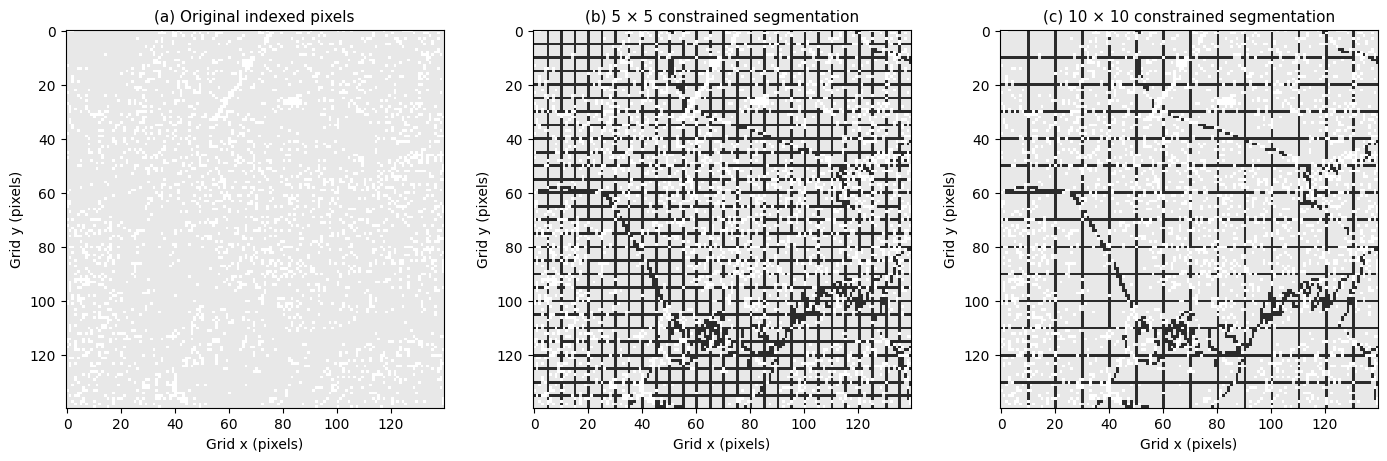


FIGURE GENERATION COMPLETE

PNG saved to:
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment2_Figure10_Segmentation_Comparison_600dpi.png

PDF saved to:
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment2_Figure10_Segmentation_Comparison_Vector.pdf

No experiments were rerun.
All original checkpoint files remain unchanged.


In [3]:
# ============================================================
# CELL 52 — EXPERIMENT 2 PUBLICATION FIGURE
#
# Figure 10: Original indexed pixels vs 5x5 and 10x10
# constrained graph segmentation
#
# READ-ONLY: Uses previously saved checkpoints.
# No segmentation or experimental calculations are rerun.
# ============================================================

from google.colab import drive
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ============================================================
# STEP 1 — CONNECT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE = BASE / "Cache"
FIGURES = BASE / "Figures"

FIGURES.mkdir(parents=True, exist_ok=True)

print("Google Drive connected.")
print("Project directory:", BASE)

# ============================================================
# STEP 2 — LOAD SAVED CHECKPOINTS
# ============================================================

GRAPH_PATH = CACHE / "Experiment0_Graph_Data.npz"

SEG5_PATH = (
    CACHE
    / "Experiment2_Full_Segmentation"
    / "Figure10_Block5_Consolidated.npz"
)

SEG10_PATH = (
    CACHE
    / "Experiment2_Full_Segmentation"
    / "Figure10_Block10_Consolidated.npz"
)

for path in [GRAPH_PATH, SEG5_PATH, SEG10_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint: {path}"
        )

print("\nAll three checkpoints found.")

# Inspect array names before loading
for name, path in [
    ("Original graph", GRAPH_PATH),
    ("5x5 segmentation", SEG5_PATH),
    ("10x10 segmentation", SEG10_PATH)
]:
    with np.load(path) as data:
        print(f"{name}: {data.files}")

# ============================================================
# STEP 3 — LOAD ORIGINAL PIXELS AND NODE ASSIGNMENTS
# ============================================================

with np.load(GRAPH_PATH) as data:
    ix = data["ix10"].astype(np.int32)
    iy = data["iy10"].astype(np.int32)

with np.load(SEG5_PATH) as data:
    labels5 = data["pixel_to_node"].astype(np.int32)

with np.load(SEG10_PATH) as data:
    labels10 = data["pixel_to_node"].astype(np.int32)

assert len(ix) == len(iy) == len(labels5) == len(labels10), (
    "Array lengths do not match."
)

assert len(ix) == 1_503_311, (
    f"Unexpected Figure 10 pixel count: {len(ix)}"
)

print("\nDataset loaded successfully.")
print("Indexed pixels:", len(ix))
print("5x5 nodes:", len(np.unique(labels5)))
print("10x10 nodes:", len(np.unique(labels10)))

# ============================================================
# STEP 4 — RECONSTRUCT INDEXED PIXEL MAP
# ============================================================

height = int(iy.max()) + 1
width = int(ix.max()) + 1

indexed = np.zeros((height, width), dtype=bool)
indexed[iy, ix] = True

print("\nOriginal map dimensions:", width, "x", height)

# ============================================================
# STEP 5 — SELECT A COMMON REGION OF INTEREST
# ============================================================

SIZE = 140

best_coverage = -1
x0, y0 = 0, 0

# Select a densely indexed region.
# The same coordinates are used for all three panels.

for y in range(0, height - SIZE + 1, 70):
    for x in range(0, width - SIZE + 1, 70):

        coverage = indexed[
            y:y + SIZE,
            x:x + SIZE
        ].sum()

        if coverage > best_coverage:
            best_coverage = coverage
            x0, y0 = x, y

roi = (
    (ix >= x0) &
    (ix < x0 + SIZE) &
    (iy >= y0) &
    (iy < y0 + SIZE)
)

xx = ix[roi] - x0
yy = iy[roi] - y0

print("\nSelected region:")
print("x =", x0)
print("y =", y0)
print(
    "Indexed coverage:",
    round(100 * best_coverage / SIZE**2, 2),
    "%"
)

# ============================================================
# STEP 6 — RECONSTRUCT SEGMENTATION MAPS
# ============================================================

def make_label_grid(labels):

    grid = np.full(
        (SIZE, SIZE),
        -1,
        dtype=np.int32
    )

    grid[yy, xx] = labels[roi]

    return grid


grid5 = make_label_grid(labels5)
grid10 = make_label_grid(labels10)

# ============================================================
# STEP 7 — IDENTIFY REDUCED-NODE BOUNDARIES
# ============================================================

def get_boundaries(grid):

    boundaries = np.zeros(
        grid.shape,
        dtype=bool
    )

    horizontal = (
        (grid[:, 1:] >= 0) &
        (grid[:, :-1] >= 0) &
        (grid[:, 1:] != grid[:, :-1])
    )

    vertical = (
        (grid[1:, :] >= 0) &
        (grid[:-1, :] >= 0) &
        (grid[1:, :] != grid[:-1, :])
    )

    boundaries[:, 1:] |= horizontal
    boundaries[1:, :] |= vertical

    return boundaries


boundary5 = get_boundaries(grid5)
boundary10 = get_boundaries(grid10)

# ============================================================
# STEP 8 — CREATE PUBLICATION FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4.5),
    constrained_layout=True
)

background = np.where(
    indexed[y0:y0 + SIZE, x0:x0 + SIZE],
    1.0,
    np.nan
)

titles = [
    "(a) Original indexed pixels",
    "(b) 5 × 5 constrained segmentation",
    "(c) 10 × 10 constrained segmentation"
]

boundary_maps = [
    None,
    boundary5,
    boundary10
]

for ax, title, boundary in zip(
    axes,
    titles,
    boundary_maps
):

    ax.imshow(
        background,
        cmap=ListedColormap(["#e8e8e8"]),
        vmin=0,
        vmax=1,
        interpolation="nearest",
        origin="upper"
    )

    if boundary is not None:

        overlay = np.ma.masked_where(
            ~boundary,
            boundary.astype(float)
        )

        ax.imshow(
            overlay,
            cmap=ListedColormap(["#151515"]),
            vmin=0,
            vmax=1,
            interpolation="nearest",
            origin="upper",
            alpha=0.9
        )

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Grid x (pixels)")
    ax.set_ylabel("Grid y (pixels)")

# ============================================================
# STEP 9 — SAVE FIGURE
# ============================================================

png_path = (
    FIGURES
    / "Experiment2_Figure10_Segmentation_Comparison_600dpi.png"
)

pdf_path = (
    FIGURES
    / "Experiment2_Figure10_Segmentation_Comparison_Vector.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ============================================================
# STEP 10 — CONFIRM SUCCESS
# ============================================================

print("\n" + "=" * 55)
print("FIGURE GENERATION COMPLETE")
print("=" * 55)

print("\nPNG saved to:")
print(png_path)

print("\nPDF saved to:")
print(pdf_path)

print("\nNo experiments were rerun.")
print("All original checkpoint files remain unchanged.")

Connecting to Google Drive...
Mounted at /content/drive
Google Drive connected successfully.
Project: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1

Checking saved checkpoints...
OK: Original graph
OK: Original orientations
OK: 5x5 segmentation
OK: 10x10 segmentation
OK: 5x5 medoids
OK: 10x10 medoids

Loading original EBSD data...
Loading segmentation assignments...
Loading saved medoids...

DATA RECOVERY SUCCESSFUL
Original indexed pixels: 1503311
5x5 reduced nodes: 115006
10x10 reduced nodes: 43184

Region of interest:
x: 1400 to 1540
y: 420 to 560
Indexed pixels: 16835

Reconstructing orientation maps...


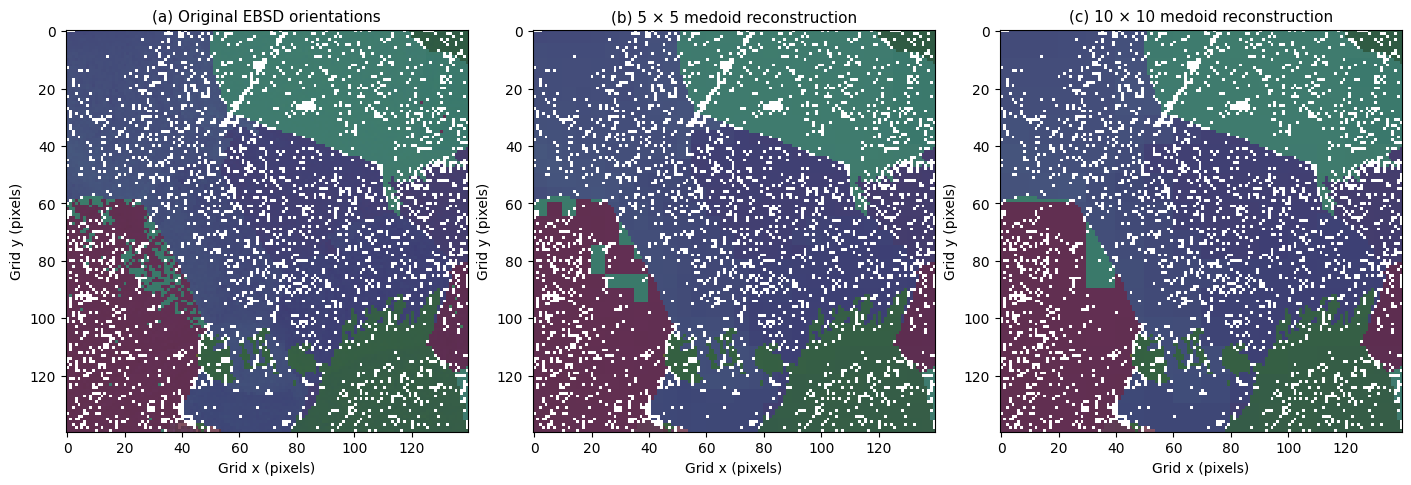


CELL 53 COMPLETED SUCCESSFULLY

Saved PNG:
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment2_Figure10_Orientation_Comparison_600dpi.png

Saved PDF:
/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment2_Figure10_Orientation_Comparison_Vector.pdf

Original indexed pixels: 1503311
5x5 reduced nodes: 115006
10x10 reduced nodes: 43184

All experimental results loaded from Google Drive.
No segmentation or medoid optimisation rerun.
No existing checkpoint files modified.


In [1]:
# ============================================================
# CELL 53 — FIGURE 10 ORIENTATION RECONSTRUCTION
# SELF-CONTAINED / GOOGLE DRIVE RECOVERY
#
# (a) Original EBSD orientations
# (b) 5x5 medoid reconstruction
# (c) 10x10 medoid reconstruction
#
# VISUALISATION ONLY — NO EXPERIMENTS RERUN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
from matplotlib.colors import hsv_to_rgb

# ============================================================
# 1. CONNECT GOOGLE DRIVE
# ============================================================

print("Connecting to Google Drive...", flush=True)

drive.mount("/content/drive")

BASE_DIR = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE_DIR = BASE_DIR / "Cache"
FIG_DIR = BASE_DIR / "Figures"

if not CACHE_DIR.exists():
    raise FileNotFoundError(
        f"Cache directory not found: {CACHE_DIR}"
    )

FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive connected successfully.")
print("Project:", BASE_DIR)

# ============================================================
# 2. RECOVER SAVED FILE PATHS
# ============================================================

GRAPH_PATH = (
    CACHE_DIR / "Experiment0_Graph_Data.npz"
)

ORIENTATION_PATH = (
    CACHE_DIR / "Figure10_Indexed.parquet"
)

SEG5_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure10_Block5_Consolidated.npz"
)

SEG10_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Segmentation"
    / "Figure10_Block10_Consolidated.npz"
)

MED5_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Medoids"
    / "Figure10_Block5_Consolidated.npz"
)

MED10_PATH = (
    CACHE_DIR
    / "Experiment2_Full_Medoids"
    / "Figure10_Block10_Consolidated.npz"
)

files = {
    "Original graph": GRAPH_PATH,
    "Original orientations": ORIENTATION_PATH,
    "5x5 segmentation": SEG5_PATH,
    "10x10 segmentation": SEG10_PATH,
    "5x5 medoids": MED5_PATH,
    "10x10 medoids": MED10_PATH
}

print("\nChecking saved checkpoints...")

for name, path in files.items():

    if not path.exists():
        raise FileNotFoundError(
            f"{name} not found:\n{path}"
        )

    print(f"OK: {name}")

# ============================================================
# 3. RESTORE ORIGINAL EBSD DATA
# ============================================================

print("\nLoading original EBSD data...", flush=True)

indexed10 = pd.read_parquet(ORIENTATION_PATH)

required_columns = ["Euler1", "Euler2", "Euler3"]

if not all(c in indexed10.columns for c in required_columns):
    raise ValueError(
        f"Missing Euler columns. Available: {list(indexed10.columns)}"
    )

eulers = indexed10[
    required_columns
].to_numpy(dtype=np.float64)

with np.load(GRAPH_PATH) as z:

    ix10 = z["ix10"].astype(np.int32)
    iy10 = z["iy10"].astype(np.int32)

# ============================================================
# 4. RESTORE SAVED SEGMENTATION RESULTS
# ============================================================

print("Loading segmentation assignments...", flush=True)

with np.load(SEG5_PATH) as z:
    labels5 = z["pixel_to_node"].astype(np.int32)

with np.load(SEG10_PATH) as z:
    labels10 = z["pixel_to_node"].astype(np.int32)

# ============================================================
# 5. RESTORE SAVED CRYSTALLOGRAPHIC MEDOIDS
# ============================================================

print("Loading saved medoids...", flush=True)

with np.load(MED5_PATH) as z:
    medoids5 = z["medoid_pixel_indices"].astype(np.int32)

with np.load(MED10_PATH) as z:
    medoids10 = z["medoid_pixel_indices"].astype(np.int32)

# ============================================================
# 6. VERIFY RECOVERED DATA
# ============================================================

N = len(eulers)

assert N == 1_503_311

assert len(ix10) == N
assert len(iy10) == N

assert len(labels5) == N
assert len(labels10) == N

assert len(medoids5) == 115_006
assert len(medoids10) == 43_184

assert np.all(labels5 >= 0)
assert np.all(labels10 >= 0)

assert labels5.max() < len(medoids5)
assert labels10.max() < len(medoids10)

assert np.all((medoids5 >= 0) & (medoids5 < N))
assert np.all((medoids10 >= 0) & (medoids10 < N))

# Verify that each saved medoid belongs to its own node.
assert np.array_equal(
    labels5[medoids5],
    np.arange(len(medoids5))
)

assert np.array_equal(
    labels10[medoids10],
    np.arange(len(medoids10))
)

print("\nDATA RECOVERY SUCCESSFUL")
print("Original indexed pixels:", N)
print("5x5 reduced nodes:", len(medoids5))
print("10x10 reduced nodes:", len(medoids10))

# ============================================================
# 7. SELECT THE SAME REGION USED IN CELL 52
# ============================================================

SIZE = 140

x0 = 1400
y0 = 420

roi = (
    (ix10 >= x0) &
    (ix10 < x0 + SIZE) &
    (iy10 >= y0) &
    (iy10 < y0 + SIZE)
)

xx = ix10[roi] - x0
yy = iy10[roi] - y0

print("\nRegion of interest:")
print("x:", x0, "to", x0 + SIZE)
print("y:", y0, "to", y0 + SIZE)
print("Indexed pixels:", np.count_nonzero(roi))

# ============================================================
# 8. RECONSTRUCT ORIENTATIONS FROM SAVED MEDOIDS
# ============================================================

print("\nReconstructing orientation maps...", flush=True)

original_eulers = eulers[roi]

reconstructed5 = eulers[
    medoids5[labels5[roi]]
]

reconstructed10 = eulers[
    medoids10[labels10[roi]]
]

# These are existing medoid assignments.
# No medoid optimisation is performed.

# ============================================================
# 9. CONSISTENT EULER-ANGLE COLOUR ENCODING
#
# Illustrative orientation colours.
# NOT a crystallographic IPF colour key.
# ============================================================

def euler_to_rgb(euler_array):

    phi1 = np.mod(euler_array[:, 0], 360.0)
    Phi = np.clip(euler_array[:, 1], 0.0, 180.0)
    phi2 = np.mod(euler_array[:, 2], 360.0)

    hsv = np.empty(
        (len(euler_array), 3),
        dtype=np.float64
    )

    hsv[:, 0] = phi1 / 360.0
    hsv[:, 1] = 0.35 + 0.65 * Phi / 180.0
    hsv[:, 2] = 0.35 + 0.65 * phi2 / 360.0

    return hsv_to_rgb(hsv)


rgb_original = euler_to_rgb(original_eulers)
rgb5 = euler_to_rgb(reconstructed5)
rgb10 = euler_to_rgb(reconstructed10)

# ============================================================
# 10. CREATE RGB MAPS
# ============================================================

def create_rgb_map(rgb_values):

    image = np.ones(
        (SIZE, SIZE, 3),
        dtype=np.float32
    )

    # White represents unindexed pixels.
    image[yy, xx] = rgb_values

    return image


map_original = create_rgb_map(rgb_original)
map5 = create_rgb_map(rgb5)
map10 = create_rgb_map(rgb10)

# ============================================================
# 11. GENERATE THREE-PANEL FIGURE
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4.8),
    constrained_layout=True
)

maps = [
    map_original,
    map5,
    map10
]

titles = [
    "(a) Original EBSD orientations",
    "(b) 5 × 5 medoid reconstruction",
    "(c) 10 × 10 medoid reconstruction"
]

for ax, image, title in zip(
    axes,
    maps,
    titles
):

    ax.imshow(
        image,
        origin="upper",
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Grid x (pixels)")
    ax.set_ylabel("Grid y (pixels)")

# ============================================================
# 12. SAVE PUBLICATION FIGURE
# ============================================================

PNG_PATH = (
    FIG_DIR
    / "Experiment2_Figure10_Orientation_Comparison_600dpi.png"
)

PDF_PATH = (
    FIG_DIR
    / "Experiment2_Figure10_Orientation_Comparison_Vector.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ============================================================
# 13. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 60)
print("CELL 53 COMPLETED SUCCESSFULLY")
print("=" * 60)

print("\nSaved PNG:")
print(PNG_PATH)

print("\nSaved PDF:")
print(PDF_PATH)

print("\nOriginal indexed pixels:", N)
print("5x5 reduced nodes:", len(medoids5))
print("10x10 reduced nodes:", len(medoids10))

print("\nAll experimental results loaded from Google Drive.")
print("No segmentation or medoid optimisation rerun.")
print("No existing checkpoint files modified.")

Mounted at /content/drive
Google Drive connected.
Orix imported successfully.
All saved checkpoints found.
Original pixels: 1503311
5x5 nodes: 115006
10x10 nodes: 43184
Indexed pixels in region: 16835
Generating original IPF colours...
Generating 5x5 reconstructed IPF colours...
Generating 10x10 reconstructed IPF colours...


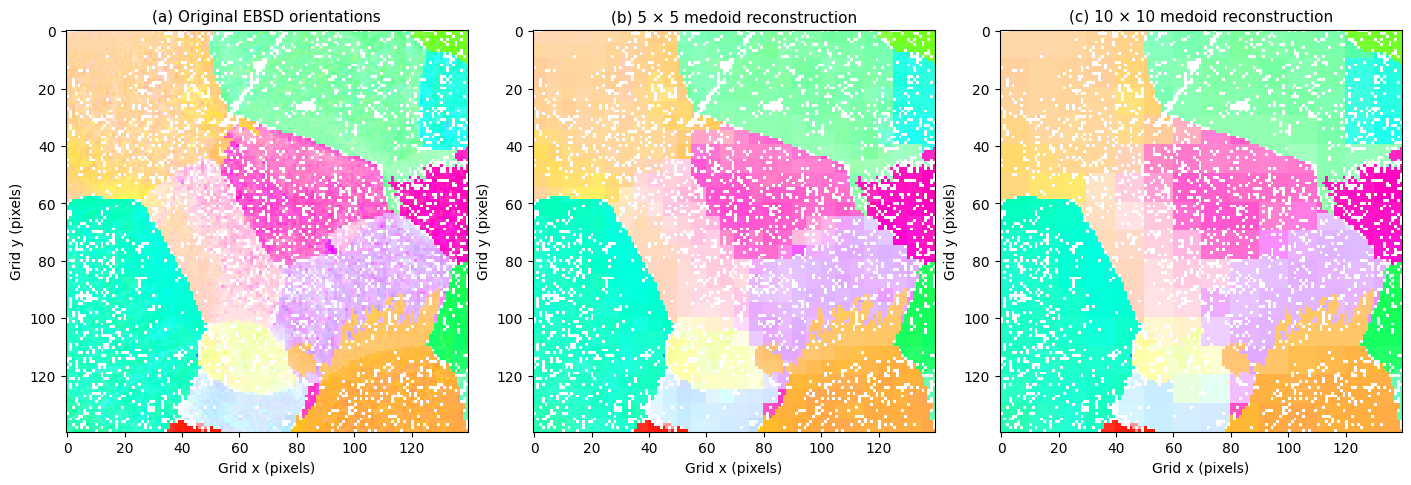


CELL 54 COMPLETE
PNG: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment2_Figure10_IPF_Comparison_600dpi.png
PDF: /content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1/Figures/Experiment2_Figure10_IPF_Comparison_Vector.pdf
Crystal symmetry: Cubic (O)
IPF reference direction: Sample Z
No experimental results modified.


In [1]:
# ============================================================
# CELL 54 — PUBLICATION IPF ORIENTATION COMPARISON
#
# Figure 10: Original vs 5x5 vs 10x10 medoid reconstruction
# Cubic crystal symmetry (O)
# IPF colouring along sample Z direction
#
# VISUALISATION ONLY — NO EXPERIMENTS RERUN
# ============================================================

import sys
import subprocess
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

# ------------------------------------------------------------
# 1. CONNECT GOOGLE DRIVE
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/EBSDGraph_Major_Revision_Paper1"
)

CACHE = BASE / "Cache"
FIGURES = BASE / "Figures"

if not CACHE.exists():
    raise FileNotFoundError(f"Cache folder not found: {CACHE}")

FIGURES.mkdir(parents=True, exist_ok=True)

print("Google Drive connected.", flush=True)

# ------------------------------------------------------------
# 2. IMPORT ORIX
# ------------------------------------------------------------

if importlib.util.find_spec("orix") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "orix"
    ])

from orix.quaternion import Orientation, symmetry
from orix.vector import Vector3d
from orix.plot import IPFColorKeyTSL

print("Orix imported successfully.", flush=True)

# ------------------------------------------------------------
# 3. DEFINE SAVED CHECKPOINTS
# ------------------------------------------------------------

paths = {
    "graph": CACHE / "Experiment0_Graph_Data.npz",
    "eulers": CACHE / "Figure10_Indexed.parquet",
    "seg5": (
        CACHE / "Experiment2_Full_Segmentation"
        / "Figure10_Block5_Consolidated.npz"
    ),
    "seg10": (
        CACHE / "Experiment2_Full_Segmentation"
        / "Figure10_Block10_Consolidated.npz"
    ),
    "med5": (
        CACHE / "Experiment2_Full_Medoids"
        / "Figure10_Block5_Consolidated.npz"
    ),
    "med10": (
        CACHE / "Experiment2_Full_Medoids"
        / "Figure10_Block10_Consolidated.npz"
    )
}

for name, path in paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

print("All saved checkpoints found.", flush=True)

# ------------------------------------------------------------
# 4. LOAD SAVED DATA
# ------------------------------------------------------------

indexed10 = pd.read_parquet(paths["eulers"])

eulers = indexed10[
    ["Euler1", "Euler2", "Euler3"]
].to_numpy(dtype=np.float64)

with np.load(paths["graph"]) as z:
    ix = z["ix10"].astype(np.int32)
    iy = z["iy10"].astype(np.int32)

with np.load(paths["seg5"]) as z:
    labels5 = z["pixel_to_node"].astype(np.int32)

with np.load(paths["seg10"]) as z:
    labels10 = z["pixel_to_node"].astype(np.int32)

with np.load(paths["med5"]) as z:
    medoids5 = z["medoid_pixel_indices"].astype(np.int32)

with np.load(paths["med10"]) as z:
    medoids10 = z["medoid_pixel_indices"].astype(np.int32)

N = len(eulers)

assert N == 1_503_311
assert len(ix) == len(iy) == len(labels5) == len(labels10) == N
assert len(medoids5) == 115_006
assert len(medoids10) == 43_184

assert np.all((labels5 >= 0) & (labels5 < len(medoids5)))
assert np.all((labels10 >= 0) & (labels10 < len(medoids10)))

assert np.all((medoids5 >= 0) & (medoids5 < N))
assert np.all((medoids10 >= 0) & (medoids10 < N))

assert np.array_equal(
    labels5[medoids5], np.arange(len(medoids5))
)

assert np.array_equal(
    labels10[medoids10], np.arange(len(medoids10))
)

print("Original pixels:", N)
print("5x5 nodes:", len(medoids5))
print("10x10 nodes:", len(medoids10))

# ------------------------------------------------------------
# 5. SELECT THE SAME 140x140 REGION
# ------------------------------------------------------------

SIZE = 140
x0 = 1400
y0 = 420

roi = (
    (ix >= x0) &
    (ix < x0 + SIZE) &
    (iy >= y0) &
    (iy < y0 + SIZE)
)

xx = ix[roi] - x0
yy = iy[roi] - y0

original_eulers = eulers[roi]

reconstructed5 = eulers[
    medoids5[labels5[roi]]
]

reconstructed10 = eulers[
    medoids10[labels10[roi]]
]

print("Indexed pixels in region:", len(original_eulers))

# ------------------------------------------------------------
# 6. DEFINE STANDARD CUBIC IPF COLOUR KEY
#
# Reference direction: sample Z (out-of-plane)
# ------------------------------------------------------------

crystal_symmetry = symmetry.O

sample_direction = Vector3d.zvector()

ipf_key = IPFColorKeyTSL(
    crystal_symmetry,
    direction=sample_direction
)

# ------------------------------------------------------------
# 7. CONVERT EULER ANGLES TO IPF COLOURS
# ------------------------------------------------------------

def orientations_to_ipf_rgb(euler_deg):

    orientations = Orientation.from_euler(
        np.deg2rad(euler_deg),
        symmetry=crystal_symmetry
    )

    rgb = ipf_key.orientation2color(orientations)

    return np.asarray(rgb).reshape(-1, 3)


print("Generating original IPF colours...", flush=True)
rgb_original = orientations_to_ipf_rgb(original_eulers)

print("Generating 5x5 reconstructed IPF colours...", flush=True)
rgb5 = orientations_to_ipf_rgb(reconstructed5)

print("Generating 10x10 reconstructed IPF colours...", flush=True)
rgb10 = orientations_to_ipf_rgb(reconstructed10)

# ------------------------------------------------------------
# 8. CREATE SPATIAL RGB MAPS
# ------------------------------------------------------------

def create_map(rgb_values):

    image = np.ones(
        (SIZE, SIZE, 3),
        dtype=np.float32
    )

    image[yy, xx] = rgb_values

    return image


map_original = create_map(rgb_original)
map5 = create_map(rgb5)
map10 = create_map(rgb10)

# ------------------------------------------------------------
# 9. GENERATE PUBLICATION FIGURE
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4.8),
    constrained_layout=True
)

maps = [map_original, map5, map10]

titles = [
    "(a) Original EBSD orientations",
    "(b) 5 × 5 medoid reconstruction",
    "(c) 10 × 10 medoid reconstruction"
]

for ax, image, title in zip(axes, maps, titles):

    ax.imshow(
        image,
        origin="upper",
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Grid x (pixels)")
    ax.set_ylabel("Grid y (pixels)")

# ------------------------------------------------------------
# 10. SAVE PUBLICATION FILES
# ------------------------------------------------------------

PNG_PATH = (
    FIGURES
    / "Experiment2_Figure10_IPF_Comparison_600dpi.png"
)

PDF_PATH = (
    FIGURES
    / "Experiment2_Figure10_IPF_Comparison_Vector.pdf"
)

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\nCELL 54 COMPLETE")
print("PNG:", PNG_PATH)
print("PDF:", PDF_PATH)
print("Crystal symmetry: Cubic (O)")
print("IPF reference direction: Sample Z")
print("No experimental results modified.")